In [1]:
import numpy as np
import healpy as hp
from healpy.newvisufunc import projview
from astropy.table import Table

import matplotlib
from matplotlib import pyplot as plt

from Corrfunc import mocks
from Corrfunc.utils import convert_rp_pi_counts_to_wp
from scipy import constants
from scipy import stats
import scipy.interpolate as interp
from random import sample
import matplotlib.gridspec as gridspec
from Corrfunc import theory
from astropy.cosmology import FlatLambdaCDM
from Corrfunc.utils import convert_3d_counts_to_cf
import astropy.cosmology.units as cu
import astropy.units as u
import site
site.addsitedir('/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts') 
import quaia
import quaia_debug
from astropy.coordinates import SkyCoord
import matplotlib.gridspec as gridspec
import seaborn as sns
from matplotlib.colors import LogNorm
import os
import matplotlib.patches as mpatches
import pyccl as ccl
from matplotlib.lines import Line2D
from astropy import constants as const
import importlib
from os.path import dirname, abspath, join as pjoin
import Corrfunc
from Corrfunc.io import read_catalog
from astropy.cosmology import Planck18

In [2]:
matplotlib.rcParams['ytick.labelsize'] = 18
matplotlib.rcParams['xtick.labelsize'] = 18
matplotlib.rcParams['axes.labelsize'] = 22
matplotlib.rcParams['legend.fontsize'] = 18
matplotlib.rcParams['axes.titlesize'] = 20

# Compute $w_p$
## Parameters

In [3]:
G_hi = 20.5
G_lo = 20

In [4]:
nthreads = 18

In [5]:
h_planck20 = 0.674

In [6]:
H0_planck20 = h_planck20*100 * u.km/u.s/u.Mpc

In [7]:
z_bins = np.array([0.0, 1.0, 2.0, 3.0, 4.0])
z_array = range(len(z_bins)-1)
mask = 0.5

In [8]:
Omega_m_planck20 = 0.315

In [9]:
cosmo_planck20 = ccl.Cosmology(Omega_c=0.265, Omega_b=0.049, h=h_planck20, n_s=0.95, sigma8=0.8)

In [10]:
cosmo_planck18 = ccl.Cosmology(Omega_c=0.265, Omega_b=Planck18.Ob0, h=Planck18.h, Neff = Planck18.Neff, T_CMB = Planck18.Tcmb0.value, m_nu = Planck18.m_nu, sigma8=0.8, n_s=0.95)

In [13]:
cmap_qq = plt.get_cmap('Oranges')(np.linspace(0.333, 0.999, len(z_array)))
cmap_mm = plt.get_cmap('Greens')(np.linspace(0.333, 0.999, len(z_array)))
cmap_b = plt.get_cmap('Greys')(np.linspace(0.333, 0.999, len(z_array)))
cmaps = [cmap_qq, cmap_mm]

In [14]:
orange = plt.get_cmap('Oranges')((0.333+0.999)/2)
green = plt.get_cmap('Greens')((0.333+0.999)/2)
colors = [orange, green]

In [15]:
# Create the bins array
rpmin = 0.15 # 0.5 # 0.1 # start higher
rpmax = 240 # 120 #85 # 60.0 # 20.0 
nbins = 20 
rpbins = np.logspace(np.log10(rpmin), np.log10(rpmax), nbins + 1) # Mpc/h https://github.com/manodeep/Corrfunc/issues/202
scale = 'log'

In [16]:
pimax = 80 # 40 # 5000.0 # 40.0

## Original version

In [17]:
Om0 = {'Planck': Planck18.Om0, 'Quaia': 0.343} #cosmo_planck18['Omega_m']

In [18]:
zbin_array = [0.0, 1.0, 2.0, 3.0, 4.6]

In [19]:
NSIDE = 64
NPIX = hp.nside2npix(NSIDE)
name_catalog = '$Gaia$-$unWISE$ Quasar Catalog'

In [20]:
cmap_map = 'plasma'
cbar_ticks = [5, 10, 20]

## Compare to literature directly

In [21]:
ross={j: [] for j in z_array}

In [22]:
ross[0] = ([[0.8073020296417909, 1.3038964465900755, 2.0161453168774686, 3.2210394854283892, 5.146017714503383, 8.044190393879486, 12.71233223736328, 19.87180467719742, 32.09540431004344, 51.276524891184586, 79.2860548714898, 126.66934692704329],
             [204.6222896563082, 287.19236522589665, 123.06234837013626, 81.31853722414195, 28.863844045486363, 8.812253131546907, 45.35718844554274, 1.5582307452831532, 12.137437562184859, 6.161527886831037, 5.299770191716386, 2.6904179890967033]],
           [[0.5089106478490751, 0.8249460561605165, 1.320350591185704, 2.0602094180428216, 3.25577419708743, 5.08015410064643, 7.92681988642257, 12.68710995719233, 20.049595382142478, 32.089933771596144, 51.3608892484878, 78.12922818856069, 125.04814327832419],
              [305.3042109588633, 30.39655315087964, 65.58340634849321, 55.01206429679448, 34.679773379930786, 52.647076836914856, 12.348188015240337, 13.189526031347812, 0.020199621793552777, 3.3043353474398853, 6.822909812969489, 1.2846311763345128, 1.3131693394847839]],
           [[1.245727468971928, 2.0079372101714883, 3.1377230628096378, 5.026304828025077, 7.903249189425962, 12.504178049693607, 19.906630148679973, 31.10723962196968, 79.33015207709391],
            [99.36365369262894, 40.6497330837172, 90.28961835667108, 39.793793589092814, 15.272806678448974, 1.8774465642953528, 7.567075006409459, 2.695780965013458, 1.8774465642953528]])

In [23]:
ross[1] = ([[1.2288171644396777, 3.128396919383618, 1.9423132303279362, 4.944852479992441, 7.964447729821493, 12.668084115961909, 19.774015263042898, 50.02722662035073, 124.98802040712917],
            [76.04772593849674, 119.59563621447275, 154.9083471577296, 61.29902192686856, 25.877450431036173, 26.728004181473366, 26.15790879863473, 2.054635255244398, 1.07605775483426]], 
           [[0.756972474946741, 1.231389393416293, 1.9276489550614384, 3.095867929773623, 4.908805296006164, 7.684366865331586, 12.184324919749486, 19.31945420510871, 31.4275060691105, 49.831424250580405, 79.01265971855135, 125.2823994033615], 
            [282.06038480383825, 189.79796344734584, 57.82823139797186, 51.80222138053693, 14.453166283554152, 38.065465610406555, 32.630426218063135, 15.103579032145106, 11.855987323221836, 0.8451505656104451, 0.0838119415811712, 0.13305510394213196]], 
           [[2.0031373509648795, 5.036136482903174, 7.883694297265138, 12.66147359401569, 19.82058816455507, 31.4275060691105, 51.12407861492125, 79.01265971855135],
            [119.5544954937815, 12.38952337690515, 34.8576285425981, 10.856864496243967, 10.16317319094918, 1.1501416309398633, 0.053968322614481805, 3.7748783587396915]], 
           [[1.2513840188437222, 2.0527850331447866, 3.114269331283328, 5.042576218598917, 7.954907318352166, 12.713777353009748, 20.056621204627373, 32.475328801340645, 80.82009941605419], 
            [305.0957269577455, 53.171793124813554, 108.88424340492195, 83.22111441593931, 45.45562445485528, 6.925753884630869, 9.061468078493995, 4.52524722751074, 1.651578217209416]], 
           [[1.26778955742121, 1.9741198532900412, 3.114269331283328, 5.108687012021902, 7.851973355193858, 12.880461577853088, 20.319549695946264, 31.640287798453603, 50.56848035509456, 80.82009941605419, 129.16916671716484], 
            [116.45225839679294, 133.2028971062896, 106.47252666056495, 49.71625749971546, 16.96572356384012, 31.76477348092491, 14.832236139491425, 6.925753884630869, 1.651578217209416, 0.8247890610774163, 0.5153030925909026]], 
           [[1.26778955742121, 2.026220233432322, 3.1964640067794767, 5.108687012021902, 8.05920028520566, 12.713777353009748, 20.056621204627373, 31.640287798453603, 49.91408082922755, 80.82009941605419, 125.84782850447421], 
            [213.2032468206225, 182.2638674994819, 71.14433010407058, 31.76477348092491, 62.19773062544564, 21.705808856384166, 27.770263933257915, 6.925753884630869, 4.52524722751074, 0.08397017387659825, 0.6303929997077617]])

In [24]:
da_angela = ([0.939602888704744, 2.1069615211624644, 3.1964640067794767, 4.786584058211089, 7.356906069803289, 10.874136388442313, 16.497114551617212, 24.703805627648027, 36.993059502384334], 
             [101.80805958666399, 46.48529068741428, 23.740331263413864, 24.278075188727914, 16.589926566418175, 7.574916583753688, 9.476630882548415, 6.1919753923916065, 2.7646151907125307])

In [25]:
ross[2] = ([[2.027801045477713, 3.2424519079800946, 5.043480177709532, 7.953949074841512, 12.718356868003596, 20.057809147512753, 31.63267959638543, 49.887124315950615, 80.87826663677944], 
           [229.98642197599096, 58.97738763721187, 16.410824351507053, 81.75785487999804, 20.402936313898298, 22.138778901611623, 16.863609869728418, 8.310397440275882, 4.324479887571413]], 
           [[1.329841403698343, 2.0755913504557357, 3.239543784774421, 5.198880291904858, 8.227988234318307, 13.021994464749518, 20.043663944825223, 32.617088741975344, 50.90810375391653, 81.69827447568031, 129.29946515535318],
           [896.3843104798887, 628.203193099385, 78.61166883266033, 87.69873180731636, 74.42766787517415, 8.817971328682592, 3.119335735568827, 52.16026155010116, 9.837266477769806, 4.701207021112871, 9.571899574959188]])

In [26]:
eftekharzadeh = np.array([
    [2.09, 69.353],
    [2.53, 60.807],
    [3.06, 57.125],
    [3.70, 52.908],
    [4.47, 45.454],
    [5.41, 39.291],
    [6.55, 34.392],
    [7.92, 25.846],
    [9.58, 23.907],
    [11.60, 16.056],
    [14.03, 11.771],
    [16.97, 13.753],
    [20.54, 9.404],
    [24.85, 6.824],
    [30.06, 6.554],
    [36.37, 7.341],
    [44.00, 4.192],
    [53.23, 4.483],
    [64.40, 2.576],
])

### Galactic latitude mask

<>:40: SyntaxWarning: invalid escape sequence '\l'
<>:40: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6684/2584092643.py:40: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(zbin_array[j], zbin_array[j+1]))


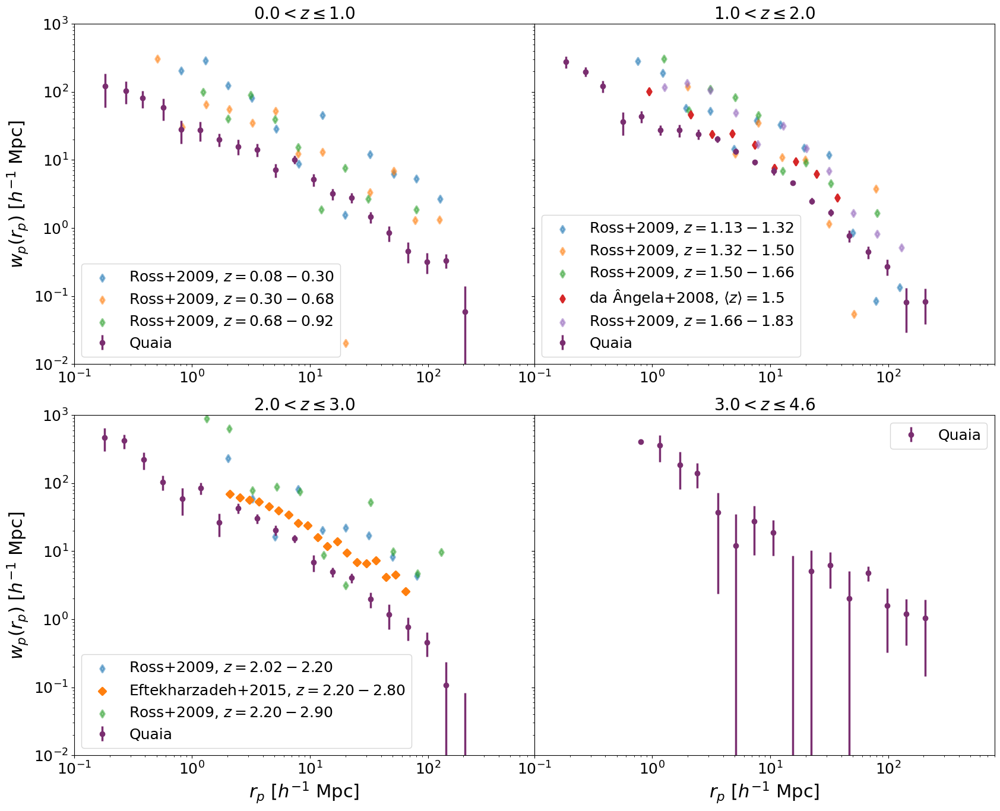

In [30]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.15, wspace = 0)
bbox_to_anchor = [(-0.45, 0.7),(1.35, 0.8), (0, 0), (0, 0)]
cosmos = ['Planck', 'Quaia']
cosmo = 'Planck'
b=30

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])

    wp = np.load('../results/wp_G{}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_{}_MC_b{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], cosmo, b))
    rpavg = np.load('../results/rpavg_G{}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_{}_MC_b{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], cosmo, b))
    C = np.load('../results/cov_wp_G{}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_N25_{}_MC_b{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], 'Planck', b))
    
    ax1.errorbar(rpavg, wp, linewidth = 2.5, marker = 'o',
                 label = r'Quaia'.format(cosmo), color = cmap_rocket[0], yerr = np.sqrt(np.diag(C)), linestyle = 'None')

    if j == 0:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.08-0.30$', alpha = 0.5)
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.30-0.68$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.68-0.92$', alpha = 0.5)
        ax1.legend()
    elif j == 1:
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.13-1.32$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.32-1.50$', alpha = 0.5)
        ax1.scatter(ross[j][3][0], ross[j][3][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.50-1.66$', alpha = 0.5)
        ax1.scatter(da_angela[0], da_angela[1], linewidth = 2.5, marker = 'd', label = r'da Ângela+2008, $\langle z\rangle=1.5$')
        ax1.scatter(ross[j][4][0], ross[j][4][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.66-1.83$', alpha = 0.5)
        ax1.legend()
    elif j == 2:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.02-2.20$', alpha = 0.5)
        ax1.scatter(eftekharzadeh[:,0], eftekharzadeh[:,1], linewidth = 2.5, marker = 'D', label = r'Eftekharzadeh+2015, $z = 2.20-2.80$')
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.20-2.90$', alpha = 0.5)
        ax1.legend()
    else:
        ax1.legend()

    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(zbin_array[j], zbin_array[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(1e-1, 8e2)
    ax1.set_ylim(1e-2, 1e3)


    if (j) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if scale == 'log':
        ax1.set_xscale('log')

    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected

plt.savefig('../figures/suppressed_clustering_Quaia.pdf', bbox_inches = 'tight')
plt.show()

Pixels masked by MC but not already by selfunc: 2468
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.33              218365 vs 324336
2.184321951138191 6.700972645215975


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


Pixels masked by MC but not already by selfunc: 4785
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.30              453228 vs 648196
4.7566994064468044 13.685195124803196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.28              207602 vs 286508
2.044828277065903 6.4025187281424305


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.23              28043 vs 36458
0.13669501489315472 1.0043775762526785


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


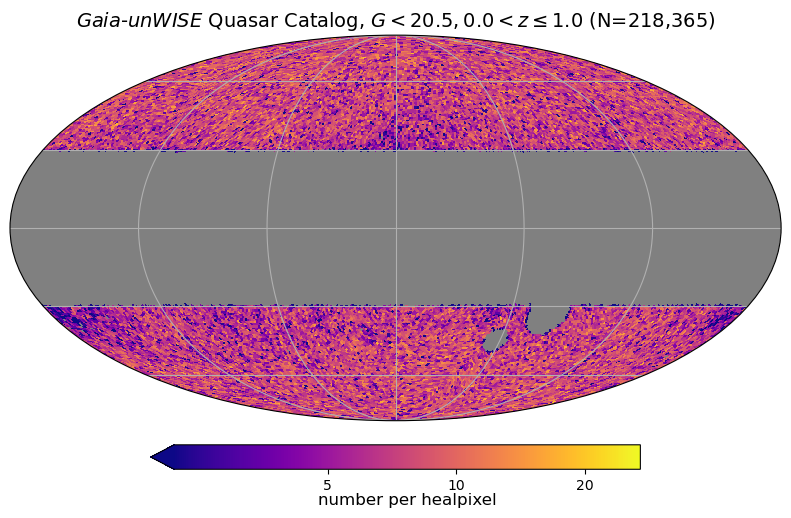

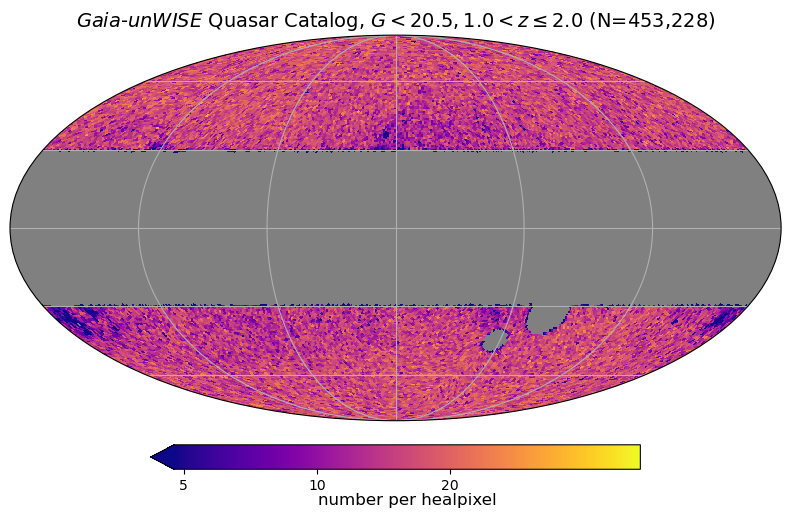

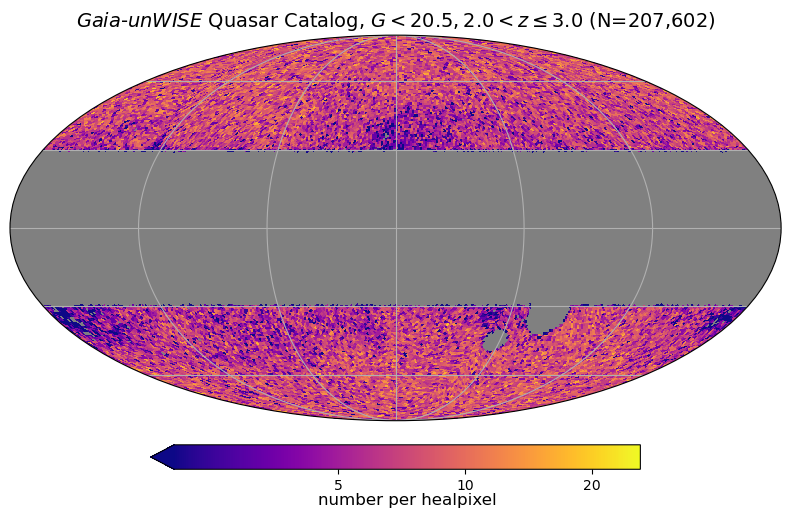

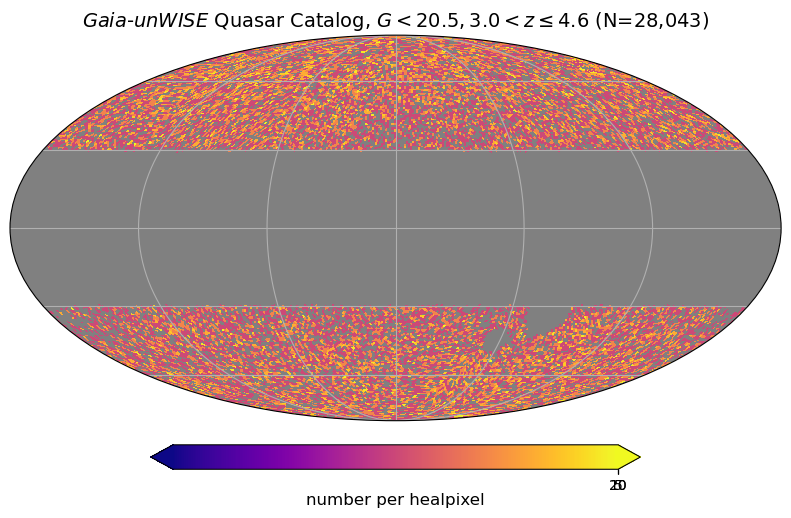

In [40]:
wp_zbin_percentile = {'Planck': [], 'Quaia': []}
rpavg_zbin_percentile = {'Planck': [], 'Quaia': []}
cosmos = ['Planck', 'Quaia']
fac_stdev = 0.45 #0.55
cosmo = 'Planck'
b = 30
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _= quaia.make_bins(G_hi, [j, 0], True, ['z', 'L'], 
                                                                                     bins = [zbin_array, [-20.0]], tab_gcat_type = 'data',
                                                                                     method = ['minmax', 'max'], fac_rand = 25,
                                                                                     n_bins = [None, None], mask_type = 'b', b = b) # mask=mask)
    
    N_gcatlo_mask = len(tab_datahi_mask_zbin0)
    pixel_indices_datahi_bin0 = hp.ang2pix(NSIDE, tab_datahi_mask_zbin0['ra'], tab_datahi_mask_zbin0['dec'], lonlat=True)
    map_gcatlo = np.bincount(pixel_indices_datahi_bin0, minlength=NPIX)
    print(np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), np.mean(map_gcatlo)+fac_stdev*np.std(map_gcatlo))
    title_gcatlo = rf"{name_catalog}, $G<{G_hi},{zbin_array[j]:.1f}<z \leq{zbin_array[j+1]:.1f}$ (N={N_gcatlo_mask:,})"
    projview(map_gcatlo*hp.pixelfunc.nside2pixarea(NSIDE, degrees = True), title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C','G'],
                min=np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), max=np.mean(map_gcatlo)+10*fac_stdev*np.std(map_gcatlo), 
            norm='log', graticule=True, cbar_ticks=cbar_ticks, graticule_labels=False) #True

    # for cosmo in cosmos:
    wp_zbin_i, rpavg_zbin_i, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Om0[cosmo], 
                                                  h = Planck18.h, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
    wp_zbin_percentile[cosmo].append(wp_zbin_i)
    rpavg_zbin_percentile[cosmo].append(rpavg_zbin_i)

In [28]:
cmap_rocket = sns.color_palette("flare_r", n_colors = len(z_array))
cmap_rocket

[(0.47936222, 0.18006056, 0.43733022),
 (0.66635279, 0.22717328, 0.43008427),
 (0.83765537, 0.30784814, 0.3723105),
 (0.90732341, 0.4939774, 0.38990532)]

<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:42: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_6684/775419488.py:42: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(zbin_array[j], zbin_array[j+1]))


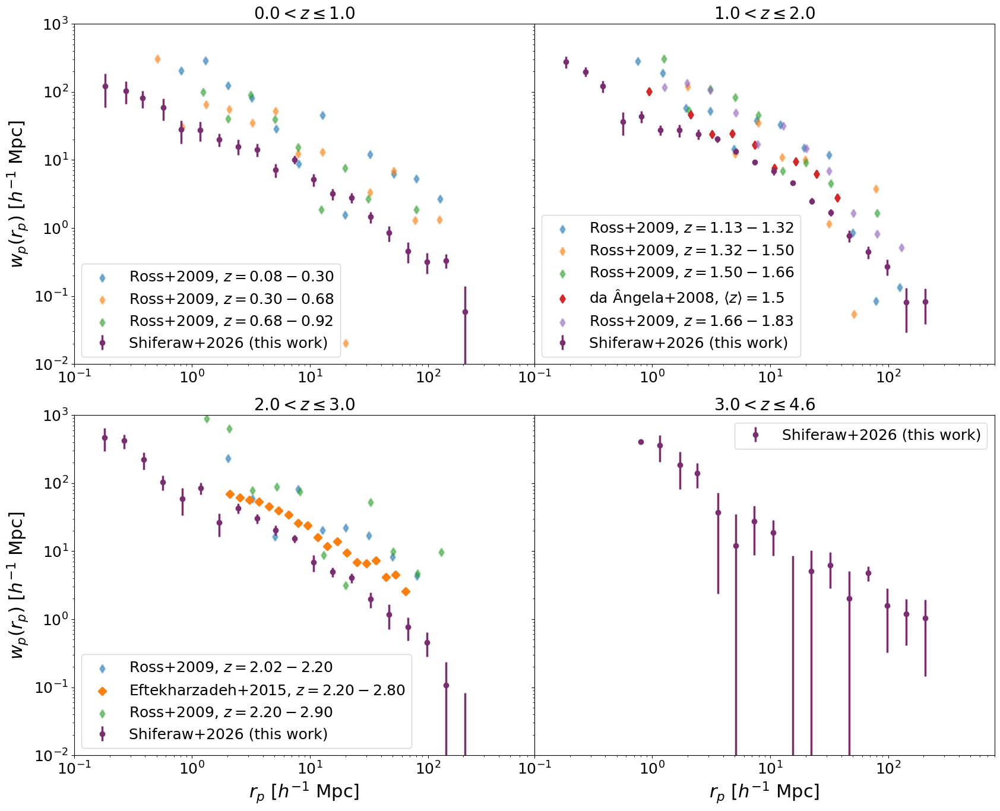

In [29]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.15, wspace = 0)
bbox_to_anchor = [(-0.45, 0.7),(1.35, 0.8), (0, 0), (0, 0)]
cosmos = ['Planck', 'Quaia']
cosmo = 'Planck'
b=30

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])

    wp = np.load('../results/wp_G{}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_{}_MC_b{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], cosmo, b))
    rpavg = np.load('../results/rpavg_G{}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_{}_MC_b{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], cosmo, b))
    C = np.load('../results/cov_wp_G{}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_N25_{}_MC_b{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], 'Planck', b))
    
    ax1.errorbar(rpavg, wp, linewidth = 2.5, marker = 'o',
                 label = r'Shiferaw+2026 (this work)'.format(cosmo), color = cmap_rocket[0], yerr = np.sqrt(np.diag(C)), linestyle = 'None')
    # ax1.errorbar(rpavg_zbin_percentile[cosmo][j], wp_zbin_percentile[cosmo][j], linewidth = 2.5, marker = 'o',
    #              label = r'Shiferaw+2026 (this work)'.format(cosmo), color = cmap_rocket[0], yerr = np.sqrt(np.diag(C)), linestyle = 'None')
        
    if j == 0:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.08-0.30$', alpha = 0.5)
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.30-0.68$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.68-0.92$', alpha = 0.5)
        ax1.legend()
    elif j == 1:
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.13-1.32$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.32-1.50$', alpha = 0.5)
        ax1.scatter(ross[j][3][0], ross[j][3][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.50-1.66$', alpha = 0.5)
        ax1.scatter(da_angela[0], da_angela[1], linewidth = 2.5, marker = 'd', label = r'da Ângela+2008, $\langle z\rangle=1.5$')
        ax1.scatter(ross[j][4][0], ross[j][4][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.66-1.83$', alpha = 0.5)
        ax1.legend()
    elif j == 2:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.02-2.20$', alpha = 0.5)
        ax1.scatter(eftekharzadeh[:,0], eftekharzadeh[:,1], linewidth = 2.5, marker = 'D', label = r'Eftekharzadeh+2015, $z = 2.20-2.80$')
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.20-2.90$', alpha = 0.5)
        ax1.legend()
    else:
        ax1.legend()

    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(zbin_array[j], zbin_array[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(1e-1, 8e2)
    ax1.set_ylim(1e-2, 1e3)


    if (j) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if scale == 'log':
        ax1.set_xscale('log')

    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected

plt.savefig('../figures/suppressed_clustering.pdf', bbox_inches = 'tight')
plt.show()

In [27]:
color_planck = sns.color_palette('Set2')[0]

<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:39: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_102539/3827992035.py:39: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))


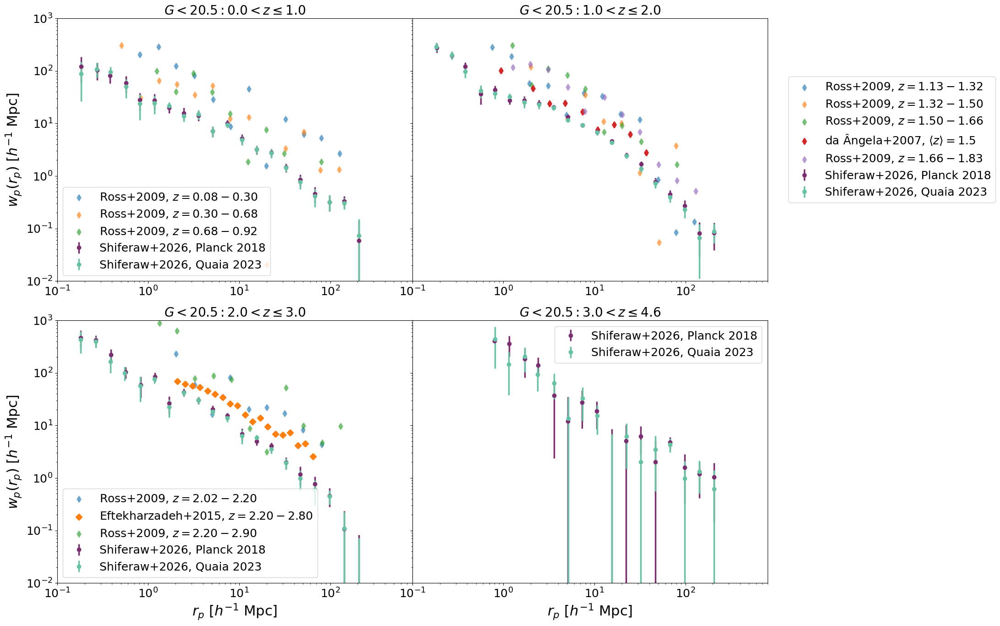

In [53]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.15, wspace = 0)
bbox_to_anchor = [(-0.45, 0.7),(1.35, 0.8), (0, 0), (0, 0)]
cosmos = ['Planck', 'Quaia']

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])
              
    for cosmo, color, alpha, year in zip(cosmos, [cmap_rocket[0], color_planck], [1, 0.5], [2018, 2023]):
        
        wp = np.load('../results/wp_G{}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_{}_MC_b{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], cosmo, b))
        rpavg = np.load('../results/rpavg_G{}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_{}_MC_b{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], cosmo, b))
        C = np.load('../results/cov_wp_G{}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_N25_{}_MC_b{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], cosmo, b))

        ax1.errorbar(rpavg, wp, linewidth = 2.5, marker = 'o', 
                     label = r'Shiferaw+2026, {} {}'.format(cosmo, year), color = color, yerr = np.sqrt(np.diag(C)), linestyle = 'None')
    if j == 0:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.08-0.30$', alpha = 0.5)
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.30-0.68$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.68-0.92$', alpha = 0.5)
        ax1.legend()
    elif j == 1:
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.13-1.32$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.32-1.50$', alpha = 0.5)
        ax1.scatter(ross[j][3][0], ross[j][3][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.50-1.66$', alpha = 0.5)
        ax1.scatter(da_angela[0], da_angela[1], linewidth = 2.5, marker = 'd', label = r'da Ângela+2007, $\langle z\rangle=1.5$')
        ax1.scatter(ross[j][4][0], ross[j][4][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.66-1.83$', alpha = 0.5)
        ax1.legend(bbox_to_anchor = bbox_to_anchor[j], loc='upper center')
    elif j == 2:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.02-2.20$', alpha = 0.5)
        ax1.scatter(eftekharzadeh[:,0], eftekharzadeh[:,1], linewidth = 2.5, marker = 'D', label = r'Eftekharzadeh+2015, $z = 2.20-2.80$')
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.20-2.90$', alpha = 0.5)
        ax1.legend()
    else:
        ax1.legend()

    ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(1e-1, 8e2)
    ax1.set_ylim(1e-2, 1e3)


    if (j) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if scale == 'log':
        ax1.set_xscale('log')

    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected

plt.show()

In [28]:
b_array = [0, 10, 20, 30, 40, 50, 60]

In [29]:
cmap_grey = plt.get_cmap('Greys')(np.linspace(0.333, 0.999, len(b_array)))

<>:43: SyntaxWarning: invalid escape sequence '\l'
<>:62: SyntaxWarning: invalid escape sequence '\c'
<>:43: SyntaxWarning: invalid escape sequence '\l'
<>:62: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_102539/858583255.py:43: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))
/tmp/ipykernel_102539/858583255.py:62: SyntaxWarning: invalid escape sequence '\c'
  second_legend = ax1.legend(custom_lines, ['$b={:.0f}^\circ$'.format(b) for b in b_array], bbox_to_anchor = bbox_to_anchor[1], loc='upper center')


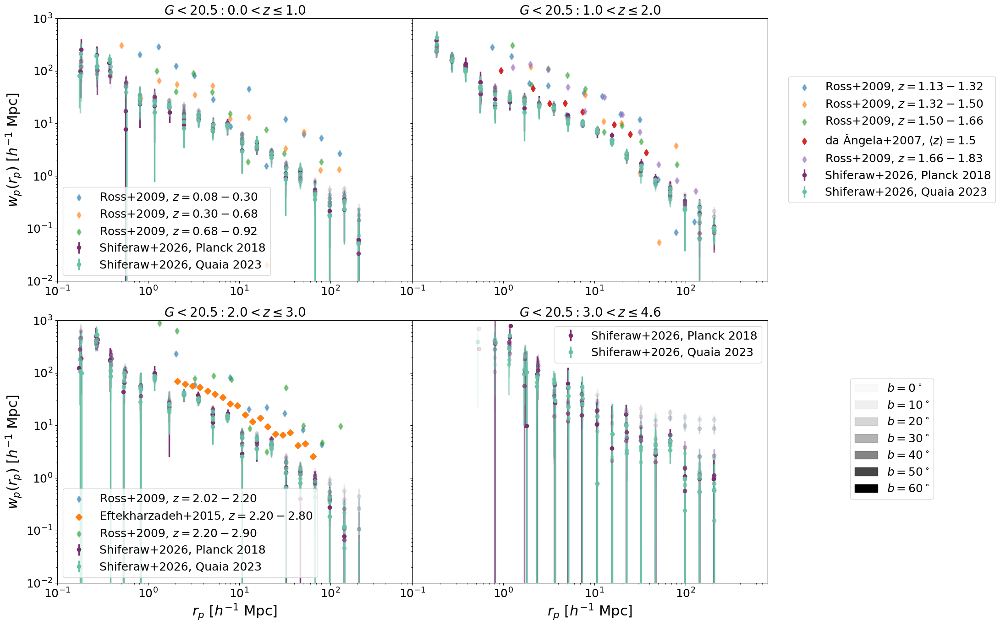

In [54]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.15, wspace = 0)
bbox_to_anchor = [(-0.45, 0.7),(1.35, 0.8), (0, 0), (0, 0)]
cosmos = ['Planck', 'Quaia']

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])
              
    for cosmo, color, year in zip(cosmos, [cmap_rocket[0], color_planck], [2018, 2023]):

        for i, cp in enumerate(b_array):

            wp = np.load('../results/wp_G{}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_{}_MC_b{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], cosmo, cp))
            rpavg = np.load('../results/rpavg_G{}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_{}_MC_b{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], cosmo, cp))
            C = np.load('../results/cov_wp_G{}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_N25_{}_MC_b{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], cosmo, cp))
            
            if cp ==60:
                ax1.errorbar(rpavg, wp, linewidth = 2.5, marker = 'o', 
                             label = r'Shiferaw+2026, {} {}'.format(cosmo, year), color = color, yerr = np.sqrt(np.diag(C)), linestyle = 'none', alpha = np.max((cp/60, 0.1)))
            else:
                ax1.errorbar(rpavg, wp, linewidth = 2.5, marker = 'o', 
                             color = color, yerr = np.sqrt(np.diag(C)), linestyle = 'none', alpha = np.max((cp/60, 0.1)))
    if j == 0:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.08-0.30$', alpha = 0.5)
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.30-0.68$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.68-0.92$', alpha = 0.5)
        ax1.legend()
    elif j == 1:
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.13-1.32$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.32-1.50$', alpha = 0.5)
        ax1.scatter(ross[j][3][0], ross[j][3][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.50-1.66$', alpha = 0.5)
        ax1.scatter(da_angela[0], da_angela[1], linewidth = 2.5, marker = 'd', label = r'da Ângela+2007, $\langle z\rangle=1.5$')
        ax1.scatter(ross[j][4][0], ross[j][4][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.66-1.83$', alpha = 0.5)
        ax1.legend(bbox_to_anchor = bbox_to_anchor[j], loc='upper center')
    elif j == 2:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.02-2.20$', alpha = 0.5)
        ax1.scatter(eftekharzadeh[:,0], eftekharzadeh[:,1], linewidth = 2.5, marker = 'D', label = r'Eftekharzadeh+2015, $z = 2.20-2.80$')
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.20-2.90$', alpha = 0.5)
        ax1.legend()

    ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(1e-1, 8e2)
    ax1.set_ylim(1e-2, 1e3)


    if (j) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if scale == 'log':
        ax1.set_xscale('log')

    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected

custom_lines = [mpatches.Patch(color = cmap_grey[i], alpha = np.max((cp/60, 0.1))) for i, cp in enumerate(b_array)]
second_legend = ax1.legend(custom_lines, ['$b={:.0f}^\circ$'.format(b) for b in b_array], bbox_to_anchor = bbox_to_anchor[1], loc='upper center')
fig.add_artist(second_legend)
ax1.legend()

plt.show()

<>:41: SyntaxWarning: invalid escape sequence '\l'
<>:41: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_102539/1910586548.py:41: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_lo, zbin_array[j], zbin_array[j+1]))


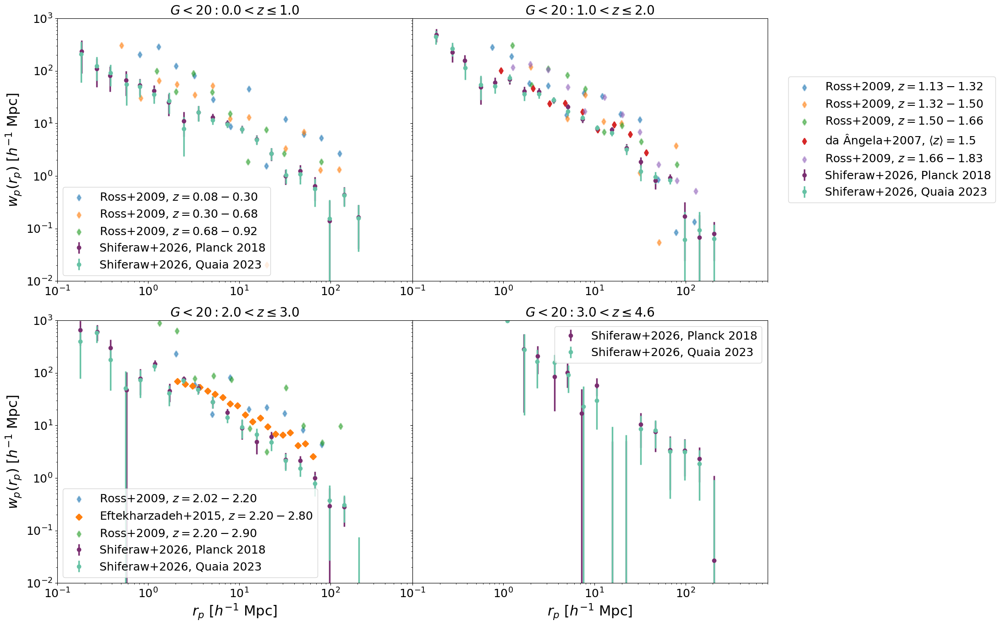

In [55]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.15, wspace = 0)
bbox_to_anchor = [(-0.45, 0.7),(1.35, 0.8), (0, 0), (0, 0)]
cosmos = ['Planck', 'Quaia']
b=30

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])
              
    for cosmo, color, alpha, year in zip(cosmos, [cmap_rocket[0], color_planck], [1, 1], [2018, 2023]): #'red', 'orange'
        
        wp = np.load('../results/wp_G{:.1f}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_{}_MC_b{}.npy'.format(G_lo, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], cosmo, b))
        rpavg = np.load('../results/rpavg_G{:.1f}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_{}_MC_b{}.npy'.format(G_lo, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], cosmo, b))
        C = np.load('../results/cov_wp_G{:.1f}_rmin{}_rmax{:.1f}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_Lmax-20.0_N25_{}_MC_b{}.npy'.format(G_lo, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], 'Planck', b))
        
        ax1.errorbar(rpavg, wp, linewidth = 2.5, marker = 'o', 
                     label = r'Shiferaw+2026, {} {}'.format(cosmo, year), color = color, alpha = alpha, yerr = np.sqrt(np.diag(C)), linestyle = 'None')
        
    if j == 0:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.08-0.30$', alpha = 0.5)
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.30-0.68$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.68-0.92$', alpha = 0.5)
        ax1.legend()
    elif j == 1:
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.13-1.32$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.32-1.50$', alpha = 0.5)
        ax1.scatter(ross[j][3][0], ross[j][3][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.50-1.66$', alpha = 0.5)
        ax1.scatter(da_angela[0], da_angela[1], linewidth = 2.5, marker = 'd', label = r'da Ângela+2007, $\langle z\rangle=1.5$')
        ax1.scatter(ross[j][4][0], ross[j][4][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.66-1.83$', alpha = 0.5)
        ax1.legend(bbox_to_anchor = bbox_to_anchor[j], loc='upper center')
    elif j == 2:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.02-2.20$', alpha = 0.5)
        ax1.scatter(eftekharzadeh[:,0], eftekharzadeh[:,1], linewidth = 2.5, marker = 'D', label = r'Eftekharzadeh+2015, $z = 2.20-2.80$')
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.20-2.90$', alpha = 0.5)
        ax1.legend()
    else:
        ax1.legend()

    ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_lo, zbin_array[j], zbin_array[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(1e-1, 8e2)
    ax1.set_ylim(1e-2, 1e3)


    if (j) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if scale == 'log':
        ax1.set_xscale('log')

    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected

plt.show()

### Selection function-based mask

0.6894778799187598
Pixels masked by MC but not already by selfunc: 1911
G20.5_zmin0.0zmax1.0: 0.31              224099 vs 324336
2.262481238764721 6.856130414881113


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.6998052038245415
Pixels masked by MC but not already by selfunc: 3700
G20.5_zmin1.0zmax2.0: 0.28              464321 vs 648196
4.913893918436514 13.979375938334318


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.7010382664423291
Pixels masked by MC but not already by selfunc: 3094
G20.5_zmin2.0zmax3.0: 0.25              214535 vs 286508
2.1489274410937225 6.580524056302112


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.7686898940836221
Pixels masked by MC but not already by selfunc: 352
G20.5_zmin3.0zmax4.6: 0.22              28576 vs 36458
0.14357323289935575 1.019187183767311


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


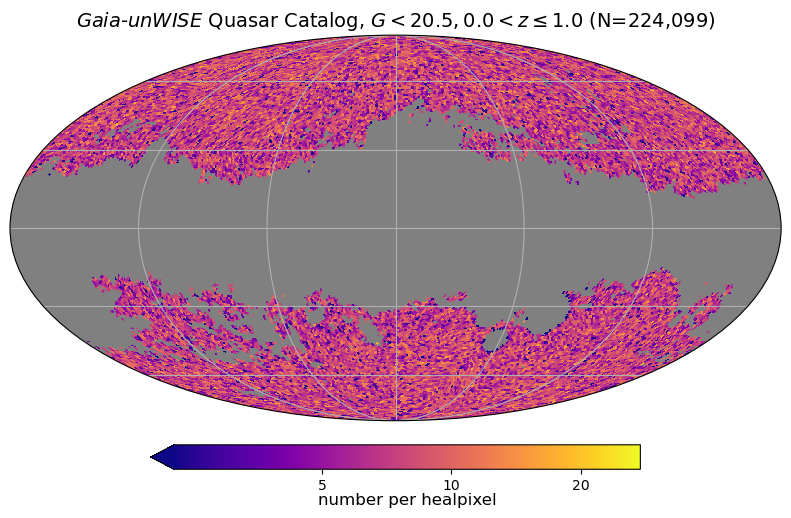

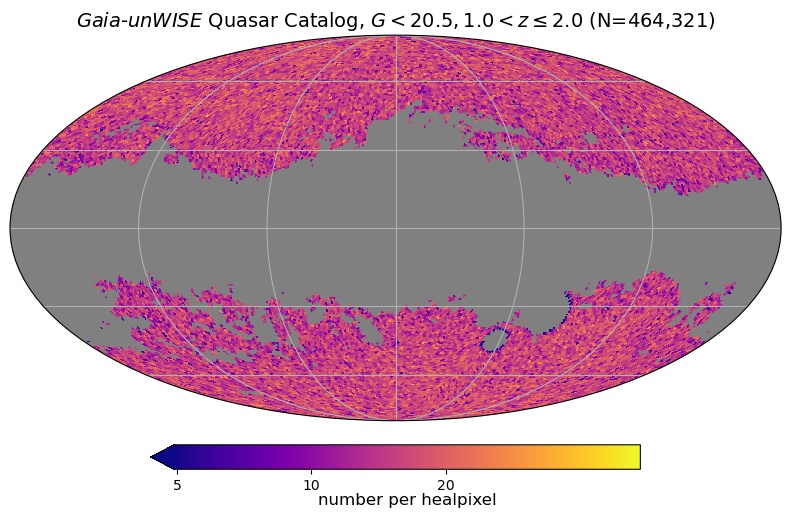

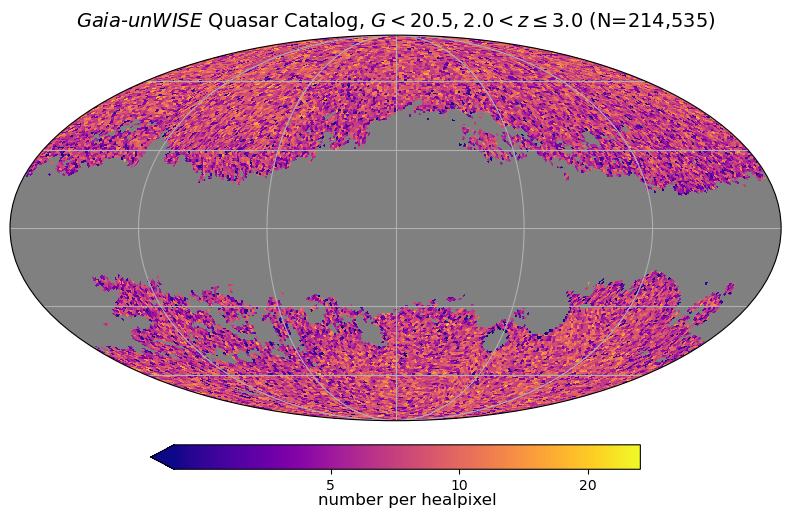

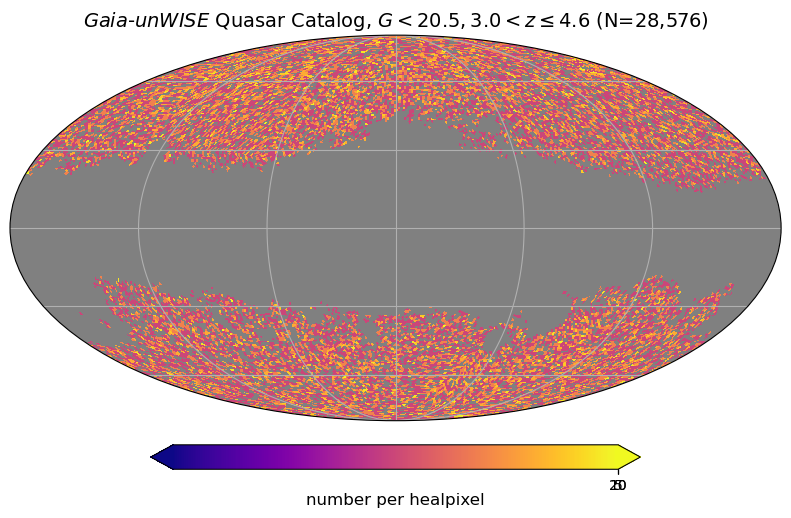

In [91]:
wp_zbin_percentile = {'Planck': [], 'Quaia': []}
rpavg_zbin_percentile = {'Planck': [], 'Quaia': []}
cosmos = ['Planck', 'Quaia']
fac_stdev = 0.45 #0.55
cosmo = 'Planck'
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [zbin_array], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask*100, percentile = True) # mask=mask)
    
    N_gcatlo_mask = len(tab_datahi_mask_zbin0)
    pixel_indices_datahi_bin0 = hp.ang2pix(NSIDE, tab_datahi_mask_zbin0['ra'], tab_datahi_mask_zbin0['dec'], lonlat=True)
    map_gcatlo = np.bincount(pixel_indices_datahi_bin0, minlength=NPIX)
    print(np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), np.mean(map_gcatlo)+fac_stdev*np.std(map_gcatlo))
    title_gcatlo = rf"{name_catalog}, $G<{G_hi},{zbin_array[j]:.1f}<z \leq{zbin_array[j+1]:.1f}$ (N={N_gcatlo_mask:,})"
    projview(map_gcatlo*hp.pixelfunc.nside2pixarea(NSIDE, degrees = True), title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C','G'],
                min=np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), max=np.mean(map_gcatlo)+10*fac_stdev*np.std(map_gcatlo), 
            norm='log', graticule=True, cbar_ticks=cbar_ticks, graticule_labels=False) #True

    # for cosmo in cosmos:
    wp_zbin_i, rpavg_zbin_i, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Om0[cosmo], 
                                                  h = Planck18.h, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
    wp_zbin_percentile[cosmo].append(wp_zbin_i)
    rpavg_zbin_percentile[cosmo].append(rpavg_zbin_i)

<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:39: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_229425/700144732.py:39: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))


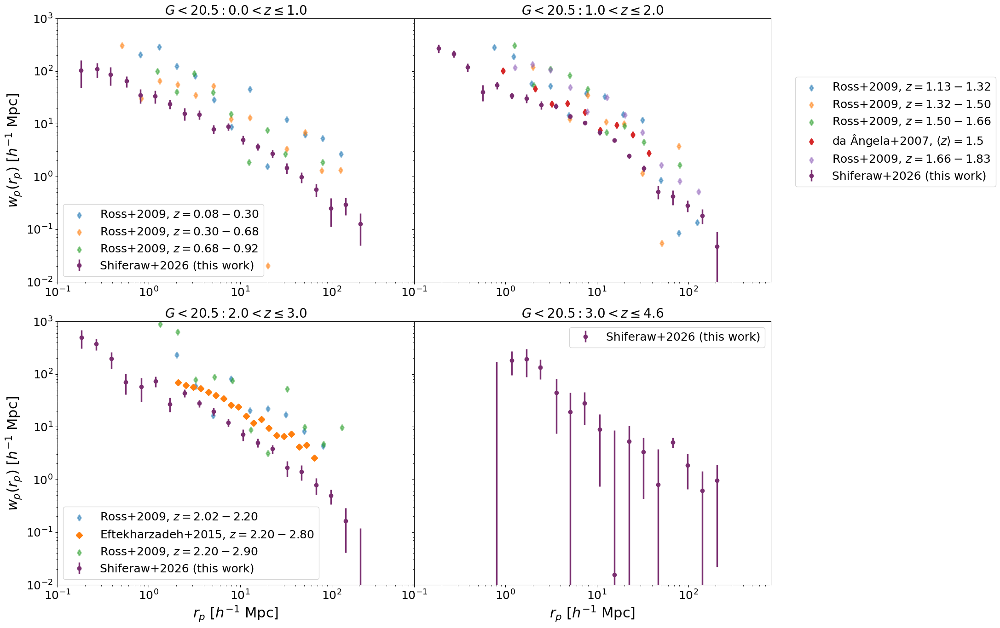

In [44]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.15, wspace = 0)
bbox_to_anchor = [(-0.45, 0.7),(1.35, 0.8), (0, 0), (0, 0)]
cosmos = ['Planck', 'Quaia']
cosmo = 'Planck'

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])
              
    # for cosmo, color in zip(cosmos, ['red', 'orange']):
        
    C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_N25_{}_MC_mask.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], 'Planck'))
    
    ax1.errorbar(rpavg_zbin_percentile[cosmo][j], wp_zbin_percentile[cosmo][j], linewidth = 2.5, marker = 'o',
                 label = r'Shiferaw+2026 (this work)'.format(cosmo), color = cmap_rocket[0], yerr = np.sqrt(np.diag(C)), linestyle = 'None')
        
    if j == 0:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.08-0.30$', alpha = 0.5)
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.30-0.68$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.68-0.92$', alpha = 0.5)
        ax1.legend()
    elif j == 1:
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.13-1.32$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.32-1.50$', alpha = 0.5)
        ax1.scatter(ross[j][3][0], ross[j][3][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.50-1.66$', alpha = 0.5)
        ax1.scatter(da_angela[0], da_angela[1], linewidth = 2.5, marker = 'd', label = r'da Ângela+2007, $\langle z\rangle=1.5$')
        ax1.scatter(ross[j][4][0], ross[j][4][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.66-1.83$', alpha = 0.5)
        ax1.legend(bbox_to_anchor = bbox_to_anchor[j], loc='upper center')
    elif j == 2:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.02-2.20$', alpha = 0.5)
        ax1.scatter(eftekharzadeh[:,0], eftekharzadeh[:,1], linewidth = 2.5, marker = 'D', label = r'Eftekharzadeh+2015, $z = 2.20-2.80$')
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.20-2.90$', alpha = 0.5)
        ax1.legend()
    else:
        ax1.legend()

    ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(1e-1, 8e2)
    ax1.set_ylim(1e-2, 1e3)


    if (j) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if scale == 'log':
        ax1.set_xscale('log')

    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected

plt.show()

0.7606791584252974
Pixels masked by MC but not already by selfunc: 926
G20.0_zmin0.0zmax1.0: 0.31              138599 vs 200785
1.3237866657917519 4.315821081604081


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.7572178281564923
Pixels masked by MC but not already by selfunc: 2094
G20.0_zmin1.0zmax2.0: 0.28              264696 vs 369335
2.707891506597301 8.062616305902699


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.7346083179423708
Pixels masked by MC but not already by selfunc: 1127
G20.0_zmin2.0zmax3.0: 0.26              122259 vs 165277
1.143602427784713 3.831129017527787


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.862919347799225
Pixels masked by MC but not already by selfunc: 78
G20.0_zmin3.0zmax4.6: 0.22              15923 vs 20451
0.02685672778475351 0.6210518008610799


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia.py:1097: RuntimeWarning: invalid value encountered in scalar divide
  rpavg = [np.sum((DD_counts['rpavg']*DD_counts['npairs'])[DD_counts['rmin']==i])/np.sum(DD_counts['npairs'][DD_counts['rmin']==i])


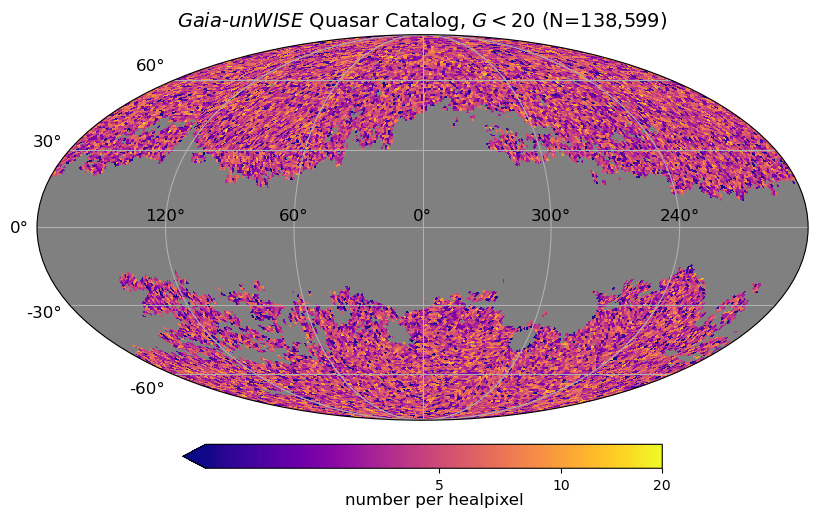

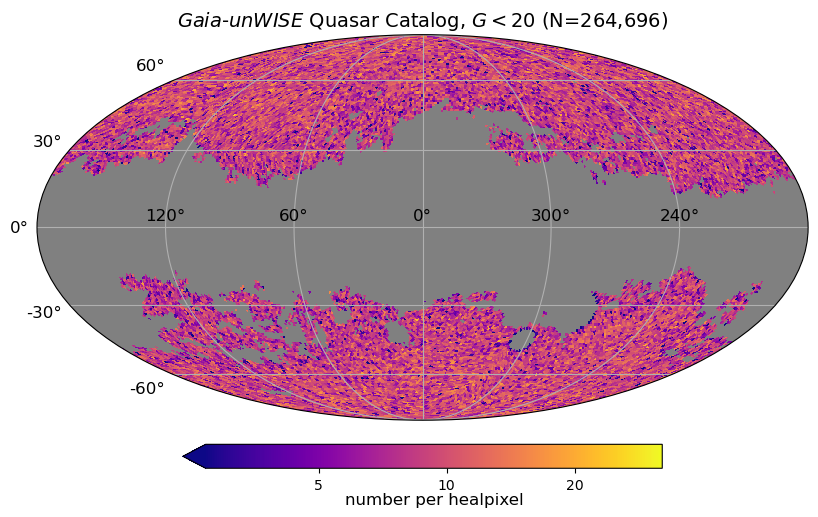

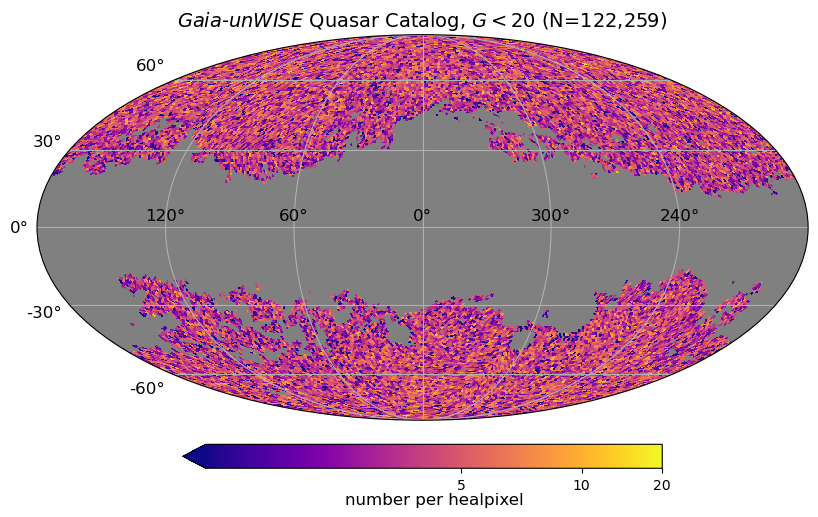

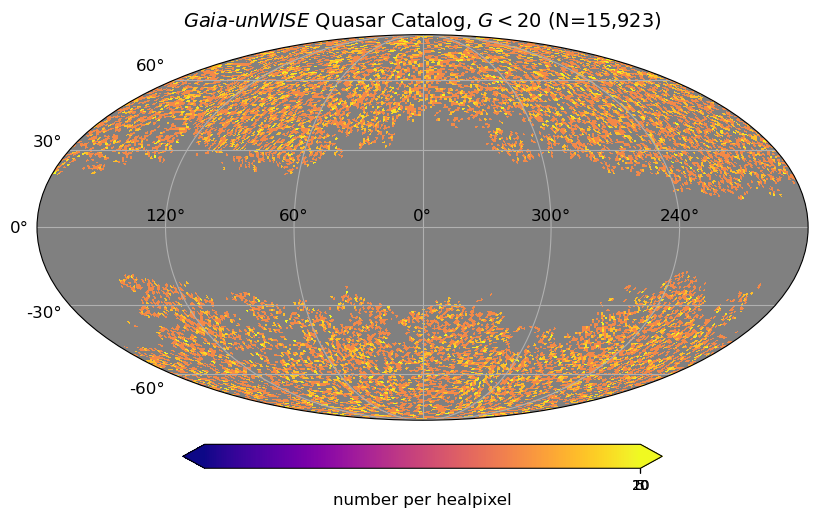

In [64]:
wp_zbin_percentile = {'Planck': [], 'Quaia': []}
rpavg_zbin_percentile = {'Planck': [], 'Quaia': []}
cosmos = ['Planck', 'Quaia']
fac_stdev = 0.45 #0.55

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _= quaia.make_bins(G_lo, [j], True, ['z'], 
                                                                                     bins = [zbin_array], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask*100, percentile = True) # mask=mask)
    
    N_gcatlo_mask = len(tab_datahi_mask_zbin0)
    pixel_indices_datahi_bin0 = hp.ang2pix(NSIDE, tab_datahi_mask_zbin0['ra'], tab_datahi_mask_zbin0['dec'], lonlat=True)
    map_gcatlo = np.bincount(pixel_indices_datahi_bin0, minlength=NPIX)
    print(np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), np.mean(map_gcatlo)+fac_stdev*np.std(map_gcatlo))
    title_gcatlo = rf"{name_catalog}, $G<{G_lo}$ (N={N_gcatlo_mask:,})"
    projview(map_gcatlo*hp.pixelfunc.nside2pixarea(NSIDE, degrees = True), title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C','G'],
                min=np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), max=np.mean(map_gcatlo)+10*fac_stdev*np.std(map_gcatlo), 
            norm='log', graticule=True, cbar_ticks=cbar_ticks, graticule_labels=True)

    for cosmo in cosmos:

        wp_zbin_i, rpavg_zbin_i, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Om0[cosmo], 
                                                      h = Planck18.h, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
        wp_zbin_percentile[cosmo].append(wp_zbin_i)
        rpavg_zbin_percentile[cosmo].append(rpavg_zbin_i)

In [66]:
color_planck = sns.color_palette()[5]

<>:38: SyntaxWarning: invalid escape sequence '\l'
<>:38: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_229425/3159408202.py:38: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_lo, zbin_array[j], zbin_array[j+1]))


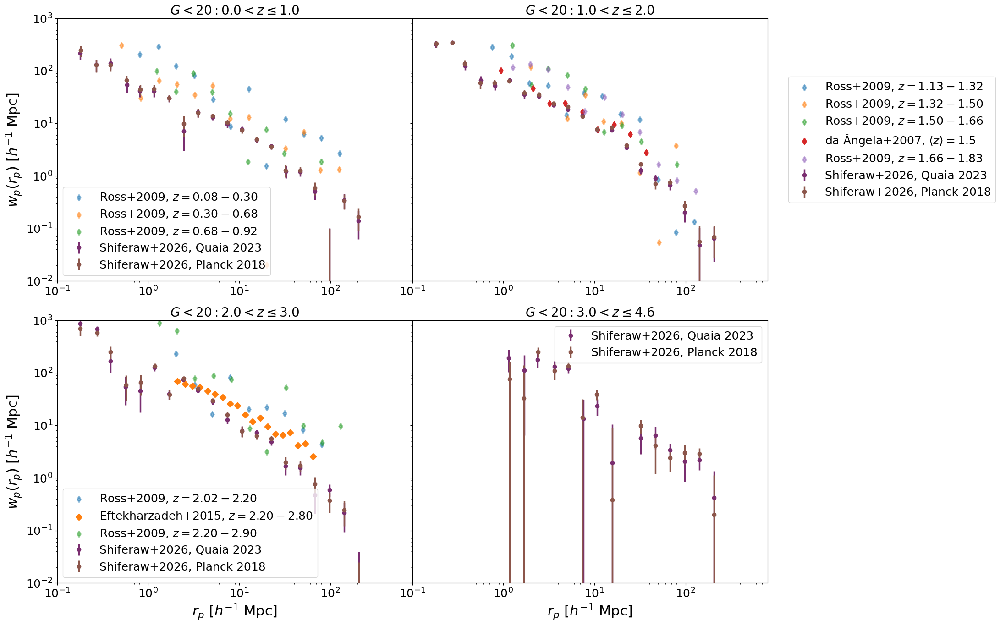

In [68]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.15, wspace = 0)
bbox_to_anchor = [(-0.45, 0.7),(1.35, 0.8), (0, 0), (0, 0)]
cosmos = ['Planck', 'Quaia']

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])
              
    for cosmo, color, alpha, year in zip(cosmos[::-1], [cmap_rocket[0], color_planck], [1, 1], [2023, 2018]): #'red', 'orange'
        
        C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_N25_{}_MC_mask.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], 'Planck'))
        
        ax1.errorbar(rpavg_zbin_percentile[cosmo][j], wp_zbin_percentile[cosmo][j], linewidth = 2.5, marker = 'o', 
                     label = r'Shiferaw+2026, {} {}'.format(cosmo, year), color = color, alpha = alpha, yerr = np.sqrt(np.diag(C)), linestyle = 'None')
        
    if j == 0:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.08-0.30$', alpha = 0.5)
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.30-0.68$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.68-0.92$', alpha = 0.5)
        ax1.legend()
    elif j == 1:
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.13-1.32$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.32-1.50$', alpha = 0.5)
        ax1.scatter(ross[j][3][0], ross[j][3][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.50-1.66$', alpha = 0.5)
        ax1.scatter(da_angela[0], da_angela[1], linewidth = 2.5, marker = 'd', label = r'da Ângela+2007, $\langle z\rangle=1.5$')
        ax1.scatter(ross[j][4][0], ross[j][4][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.66-1.83$', alpha = 0.5)
        ax1.legend(bbox_to_anchor = bbox_to_anchor[j], loc='upper center')
    elif j == 2:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.02-2.20$', alpha = 0.5)
        ax1.scatter(eftekharzadeh[:,0], eftekharzadeh[:,1], linewidth = 2.5, marker = 'D', label = r'Eftekharzadeh+2015, $z = 2.20-2.80$')
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.20-2.90$', alpha = 0.5)
        ax1.legend()
    else:
        ax1.legend()

    ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_lo, zbin_array[j], zbin_array[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(1e-1, 8e2)
    ax1.set_ylim(1e-2, 1e3)


    if (j) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if scale == 'log':
        ax1.set_xscale('log')

    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected

plt.show()

0.6894778799187598
Pixels masked by MC but not already by selfunc: 1911
G20.5_zmin0.0zmax1.0: 0.31              224099 vs 324336
2.262481238764721 6.856130414881113


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.6998052038245415
Pixels masked by MC but not already by selfunc: 3700
G20.5_zmin1.0zmax2.0: 0.28              464321 vs 648196
4.913893918436514 13.979375938334318


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.7010382664423291
Pixels masked by MC but not already by selfunc: 3094
G20.5_zmin2.0zmax3.0: 0.25              214535 vs 286508
2.1489274410937225 6.580524056302112


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.7686898940836221
Pixels masked by MC but not already by selfunc: 352
G20.5_zmin3.0zmax4.6: 0.22              28576 vs 36458
0.14357323289935575 1.019187183767311


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


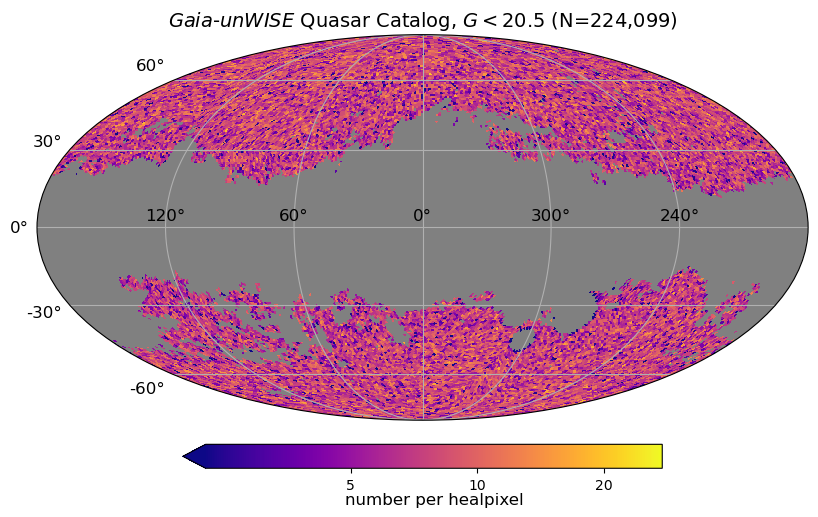

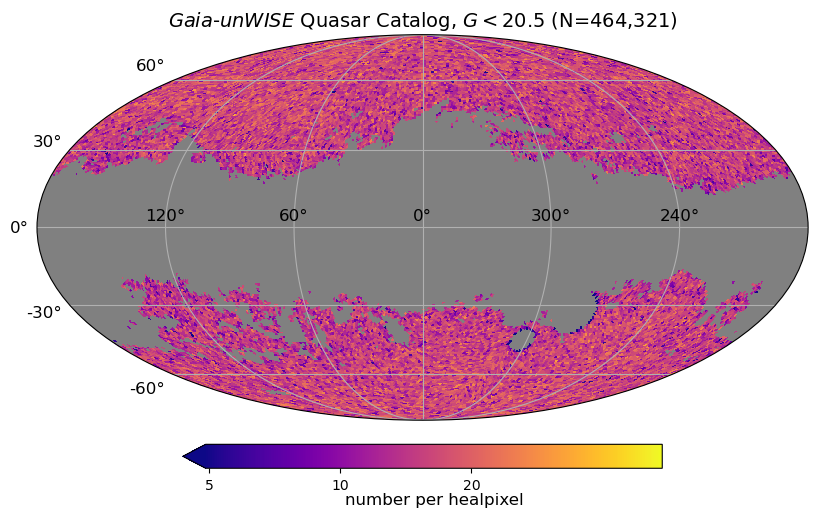

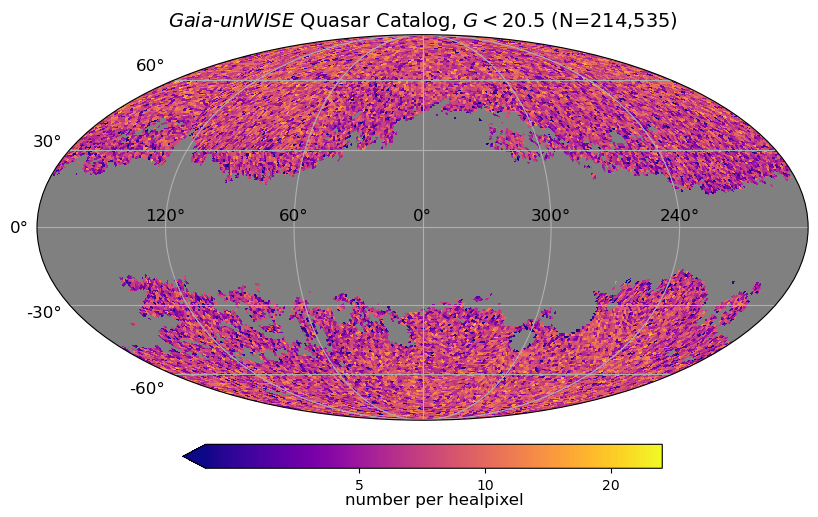

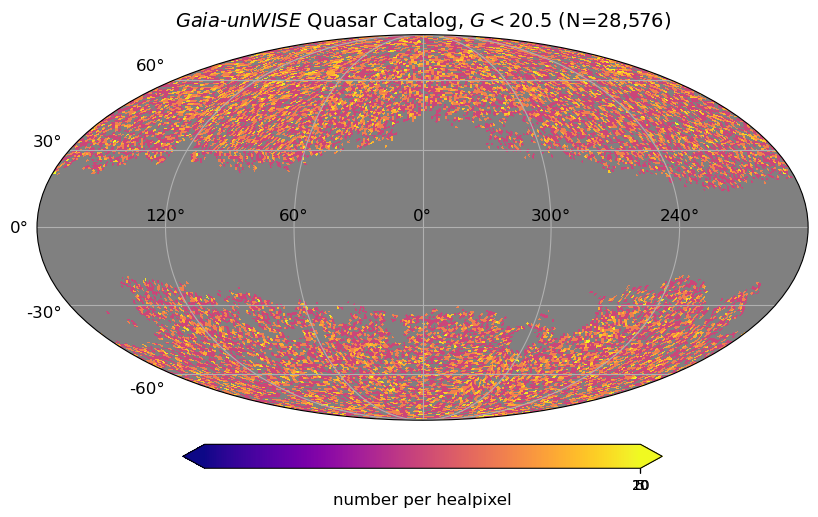

In [69]:
wp_zbin_percentile = {'Planck': [], 'Quaia': []}
rpavg_zbin_percentile = {'Planck': [], 'Quaia': []}
cosmos = ['Planck', 'Quaia']

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [zbin_array], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask*100, percentile = True) # mask=mask)
    
    N_gcatlo_mask = len(tab_datahi_mask_zbin0)
    pixel_indices_datahi_bin0 = hp.ang2pix(NSIDE, tab_datahi_mask_zbin0['ra'], tab_datahi_mask_zbin0['dec'], lonlat=True)
    map_gcatlo = np.bincount(pixel_indices_datahi_bin0, minlength=NPIX)
    print(np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), np.mean(map_gcatlo)+fac_stdev*np.std(map_gcatlo))
    title_gcatlo = rf"{name_catalog}, $G<{G_hi}$ (N={N_gcatlo_mask:,})"
    projview(map_gcatlo*hp.pixelfunc.nside2pixarea(NSIDE, degrees = True), title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C','G'],
                min=np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), max=np.mean(map_gcatlo)+10*fac_stdev*np.std(map_gcatlo), 
            norm='log', graticule=True, cbar_ticks=cbar_ticks, graticule_labels=True)

    for cosmo in cosmos:

        wp_zbin_i, rpavg_zbin_i, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Om0[cosmo], 
                                                      h = Planck18.h, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
        wp_zbin_percentile[cosmo].append(wp_zbin_i)
        rpavg_zbin_percentile[cosmo].append(rpavg_zbin_i)

<>:37: SyntaxWarning: invalid escape sequence '\l'
<>:37: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_229425/3247762341.py:37: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))


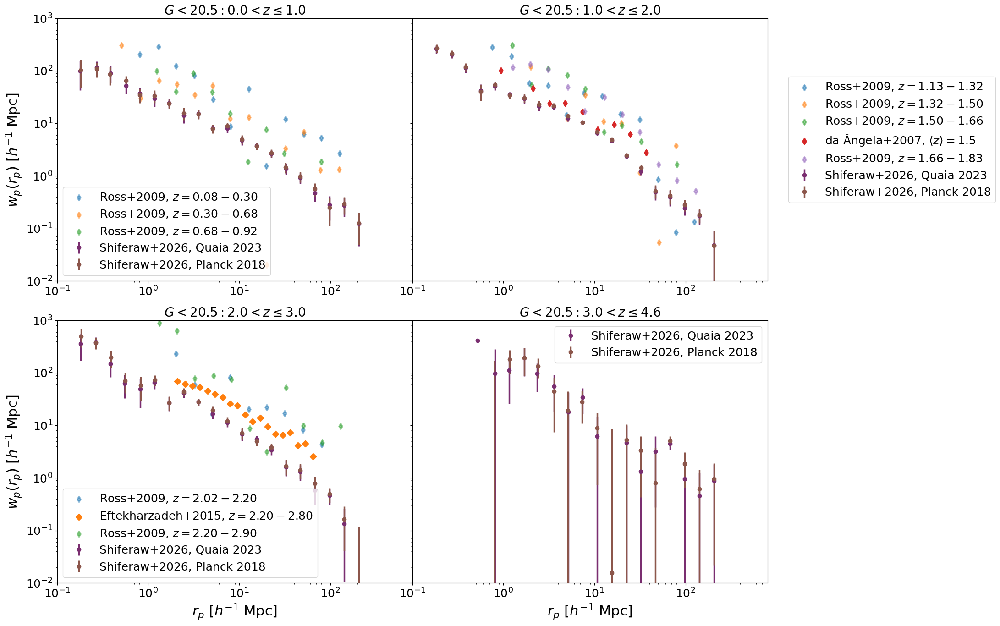

In [70]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.15, wspace = 0)
bbox_to_anchor = [(-0.45, 0.7),(1.35, 0.8), (0, 0), (0, 0)]
cosmos = ['Planck', 'Quaia']

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])
              
    for cosmo, color, alpha, year in zip(cosmos[::-1], [cmap_rocket[0], color_planck], [1, 0.5], [2023, 2018]):
        
        C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_N25_{}_MC_mask.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], 'Planck'))
        
        ax1.errorbar(rpavg_zbin_percentile[cosmo][j], wp_zbin_percentile[cosmo][j], linewidth = 2.5, marker = 'o', 
                     label = r'Shiferaw+2026, {} {}'.format(cosmo, year), color = color, yerr = np.sqrt(np.diag(C)), linestyle = 'None')
    if j == 0:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.08-0.30$', alpha = 0.5)
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.30-0.68$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.68-0.92$', alpha = 0.5)
        ax1.legend()
    elif j == 1:
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.13-1.32$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.32-1.50$', alpha = 0.5)
        ax1.scatter(ross[j][3][0], ross[j][3][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.50-1.66$', alpha = 0.5)
        ax1.scatter(da_angela[0], da_angela[1], linewidth = 2.5, marker = 'd', label = r'da Ângela+2007, $\langle z\rangle=1.5$')
        ax1.scatter(ross[j][4][0], ross[j][4][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.66-1.83$', alpha = 0.5)
        ax1.legend(bbox_to_anchor = bbox_to_anchor[j], loc='upper center')
    elif j == 2:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.02-2.20$', alpha = 0.5)
        ax1.scatter(eftekharzadeh[:,0], eftekharzadeh[:,1], linewidth = 2.5, marker = 'D', label = r'Eftekharzadeh+2015, $z = 2.20-2.80$')
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.20-2.90$', alpha = 0.5)
        ax1.legend()
    else:
        ax1.legend()

    ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(1e-1, 8e2)
    ax1.set_ylim(1e-2, 1e3)


    if (j) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if scale == 'log':
        ax1.set_xscale('log')

    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected

plt.show()

In [98]:
importlib.reload(quaia)

<module 'quaia' from '/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia.py'>

Pixels masked by MC but not already by selfunc: 0
G20.5_zmin0.0zmax1.0: 0.32              220833 vs 324336
2.233193829681866 6.752523943755634


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


Pixels masked by MC but not already by selfunc: 0
G20.5_zmin1.0zmax2.0: 0.29              458013 vs 648196
4.853977247862007 13.782619431825493


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


Pixels masked by MC but not already by selfunc: 0
G20.5_zmin2.0zmax3.0: 0.27              210366 vs 286508
2.0940449077348977 6.465769545390103


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


Pixels masked by MC but not already by selfunc: 0
G20.5_zmin3.0zmax4.6: 0.22              28350 vs 36458
0.14150571212103313 1.0120587410039668


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


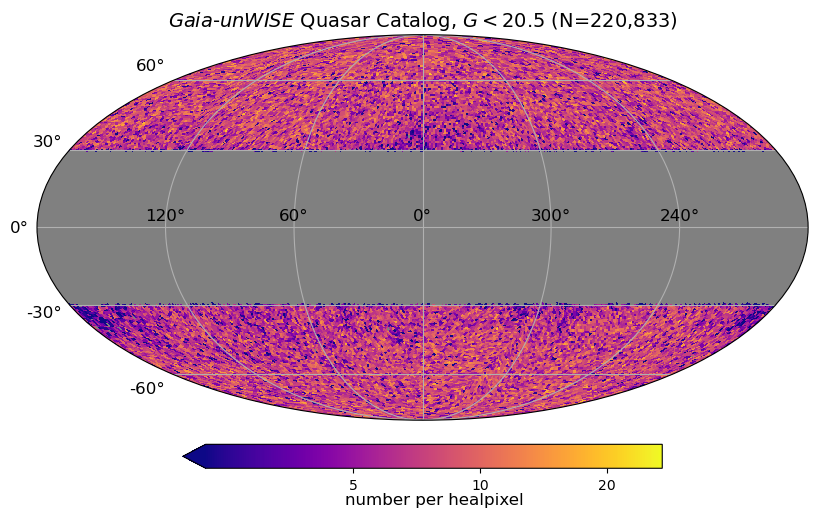

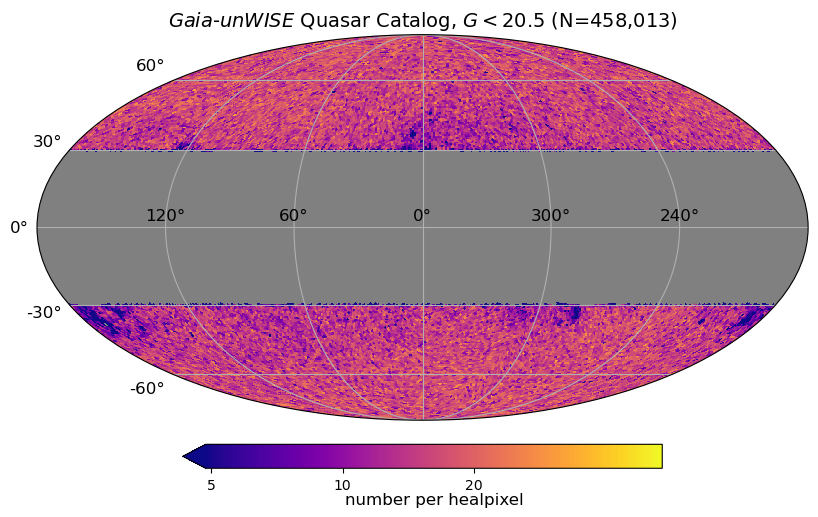

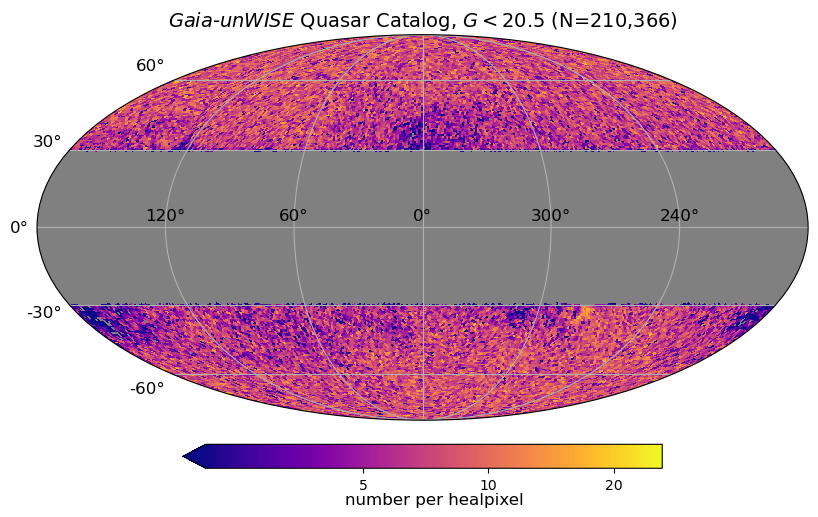

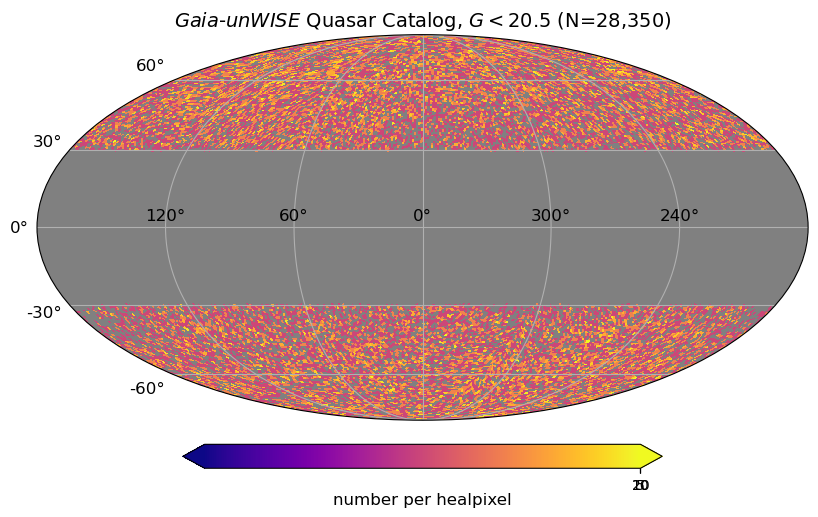

In [99]:
wp_zbin_percentile = {'Planck': [], 'Quaia': []}
rpavg_zbin_percentile = {'Planck': [], 'Quaia': []}
cosmos = ['Planck', 'Quaia']

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [zbin_array], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = 0, b = 30, MC = '_', mask_type = 'b') # mask=mask)
    
    N_gcatlo_mask = len(tab_datahi_mask_zbin0)
    pixel_indices_datahi_bin0 = hp.ang2pix(NSIDE, tab_datahi_mask_zbin0['ra'], tab_datahi_mask_zbin0['dec'], lonlat=True)
    map_gcatlo = np.bincount(pixel_indices_datahi_bin0, minlength=NPIX)
    print(np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), np.mean(map_gcatlo)+fac_stdev*np.std(map_gcatlo))
    title_gcatlo = rf"{name_catalog}, $G<{G_hi}$ (N={N_gcatlo_mask:,})"
    projview(map_gcatlo*hp.pixelfunc.nside2pixarea(NSIDE, degrees = True), title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C','G'],
                min=np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), max=np.mean(map_gcatlo)+10*fac_stdev*np.std(map_gcatlo), 
            norm='log', graticule=True, cbar_ticks=cbar_ticks, graticule_labels=True)

    for cosmo in cosmos:

        wp_zbin_i, rpavg_zbin_i, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Om0[cosmo], 
                                                      h = Planck18.h, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
        wp_zbin_percentile[cosmo].append(wp_zbin_i)
        rpavg_zbin_percentile[cosmo].append(rpavg_zbin_i)

<>:37: SyntaxWarning: invalid escape sequence '\l'
<>:37: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_229425/1913579663.py:37: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))


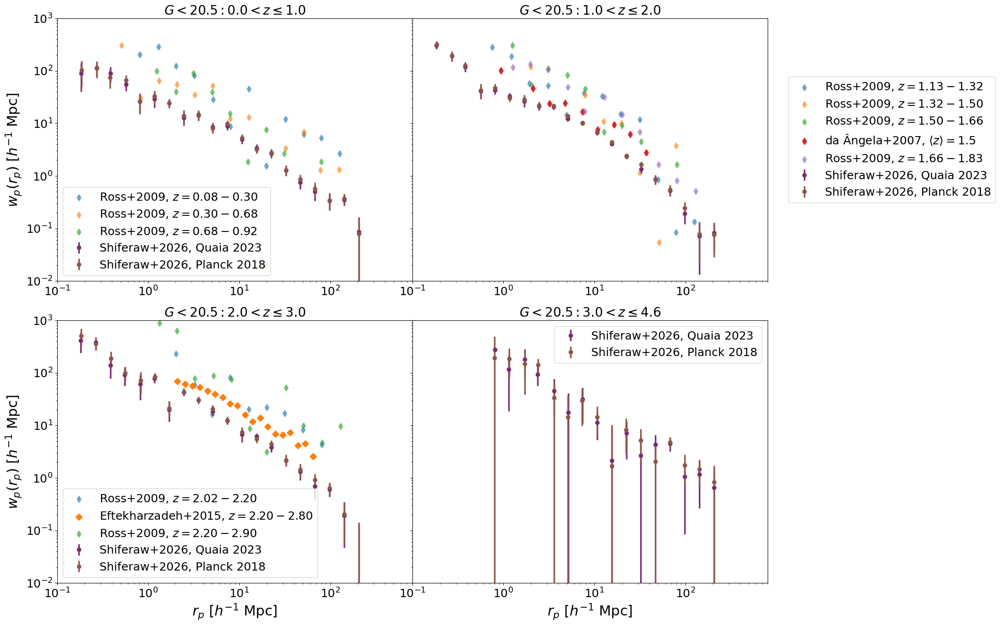

In [102]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.15, wspace = 0)
bbox_to_anchor = [(-0.45, 0.7),(1.35, 0.8), (0, 0), (0, 0)]
cosmos = ['Planck', 'Quaia']

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])
              
    for cosmo, color, year in zip(cosmos[::-1], [cmap_rocket[0], color_planck], [2023, 2018]):
        
        C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_z{:.1f}_N25_{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, j, cosmo)) # wrong cov technically
        
        ax1.errorbar(rpavg_zbin_percentile[cosmo][j], wp_zbin_percentile[cosmo][j], linewidth = 2.5, marker = 'o', 
                     label = r'Shiferaw+2026, {} {}'.format(cosmo, year), color = color, yerr = np.sqrt(np.diag(C)), linestyle = 'None')
    if j == 0:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.08-0.30$', alpha = 0.5)
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.30-0.68$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.68-0.92$', alpha = 0.5)
        ax1.legend()
    elif j == 1:
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.13-1.32$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.32-1.50$', alpha = 0.5)
        ax1.scatter(ross[j][3][0], ross[j][3][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.50-1.66$', alpha = 0.5)
        ax1.scatter(da_angela[0], da_angela[1], linewidth = 2.5, marker = 'd', label = r'da Ângela+2007, $\langle z\rangle=1.5$')
        ax1.scatter(ross[j][4][0], ross[j][4][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.66-1.83$', alpha = 0.5)
        ax1.legend(bbox_to_anchor = bbox_to_anchor[j], loc='upper center')
    elif j == 2:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.02-2.20$', alpha = 0.5)
        ax1.scatter(eftekharzadeh[:,0], eftekharzadeh[:,1], linewidth = 2.5, marker = 'D', label = r'Eftekharzadeh+2015, $z = 2.20-2.80$')
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.20-2.90$', alpha = 0.5)
        ax1.legend()
    else:
        ax1.legend()

    ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(1e-1, 8e2)
    ax1.set_ylim(1e-2, 1e3)


    if (j) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if scale == 'log':
        ax1.set_xscale('log')

    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected

plt.show()

0.0
Pixels masked by MC but not already by selfunc: 3194
G20.5_zmin0.0zmax1.0: 0.01              321142 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.0
Pixels masked by MC but not already by selfunc: 3194
G20.5_zmin0.0zmax1.0: 0.01              321142 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.27336665543454974
Pixels masked by MC but not already by selfunc: 3194
G20.5_zmin0.0zmax1.0: 0.03              315494 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


... (86 outputs left out)

0.6859075493190232
Pixels masked by MC but not already by selfunc: 369
G20.5_zmin3.0zmax4.6: 0.11              32466 vs 36458
0.21212989524680115 1.1089150266281989


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0.7686898940836221
Pixels masked by MC but not already by selfunc: 352
G20.5_zmin3.0zmax4.6: 0.22              28576 vs 36458
0.14357323289935575 1.019187183767311


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


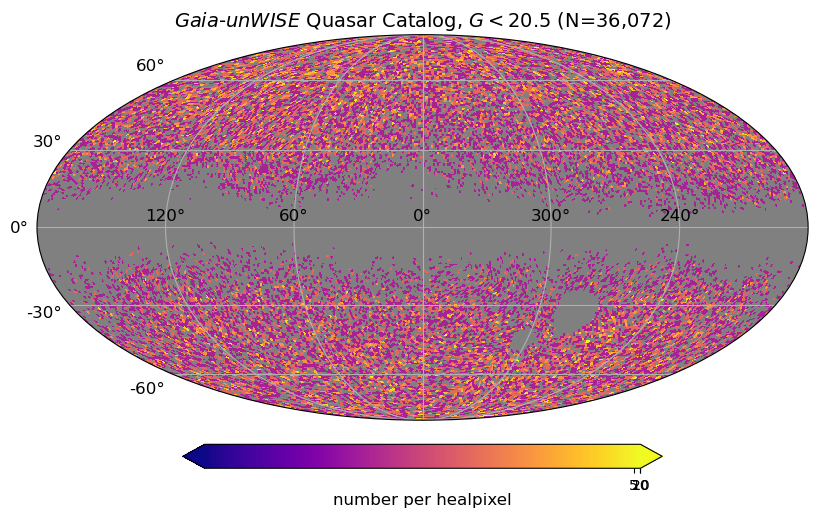

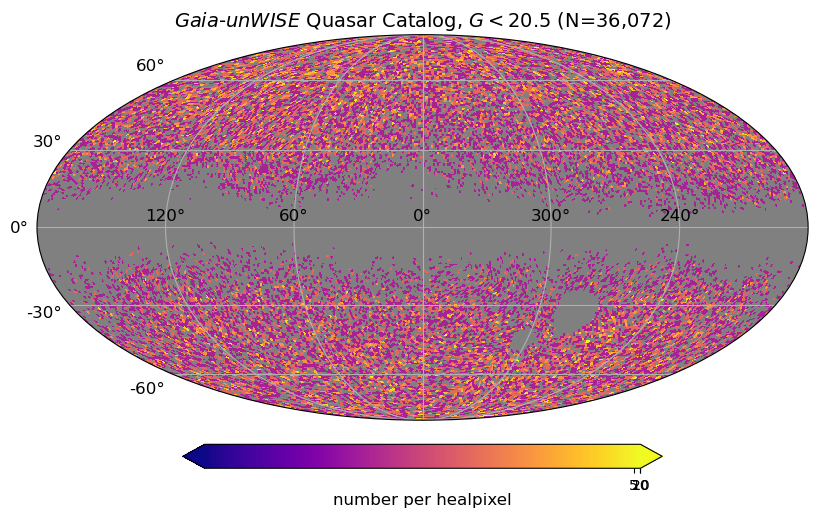

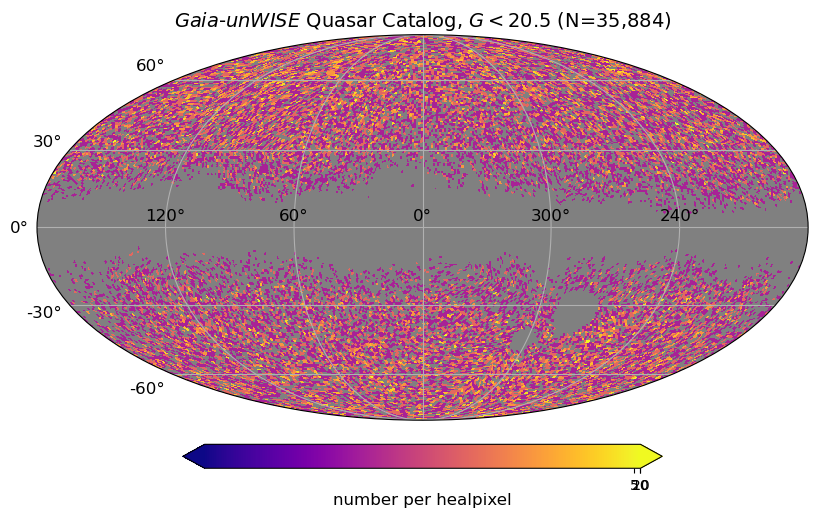

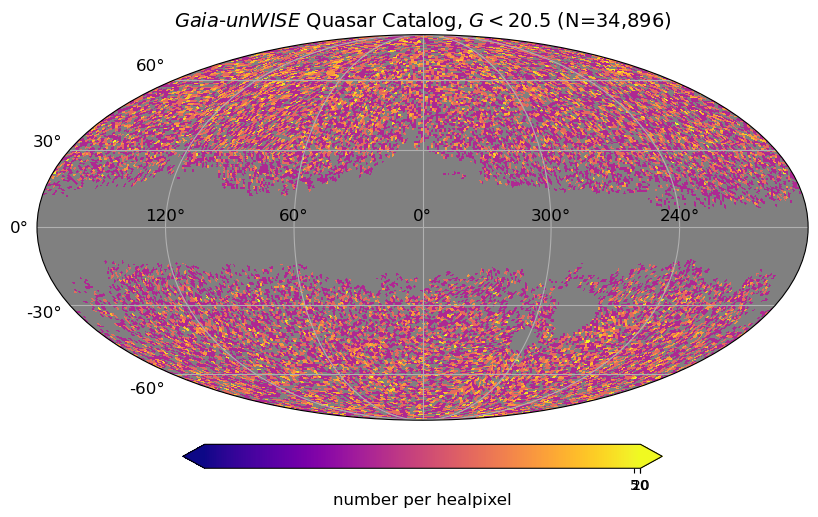

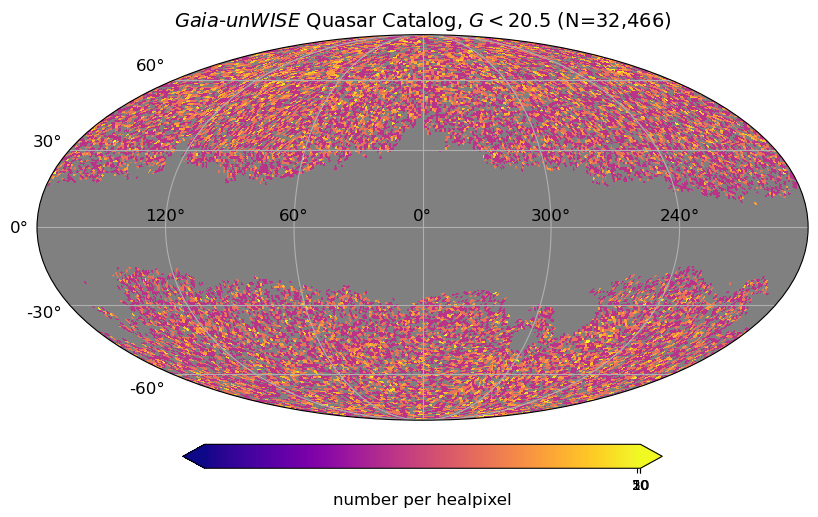

...

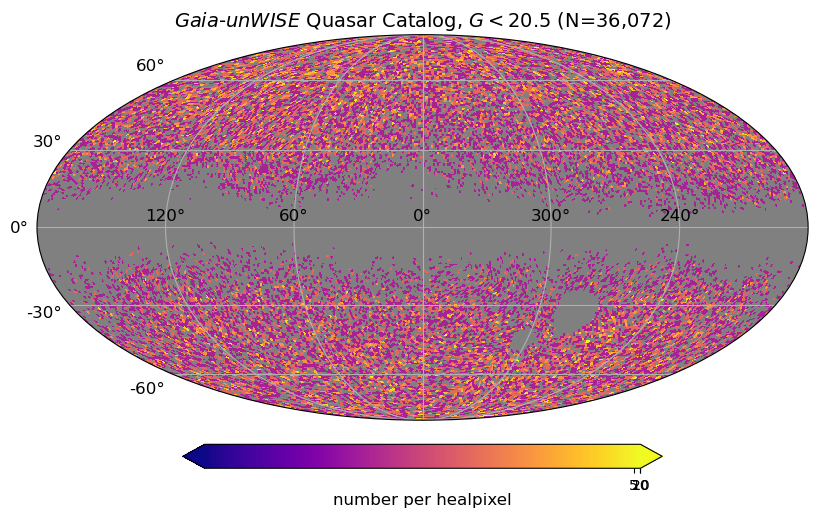

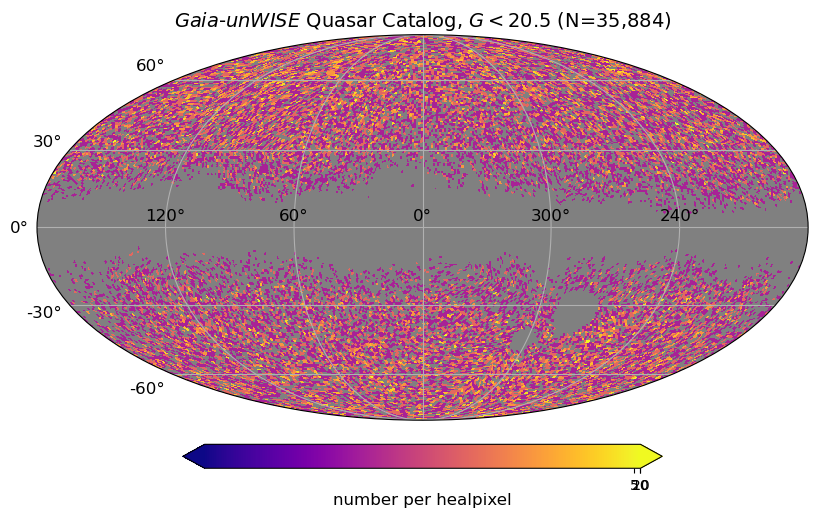

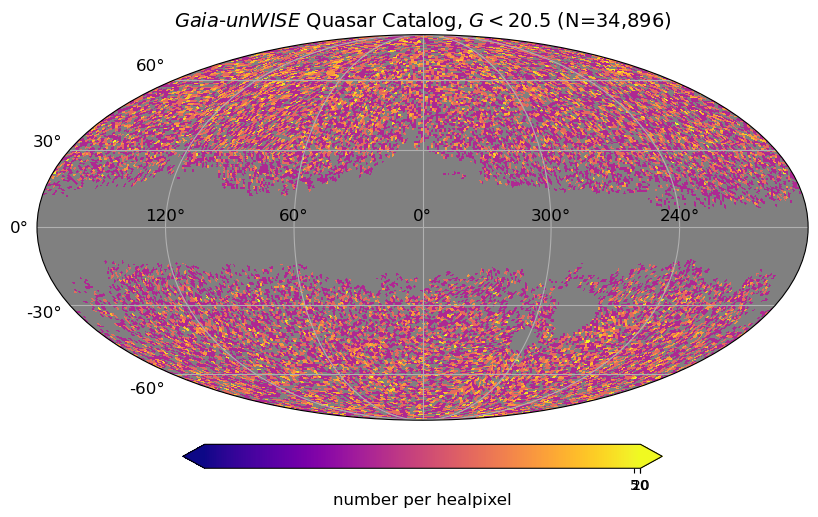

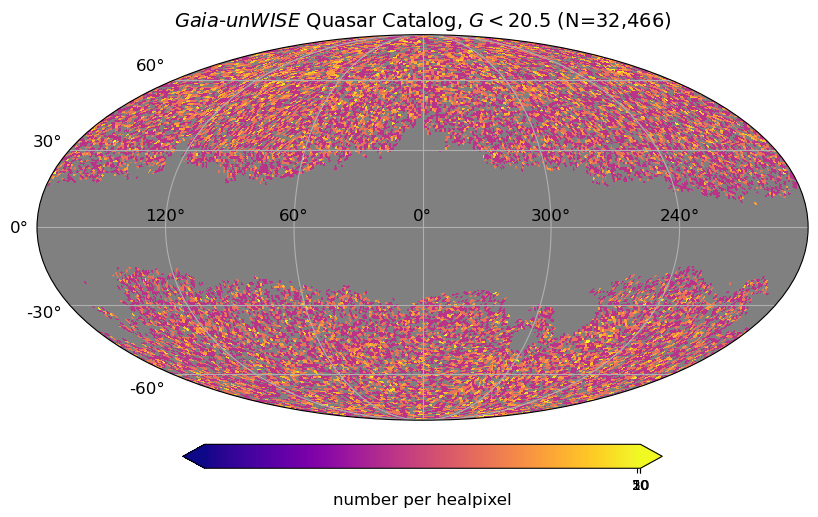

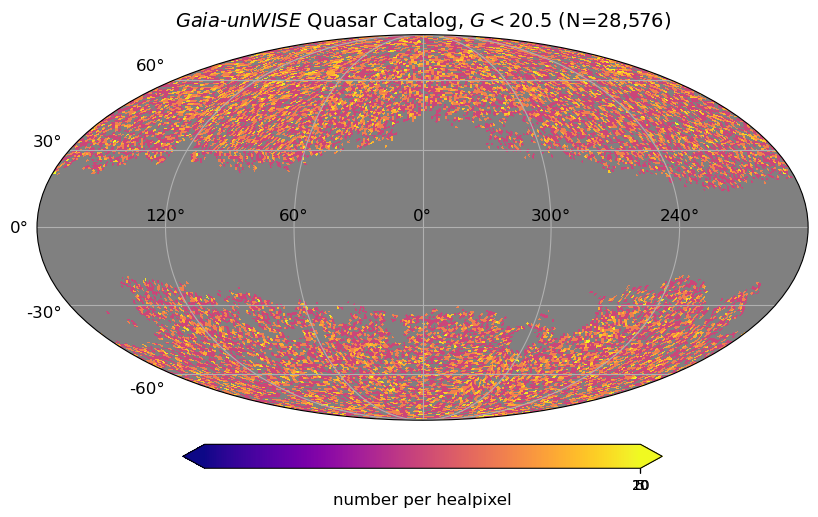

In [71]:
wp_zbin_percentile = {'Planck': [], 'Quaia': []}
rpavg_zbin_percentile = {'Planck': [], 'Quaia': []}
cosmos = ['Planck', 'Quaia']
masks = [0, 0.1, 0.2, 0.3, 0.4, 0.5]
for cosmo in cosmos:

    for j in z_array:
    
        wp_zbin_percentile[cosmo].append([])
        rpavg_zbin_percentile[cosmo].append([])
        
        for cp in masks:
    
            tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                             bins = [zbin_array], tab_gcat_type = 'data',
                                                                                             method = ['minmax'], fac_rand = 25,
                                                                                             n_bins = [None], mask = cp*100, percentile = True)
            
            if j == 3:
                
                N_gcatlo_mask = len(tab_datahi_mask_zbin0)
                pixel_indices_datahi_bin0 = hp.ang2pix(NSIDE, tab_datahi_mask_zbin0['ra'], tab_datahi_mask_zbin0['dec'], lonlat=True)
                map_gcatlo = np.bincount(pixel_indices_datahi_bin0, minlength=NPIX)
                print(np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), np.mean(map_gcatlo)+fac_stdev*np.std(map_gcatlo))
                title_gcatlo = rf"{name_catalog}, $G<{G_hi}$ (N={N_gcatlo_mask:,})"
                projview(map_gcatlo*hp.pixelfunc.nside2pixarea(NSIDE, degrees = True), title=title_gcatlo,
                            unit=r"number per healpixel", cmap=cmap_map, coord=['C','G'],
                            min=np.mean(map_gcatlo)-fac_stdev*np.std(map_gcatlo), max=np.mean(map_gcatlo)+10*fac_stdev*np.std(map_gcatlo), 
                        norm='log', graticule=True, cbar_ticks=cbar_ticks, graticule_labels=True)
    
            wp_zbin_i, rpavg_zbin_i, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Om0[cosmo], 
                                                          h = Planck18.h, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
            wp_zbin_percentile[cosmo][j].append(wp_zbin_i)
            rpavg_zbin_percentile[cosmo][j].append(rpavg_zbin_i)

In [74]:
cmap_grey = plt.get_cmap('Greys')(np.linspace(0.333, 0.999, len(masks)))

<>:44: SyntaxWarning: invalid escape sequence '\l'
<>:63: SyntaxWarning: invalid escape sequence '\m'
<>:44: SyntaxWarning: invalid escape sequence '\l'
<>:63: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_229425/3718235191.py:44: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))
/tmp/ipykernel_229425/3718235191.py:63: SyntaxWarning: invalid escape sequence '\m'
  second_legend = ax1.legend(custom_lines, ['${:.0f}^\mathrm{{th}}$ percentile'.format(cp*100) for cp in masks], bbox_to_anchor = bbox_to_anchor[1], loc='upper center')


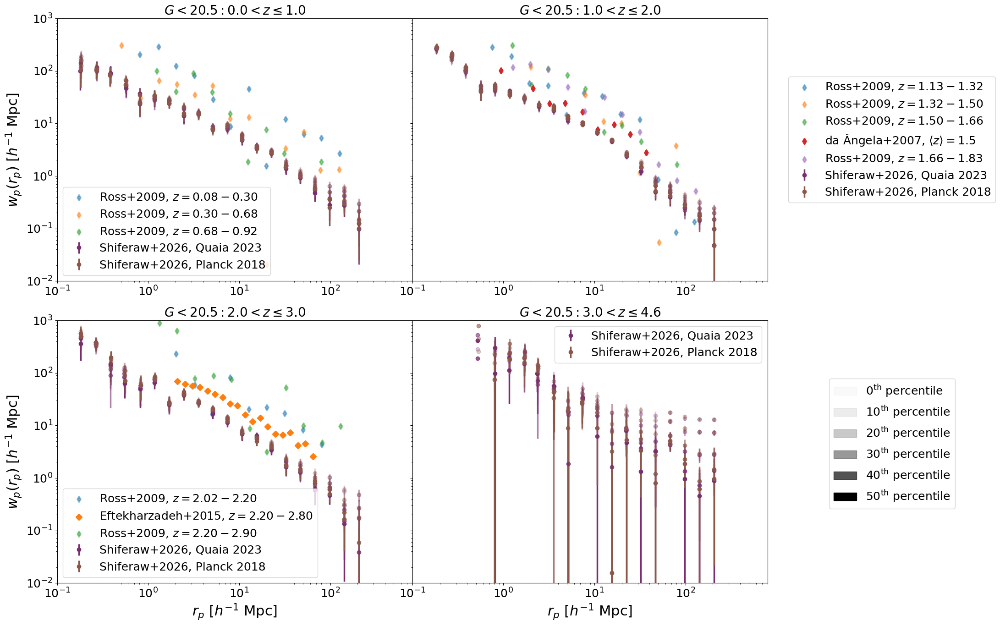

In [73]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.15, wspace = 0)
bbox_to_anchor = [(-0.45, 0.7),(1.35, 0.8), (0, 0), (0, 0)]
cosmos = ['Planck', 'Quaia']

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])
              
    for cosmo, color, year in zip(cosmos[::-1], [cmap_rocket[0], color_planck], [2023, 2018]):
        
        C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_zmin{:.1f}zmax{:.1f}_N25_{}_MC_mask.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, zbin_array[j], zbin_array[j+1], 'Planck'))

        for i, cp in enumerate(masks):
            # i=1
            # cp=0.1
            if cp ==0.5:
                ax1.errorbar(rpavg_zbin_percentile[cosmo][j][i], wp_zbin_percentile[cosmo][j][i], linewidth = 2.5, marker = 'o', 
                             label = r'Shiferaw+2026, {} {}'.format(cosmo, year), color = color, yerr = np.sqrt(np.diag(C)), linestyle = 'none', alpha = np.max((cp/0.5, 0.1)))
            else:
                ax1.errorbar(rpavg_zbin_percentile[cosmo][j][i], wp_zbin_percentile[cosmo][j][i], linewidth = 2.5, marker = 'o', 
                             color = color, yerr = np.sqrt(np.diag(C)), linestyle = 'none', alpha = np.max((cp/0.5, 0.1)))
    if j == 0:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.08-0.30$', alpha = 0.5)
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.30-0.68$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.68-0.92$', alpha = 0.5)
        ax1.legend()
    elif j == 1:
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.13-1.32$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.32-1.50$', alpha = 0.5)
        ax1.scatter(ross[j][3][0], ross[j][3][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.50-1.66$', alpha = 0.5)
        ax1.scatter(da_angela[0], da_angela[1], linewidth = 2.5, marker = 'd', label = r'da Ângela+2007, $\langle z\rangle=1.5$')
        ax1.scatter(ross[j][4][0], ross[j][4][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.66-1.83$', alpha = 0.5)
        ax1.legend(bbox_to_anchor = bbox_to_anchor[j], loc='upper center')
    elif j == 2:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.02-2.20$', alpha = 0.5)
        ax1.scatter(eftekharzadeh[:,0], eftekharzadeh[:,1], linewidth = 2.5, marker = 'D', label = r'Eftekharzadeh+2015, $z = 2.20-2.80$')
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.20-2.90$', alpha = 0.5)
        ax1.legend()
    # else:
    #     ax1.legend()

    ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(1e-1, 8e2)
    ax1.set_ylim(1e-2, 1e3)


    if (j) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if scale == 'log':
        ax1.set_xscale('log')

    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected

custom_lines = [mpatches.Patch(color = cmap_grey[i], alpha = np.max((cp/0.5, 0.1))) for i, cp in enumerate(masks)]
second_legend = ax1.legend(custom_lines, ['${:.0f}^\mathrm{{th}}$ percentile'.format(cp*100) for cp in masks], bbox_to_anchor = bbox_to_anchor[1], loc='upper center')
fig.add_artist(second_legend)
ax1.legend()

plt.show()

In [88]:
wp_zbin_percentile = {'Planck': [], 'Quaia': []}
rpavg_zbin_percentile = {'Planck': [], 'Quaia': []}
cosmos = ['Planck', 'Quaia']

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _= quaia.make_bins_raw(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask)
    
    for cosmo in cosmos:

        wp_zbin_i, rpavg_zbin_i, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Om0[cosmo], 
                                                      h = Planck18.h, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
        wp_zbin_percentile[cosmo].append(wp_zbin_i)
        rpavg_zbin_percentile[cosmo].append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0: 0.37              179640 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin3.0zmax4.0: 0.46              19252 vs 35630


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


<>:37: SyntaxWarning: invalid escape sequence '\l'
<>:37: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_229425/1913579663.py:37: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))


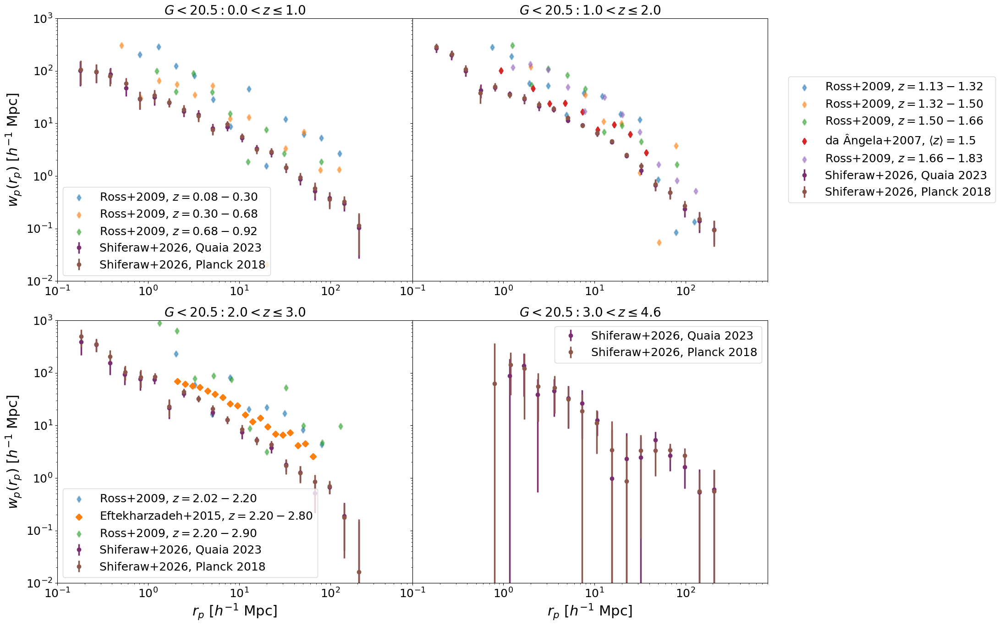

In [89]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.15, wspace = 0)
bbox_to_anchor = [(-0.45, 0.7),(1.35, 0.8), (0, 0), (0, 0)]
cosmos = ['Planck', 'Quaia']

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])
              
    for cosmo, color, year in zip(cosmos[::-1], [cmap_rocket[0], color_planck], [2023, 2018]):
        
        C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_z{:.1f}_N25_{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, j, cosmo))
        
        ax1.errorbar(rpavg_zbin_percentile[cosmo][j], wp_zbin_percentile[cosmo][j], linewidth = 2.5, marker = 'o', 
                     label = r'Shiferaw+2026, {} {}'.format(cosmo, year), color = color, yerr = np.sqrt(np.diag(C)), linestyle = 'None')
    if j == 0:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.08-0.30$', alpha = 0.5)
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.30-0.68$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.68-0.92$', alpha = 0.5)
        ax1.legend()
    elif j == 1:
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.13-1.32$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.32-1.50$', alpha = 0.5)
        ax1.scatter(ross[j][3][0], ross[j][3][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.50-1.66$', alpha = 0.5)
        ax1.scatter(da_angela[0], da_angela[1], linewidth = 2.5, marker = 'd', label = r'da Ângela+2007, $\langle z\rangle=1.5$')
        ax1.scatter(ross[j][4][0], ross[j][4][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.66-1.83$', alpha = 0.5)
        ax1.legend(bbox_to_anchor = bbox_to_anchor[j], loc='upper center')
    elif j == 2:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.02-2.20$', alpha = 0.5)
        ax1.scatter(eftekharzadeh[:,0], eftekharzadeh[:,1], linewidth = 2.5, marker = 'D', label = r'Eftekharzadeh+2015, $z = 2.20-2.80$')
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.20-2.90$', alpha = 0.5)
        ax1.legend()
    else:
        ax1.legend()

    ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(1e-1, 8e2)
    ax1.set_ylim(1e-2, 1e3)


    if (j) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if scale == 'log':
        ax1.set_xscale('log')

    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected

plt.show()

In [92]:
importlib.reload(quaia)

<module 'quaia' from '/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia.py'>

In [93]:
wp_zbin_percentile = {'Planck': [], 'Quaia': []}
rpavg_zbin_percentile = {'Planck': [], 'Quaia': []}
cosmos = ['Planck', 'Quaia']

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask, MC = '_')
    
    for cosmo in cosmos:

        wp_zbin_i, rpavg_zbin_i, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Om0[cosmo], 
                                                      h = Planck18.h, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
        wp_zbin_percentile[cosmo].append(wp_zbin_i)
        rpavg_zbin_percentile[cosmo].append(rpavg_zbin_i)

Pixels masked by MC but not already by selfunc: 0
G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


Pixels masked by MC but not already by selfunc: 0
G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


Pixels masked by MC but not already by selfunc: 0
G20.5_zmin2.0zmax3.0: 0.37              179640 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


Pixels masked by MC but not already by selfunc: 0
G20.5_zmin3.0zmax4.0: 0.46              19252 vs 35630


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


<>:37: SyntaxWarning: invalid escape sequence '\l'
<>:37: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_229425/4015452177.py:37: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))


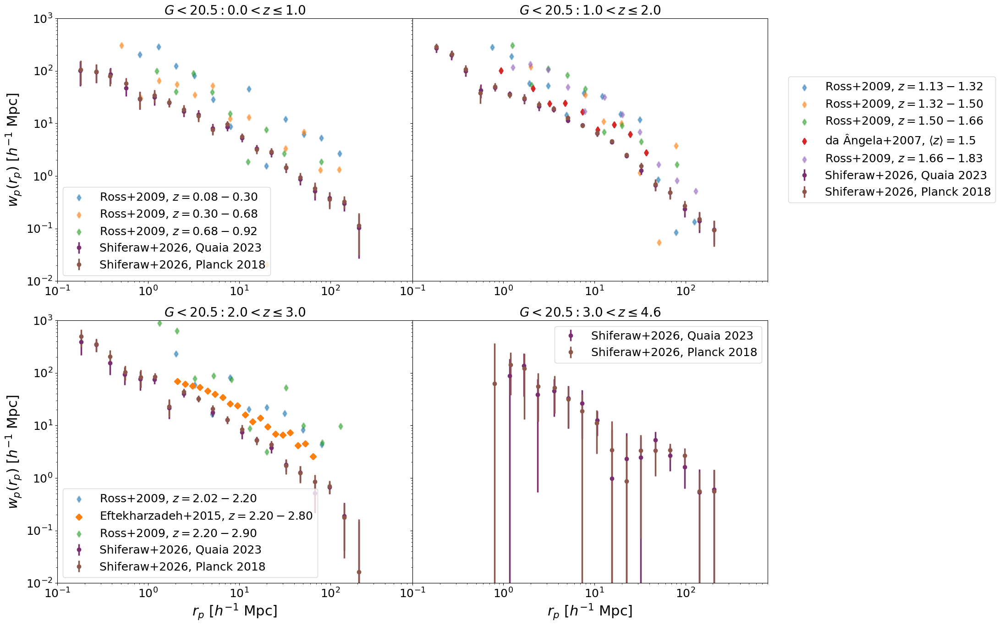

In [94]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, hspace = 0.15, wspace = 0)
bbox_to_anchor = [(-0.45, 0.7),(1.35, 0.8), (0, 0), (0, 0)]
cosmos = ['Planck', 'Quaia']

k = 0
for j in z_array:

    ax1 = fig.add_subplot(gs[j])
              
    for cosmo, color, year in zip(cosmos[::-1], [cmap_rocket[0], color_planck], [2023, 2018]):
        
        C = np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_z{:.1f}_N25_{}.npy'.format(G_hi, rpmin, rpmax, nbins, pimax, j, cosmo))
        
        ax1.errorbar(rpavg_zbin_percentile[cosmo][j], wp_zbin_percentile[cosmo][j], linewidth = 2.5, marker = 'o', 
                     label = r'Shiferaw+2026, {} {}'.format(cosmo, year), color = color, yerr = np.sqrt(np.diag(C)), linestyle = 'None')
    if j == 0:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.08-0.30$', alpha = 0.5)
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.30-0.68$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 0.68-0.92$', alpha = 0.5)
        ax1.legend()
    elif j == 1:
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.13-1.32$', alpha = 0.5)
        ax1.scatter(ross[j][2][0], ross[j][2][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.32-1.50$', alpha = 0.5)
        ax1.scatter(ross[j][3][0], ross[j][3][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.50-1.66$', alpha = 0.5)
        ax1.scatter(da_angela[0], da_angela[1], linewidth = 2.5, marker = 'd', label = r'da Ângela+2007, $\langle z\rangle=1.5$')
        ax1.scatter(ross[j][4][0], ross[j][4][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 1.66-1.83$', alpha = 0.5)
        ax1.legend(bbox_to_anchor = bbox_to_anchor[j], loc='upper center')
    elif j == 2:
        ax1.scatter(ross[j][0][0], ross[j][0][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.02-2.20$', alpha = 0.5)
        ax1.scatter(eftekharzadeh[:,0], eftekharzadeh[:,1], linewidth = 2.5, marker = 'D', label = r'Eftekharzadeh+2015, $z = 2.20-2.80$')
        ax1.scatter(ross[j][1][0], ross[j][1][1], linewidth = 2.5, marker = 'd', label = r'Ross+2009, $z = 2.20-2.90$', alpha = 0.5)
        ax1.legend()
    else:
        ax1.legend()

    ax1.set_title('$G<{}: {:.1f}<z \leq{:.1f}$'.format(G_hi, zbin_array[j], zbin_array[j+1]))
    ax1.set_yscale('log')
    ax1.set_xlim(1e-1, 8e2)
    ax1.set_ylim(1e-2, 1e3)

    if (j) % 2 == 0:
        ax1.set_ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

    else:
        ax1.set_yticklabels([])

    if scale == 'log':
        ax1.set_xscale('log')

    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected

plt.show()

## Try other direction for little h

In [24]:
importlib.reload(quaia_debug)

<module 'quaia_debug' from '/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia_debug.py'>

In [25]:
wp_debug = []
rpavg_debug = []
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask)
    wp_zbin_i, rpavg_zbin_i, qq, qr = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Omega_m_planck20, 
                                                        h = h_planck20,nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, 
                                                        error = True, units = 'Mpc*h')
    wp_debug.append(wp_zbin_i)
    rpavg_debug.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0: 0.37              179640 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin3.0zmax4.0: 0.46              19252 vs 35630


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia_debug.py:804: RuntimeWarning: invalid value encountered in scalar divide
  # calculate the x axis


<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_249079/4095799671.py:24: SyntaxWarning: invalid escape sequence '\l'
  second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')


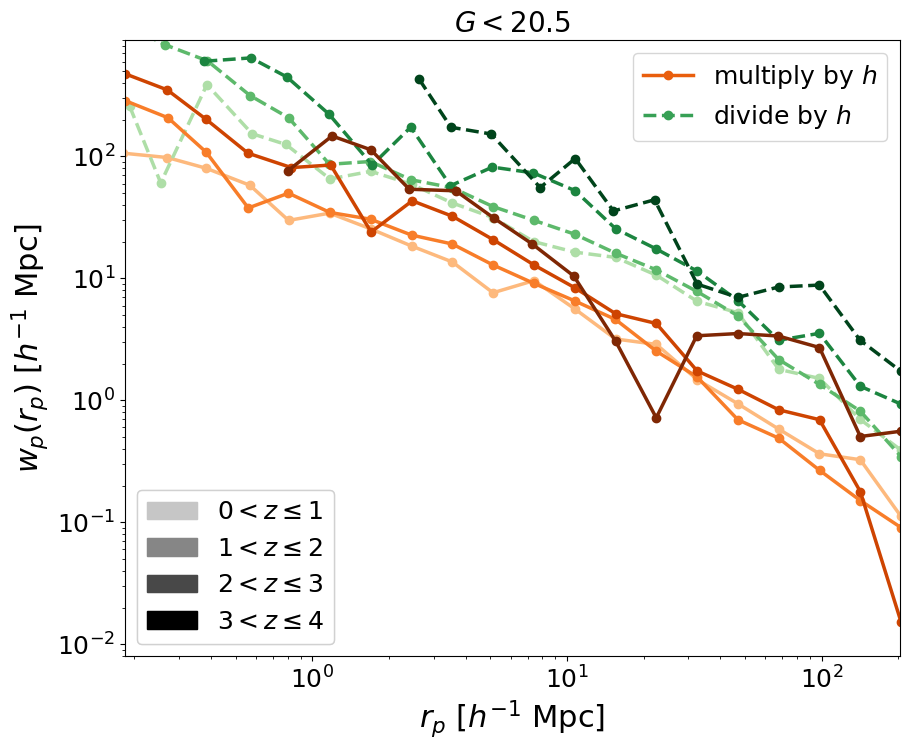

In [34]:
fig = plt.figure(figsize = (10, 8))
labels_cf = [r'multiply by $h$', 'divide by $h$']

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = r'*h', 
                 color = cmap_qq[j])
    plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = r'/h', linestyle = '--',
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

In [23]:
"""
Diagnostic script to check comoving distance units between
Mahlet's implementation and Giner Mascarelli's implementation.
"""

import numpy as np
from astropy.cosmology import Planck18, FlatLambdaCDM
import astropy.units as u
from astropy.cosmology import units as cu

# Test redshifts spanning the range of interest
z_test = np.array([0.5, 1.0, 2.0, 3.0, 3.5, 4.0])

print("=" * 70)
print("Comoving Distance Comparison: Mahlet vs Giner Mascarelli")
print("=" * 70)

# --- Giner Mascarelli's method (notebook1.py line 122) ---
# Uses Planck18 and divides by h
cz_giner = Planck18.comoving_distance(z_test).value / Planck18.h
print(f"\nGiner Mascarelli's method:")
print(f"  Planck18.comoving_distance(z).value / Planck18.h")
print(f"  Planck18.h = {Planck18.h}")

# --- Mahlet's method (quaia.py lines 143-151) ---
def comoving_dist_mahlet(z, h=0.6844, Om0=0.302):
    """Mahlet's comoving_dist function from quaia.py"""
    H0 = h * 100 * u.km / u.s / u.Mpc
    cosmo = FlatLambdaCDM(H0=H0, Om0=Om0)
    comoving_r = cosmo.comoving_distance(z)
    # This is what the code does:
    result = (comoving_r * cu.littleh).to(u.Mpc, cu.with_H0(H0)) / cu.littleh
    return result.value

cz_mahlet = comoving_dist_mahlet(z_test)
print(f"\nMahlet's method:")
print(f"  FlatLambdaCDM(H0={0.6844*100}, Om0=0.302)")
print(f"  (comoving_r * littleh).to(Mpc, with_H0) / littleh")

# --- What it SHOULD be for Mpc/h units ---
# To convert Mpc to Mpc/h (i.e., h^{-1} Mpc), divide by h
def correct_mpc_over_h(z, h=0.6844, Om0=0.302):
    """Correct conversion to Mpc/h"""
    H0 = h * 100 * u.km / u.s / u.Mpc
    cosmo = FlatLambdaCDM(H0=H0, Om0=Om0)
    comoving_r = cosmo.comoving_distance(z).value  # Mpc
    return comoving_r / h  # Mpc/h

cz_correct = correct_mpc_over_h(z_test)

# --- Print comparison table ---
print("\n" + "-" * 70)
print(f"{'z':>6} | {'Giner (Mpc/h)':>14} | {'Mahlet':>14} | {'Correct (Mpc/h)':>14} | {'Mahlet/Correct':>14}")
print("-" * 70)
for i, z in enumerate(z_test):
    ratio = cz_mahlet[i] / cz_correct[i]
    print(f"{z:6.1f} | {cz_giner[i]:14.2f} | {cz_mahlet[i]:14.2f} | {cz_correct[i]:14.2f} | {ratio:14.4f}")

print("-" * 70)

# Check the ratio
ratio_mahlet_correct = cz_mahlet / cz_correct
print(f"\nMahlet / Correct ratio: {ratio_mahlet_correct[0]:.6f}")
print(f"This equals h^2 = {0.6844**2:.6f}" if np.isclose(ratio_mahlet_correct[0], 0.6844**2, rtol=0.01) else "")
print(f"This equals h = {0.6844:.6f}" if np.isclose(ratio_mahlet_correct[0], 0.6844, rtol=0.01) else "")

# --- Detailed breakdown of Mahlet's calculation ---
print("\n" + "=" * 70)
print("Detailed breakdown of Mahlet's calculation at z=3.0:")
print("=" * 70)

z_example = 3.0
h = 0.6844
Om0 = 0.302
H0 = h * 100 * u.km / u.s / u.Mpc
cosmo = FlatLambdaCDM(H0=H0, Om0=Om0)

comoving_r = cosmo.comoving_distance(z_example)
print(f"1. comoving_r = cosmo.comoving_distance({z_example}) = {comoving_r}")
print(f"   comoving_r.value = {comoving_r.value:.2f} Mpc")

step2 = comoving_r * cu.littleh
print(f"\n2. comoving_r * cu.littleh = {step2}")

step3 = step2.to(u.Mpc, cu.with_H0(H0))
print(f"\n3. .to(u.Mpc, cu.with_H0(H0)) = {step3}")
print(f"   step3.value = {step3.value:.2f}")

step4 = step3 / cu.littleh
print(f"\n4. / cu.littleh = {step4}")
print(f"   Final value = {step4.value:.2f}")

print(f"\nExpected for Mpc/h: {comoving_r.value / h:.2f}")
print(f"Ratio (Mahlet / Expected): {step4.value / (comoving_r.value / h):.6f}")

# --- Impact on wp(rp) ---
print("\n" + "=" * 70)
print("Impact on wp(rp):")
print("=" * 70)
ratio = cz_mahlet[0] / cz_correct[0]
print(f"If comoving distances are off by a factor of {ratio:.4f},")
print(f"then rp values would be scaled by {ratio:.4f},")
print(f"and wp(rp) = 2 * integral(xi * dpi) would be scaled by ~{ratio:.4f}")
print(f"\nThis could explain amplitude differences but not necessarily the noise.")

Comoving Distance Comparison: Mahlet vs Giner Mascarelli

Giner Mascarelli's method:
  Planck18.comoving_distance(z).value / Planck18.h
  Planck18.h = 0.6766

Mahlet's method:
  FlatLambdaCDM(H0=68.44, Om0=0.302)
  (comoving_r * littleh).to(Mpc, with_H0) / littleh

----------------------------------------------------------------------
     z |  Giner (Mpc/h) |         Mahlet | Correct (Mpc/h) | Mahlet/Correct
----------------------------------------------------------------------
   0.5 |        2876.76 |        1321.12 |        2820.48 |         0.4684
   1.0 |        5018.67 |        2309.94 |        4931.52 |         0.4684
   2.0 |        7845.39 |        3619.70 |        7727.74 |         0.4684
   3.0 |        9612.78 |        4440.26 |        9479.57 |         0.4684
   3.5 |       10274.34 |        4747.61 |       10135.72 |         0.4684
   4.0 |       10836.25 |        5008.72 |       10693.17 |         0.4684
------------------------------------------------------------------

## Debugged version

In [ ]:
wp_debug = []
rpavg_debug = []
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask)
    wp_zbin_i, rpavg_zbin_i, qq, qr = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Omega_m_planck20, h = h_planck20,
                                                      nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
    wp_debug.append(wp_zbin_i)
    rpavg_debug.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


## Check if comoving_dist() is the issue
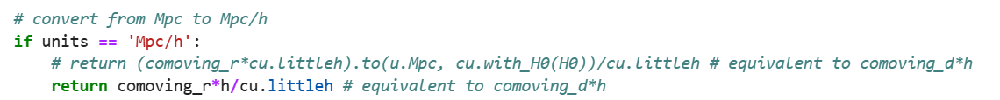

In [ ]:
fig = plt.figure(figsize = (10, 8))
# gs = gridspec.GridSpec(2, 2, height_ratios = [1, 0.5], hspace = 0, wspace = 0)

labels_cf = ['Original', 'Debugged']
# for i in range(len(Omega_m_array)):
    
#     ax1 = fig.add_subplot(gs[i])
#     ax2 = fig.add_subplot(gs[i+2])

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = r'Original', 
                 color = cmap_qq[j])
    plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = r'Debugged', linestyle = '--',
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])
# plt.legend()

custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

In [18]:
(quaia.comoving_dist(1, h = h_planck20, Om0 = Omega_m_planck20)).to(u.Mpc, cu.with_H0(H0_planck20))

<Quantity 3401.26291735 Mpc>

In [19]:
quaia_debug.comoving_dist(1, h = h_planck20, Om0 = Omega_m_planck20, Ob0 = cosmo_planck20['Omega_b'], units = 'Mpc')

<Quantity 3401.26291735 Mpc>

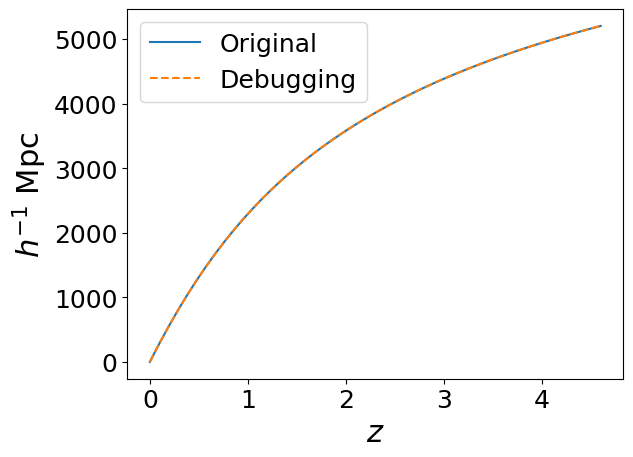

In [20]:
z = np.linspace(0, 4.6)
plt.plot(z, quaia.comoving_dist(z, h = h_planck20, Om0 = Omega_m_planck20), label = 'Original')
plt.plot(z, quaia_debug.comoving_dist(z, h = h_planck20, Om0 = Omega_m_planck20), linestyle = '--', label = 'Debugging')
plt.ylabel('$h^{-1}$ Mpc')
plt.xlabel('$z$')
plt.legend()
plt.show()

## Check weights
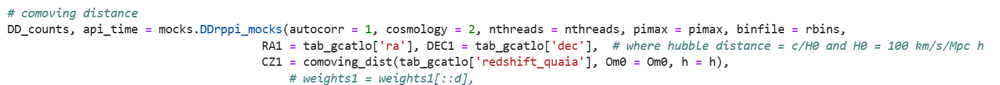

In [18]:
wp_debug = []
rpavg_debug = []
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask)
    wp_zbin_i, rpavg_zbin_i = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Omega_m_planck20, 
                                                        h = h_planck20, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax)
    wp_debug.append(wp_zbin_i)
    rpavg_debug.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0: 0.37              179640 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin3.0zmax4.0: 0.46              19252 vs 35630


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_3762/196821740.py:24: SyntaxWarning: invalid escape sequence '\l'
  second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')


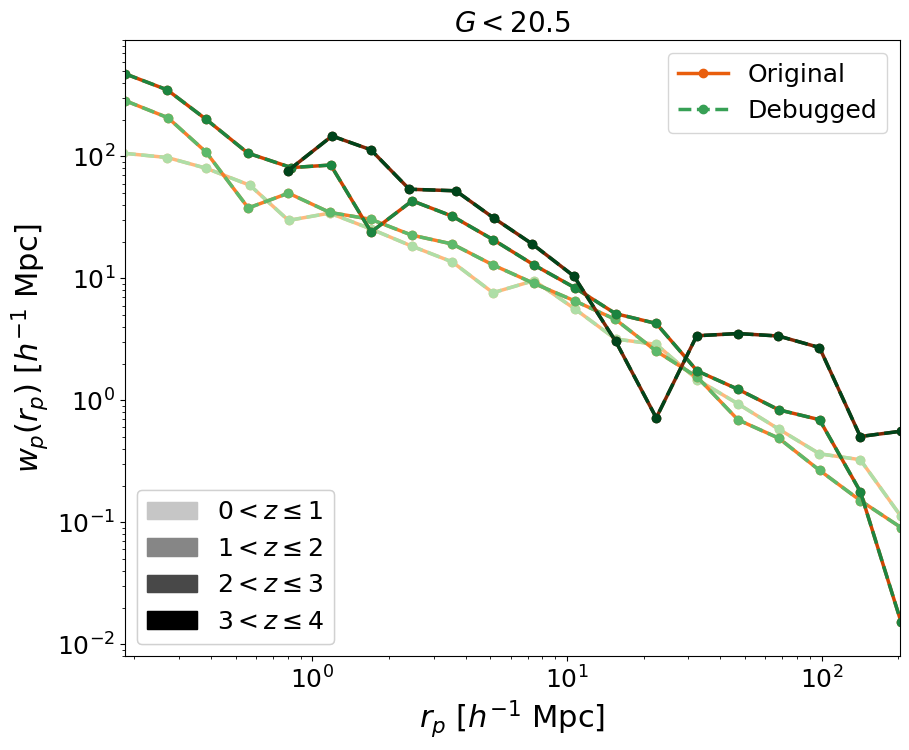

In [20]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['Original', 'Debugged']

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = r'Original', 
                 color = cmap_qq[j])
    plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = r'Debugged', linestyle = '--',
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

## Check RR counts
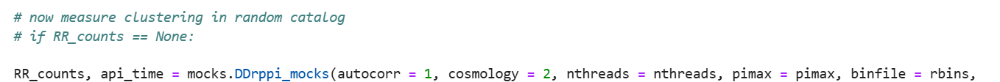

In [22]:
wp_debug = []
rpavg_debug = []
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask)
    wp_zbin_i, rpavg_zbin_i = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Omega_m_planck20, 
                                                        h = h_planck20, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax)
    wp_debug.append(wp_zbin_i)
    rpavg_debug.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0: 0.37              179640 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin3.0zmax4.0: 0.46              19252 vs 35630


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_3762/196821740.py:24: SyntaxWarning: invalid escape sequence '\l'
  second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')


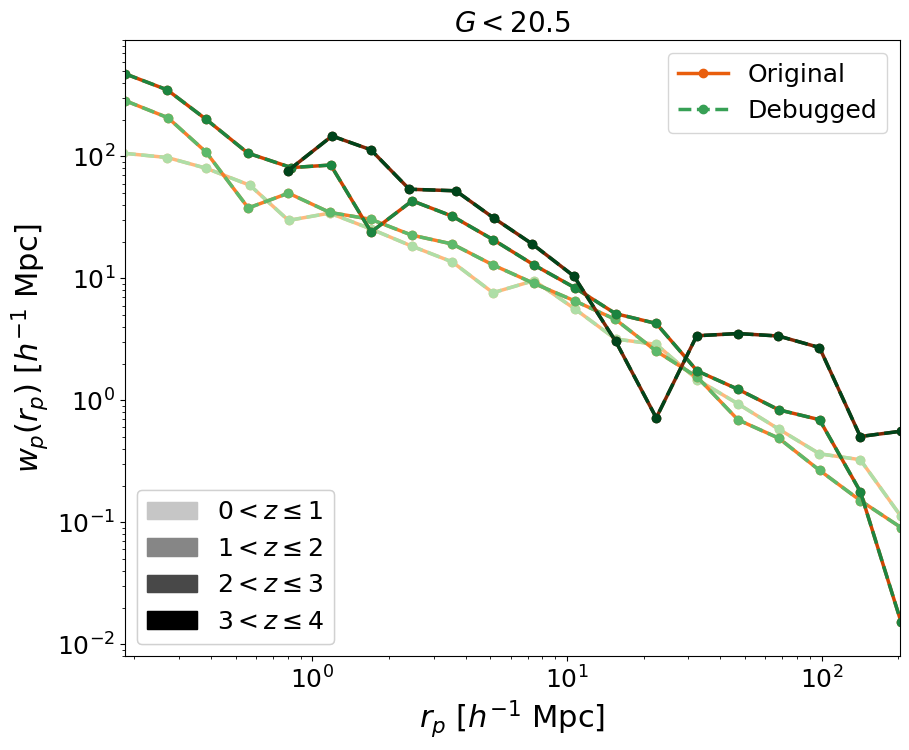

In [32]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['Original', 'Debugged']

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = r'Original', 
                 color = cmap_qq[j])
    plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = r'Debugged', linestyle = '--',
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

## Check ::d
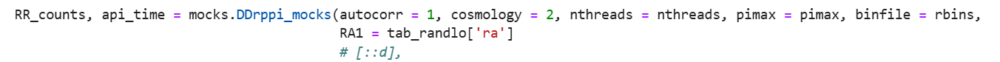

In [47]:
wp_debug = []
rpavg_debug = []
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia_debug.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask)
    wp_zbin_i, rpavg_zbin_i = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Omega_m_planck20, 
                                                        h = h_planck20, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax)
    wp_debug.append(wp_zbin_i)
    rpavg_debug.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0: 0.37              179640 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin3.0zmax4.0: 0.46              19252 vs 35630


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_3762/196821740.py:24: SyntaxWarning: invalid escape sequence '\l'
  second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')


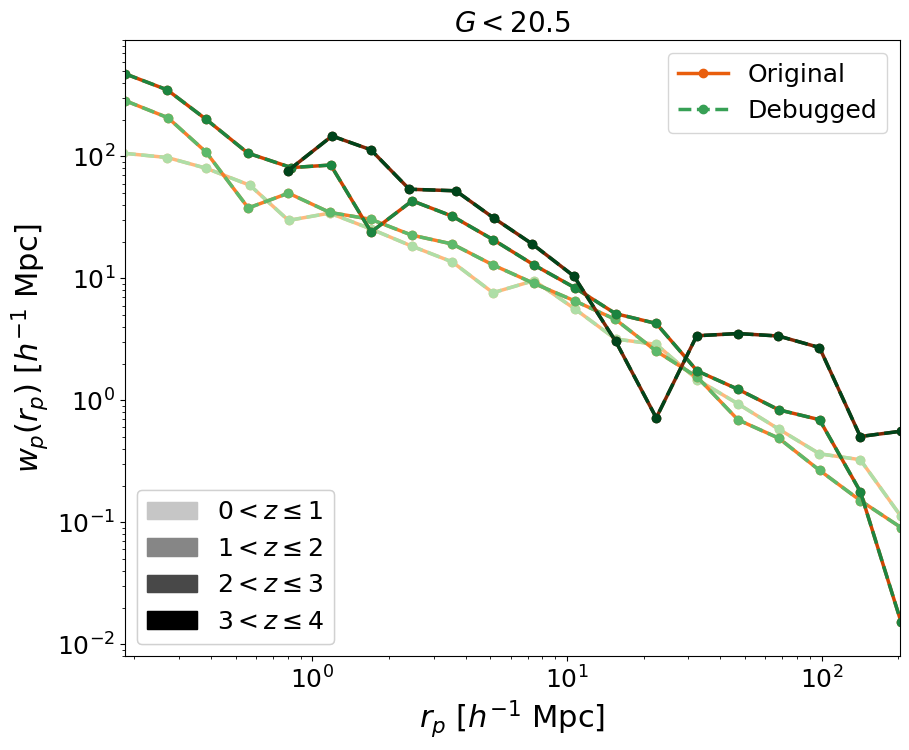

In [48]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['Original', 'Debugged']

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = r'Original', 
                 color = cmap_qq[j])
    plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = r'Debugged', linestyle = '--',
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

## Check z distribution

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


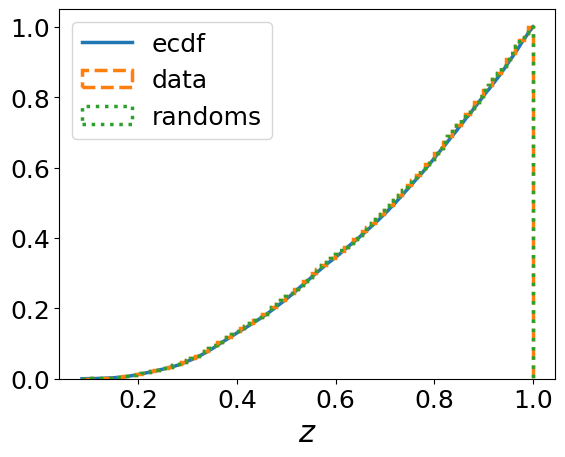

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


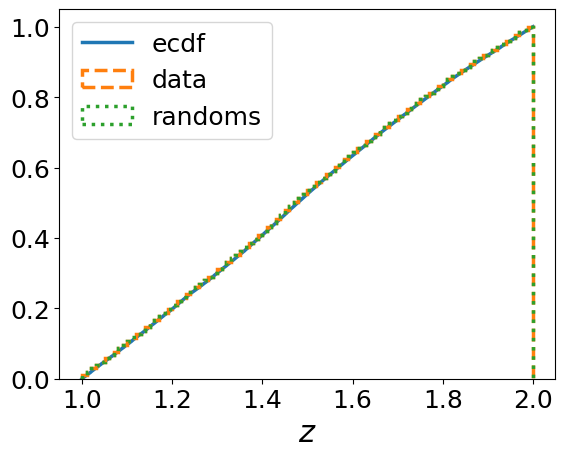

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0: 0.37              179640 vs 286508


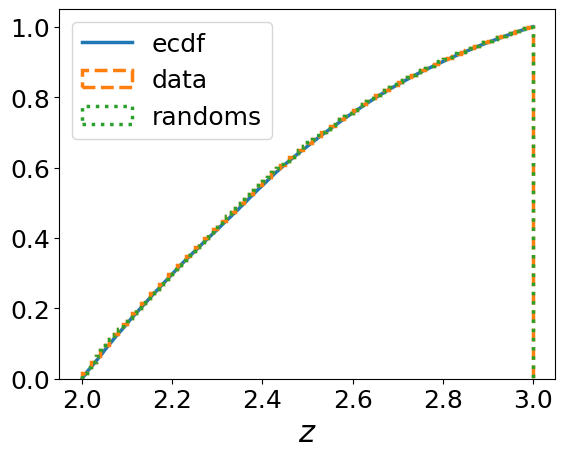

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin3.0zmax4.0: 0.46              19252 vs 35630


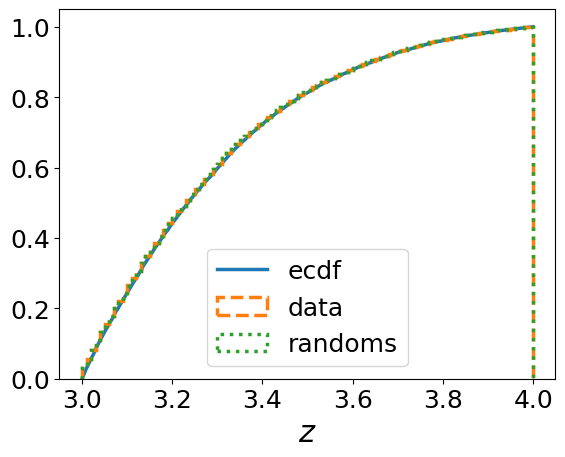

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


In [70]:
wp_debug = []
rpavg_debug = []
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia_debug.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask, plot = True)
    wp_zbin_i, rpavg_zbin_i = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Omega_m_planck20, 
                                                        h = h_planck20, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax)
    wp_debug.append(wp_zbin_i)
    rpavg_debug.append(rpavg_zbin_i)

<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_3762/196821740.py:24: SyntaxWarning: invalid escape sequence '\l'
  second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')


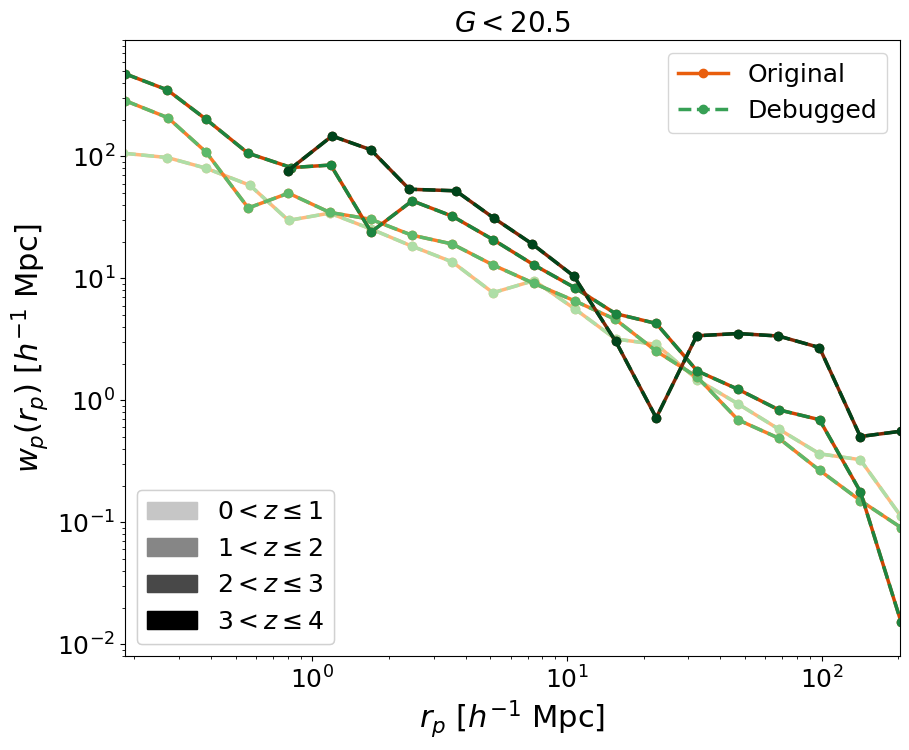

In [71]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['Original', 'Debugged']

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = r'Original', 
                 color = cmap_qq[j])
    plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = r'Debugged', linestyle = '--',
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

## Check the mask

G20.5_zmin0.0zmax1.0: 0.30              225792 vs 324336


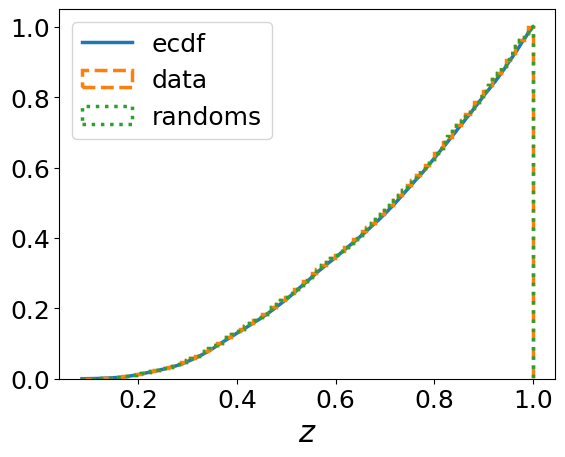

G20.5_zmin1.0zmax2.0: 0.28              467913 vs 648196


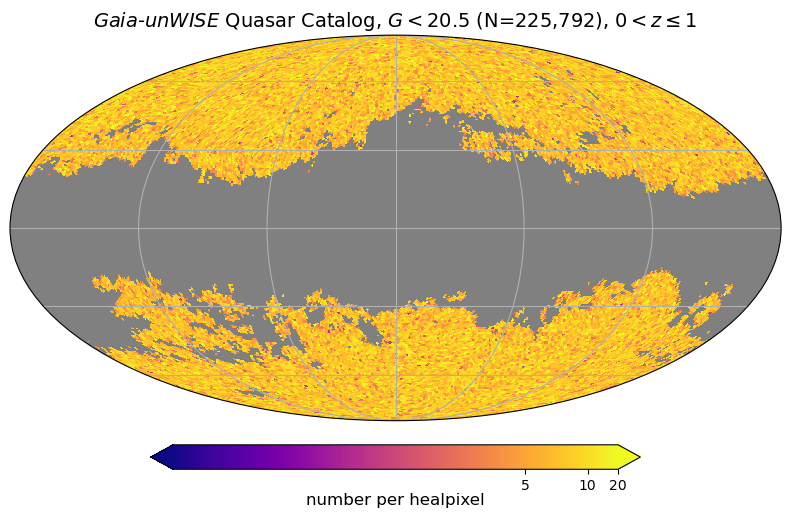

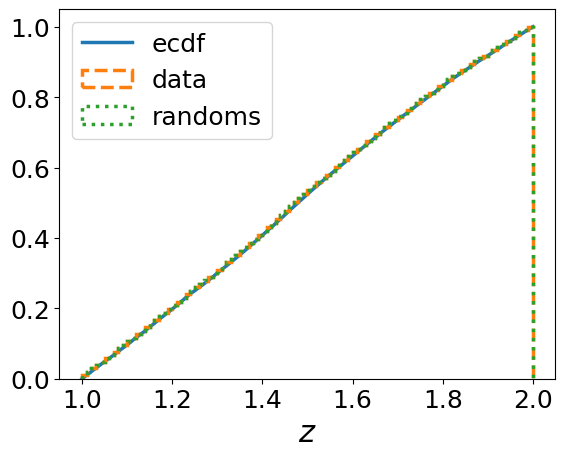

G20.5_zmin2.0zmax3.0: 0.24              216828 vs 286508


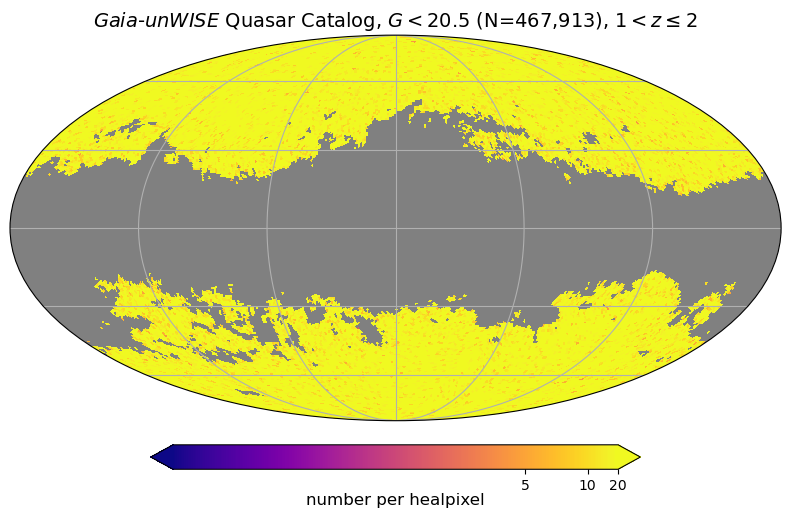

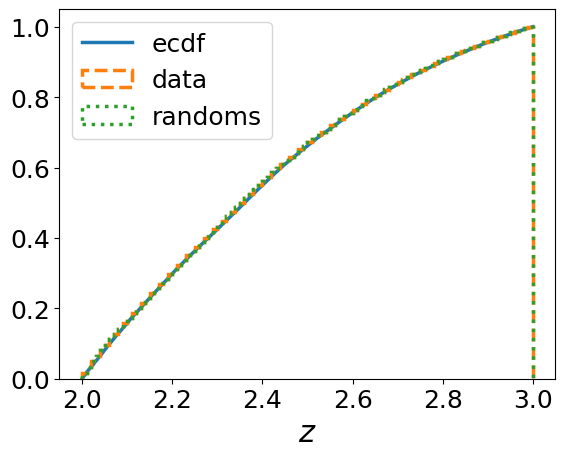

G20.5_zmin3.0zmax4.0: 0.21              28061 vs 35630


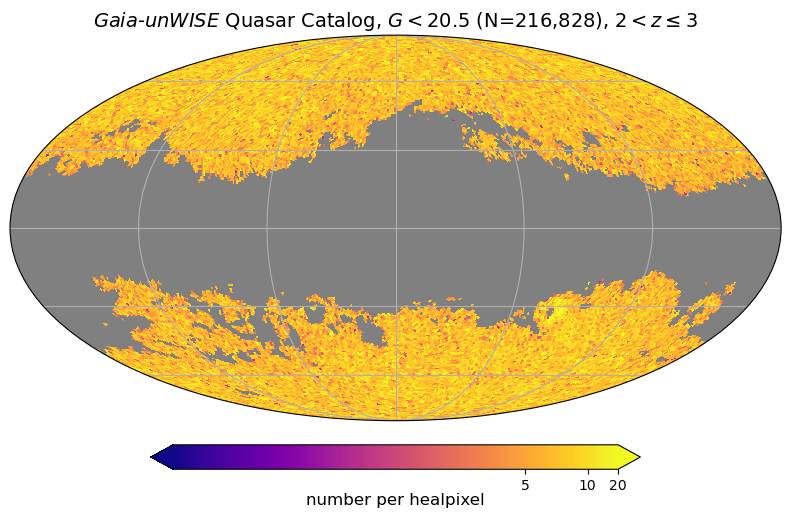

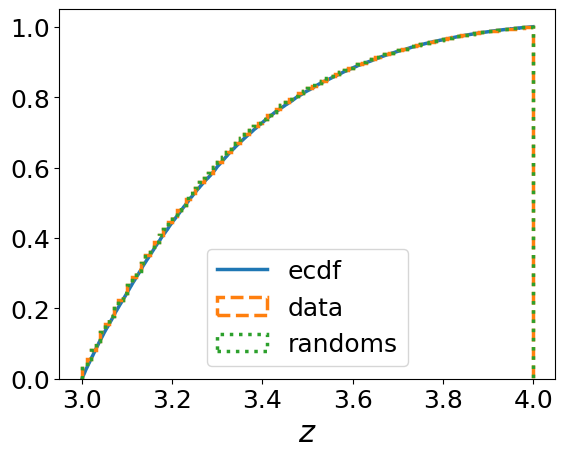

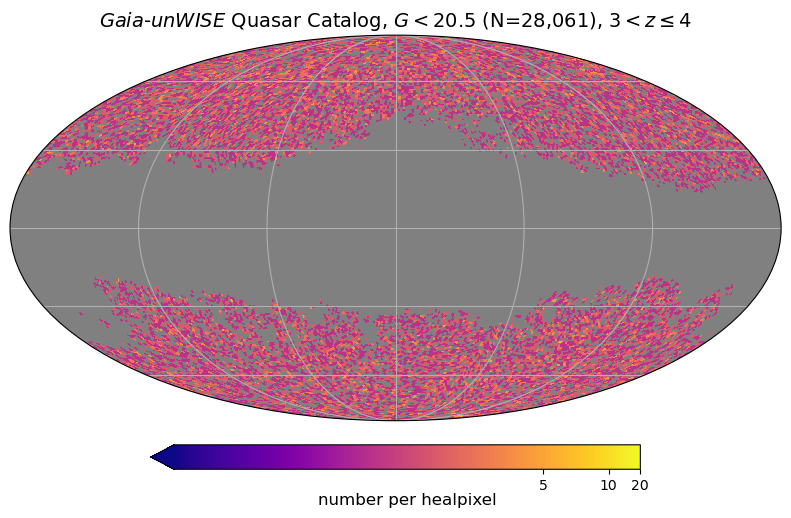

In [36]:
for j in z_array:

    #, fac_stdev = [1, 1, 0.9, 0.5][j])
    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask = mask*100, 
                                                                                               plot = True, percentile = True) 

G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336


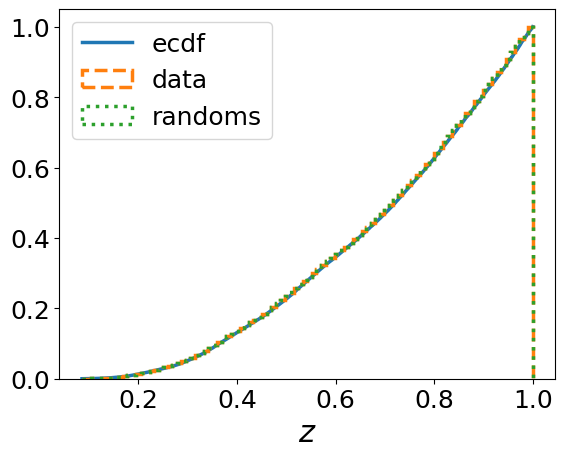

G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196


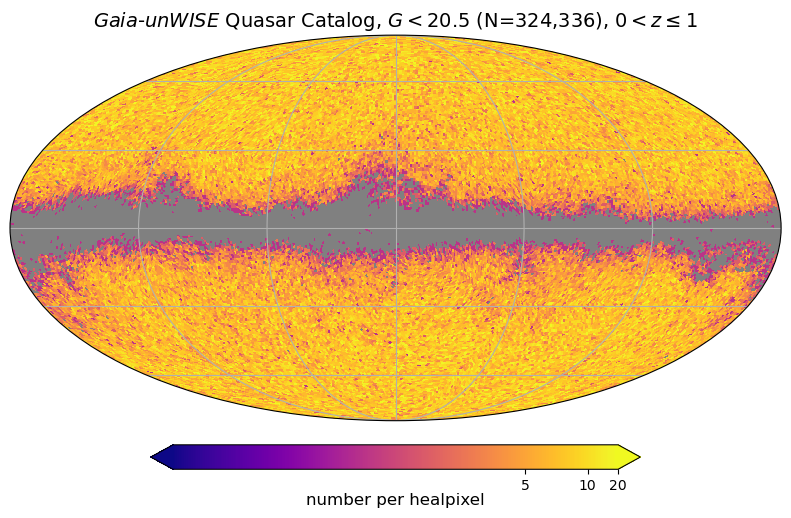

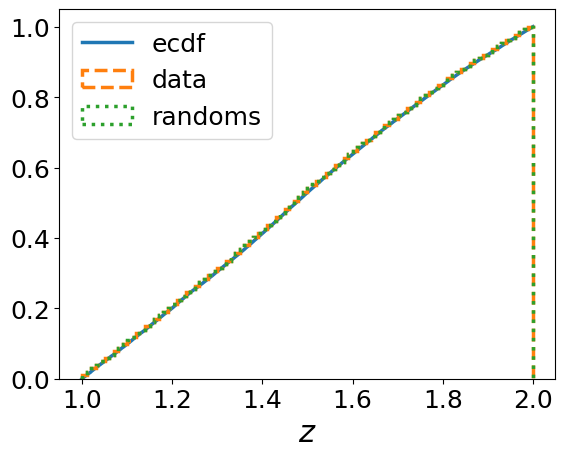

G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508


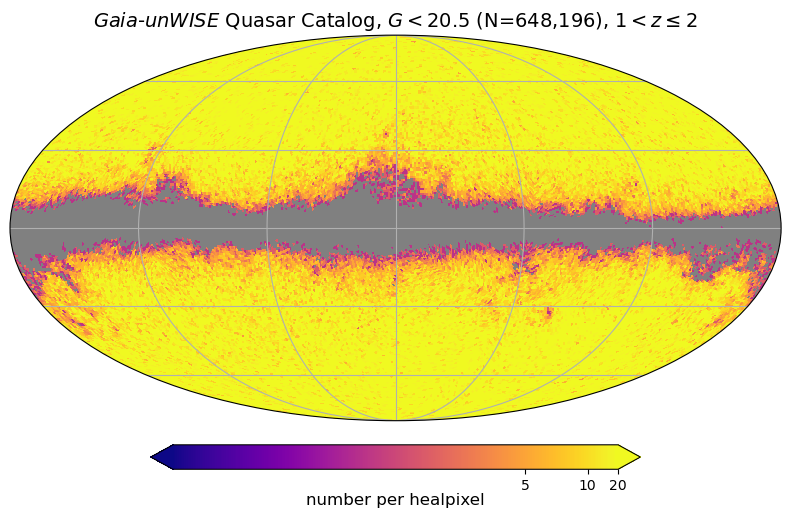

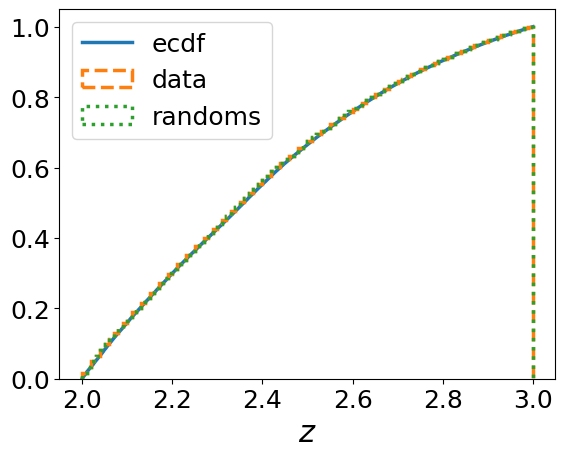

G20.5_zmin3.0zmax4.0: 0.23              27584 vs 35630


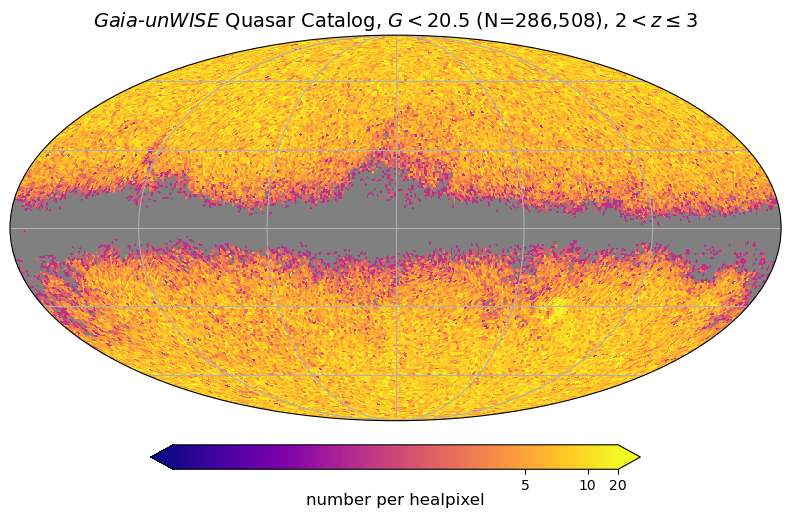

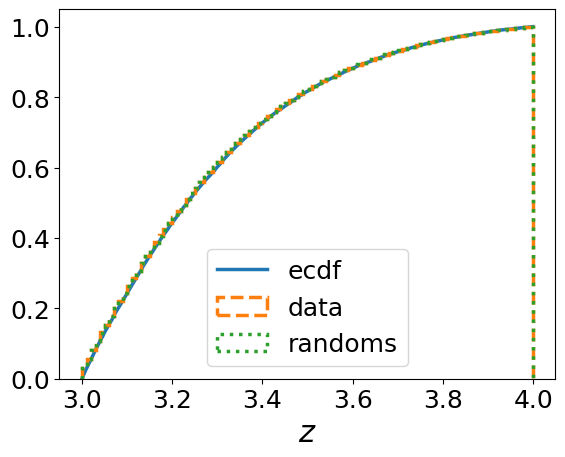

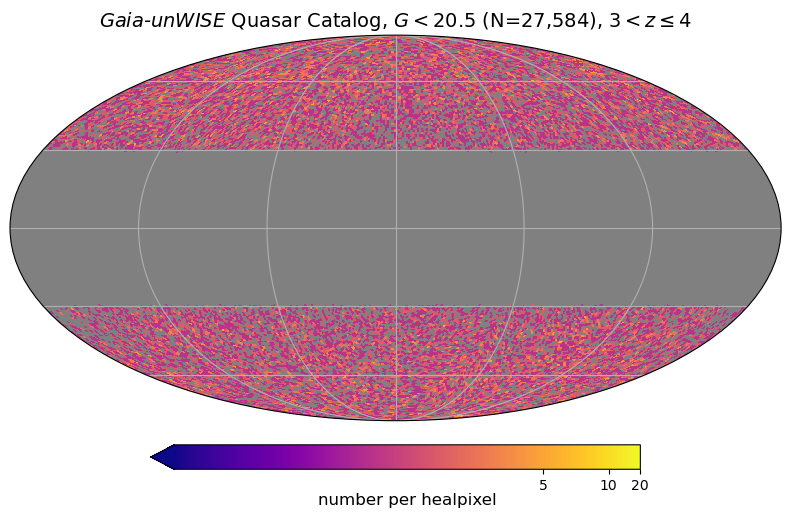

In [33]:
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                               plot = True, b = [0,0,0,30][j]) 

## Check random catalog

../data/randoms/random_G20.5_zmin0.0zmax1.0_25x.fits
G20.5_zmin0.0zmax1.0: 0.30              225792 vs 324336
24.59516723356009


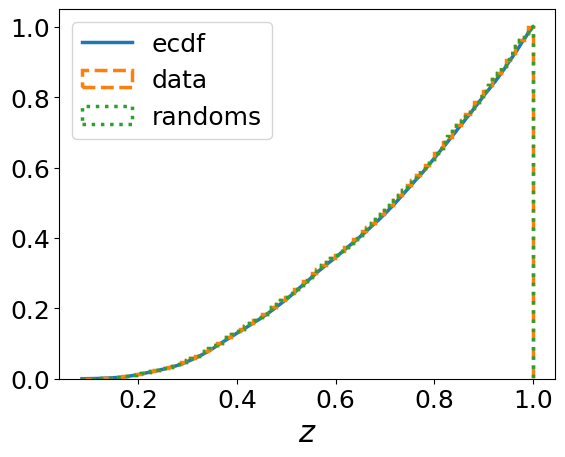

0.0
0.0
../data/randoms/random_G20.5_zmin1.0zmax2.0_25x.fits
G20.5_zmin1.0zmax2.0: 0.28              467913 vs 648196
24.769275484972635


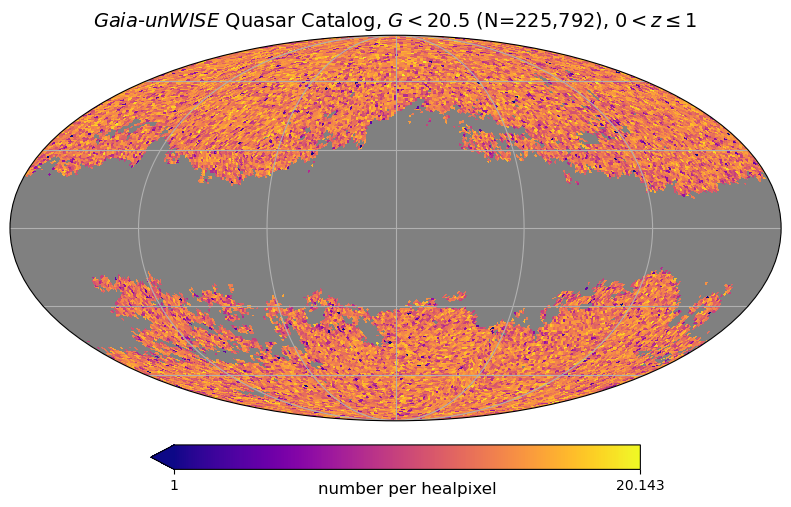

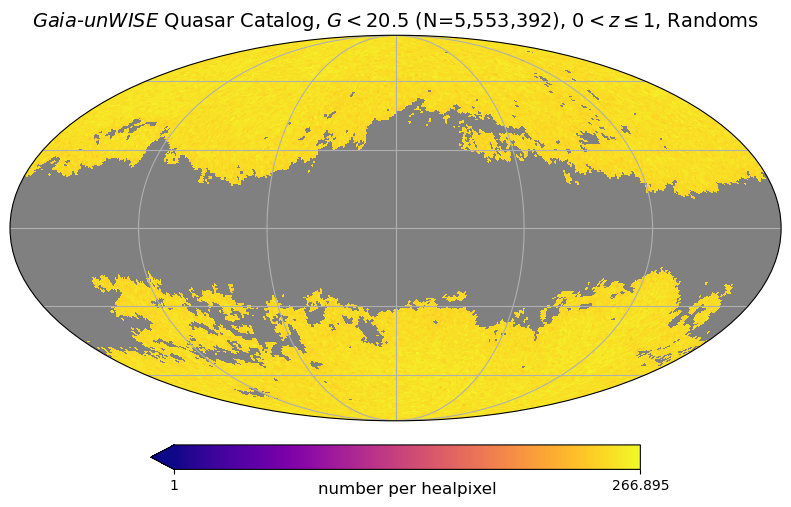

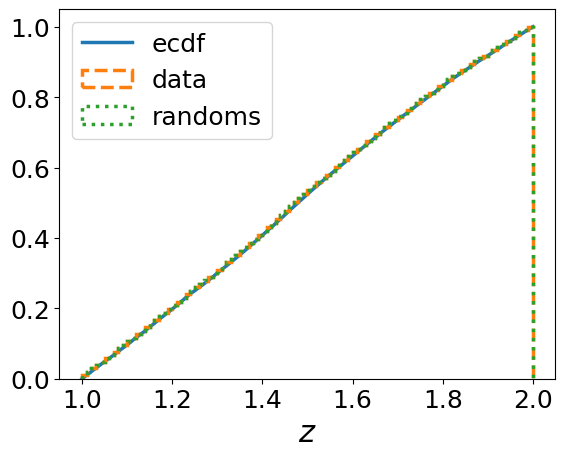

0.0
0.0
../data/randoms/random_G20.5_zmin2.0zmax3.0_25x.fits
G20.5_zmin2.0zmax3.0: 0.24              216828 vs 286508
24.316536609662958


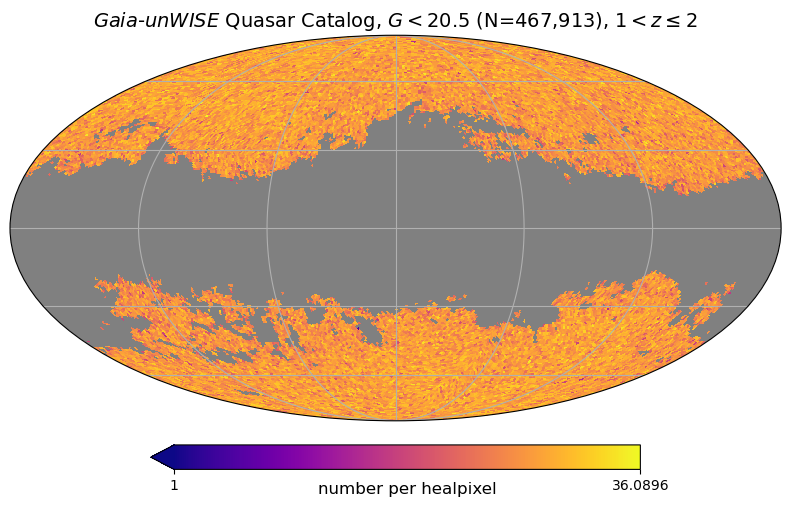

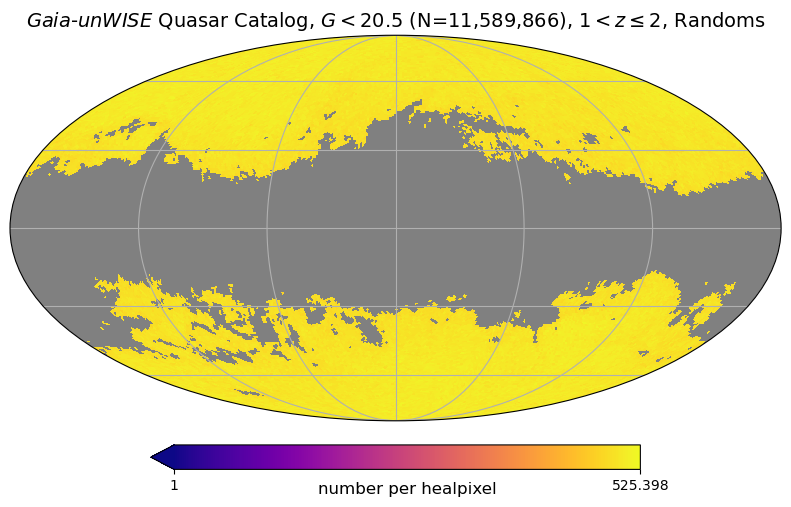

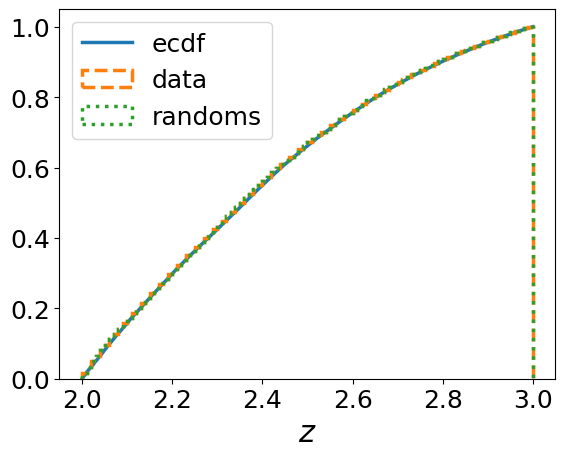

0.0
0.0
../data/randoms/random_G20.5_zmin3.0zmax4.0_25x.fits
G20.5_zmin3.0zmax4.0: 0.21              28061 vs 35630
20.88817219628666


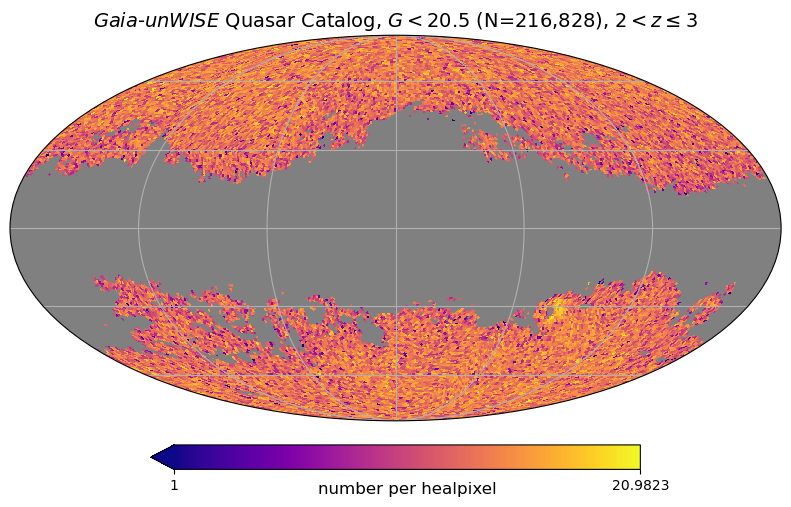

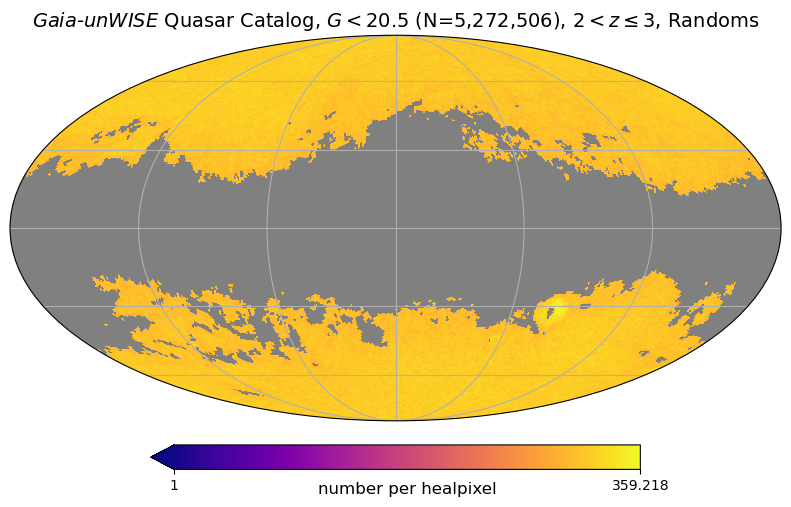

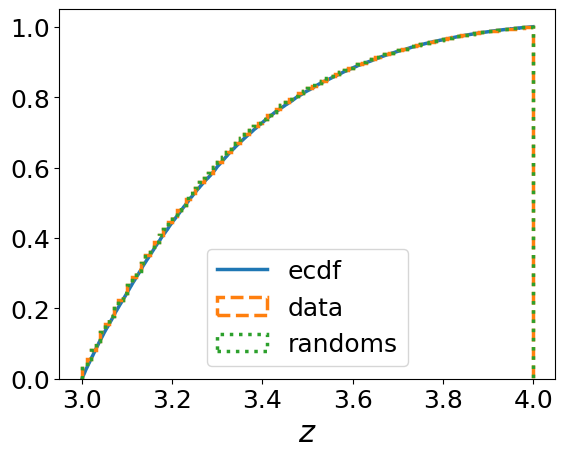

0.0
0.0


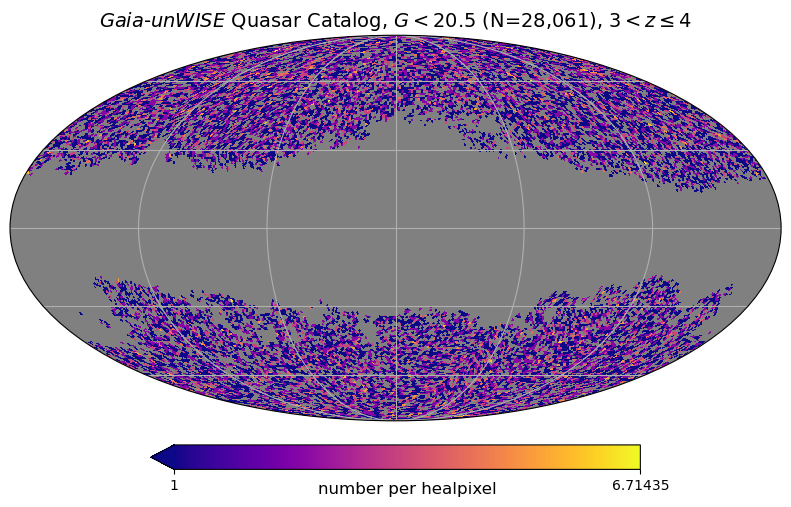

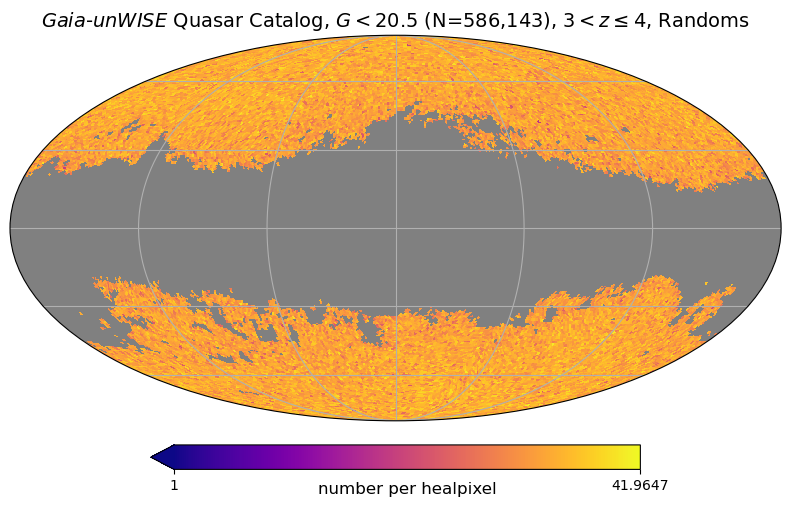

In [69]:
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _= quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask = mask*100, 
                                                                                               plot = True, percentile = True) 

../data/randoms/random_G20.5_zmin0.0zmax1.0_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.999142864190222


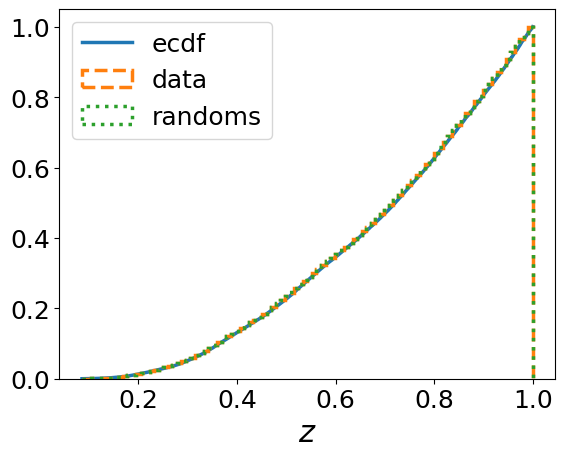

0.0
0.0
../data/randoms/random_G20.5_zmin1.0zmax2.0_25x.fits
G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196
24.99197464964301


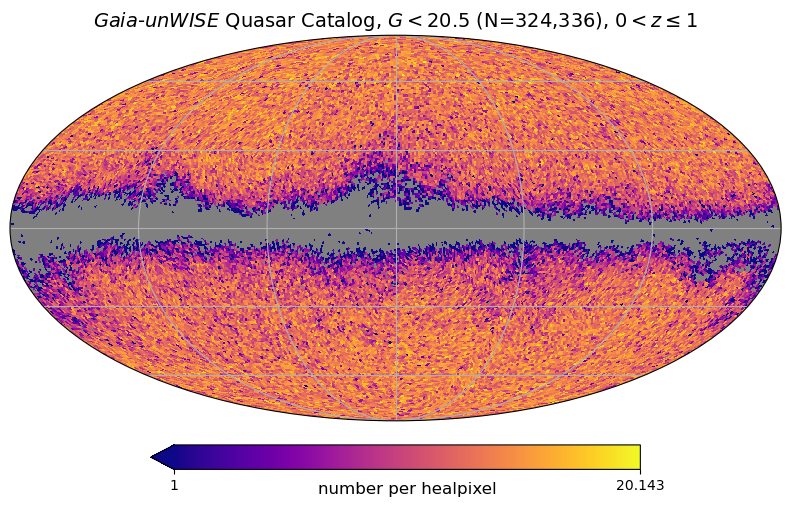

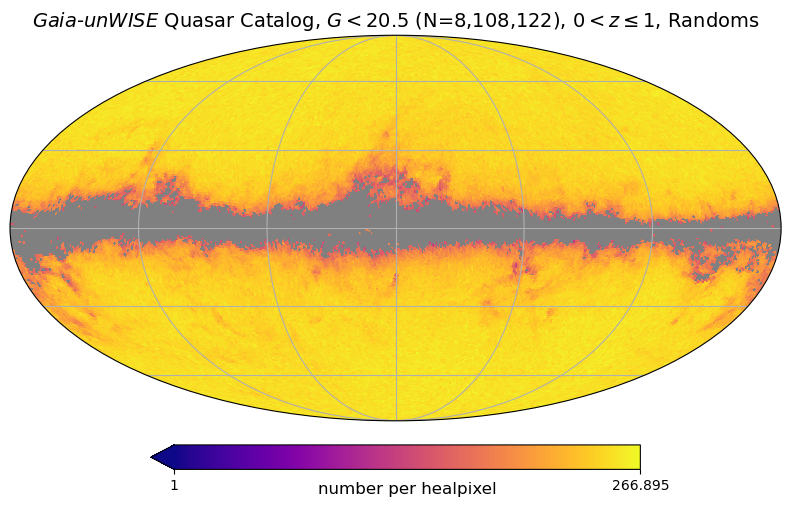

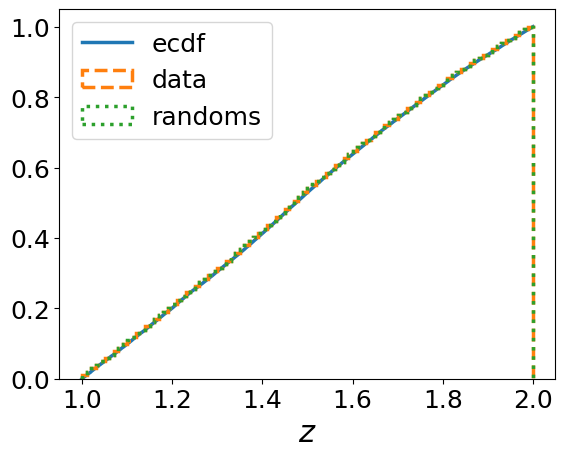

0.0
0.0
../data/randoms/random_G20.5_zmin2.0zmax3.0_25x.fits
G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508
24.969278344758262


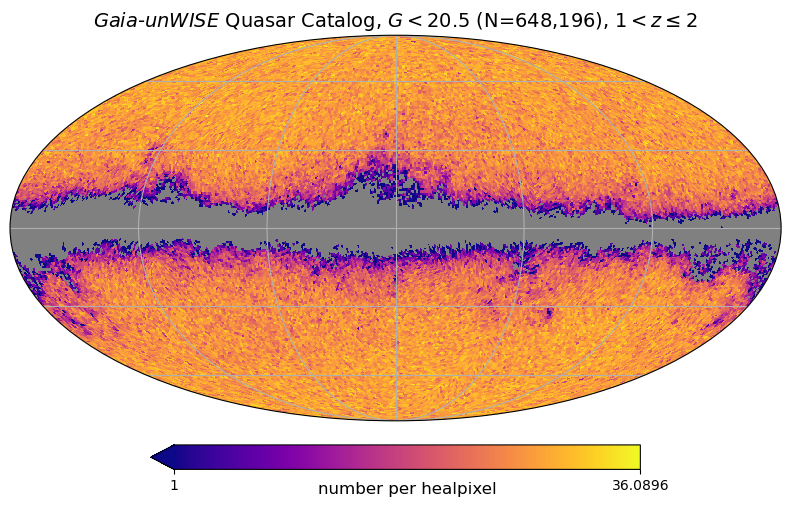

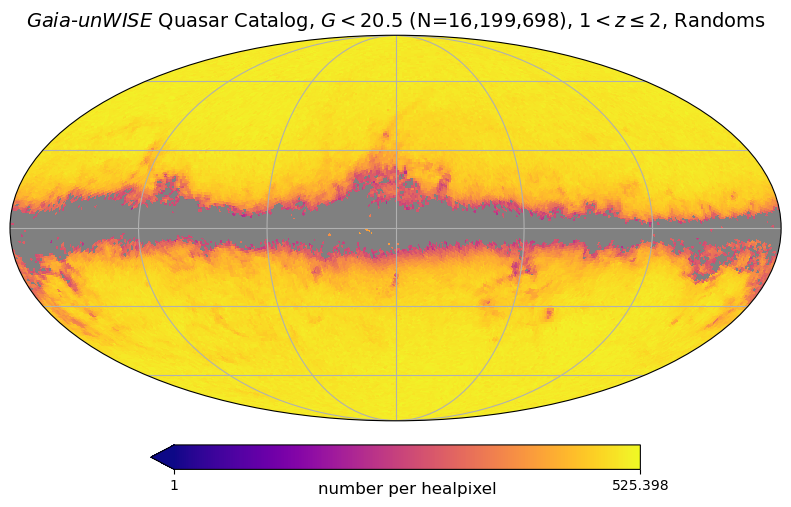

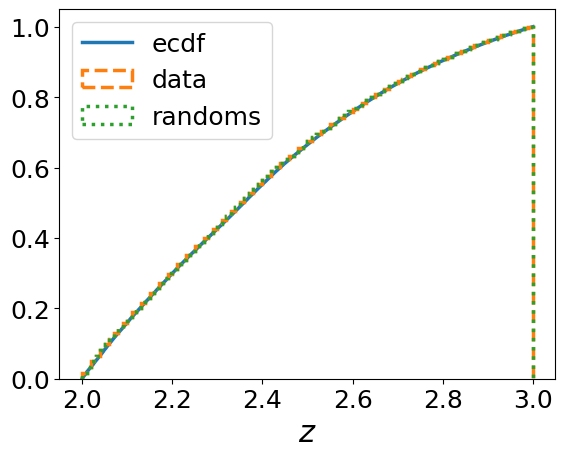

0.0
0.0
../data/randoms/random_G20.5_zmin3.0zmax4.0_25x.fits
G20.5_zmin3.0zmax4.0: 0.23              27584 vs 35630
20.923035092807424


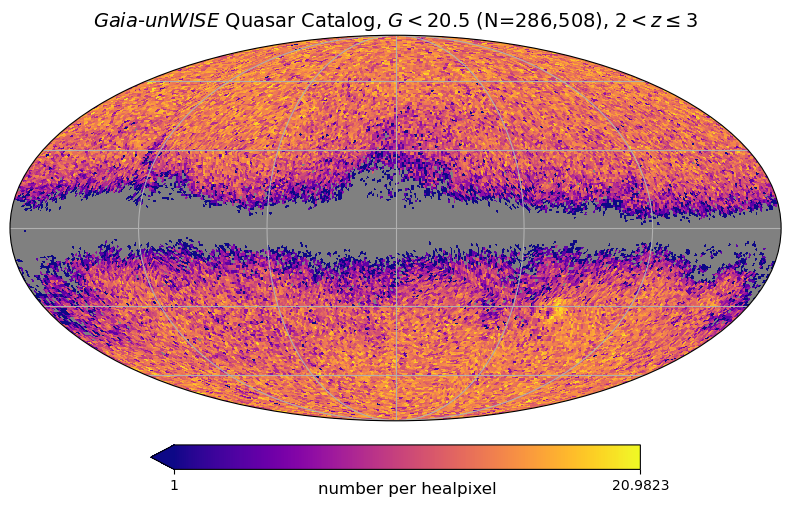

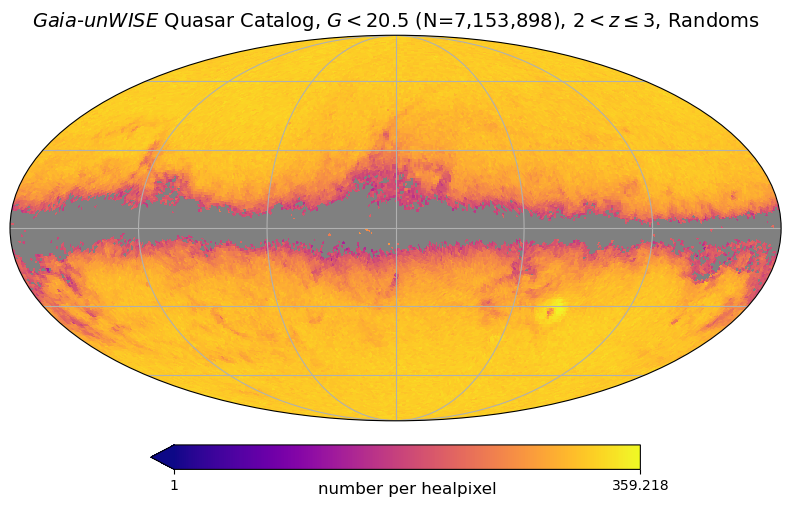

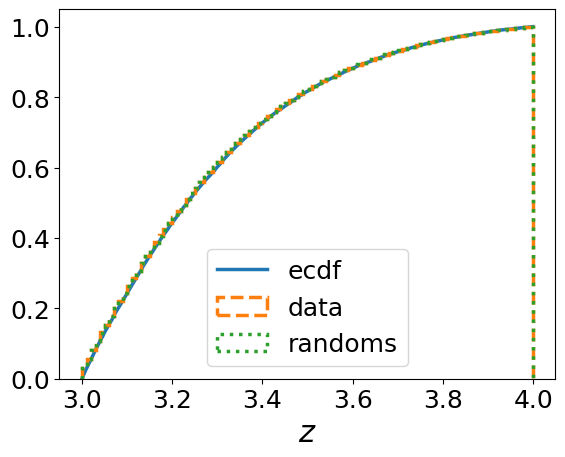

0.0
0.0


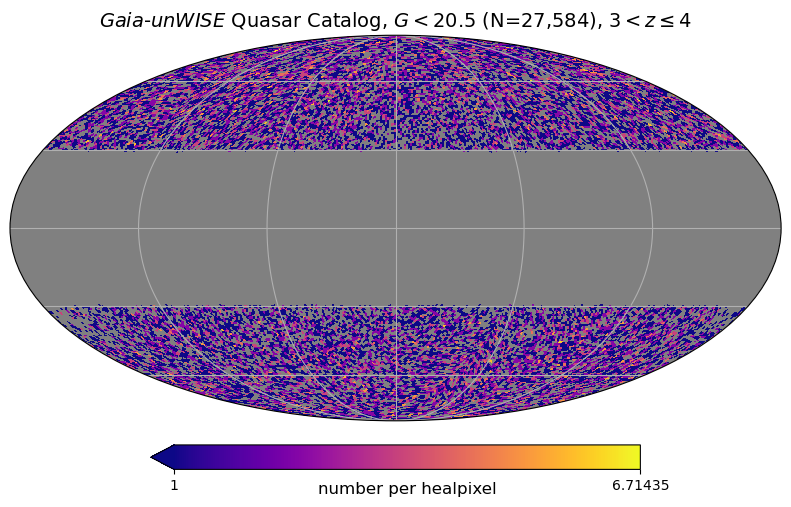

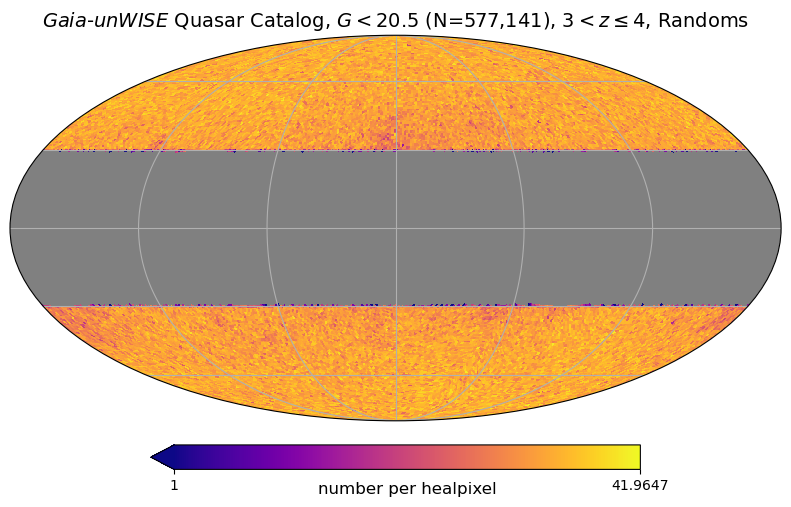

In [70]:
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _ = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                               plot = True, b = [0,0,0,30][j]) 

### Check that the randoms follow the data

In [16]:
NSIDE = 64
NPIX = hp.nside2npix(NSIDE)

../data/randoms/random_G20.5_zmin0.0zmax1.0_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.999142864190222


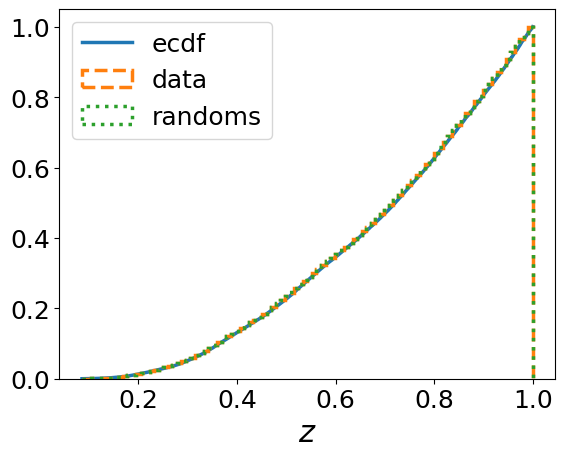

0.0
0.0


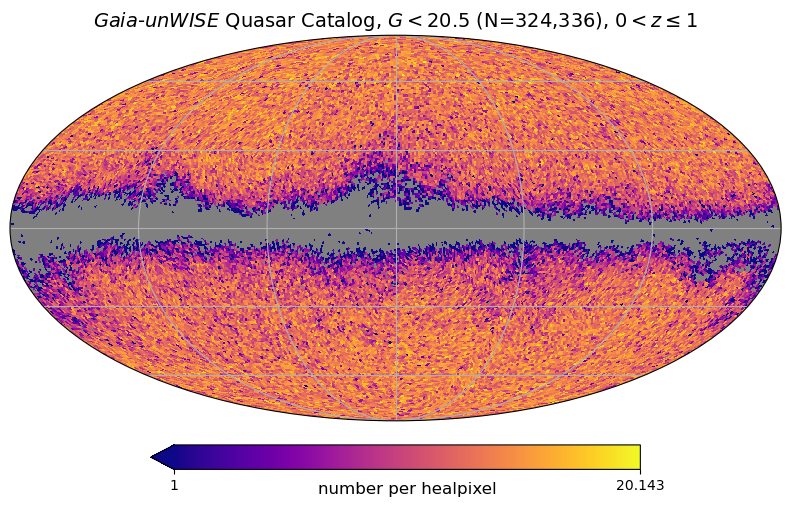

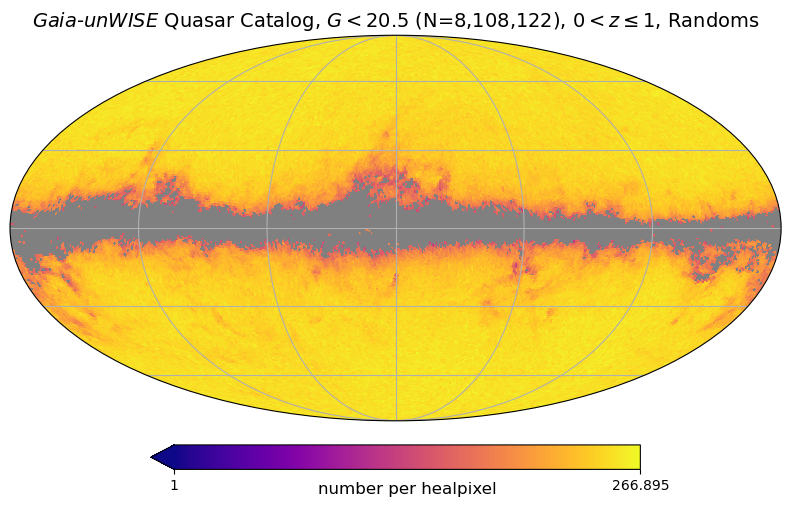

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


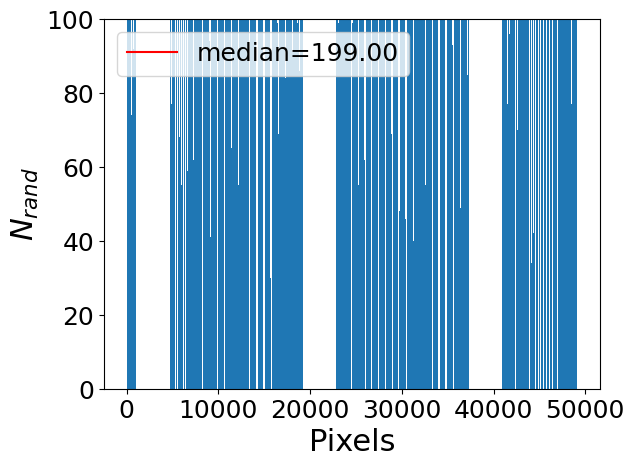

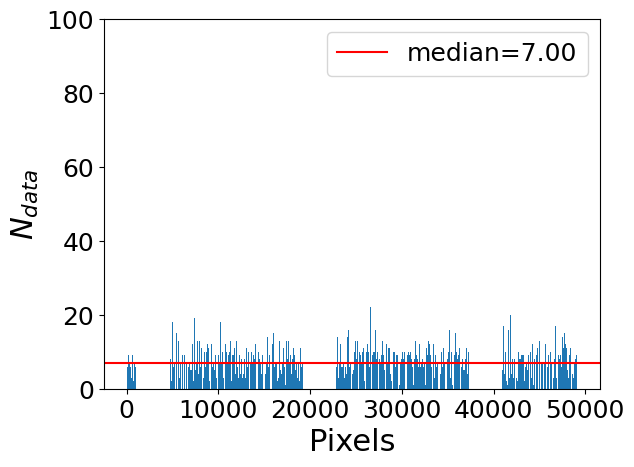

/tmp/ipykernel_207953/2874585713.py:31: RuntimeWarning: divide by zero encountered in divide
  ratio = map_randlo/map_gcatlo
/tmp/ipykernel_207953/2874585713.py:31: RuntimeWarning: invalid value encountered in divide
  ratio = map_randlo/map_gcatlo


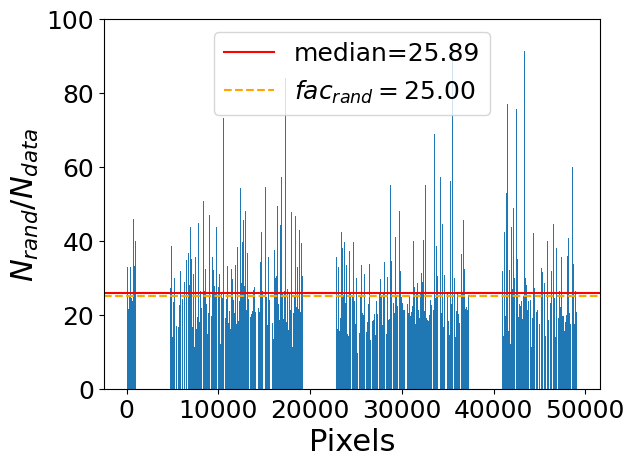

../data/randoms/random_G20.5_zmin1.0zmax2.0_25x.fits
G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196
24.99197464964301


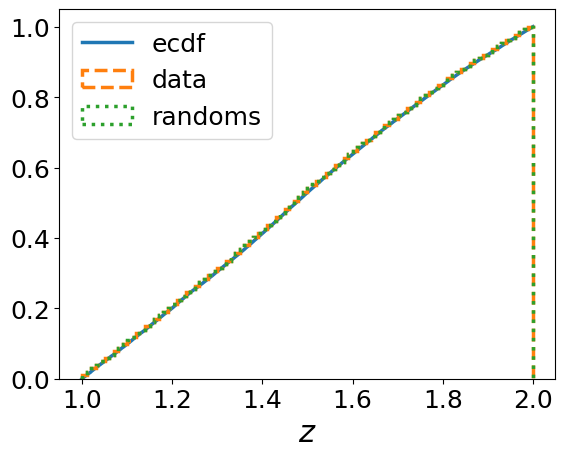

0.0
0.0


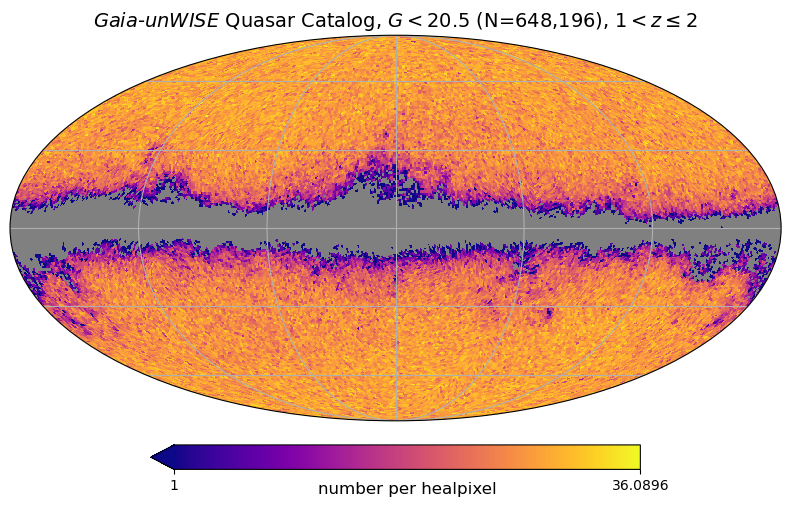

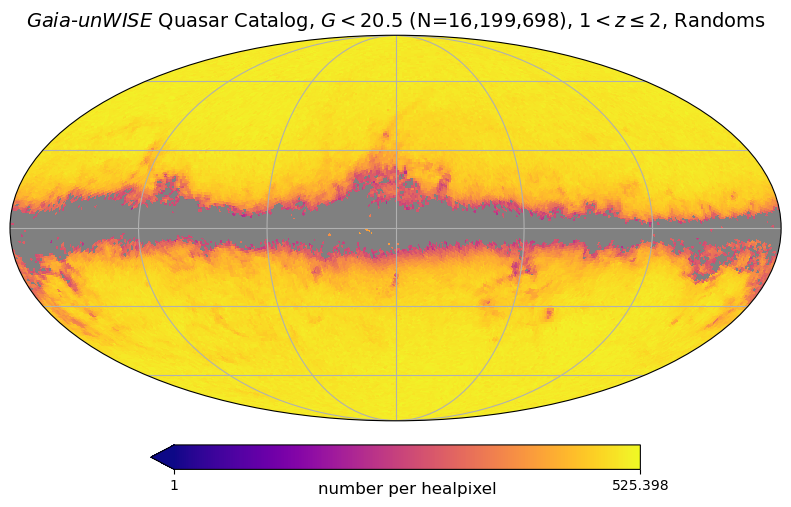

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


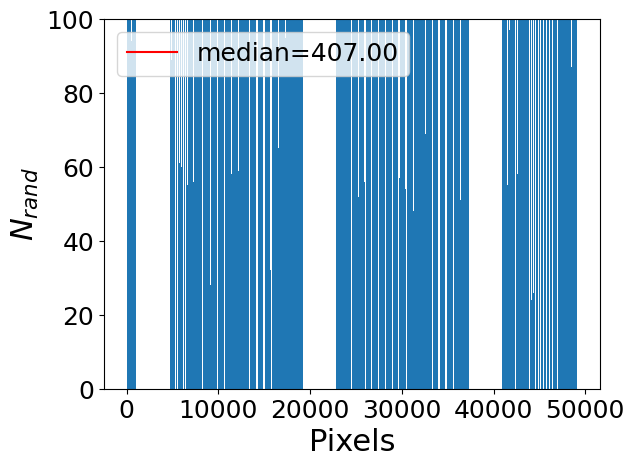

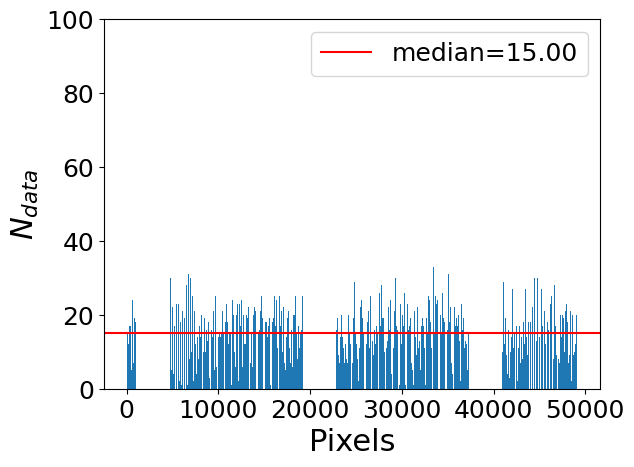

/tmp/ipykernel_207953/2874585713.py:31: RuntimeWarning: divide by zero encountered in divide
  ratio = map_randlo/map_gcatlo
/tmp/ipykernel_207953/2874585713.py:31: RuntimeWarning: invalid value encountered in divide
  ratio = map_randlo/map_gcatlo


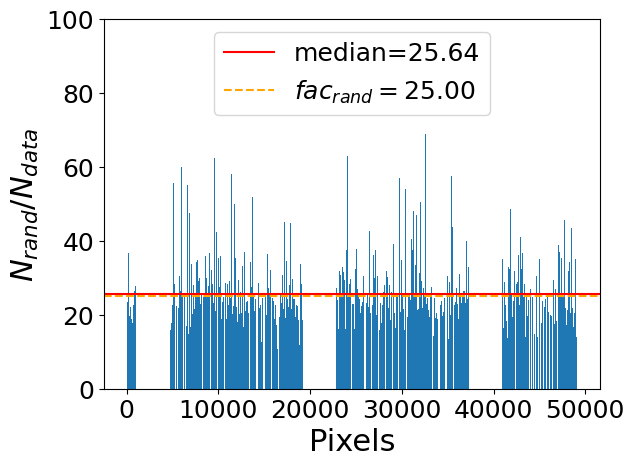

../data/randoms/random_G20.5_zmin2.0zmax3.0_25x.fits
G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508
24.969278344758262


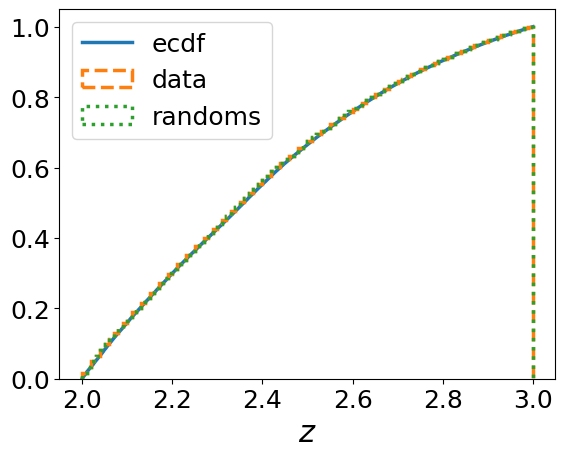

0.0
0.0


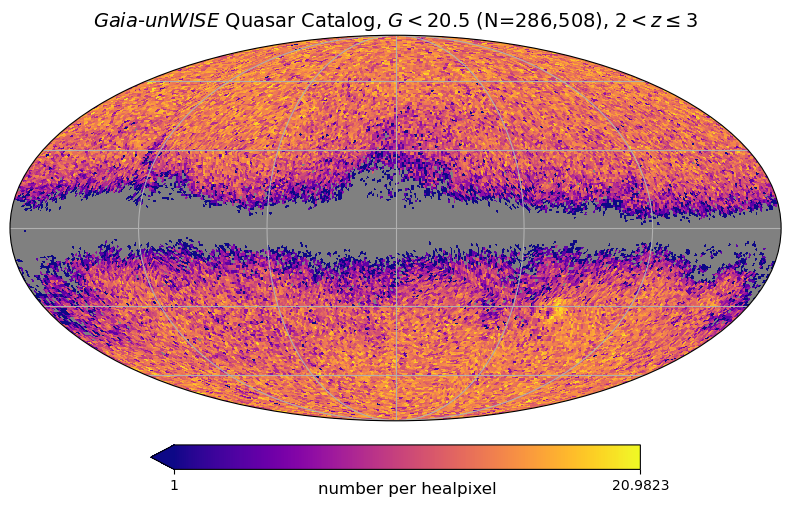

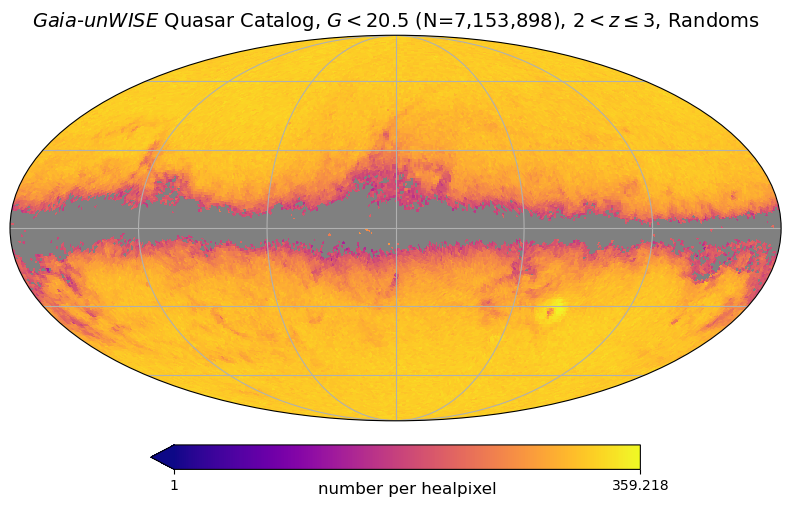

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


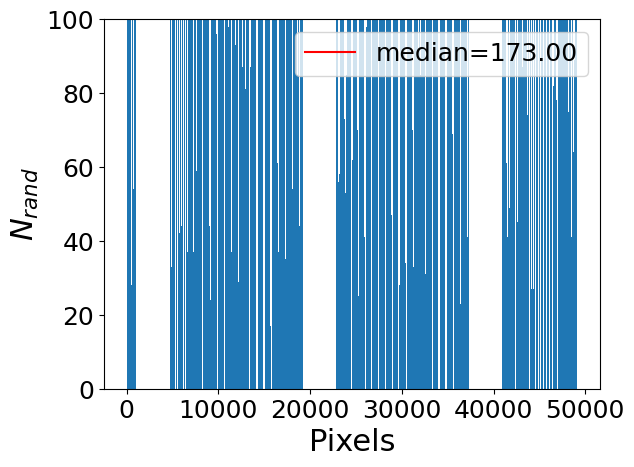

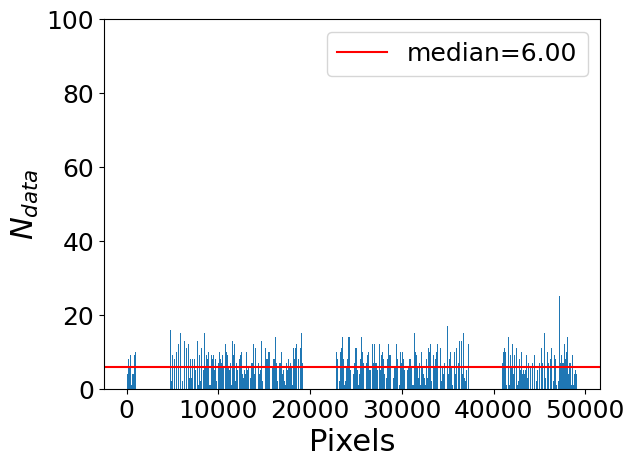

/tmp/ipykernel_207953/2874585713.py:31: RuntimeWarning: divide by zero encountered in divide
  ratio = map_randlo/map_gcatlo
/tmp/ipykernel_207953/2874585713.py:31: RuntimeWarning: invalid value encountered in divide
  ratio = map_randlo/map_gcatlo


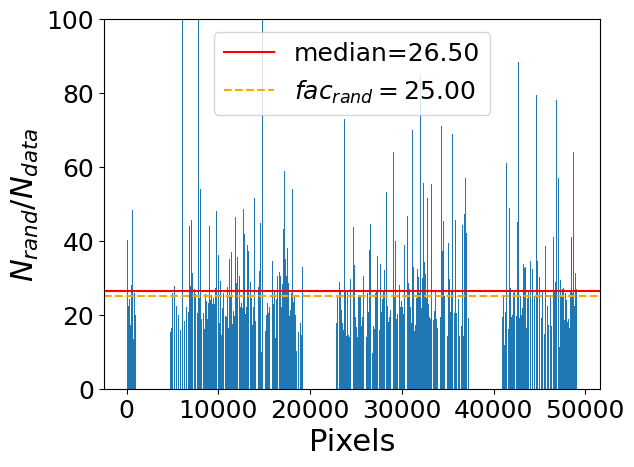

../data/randoms/random_G20.5_zmin3.0zmax4.0_25x.fits
G20.5_zmin3.0zmax4.0: 0.23              27584 vs 35630
20.923035092807424


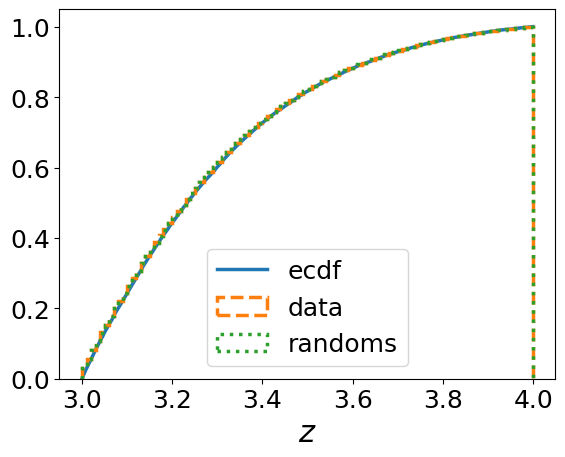

0.0
0.0


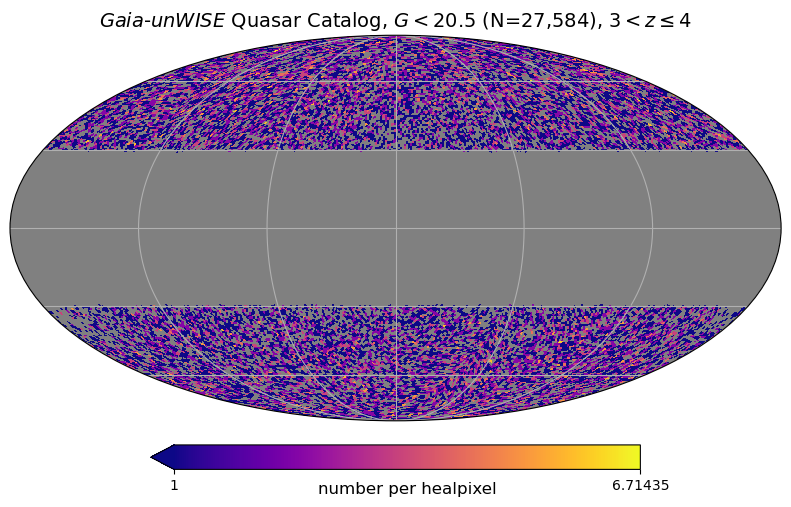

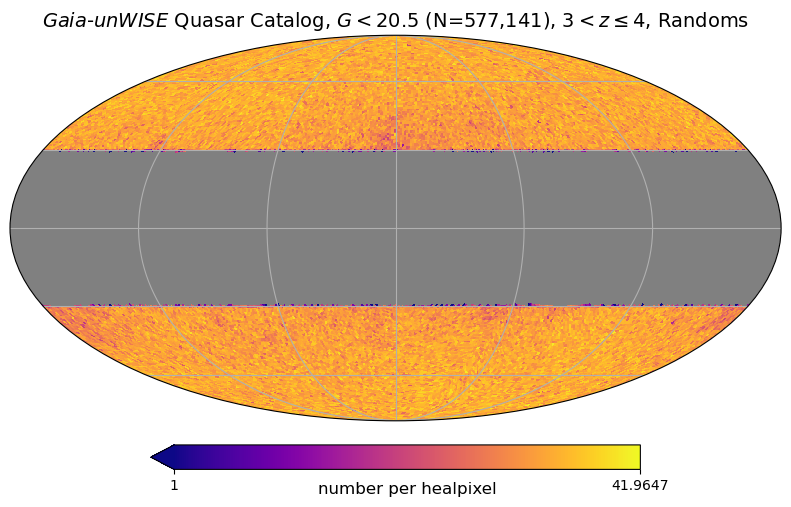

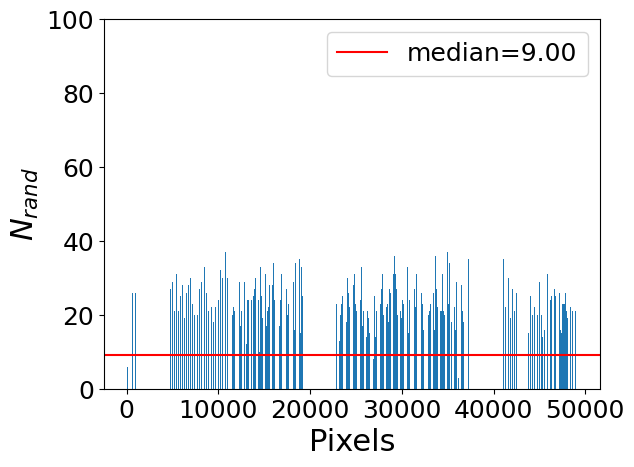

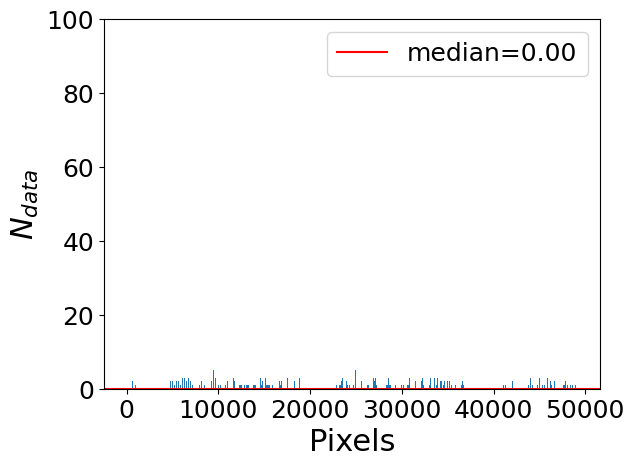

/tmp/ipykernel_207953/2874585713.py:31: RuntimeWarning: divide by zero encountered in divide
  ratio = map_randlo/map_gcatlo
/tmp/ipykernel_207953/2874585713.py:31: RuntimeWarning: invalid value encountered in divide
  ratio = map_randlo/map_gcatlo
/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


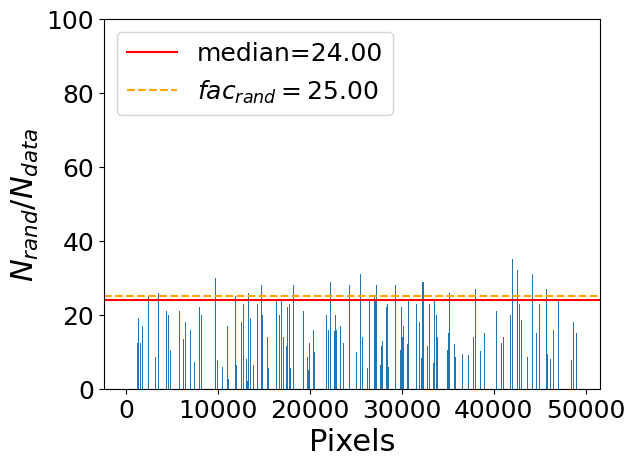

In [17]:
cmap_map = 'plasma'
name_catalog='$Gaia$-$unWISE$ Quasar Catalog',

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, map_gcatlo, map_randlo, pixel_indices_gcatlo, pixel_indices_randlo = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                                   tab_gcat_type = 'data', method = ['minmax'], 
                                                                                                   fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                                   plot = True, b = [0,0,0,30][j])

    plt.figure()
    plt.bar(np.arange(NPIX), map_randlo)
    y = np.median(map_randlo)
    plt.axhline(y, label = 'median={:.2f}'.format(y), color = 'red')
    plt.xlabel('Pixels')
    plt.ylabel('$N_{rand}$')
    plt.ylim(0, 100)
    plt.legend()
    plt.show()

    plt.bar(np.arange(NPIX), map_gcatlo)
    y = np.median(map_gcatlo)
    plt.axhline(y, label = 'median={:.2f}'.format(y), color = 'red')
    plt.xlabel('Pixels')
    plt.ylabel('$N_{data}$')
    plt.ylim(0, 100)
    plt.legend()
    plt.show()

    plt.figure()
    ratio = map_randlo/map_gcatlo
    plt.bar(np.arange(NPIX), ratio)
    y = np.nanmedian(ratio)
    plt.axhline(y, label = 'median={:.2f}'.format(y), color = 'red')
    plt.axhline(25, label = '$fac_{rand}=25.00$', linestyle = '--', color = 'orange')
    plt.xlabel('Pixels')
    plt.ylabel('$N_{rand}/N_{data}$')
    plt.ylim(0, 100)
    plt.legend()
    plt.show()

../data/randoms/random_G20.5_zmin0.0zmax1.0_zero_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.990565339647773


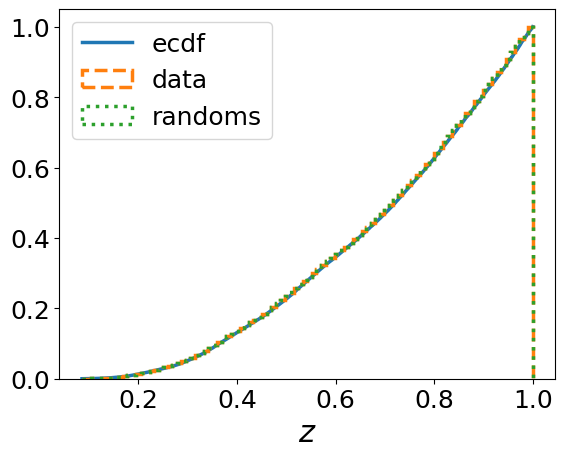

0.0
0.0


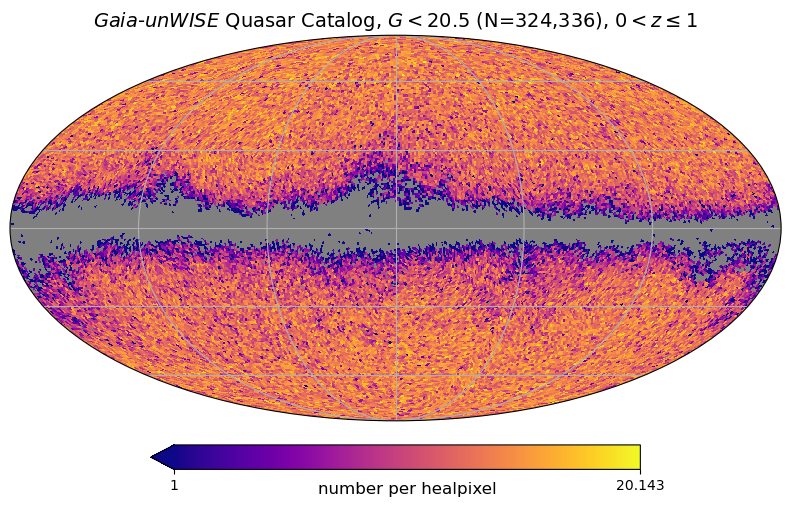

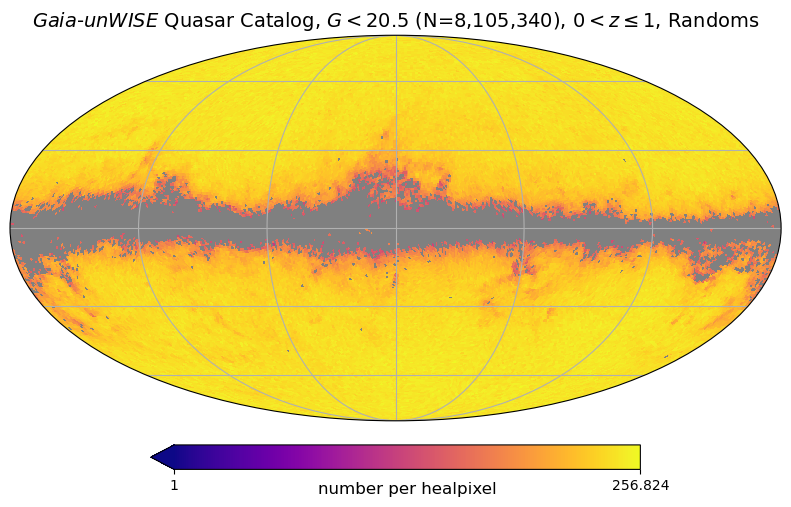

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


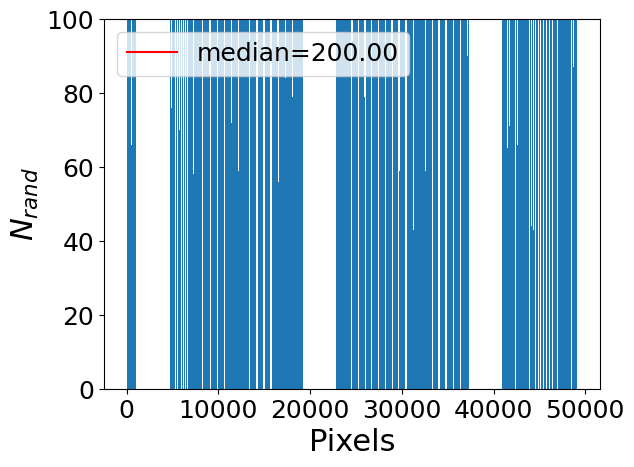

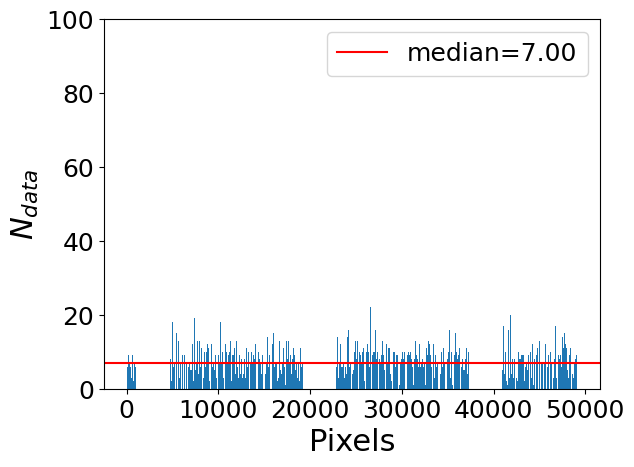

/tmp/ipykernel_207953/2984312346.py:28: RuntimeWarning: invalid value encountered in divide
  ratio = map_randlo/map_gcatlo


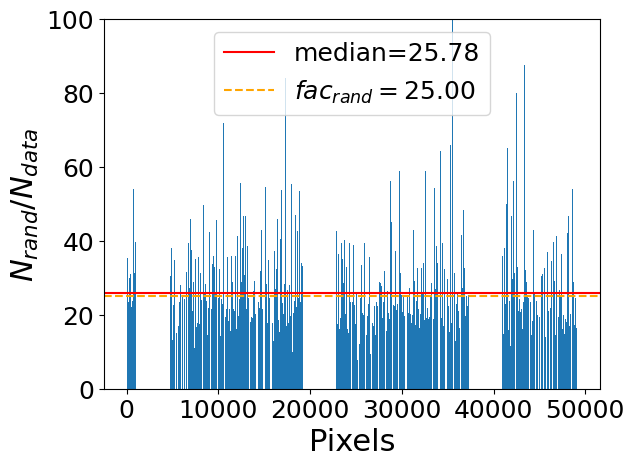

../data/randoms/random_G20.5_zmin1.0zmax2.0_zero_25x.fits
G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196
24.994950601361317


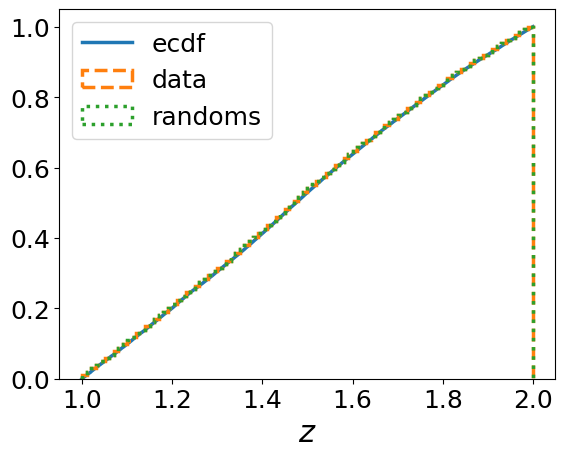

0.0
0.0


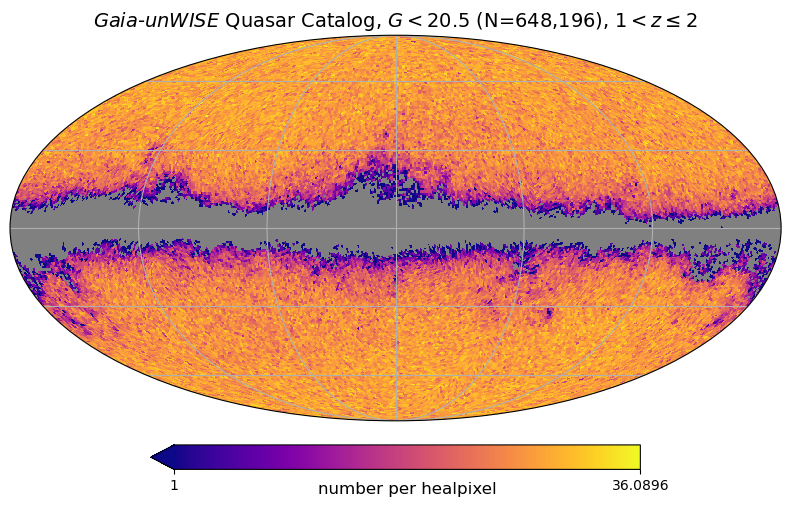

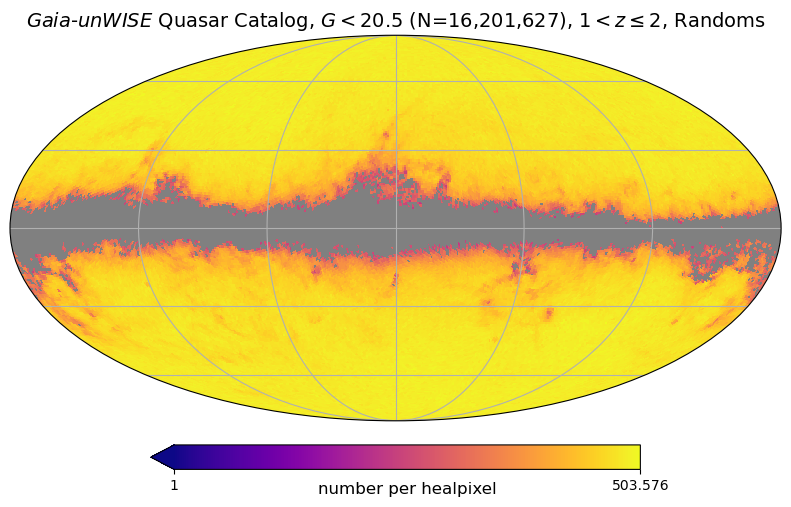

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


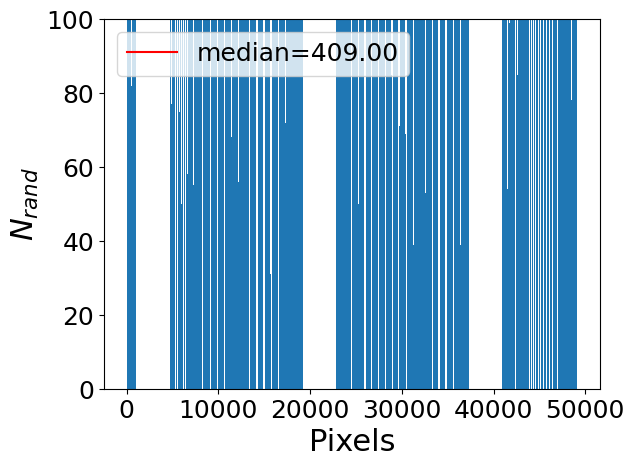

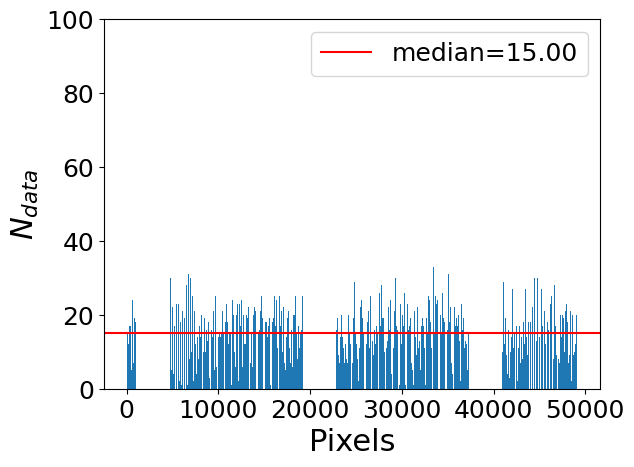

/tmp/ipykernel_207953/2984312346.py:28: RuntimeWarning: invalid value encountered in divide
  ratio = map_randlo/map_gcatlo


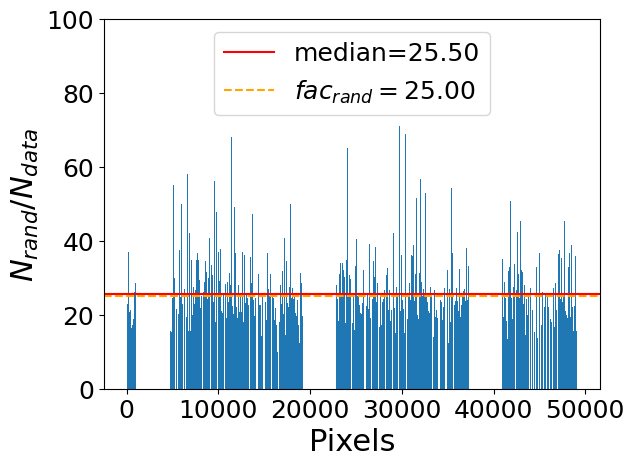

../data/randoms/random_G20.5_zmin2.0zmax3.0_zero_25x.fits
G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508
24.9659939687548


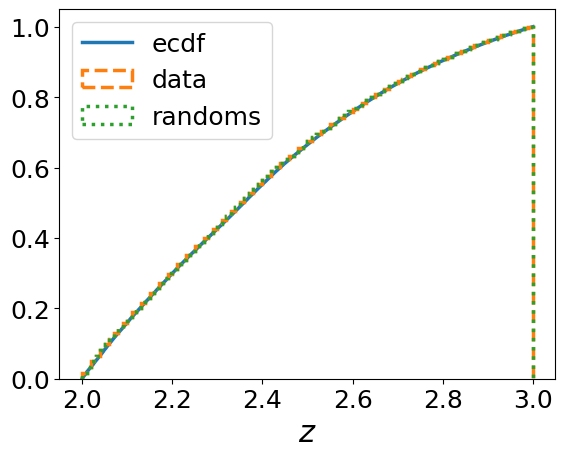

0.0
0.0


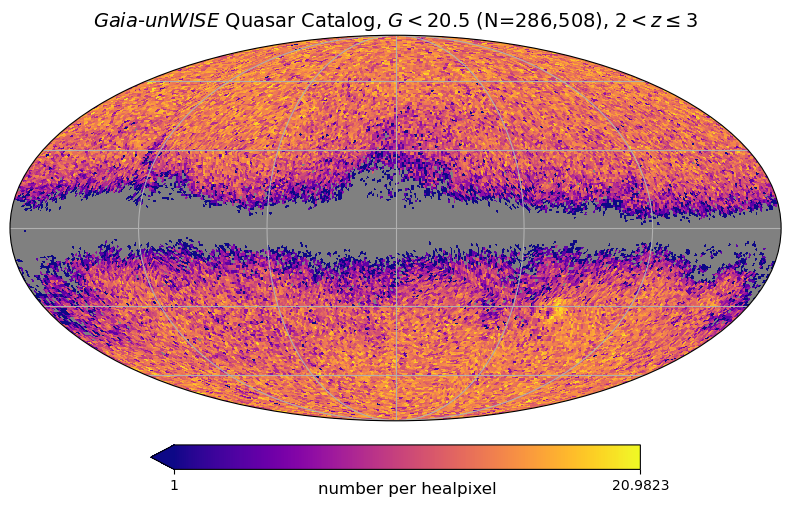

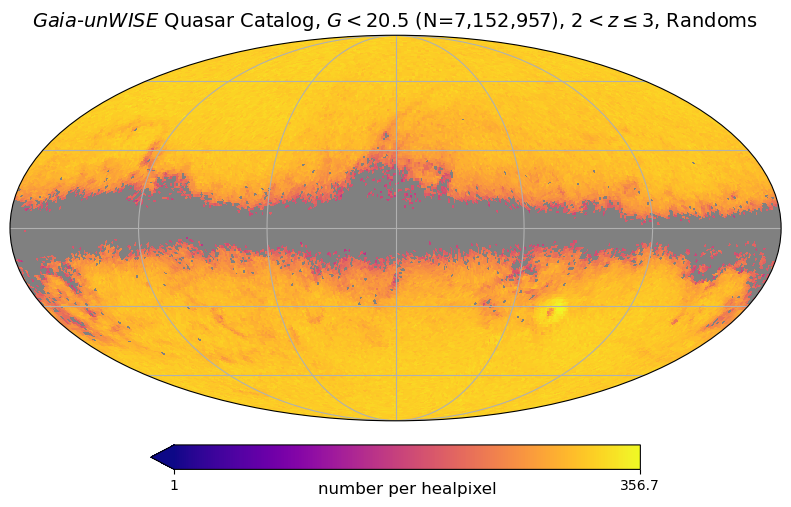

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


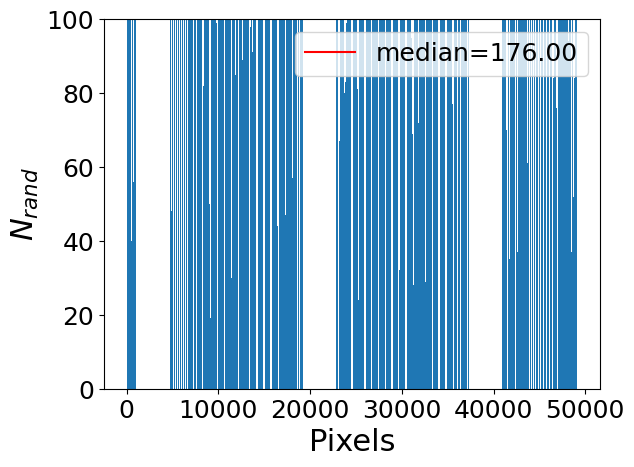

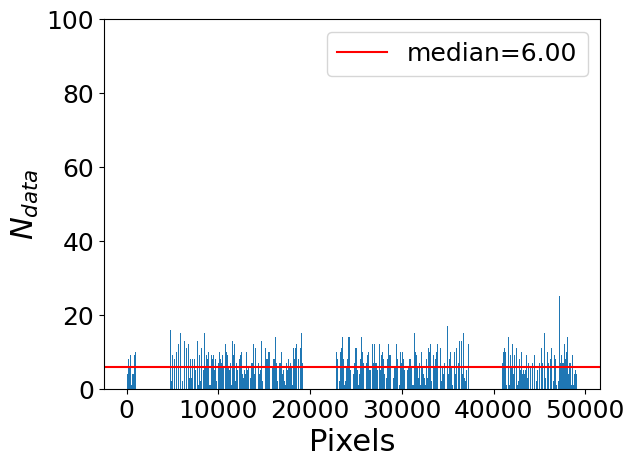

/tmp/ipykernel_207953/2984312346.py:28: RuntimeWarning: invalid value encountered in divide
  ratio = map_randlo/map_gcatlo


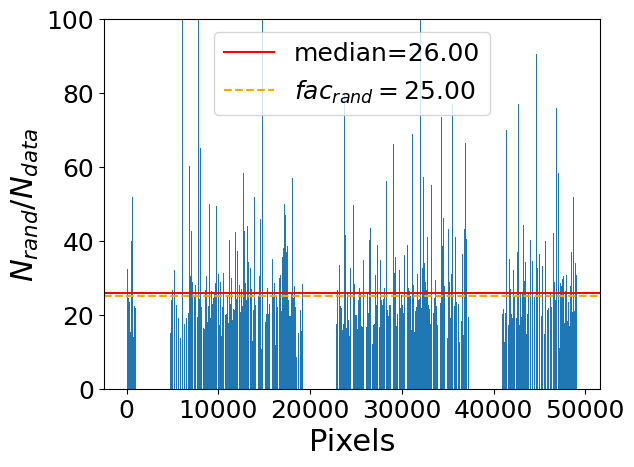

../data/randoms/random_G20.5_zmin3.0zmax4.0_zero_25x.fits
G20.5_zmin3.0zmax4.0: 0.23              27584 vs 35630
25.069750580046403


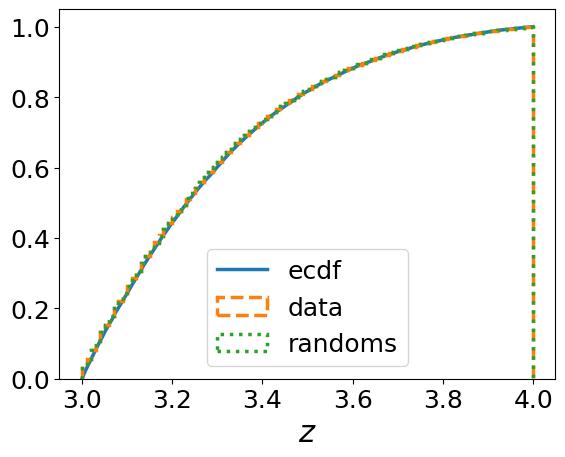

0.0
0.0


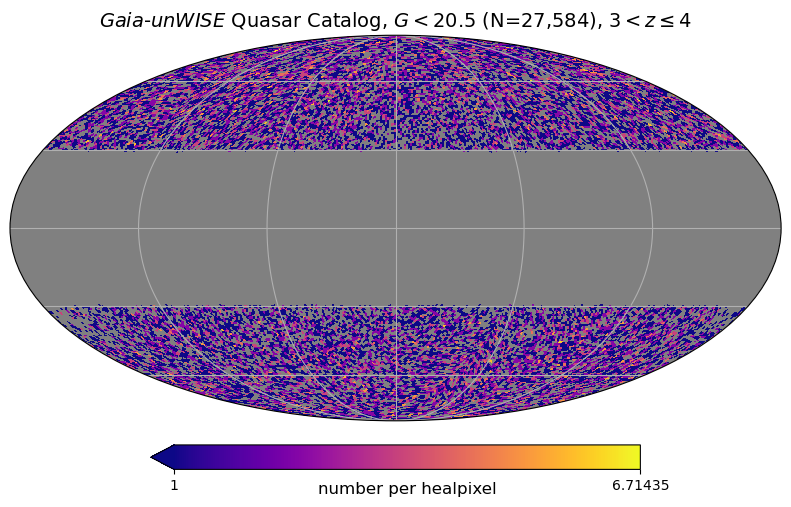

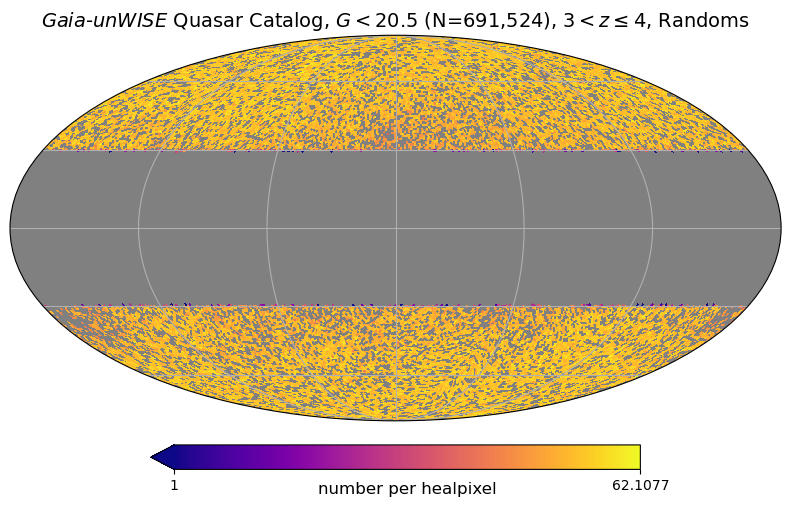

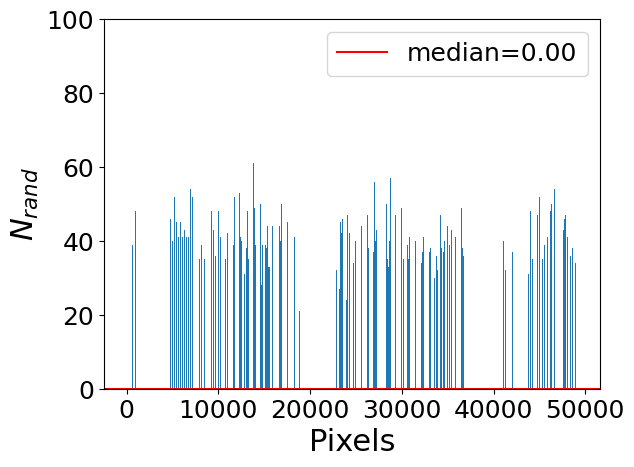

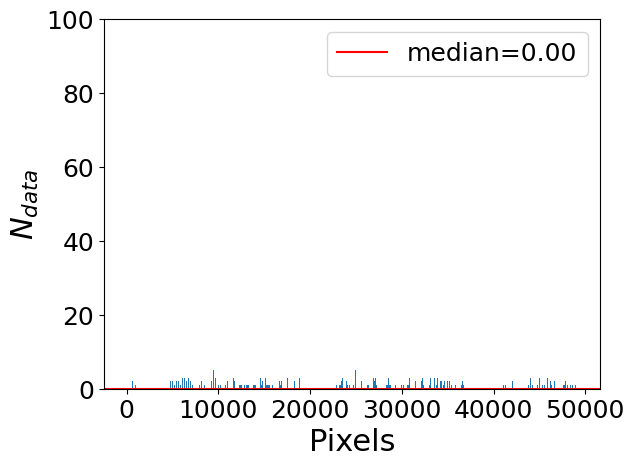

/tmp/ipykernel_207953/2984312346.py:28: RuntimeWarning: divide by zero encountered in divide
  ratio = map_randlo/map_gcatlo
/tmp/ipykernel_207953/2984312346.py:28: RuntimeWarning: invalid value encountered in divide
  ratio = map_randlo/map_gcatlo
/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


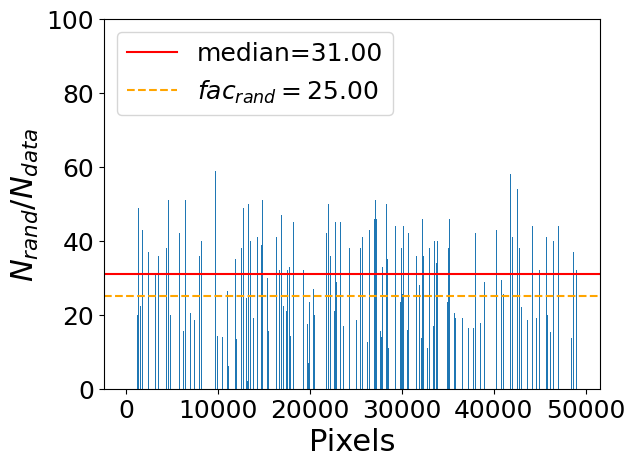

In [18]:
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, map_gcatlo, map_randlo, pixel_indices_gcatlo, pixel_indices_randlo = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                                   tab_gcat_type = 'data', method = ['minmax'], 
                                                                                                   fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                                   plot = True, b = [0,0,0,30][j], allsky = '_zero')

    plt.figure()
    plt.bar(np.arange(NPIX), map_randlo)
    y = np.median(map_randlo)
    plt.axhline(y, label = 'median={:.2f}'.format(y), color = 'red')
    plt.xlabel('Pixels')
    plt.ylabel('$N_{rand}$')
    plt.ylim(0, 100)
    plt.legend()
    plt.show()

    plt.bar(np.arange(NPIX), map_gcatlo)
    y = np.median(map_gcatlo)
    plt.axhline(y, label = 'median={:.2f}'.format(y), color = 'red')
    plt.xlabel('Pixels')
    plt.ylabel('$N_{data}$')
    plt.ylim(0, 100)
    plt.legend()
    plt.show()

    plt.figure()
    ratio = map_randlo/map_gcatlo
    plt.bar(np.arange(NPIX), ratio)
    y = np.nanmedian(ratio)
    plt.axhline(y, label = 'median={:.2f}'.format(y), color = 'red')
    plt.axhline(25, label = '$fac_{rand}=25.00$', linestyle = '--', color = 'orange')
    plt.xlabel('Pixels')
    plt.ylabel('$N_{rand}/N_{data}$')
    plt.ylim(0, 100)
    plt.legend()
    plt.show()

../data/randoms/random_G20.5_zmin0.0zmax1.0_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.999142864190222


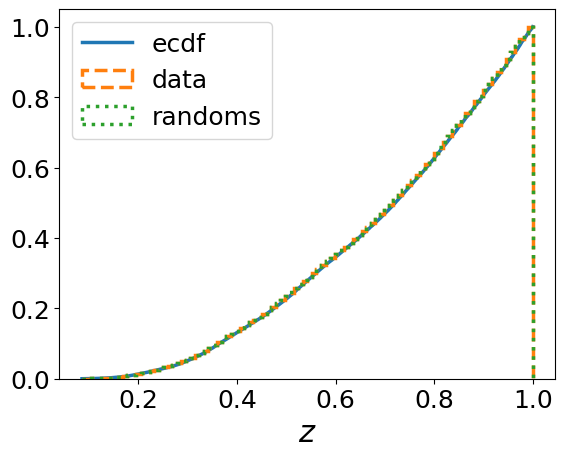

0.0
0.0
0 < z <= 1
data 7076
rand 6299
selfunc 6299
../data/randoms/random_G20.5_zmin1.0zmax2.0_25x.fits
G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196
24.99197464964301


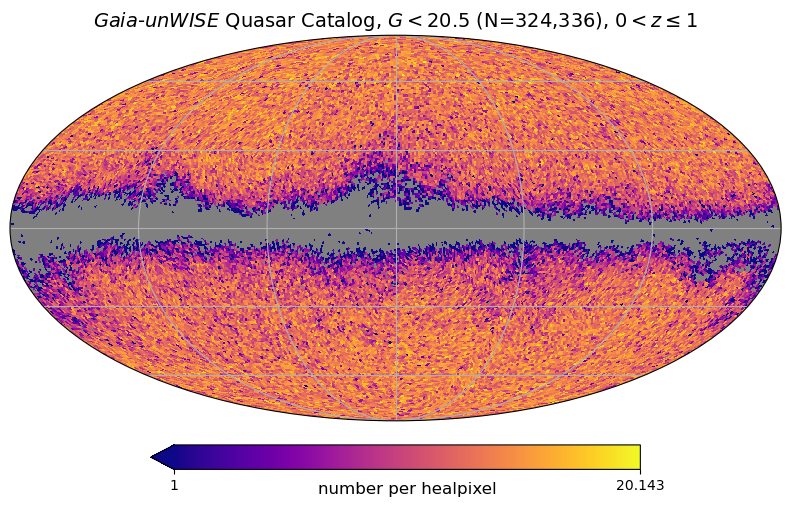

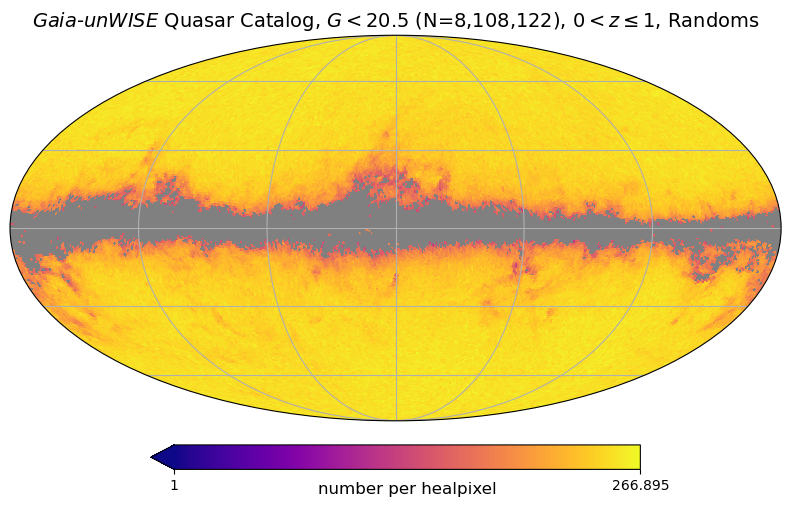

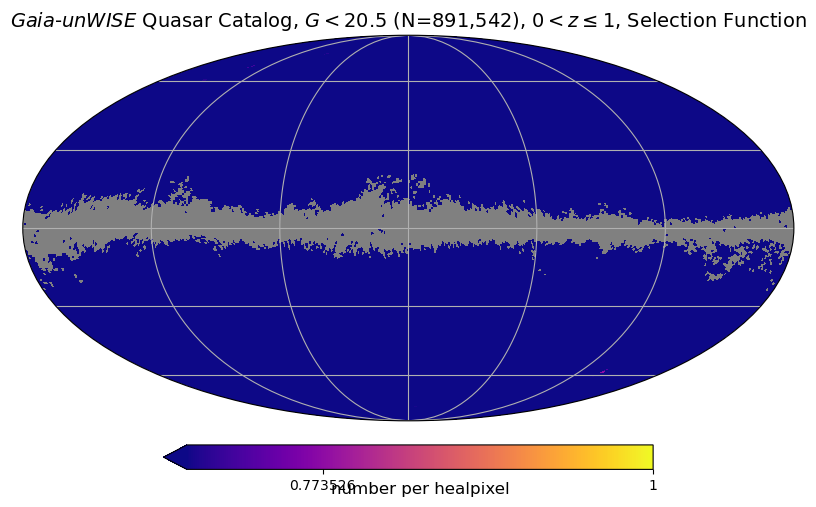

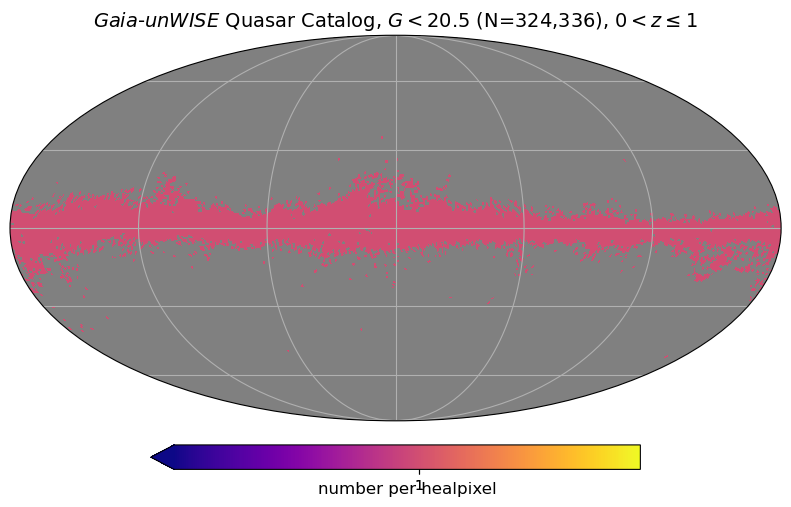

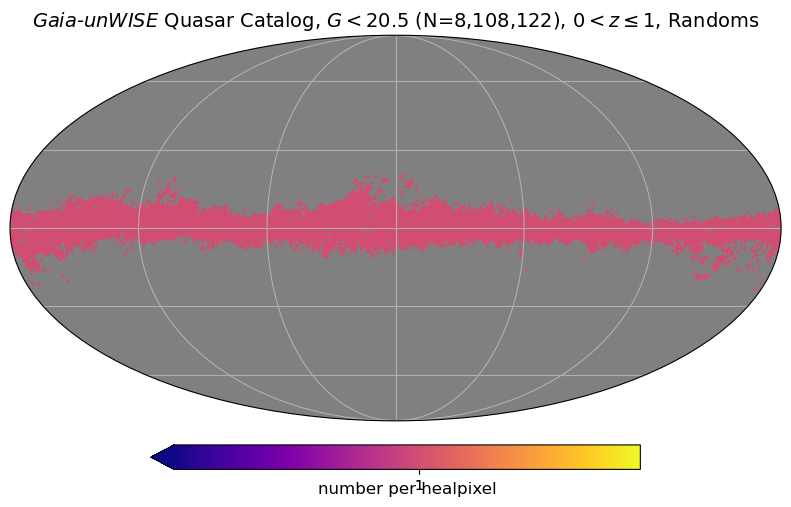

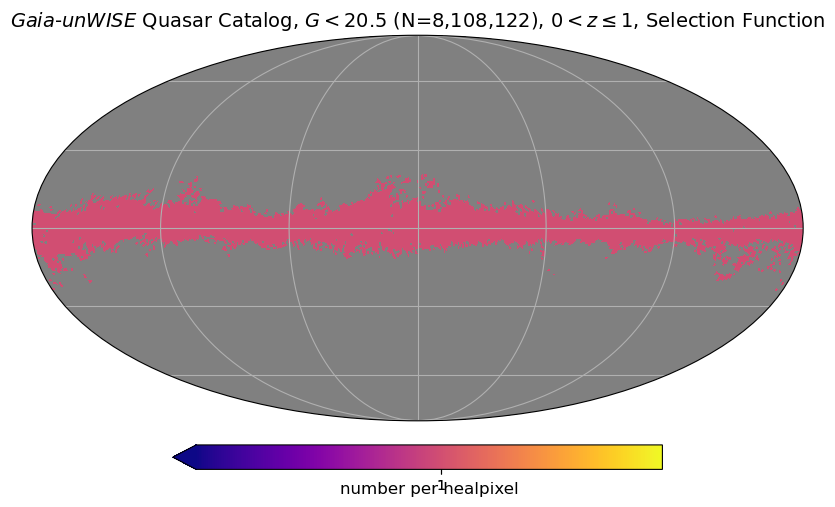

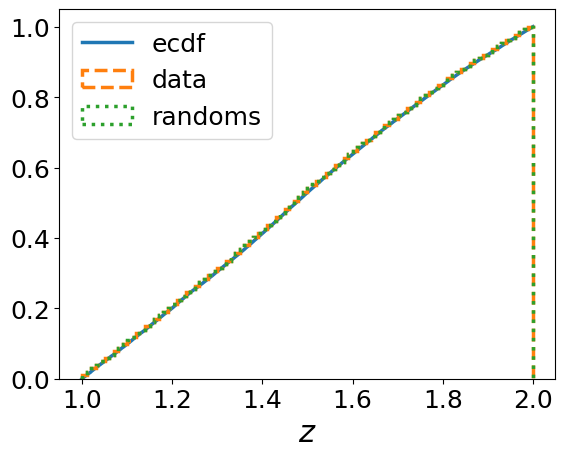

0.0
0.0
1 < z <= 2
data 7388
rand 6299
selfunc 6299
../data/randoms/random_G20.5_zmin2.0zmax3.0_25x.fits
G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508
24.969278344758262


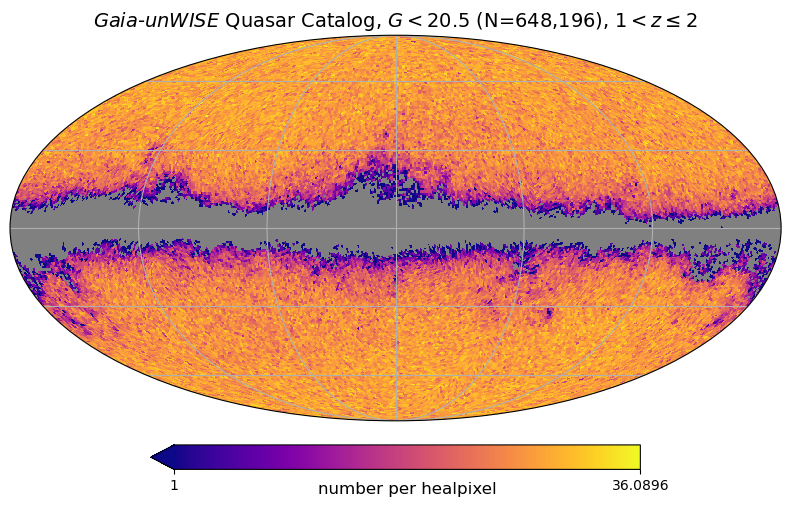

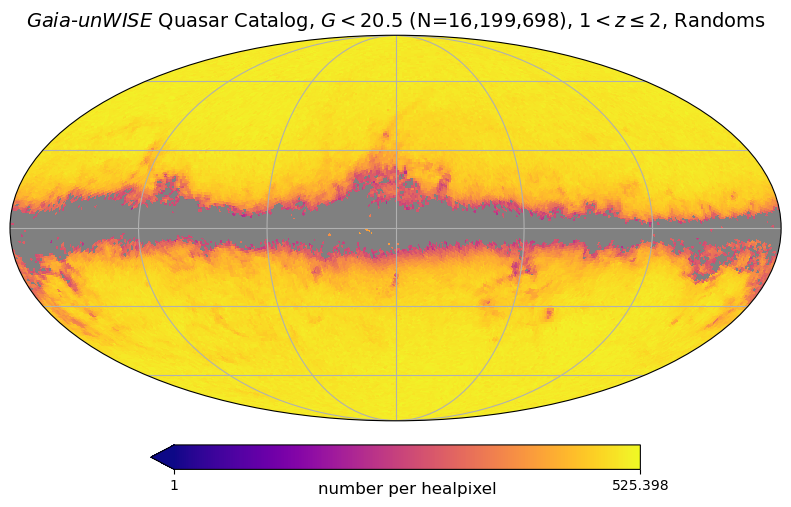

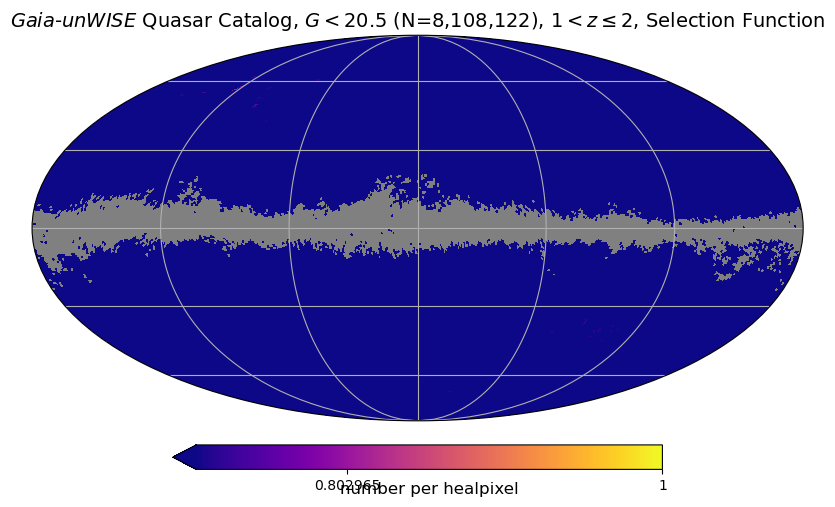

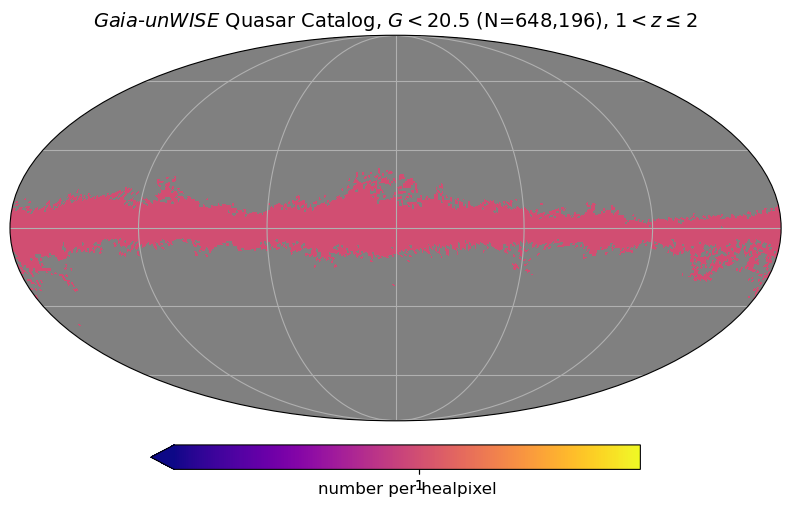

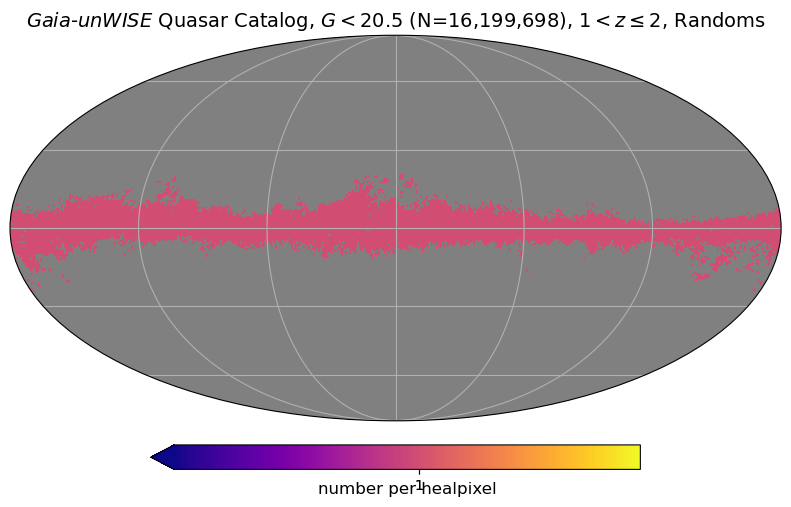

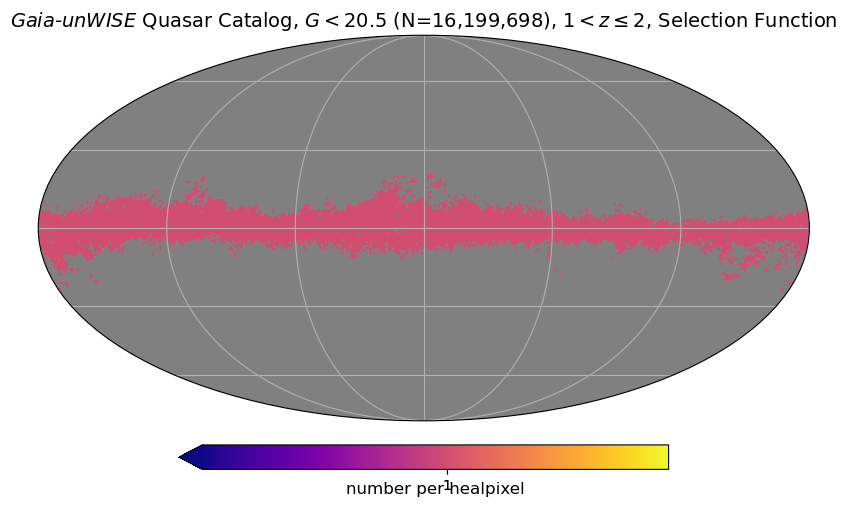

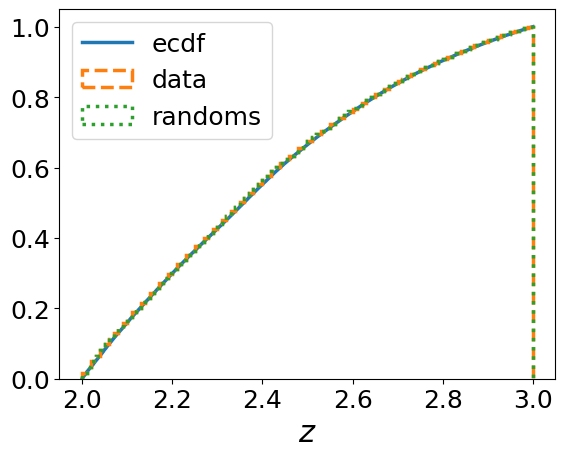

0.0
0.0
2 < z <= 3
data 9339
rand 6299
selfunc 6299
../data/randoms/random_G20.5_zmin3.0zmax4.0_25x.fits
G20.5_zmin3.0zmax4.0: 0.00              35630 vs 35630
25.022228459163625


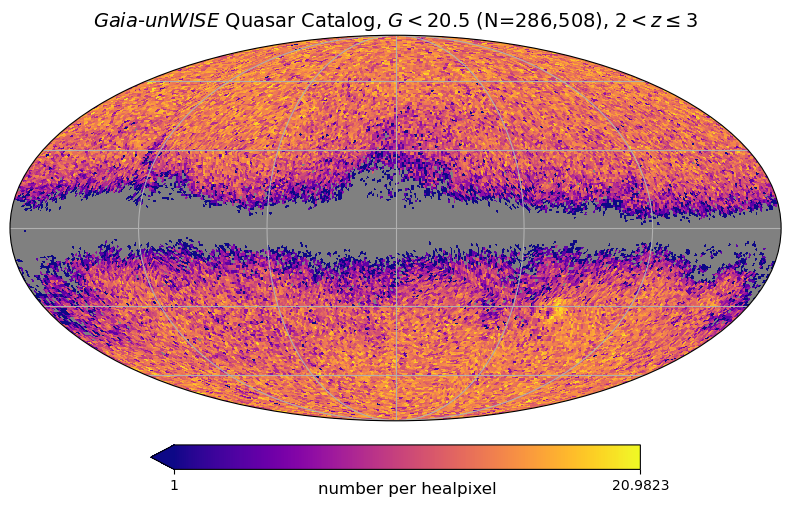

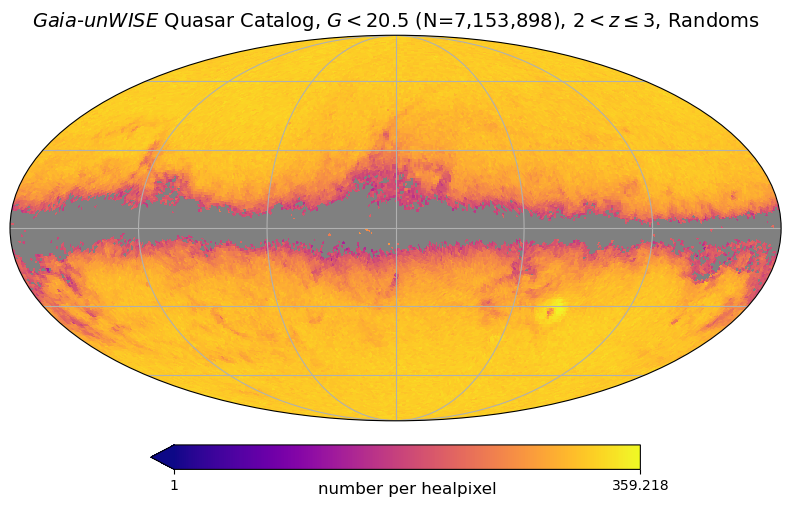

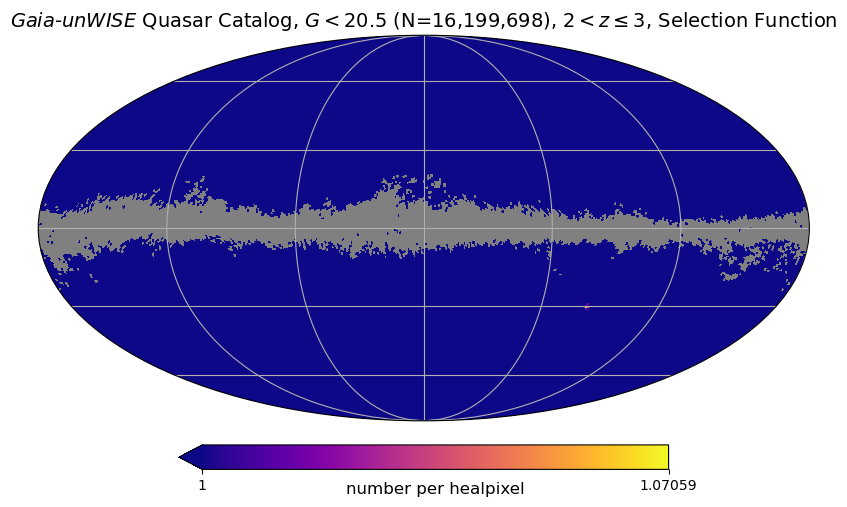

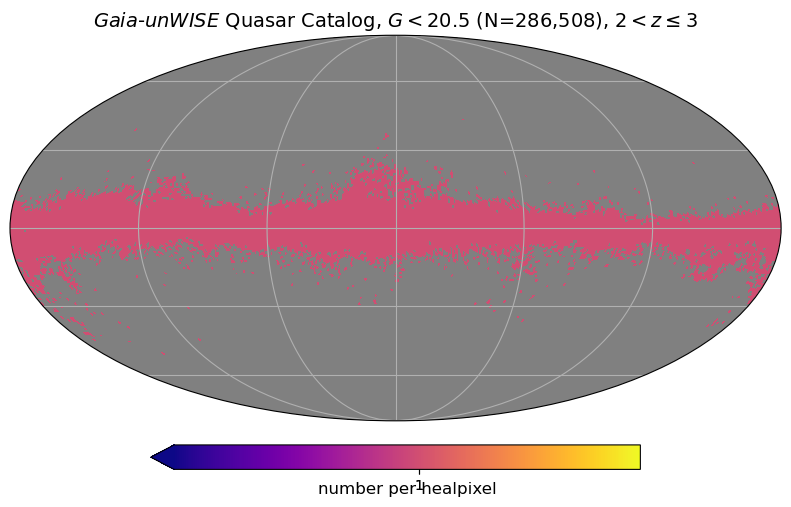

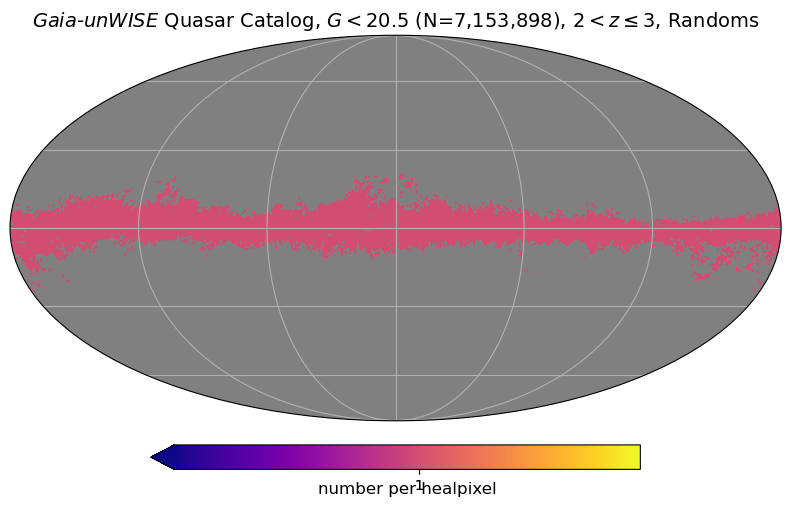

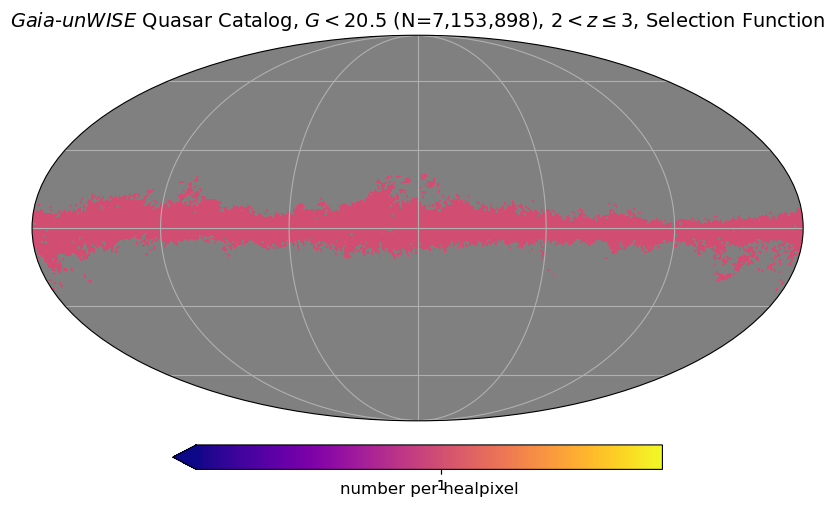

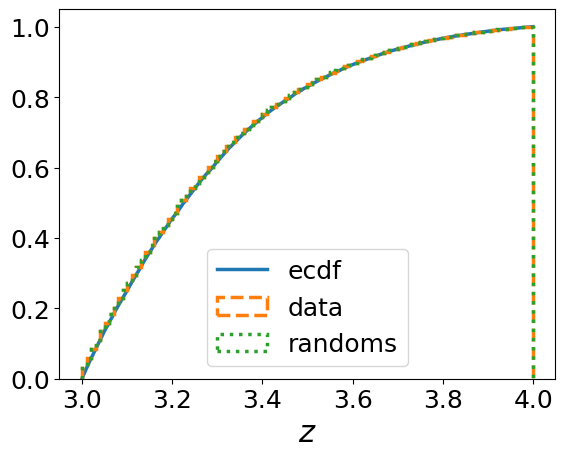

0.0
0.0
3 < z <= 4
data 26942
rand 6299
selfunc 6299


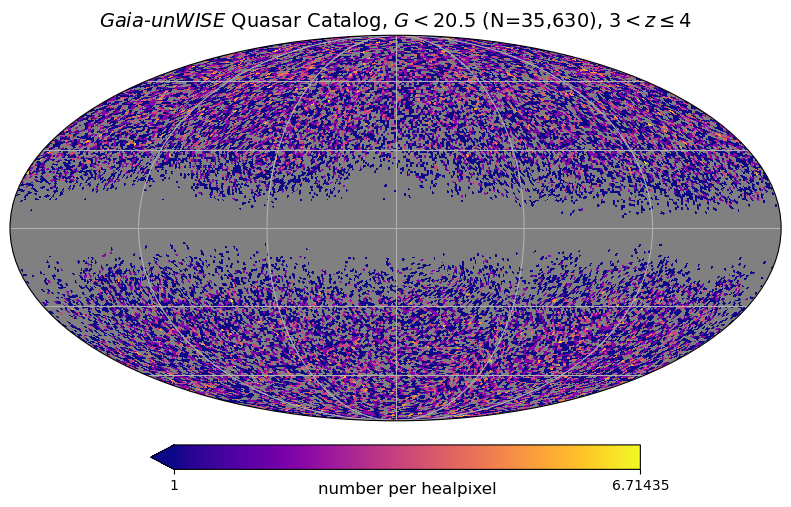

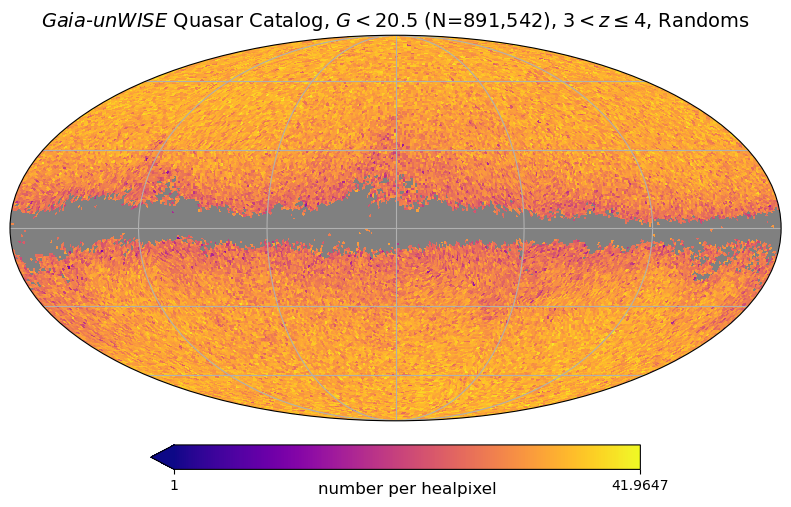

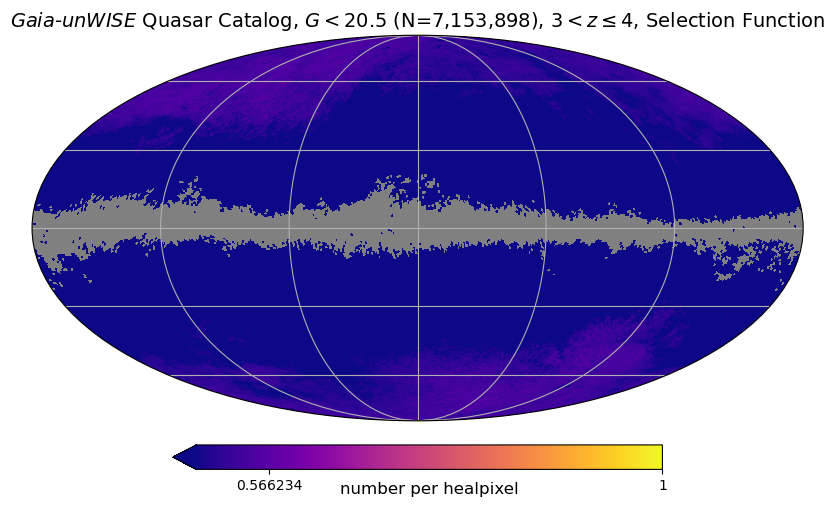

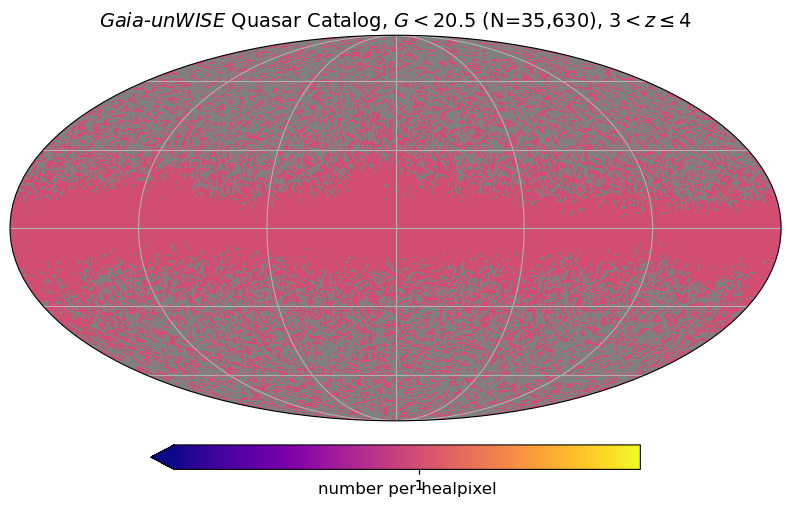

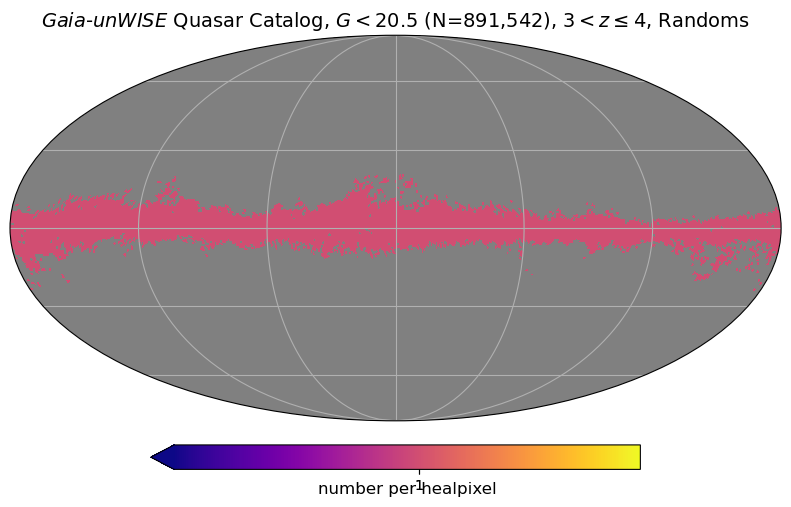

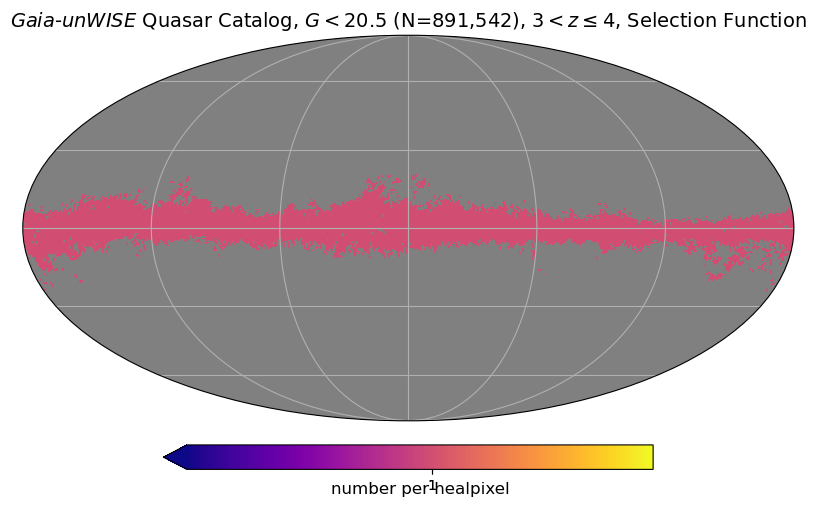

In [43]:
cmap_map = 'plasma'
name_catalog='$Gaia$-$unWISE$ Quasar Catalog'

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, map_gcatlo, map_randlo, pixel_indices_gcatlo, pixel_indices_randlo = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                                   tab_gcat_type = 'data', method = ['minmax'], 
                                                                                                   fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                                   plot = True, b = [0,0,0,0][j])
    # wp_debug, rpavg_debug, qq, qr = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0,
    #                                                   nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)

#     plt.figure()
#     plt.bar(np.arange(NPIX), map_randlo)
#     y = np.median(map_randlo)
#     plt.axhline(y, label = 'median={:.2f}'.format(y), color = 'red')
#     plt.xlabel('Pixels')
#     plt.ylabel('$N_{rand}$')
#     plt.ylim(0, 100)
#     plt.legend()
#     plt.show()

#     plt.bar(np.arange(NPIX), map_gcatlo)
#     y = np.median(map_gcatlo)
#     plt.axhline(y, label = 'median={:.2f}'.format(y), color = 'red')
#     plt.xlabel('Pixels')
#     plt.ylabel('$N_{data}$')
#     plt.ylim(0, 100)
#     plt.legend()
#     plt.show()

#     plt.figure()
#     ratio = map_randlo/map_gcatlo
#     plt.bar(np.arange(NPIX), ratio)
#     y = np.nanmedian(ratio)
#     plt.axhline(y, label = 'median={:.2f}'.format(y), color = 'red')
#     plt.axhline(25, label = '$fac_{rand}=25.00$', linestyle = '--', color = 'orange')
#     plt.xlabel('Pixels')
#     plt.ylabel('$N_{rand}/N_{data}$')
#     plt.ylim(0, 100)
#     plt.legend()
#     plt.show()
    
    print('{} < z <= {}'.format(j, j+1))
    print('data', len(np.where(map_gcatlo==0)[0]))
    print('rand', len(np.where(map_randlo==0)[0]))
    print('selfunc', len(np.where(selfunc_hi_bin0==0)[0]))
    
    # make map of quasar number counts
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_randhi_mask_bin0:,}), ${j}< z\leq{j+1}$, Selection Function'
    projview(selfunc_hi_bin0, title=title_gcatlo, norm='log', 
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 1, graticule=True)#, cbar_ticks=cbar_ticks)
    
    # show where the selfunc is zero
    map_gcatlo_copy = np.copy(map_gcatlo)
    map_gcatlo_copy[map_gcatlo_copy==0]=-1
    map_gcatlo_copy[map_gcatlo_copy>0]=0
    N_datahi_mask_bin0 = len(tab_datahi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_datahi_mask_bin0:,}), ${j}< z\leq{j+1}$'
    projview(-map_gcatlo_copy, title=title_gcatlo, norm='log', 
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 1, graticule=True) #, cbar_ticks=cbar_ticks)

    # make map of quasar number counts
    map_randlo_copy = np.copy(map_randlo)
    map_randlo_copy[map_randlo_copy==0]=-1
    map_randlo_copy[map_randlo_copy>0]=0
    N_randhi_mask_bin0 = len(tab_randhi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_randhi_mask_bin0:,}), ${j}< z\leq{j+1}$, Randoms'
    projview(-map_randlo_copy, title=title_gcatlo, norm='log', 
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 1, graticule=True)#, cbar_ticks=cbar_ticks)
    
    # make map of quasar number counts
    selfunc_hi_bin0_copy = np.copy(selfunc_hi_bin0)
    selfunc_hi_bin0_copy[selfunc_hi_bin0_copy==0]=-1
    selfunc_hi_bin0_copy[selfunc_hi_bin0_copy>0]=0
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_randhi_mask_bin0:,}), ${j}< z\leq{j+1}$, Selection Function'
    projview(-selfunc_hi_bin0_copy, title=title_gcatlo, norm='log', 
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 1, graticule=True)#, cbar_ticks=cbar_ticks)

In [20]:
# check if the pixels in the final random quasar map are zero where i expect them to be zero
pixel_indices_gcatlo_zero = pixel_indices_gcatlo[selfunc_hi_bin0[pixel_indices_gcatlo]==0]
pixel_indices_randlo_zero = pixel_indices_randlo[selfunc_hi_bin0[pixel_indices_randlo]==0]

../data/randoms/random_G20.5_zmin0.0zmax1.0_zero_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.990565339647773


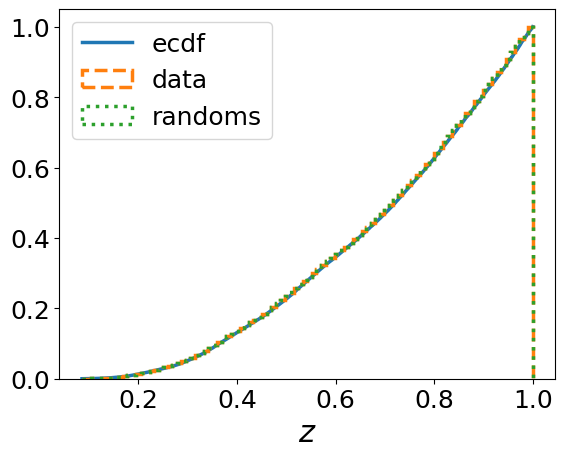

0.0
0.0
0 < z <= 1
data 7076
rand 7076
selfunc 6299
../data/randoms/random_G20.5_zmin1.0zmax2.0_zero_25x.fits
G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196
24.994950601361317


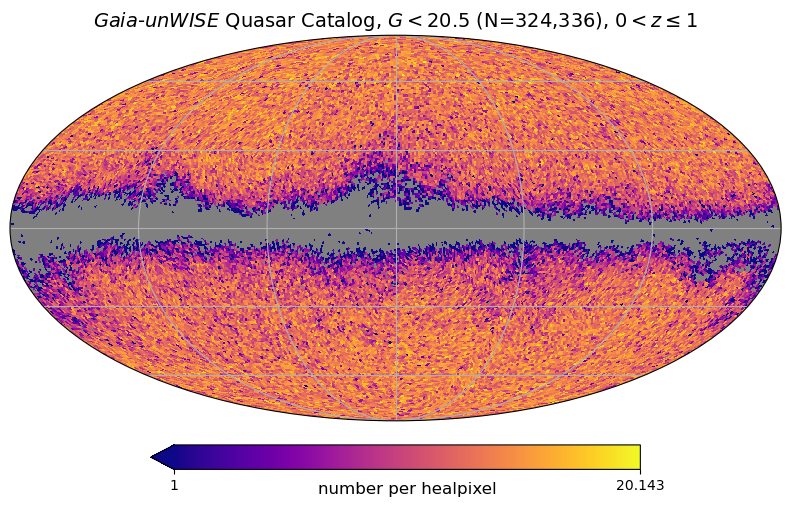

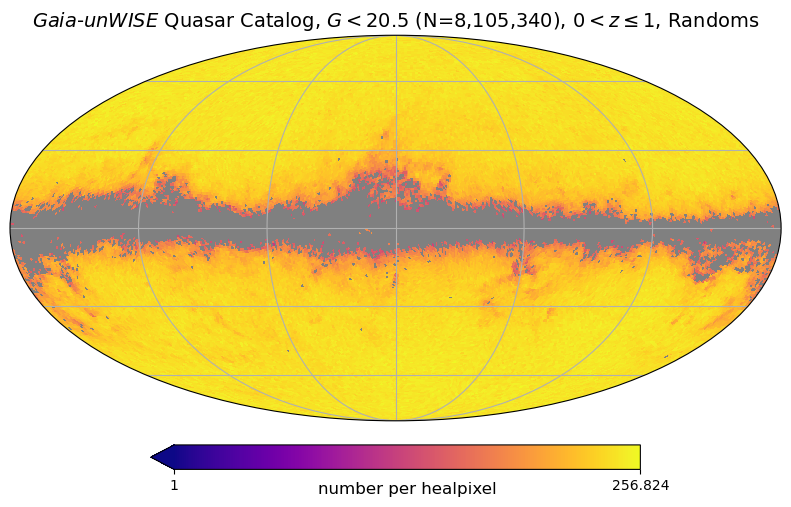

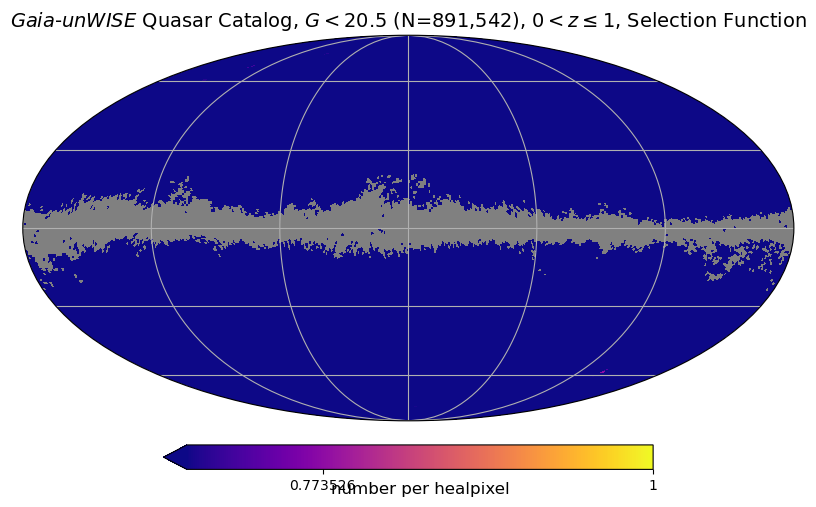

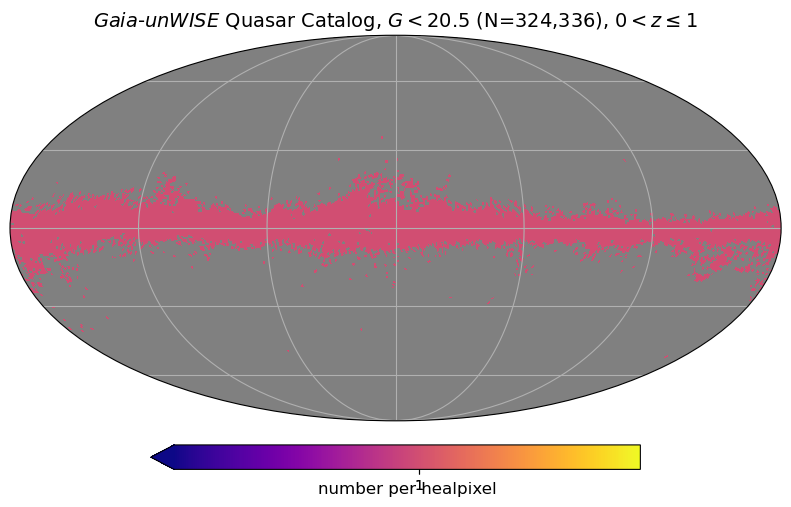

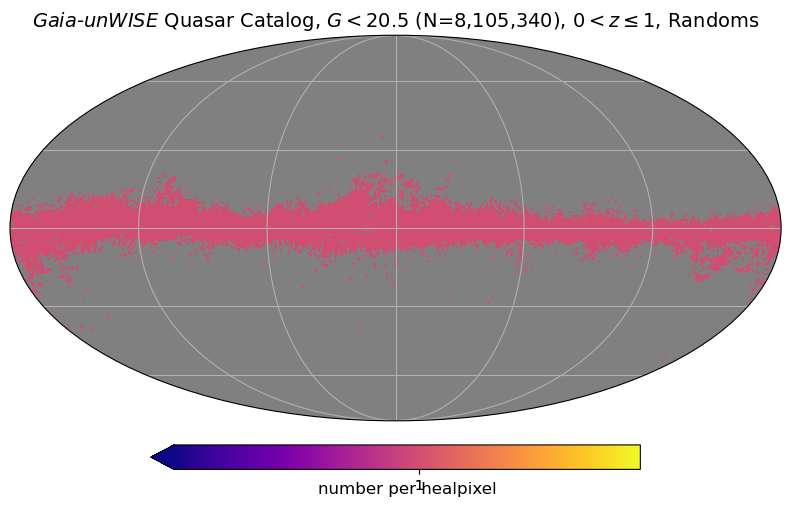

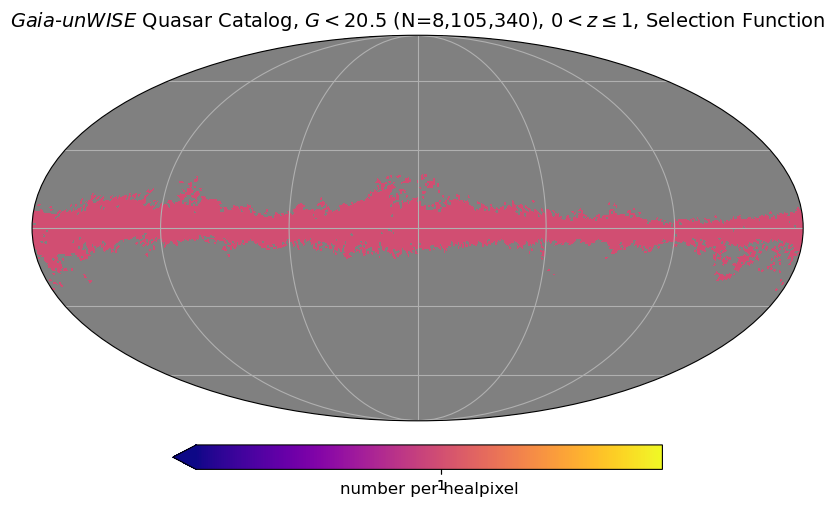

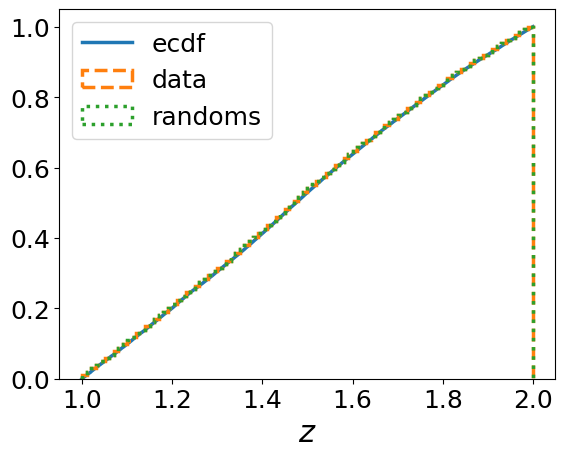

0.0
0.0
1 < z <= 2
data 7388
rand 7388
selfunc 6299
../data/randoms/random_G20.5_zmin2.0zmax3.0_zero_25x.fits
G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508
24.9659939687548


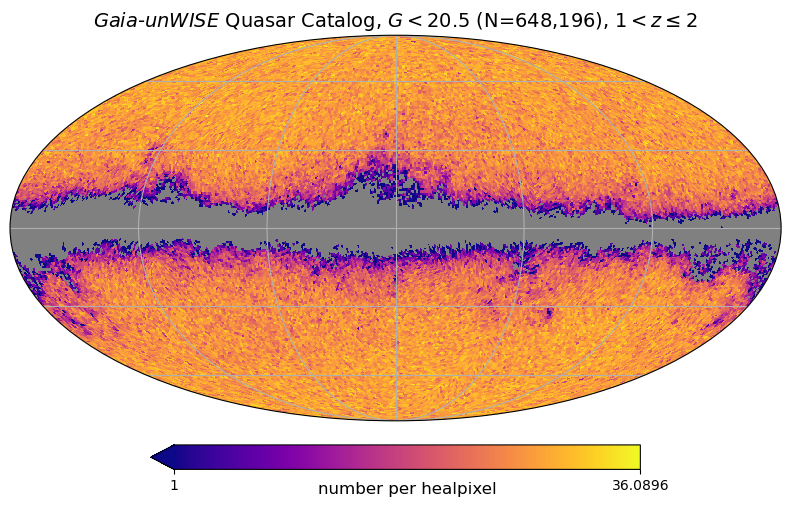

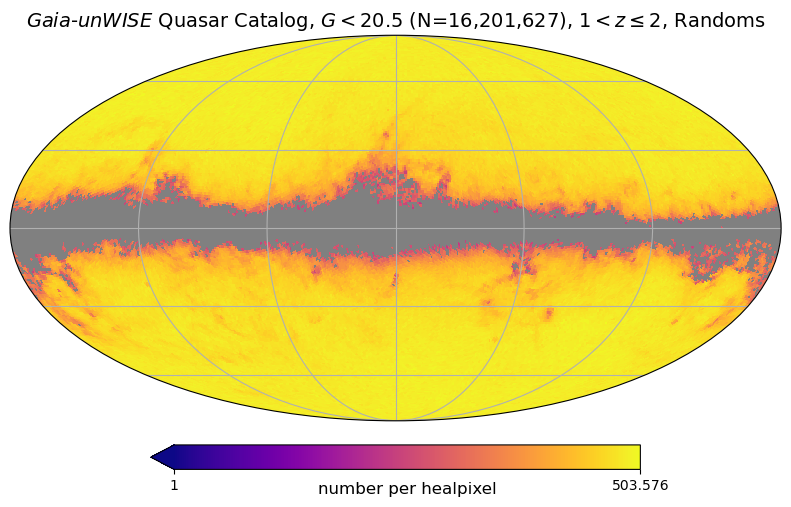

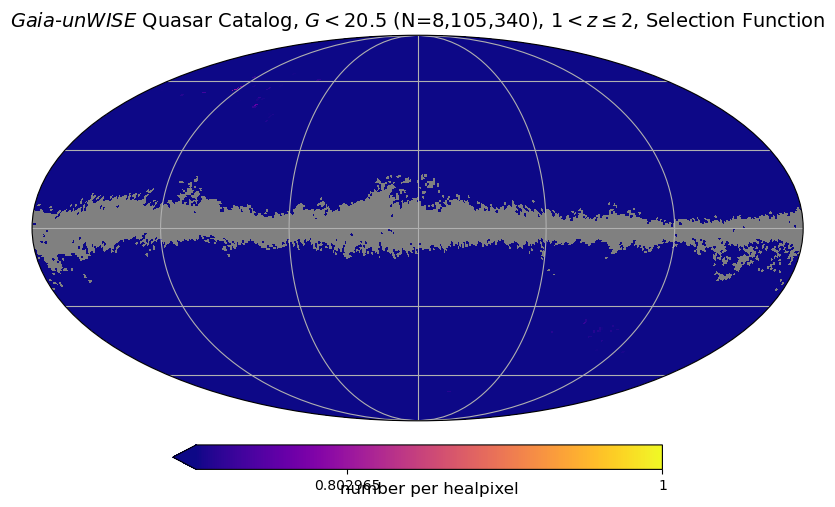

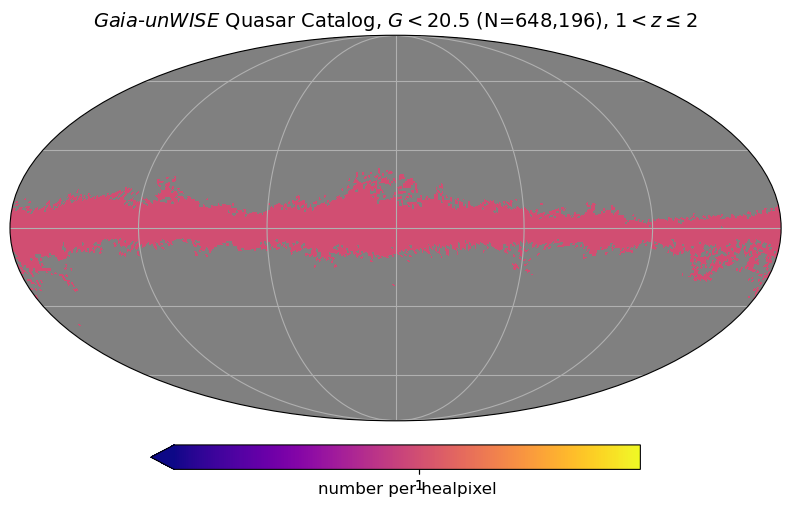

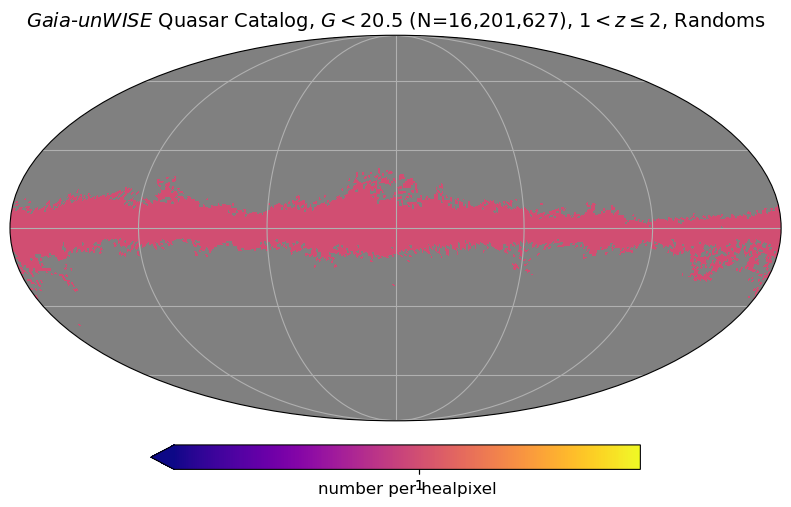

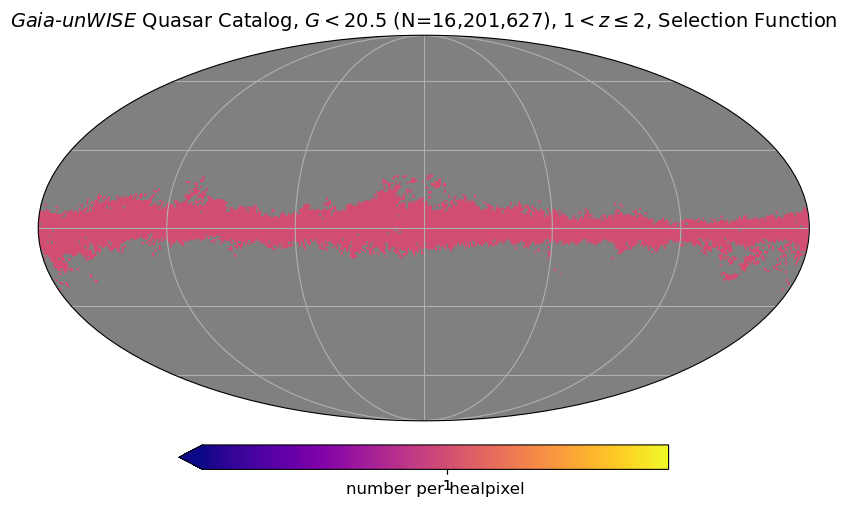

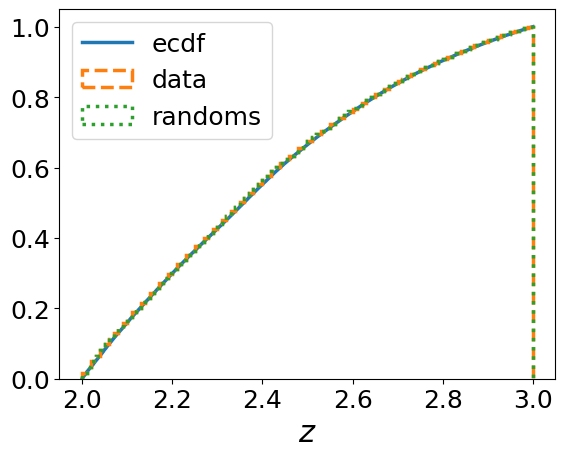

0.0
0.0
2 < z <= 3
data 9339
rand 9339
selfunc 6299
../data/randoms/random_G20.5_zmin3.0zmax4.0_zero_25x.fits
G20.5_zmin3.0zmax4.0: 0.00              35630 vs 35630
25.008167274768454


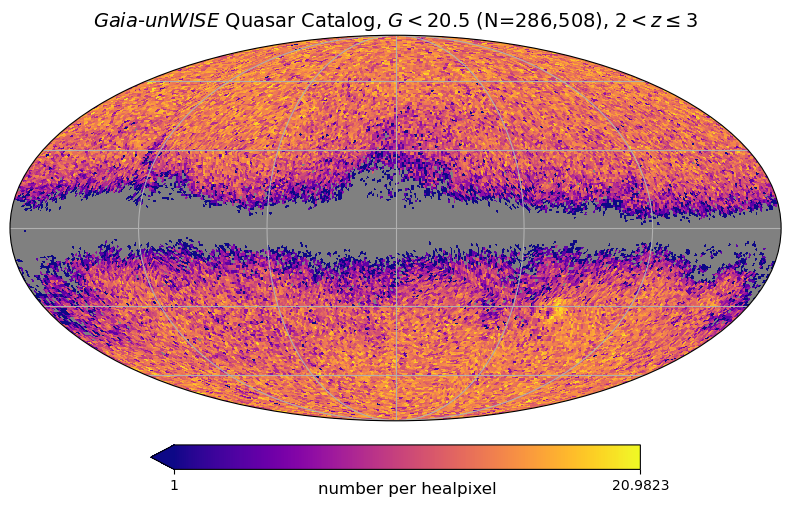

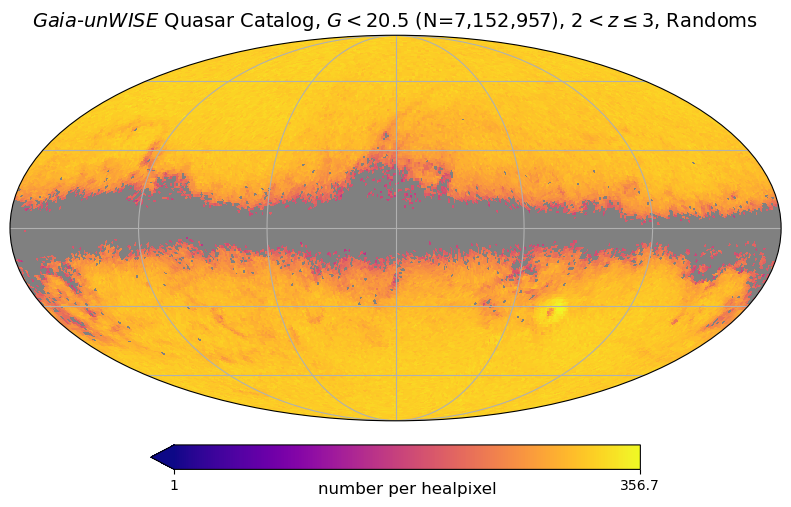

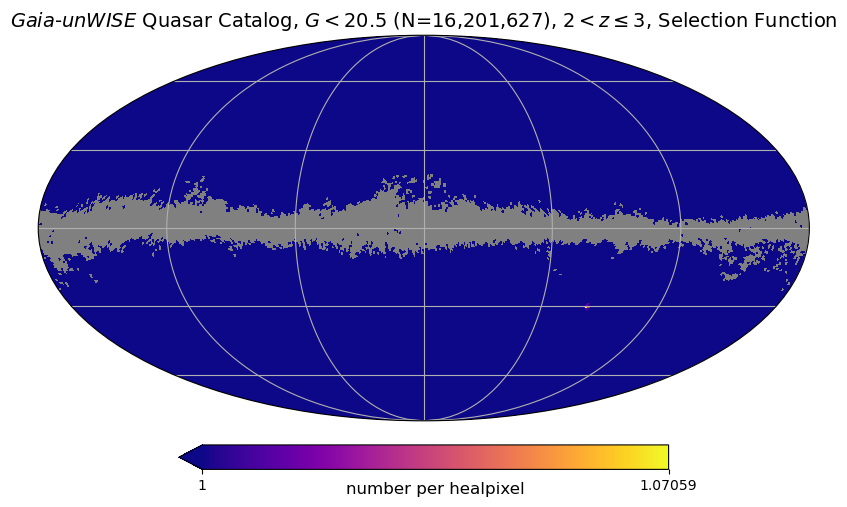

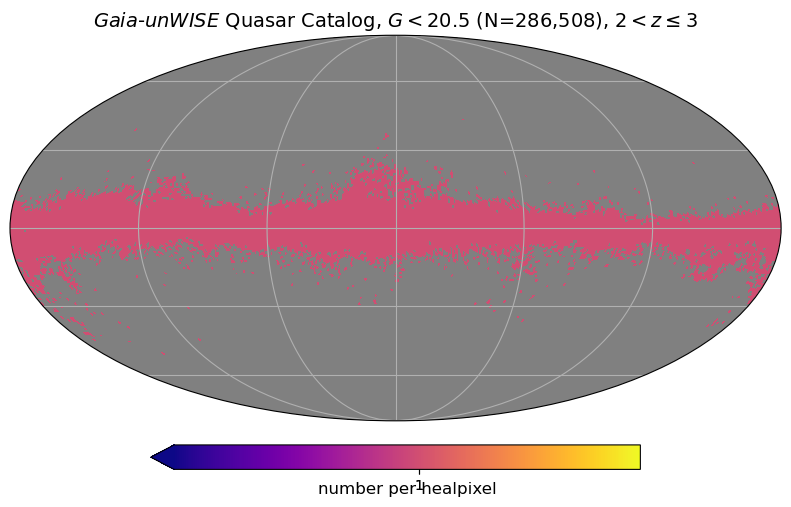

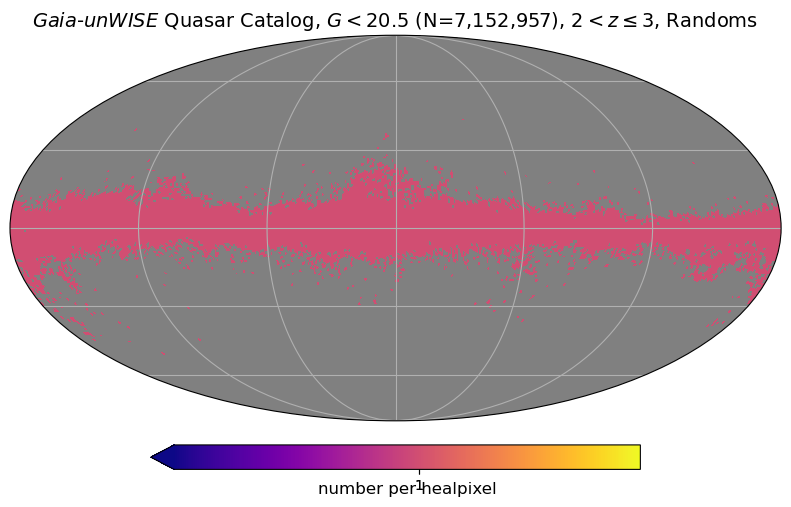

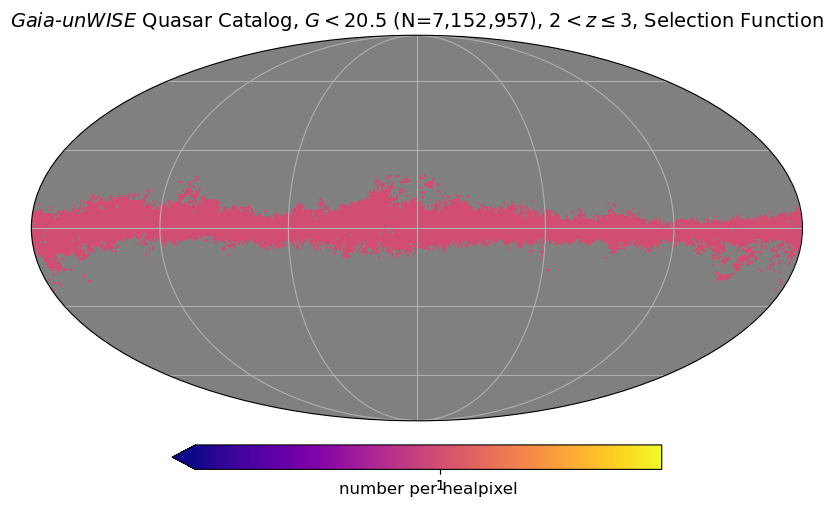

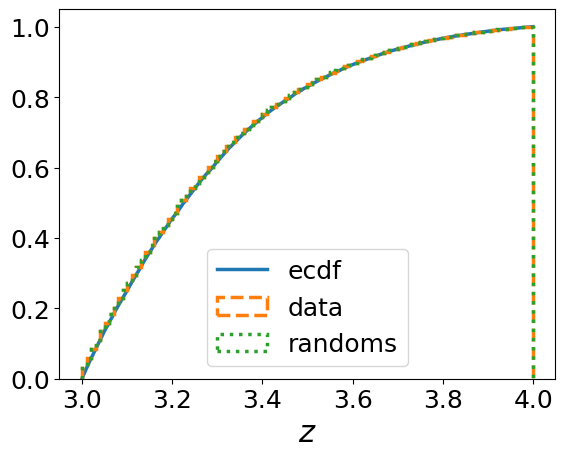

0.0
0.0
3 < z <= 4
data 26942
rand 26942
selfunc 6299


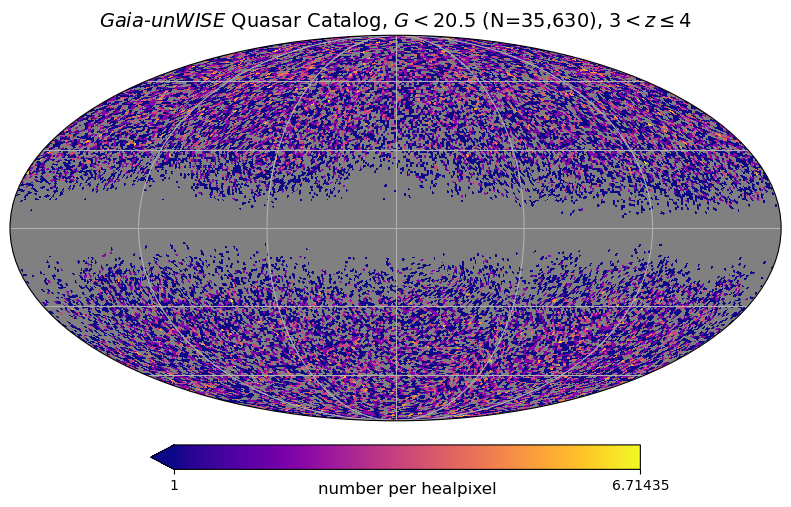

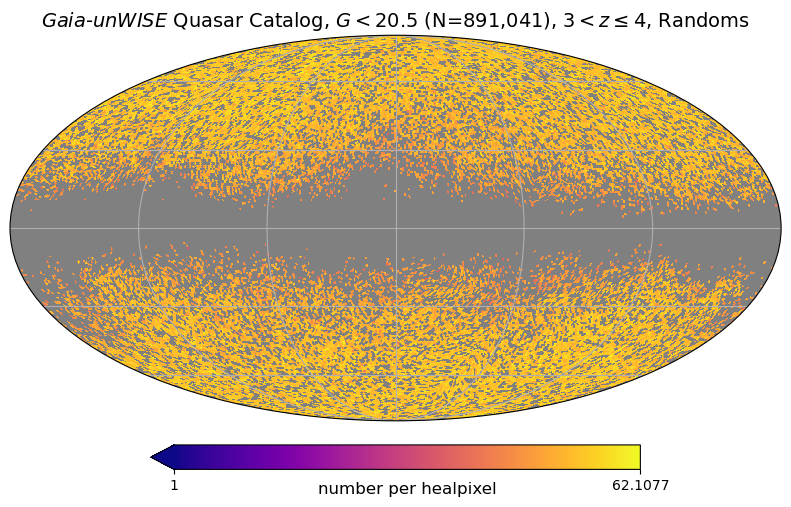

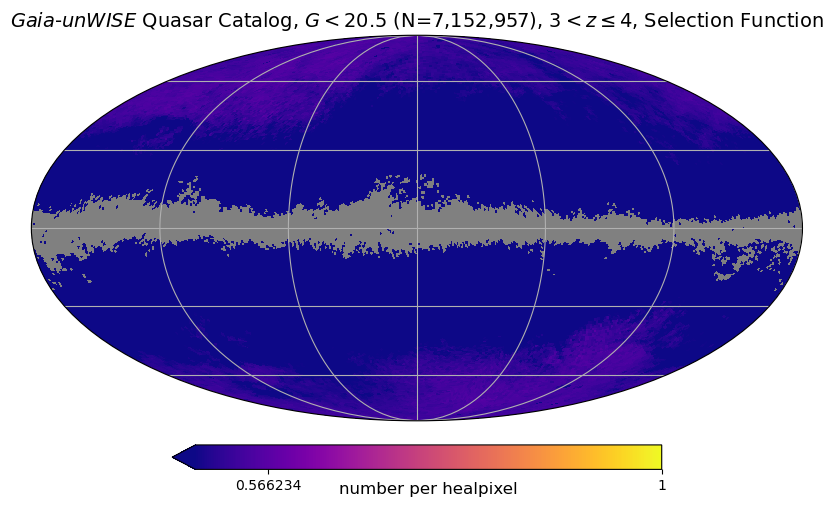

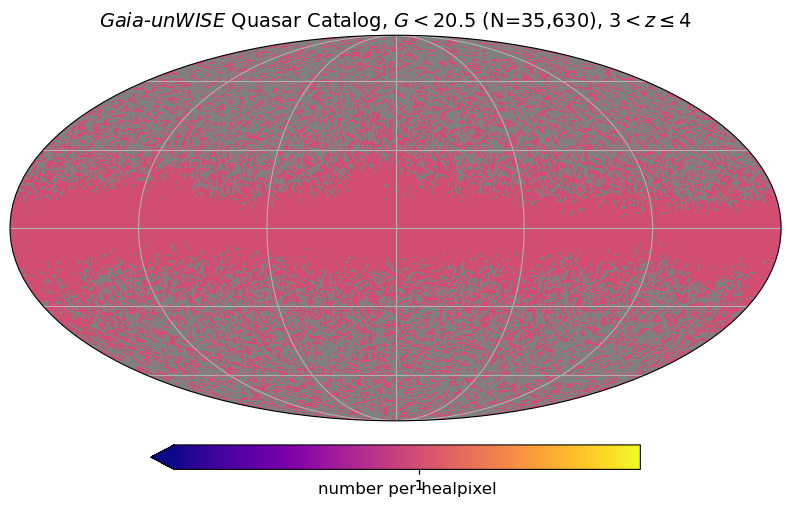

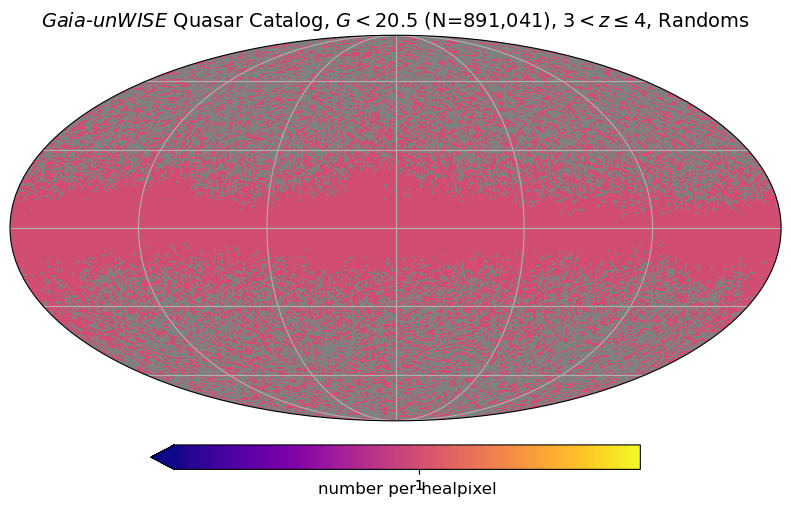

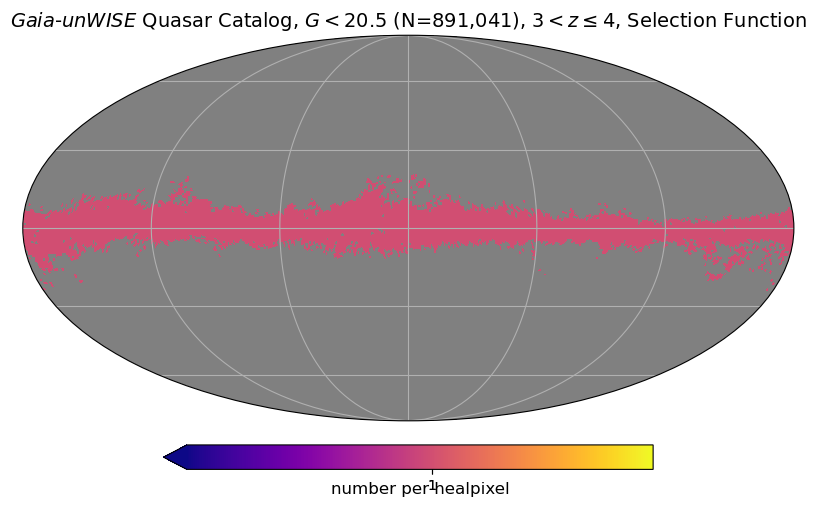

In [44]:
cmap_map = 'plasma'
name_catalog='$Gaia$-$unWISE$ Quasar Catalog'
# wp_debug = []
# rpavg_debug = []

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin02, map_gcatlo2, map_randlo2, pixel_indices_gcatlo2, pixel_indices_randlo2 = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins], allsky = '_zero',
                                                                                                   tab_gcat_type = 'data', method = ['minmax'], 
                                                                                                   fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                                   plot = True, b = [0,0,0,0][j])
    # wp_debug_i, rpavg_debug_i, qq, qr = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0,
    #                                                   nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
    # # wp_debug.append(wp_debug_i)
    # rpavg_debug.append(rpavg_debug_i)
    
#     plt.figure()
#     plt.bar(np.arange(NPIX), map_randlo2)
#     y = np.median(map_randlo2)
#     plt.axhline(y, label = 'median={:.2f}'.format(y), color = 'red')
#     plt.xlabel('Pixels')
#     plt.ylabel('$N_{rand}$')
#     plt.legend()
#     plt.ylim(0, 100)
#     plt.show()

#     plt.bar(np.arange(NPIX), map_gcatlo2)
#     y = np.median(map_gcatlo2)
#     plt.axhline(y, label = 'median={:.2f}'.format(y), color = 'red')
#     plt.xlabel('Pixels')
#     plt.ylabel('$N_{data}$')
#     plt.legend()
#     plt.ylim(0, 100)
#     plt.show()

#     plt.figure()
#     ratio = map_randlo2/map_gcatlo2
#     plt.bar(np.arange(NPIX), ratio)
#     y = np.nanmedian(ratio)
#     plt.axhline(y, label = 'median={:.2f}'.format(y), color = 'red')
#     plt.axhline(25, label = '$fac_{rand}=25.00$', linestyle = '--', color = 'orange')
#     plt.xlabel('Pixels')
#     plt.ylabel('$N_{rand}/N_{data}$')
#     plt.legend()
#     plt.ylim(0, 100)
#     plt.show()
    
    print('{} < z <= {}'.format(j, j+1))
    print('data', len(np.where(map_gcatlo2==0)[0]))
    print('rand', len(np.where(map_randlo2==0)[0]))
    print('selfunc', len(np.where(selfunc_hi_bin02==0)[0]))

    # make map of quasar number counts
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_randhi_mask_bin0:,}), ${j}< z\leq{j+1}$, Selection Function'
    projview(selfunc_hi_bin02, title=title_gcatlo, norm='log', 
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 1, graticule=True)#, cbar_ticks=cbar_ticks)
    
    # show where the selfunc is zero
    map_gcatlo_copy = np.copy(map_gcatlo2)
    map_gcatlo_copy[map_gcatlo_copy==0]=-1
    map_gcatlo_copy[map_gcatlo_copy>0]=0
    N_datahi_mask_bin0 = len(tab_datahi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_datahi_mask_bin0:,}), ${j}< z\leq{j+1}$'
    projview(-map_gcatlo_copy, title=title_gcatlo, norm='log', 
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 1, graticule=True) #, cbar_ticks=cbar_ticks)

    # make map of quasar number counts
    map_randlo_copy = np.copy(map_randlo2)
    map_randlo_copy[map_randlo_copy==0]=-1
    map_randlo_copy[map_randlo_copy>0]=0
    N_randhi_mask_bin0 = len(tab_randhi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_randhi_mask_bin0:,}), ${j}< z\leq{j+1}$, Randoms'
    projview(-map_randlo_copy, title=title_gcatlo, norm='log', 
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 1, graticule=True)#, cbar_ticks=cbar_ticks)
    
    # make map of quasar number counts
    selfunc_hi_bin0_copy = np.copy(selfunc_hi_bin02)
    selfunc_hi_bin0_copy[selfunc_hi_bin0_copy==0]=-1
    selfunc_hi_bin0_copy[selfunc_hi_bin0_copy>0]=0
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_randhi_mask_bin0:,}), ${j}< z\leq{j+1}$, Selection Function'
    projview(-selfunc_hi_bin0_copy, title=title_gcatlo, norm='log', 
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 1, graticule=True)#, cbar_ticks=cbar_ticks)

../data/maps/selection_function_NSIDE64_G20.5_zmin0.0zmax1.0.fits
../data/randoms/random_G20.5_zmin0.0zmax1.0_zero_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.990565339647773


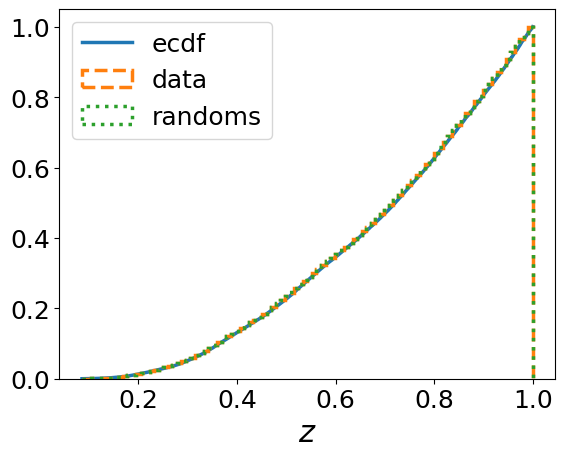

0.0
0.0


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0 < z <= 1
data 7076
rand 7076
selfunc 6299
../data/maps/selection_function_NSIDE64_G20.5_zmin1.0zmax2.0.fits
../data/randoms/random_G20.5_zmin1.0zmax2.0_zero_25x.fits
G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196
24.994950601361317


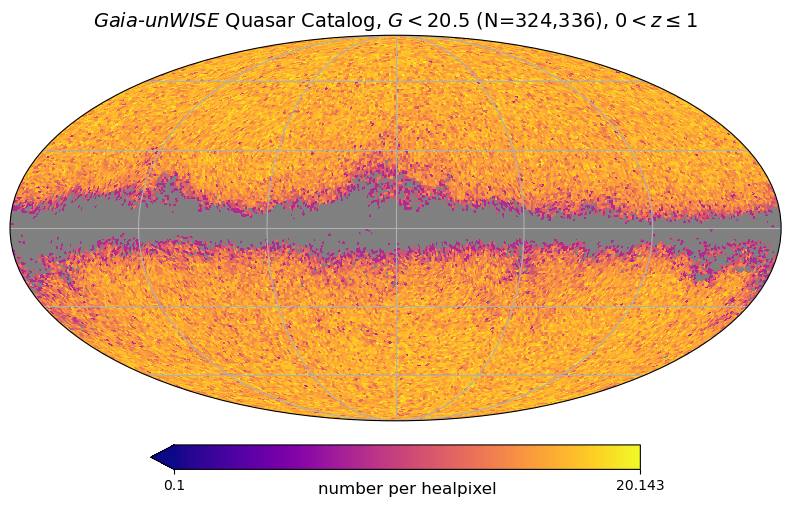

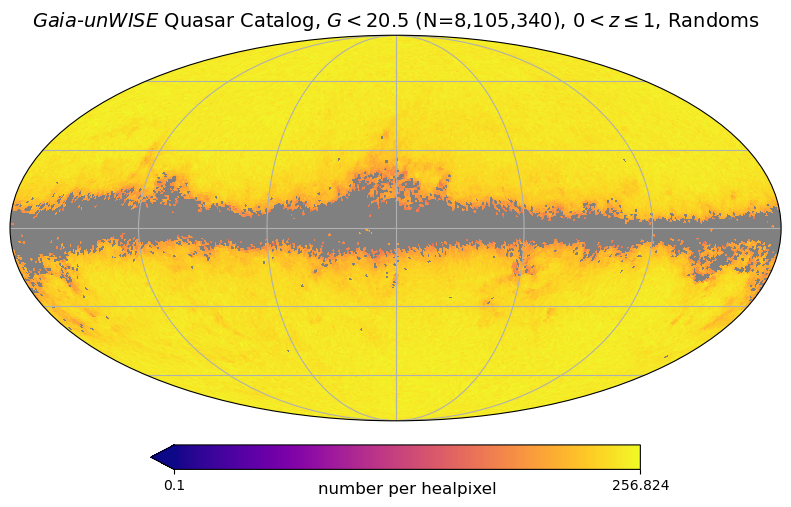

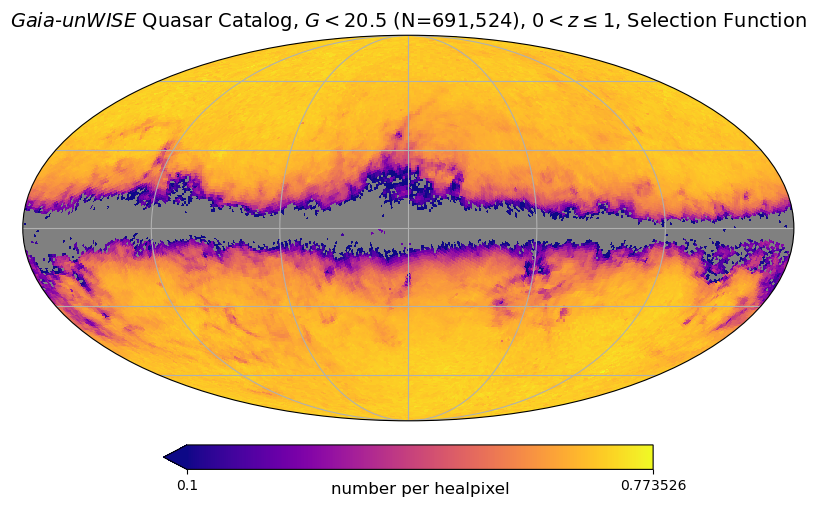

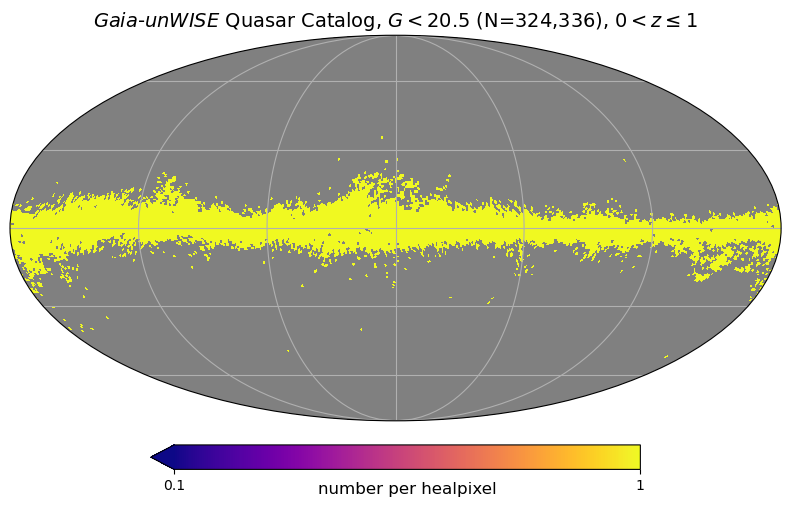

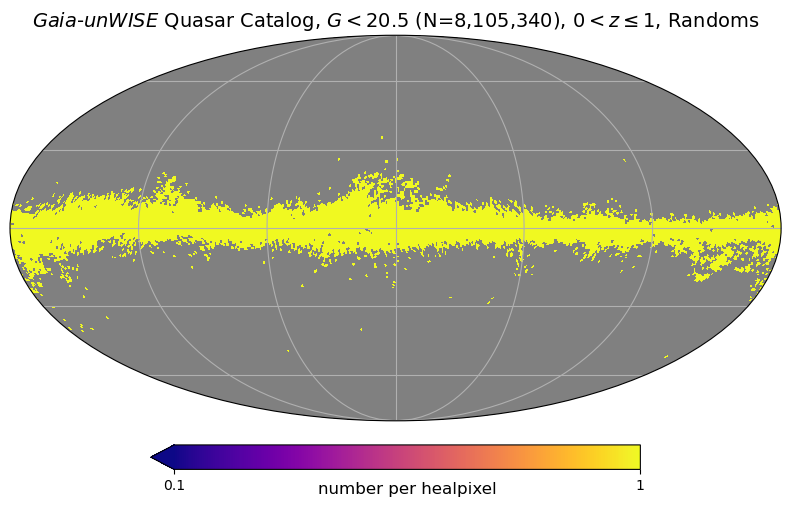

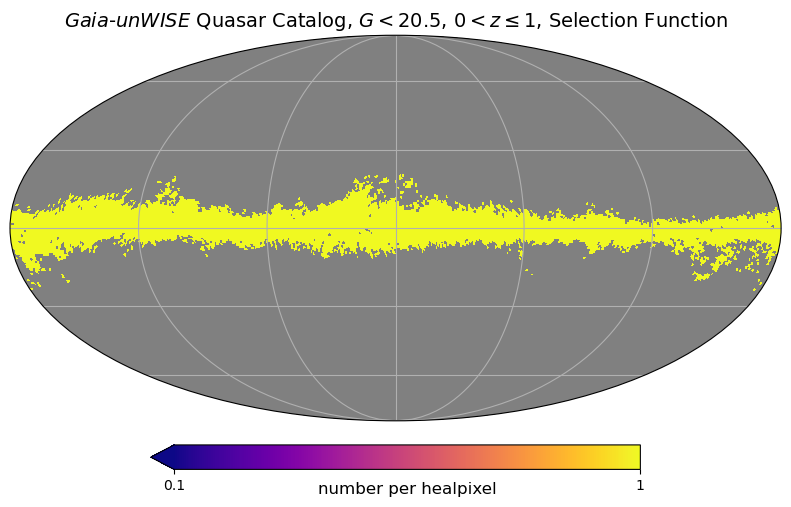

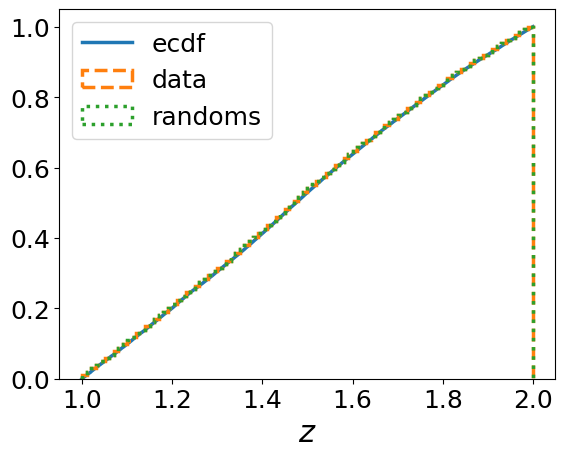

0.0
0.0


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


1 < z <= 2
data 7388
rand 7388
selfunc 6299
../data/maps/selection_function_NSIDE64_G20.5_zmin2.0zmax3.0.fits
../data/randoms/random_G20.5_zmin2.0zmax3.0_zero_25x.fits
G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508
24.9659939687548


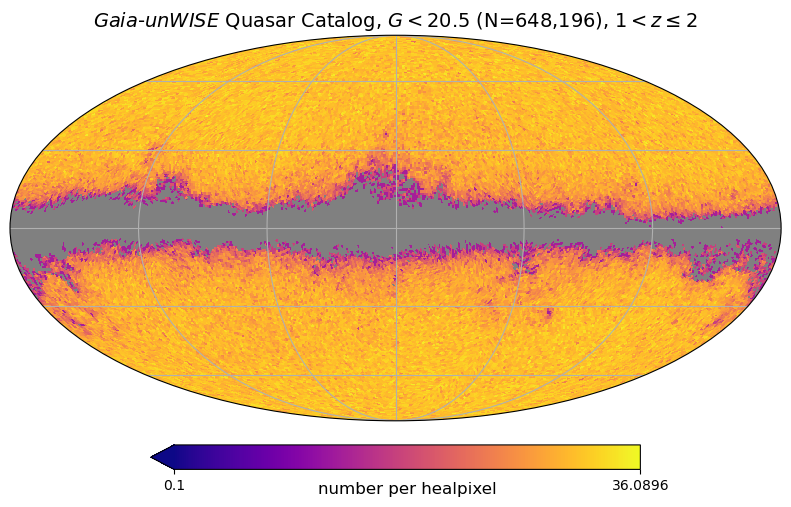

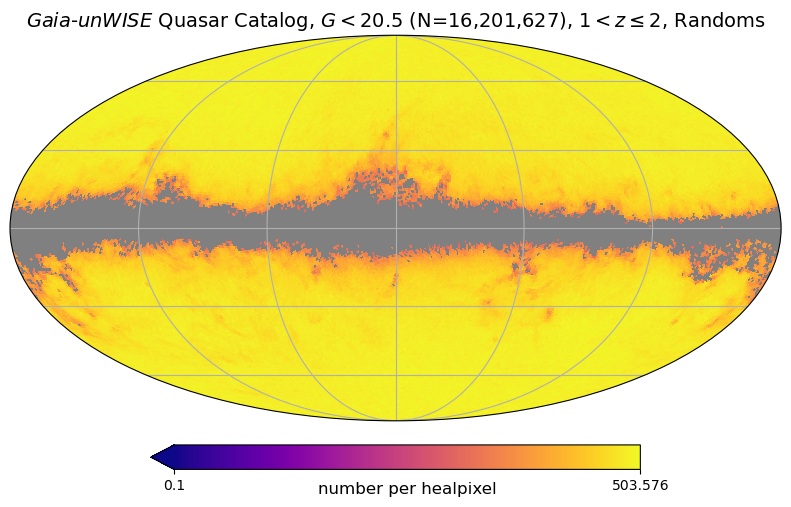

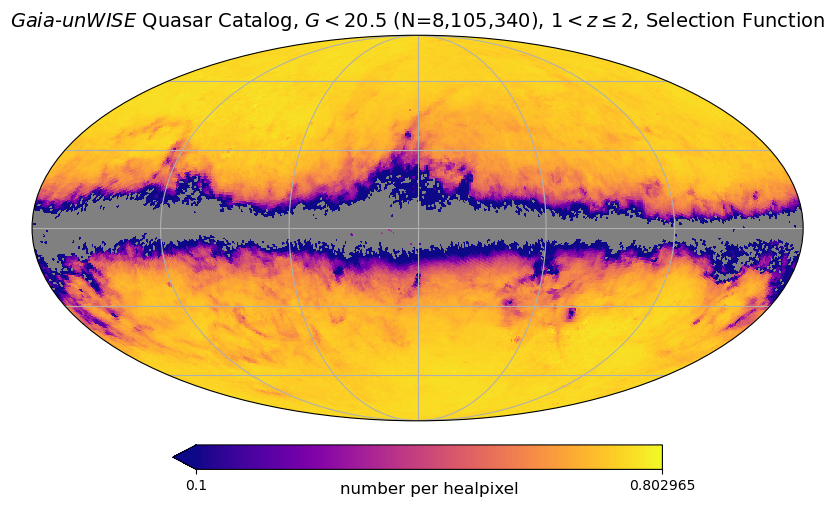

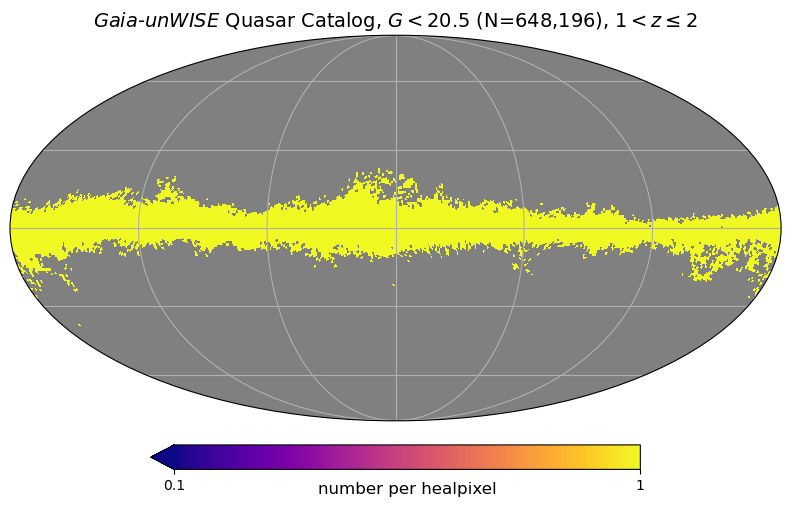

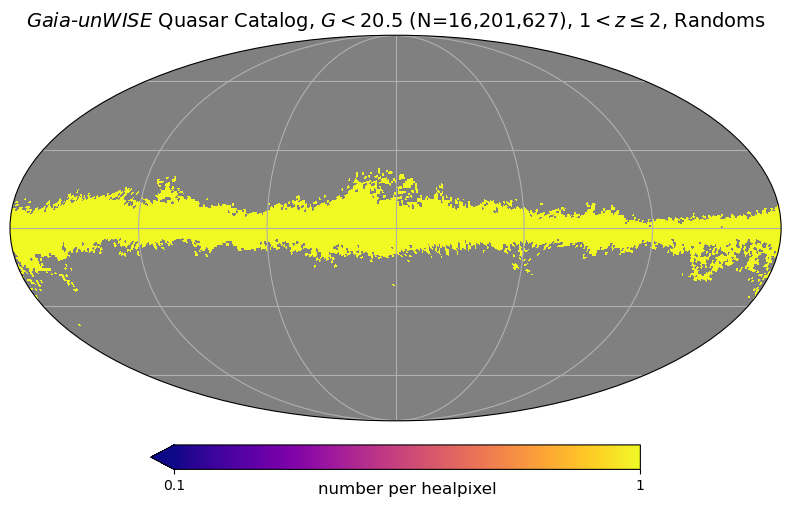

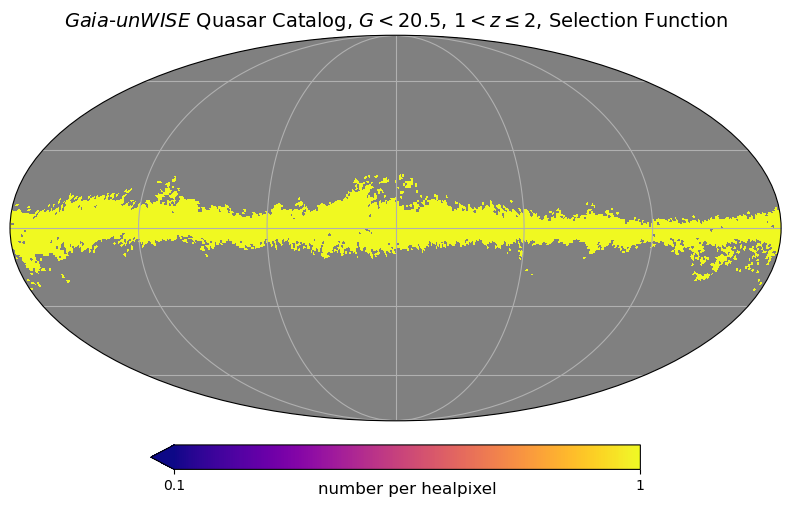

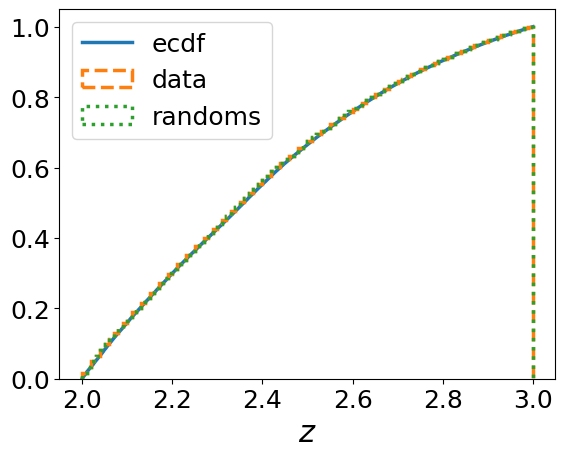

0.0
0.0


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


2 < z <= 3
data 9339
rand 9339
selfunc 6299
../data/maps/selection_function_NSIDE64_G20.5_zmin3.0zmax4.0.fits
../data/randoms/random_G20.5_zmin3.0zmax4.0_zero_25x.fits
G20.5_zmin3.0zmax4.0: 0.23              27584 vs 35630
25.069750580046403


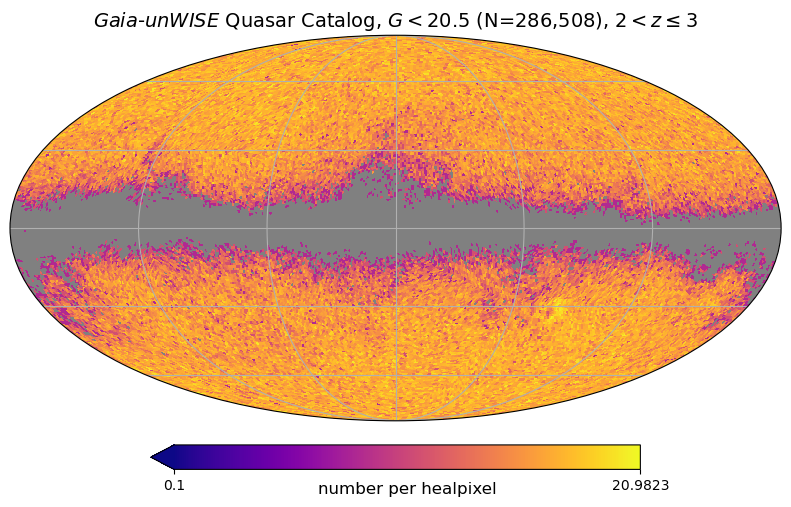

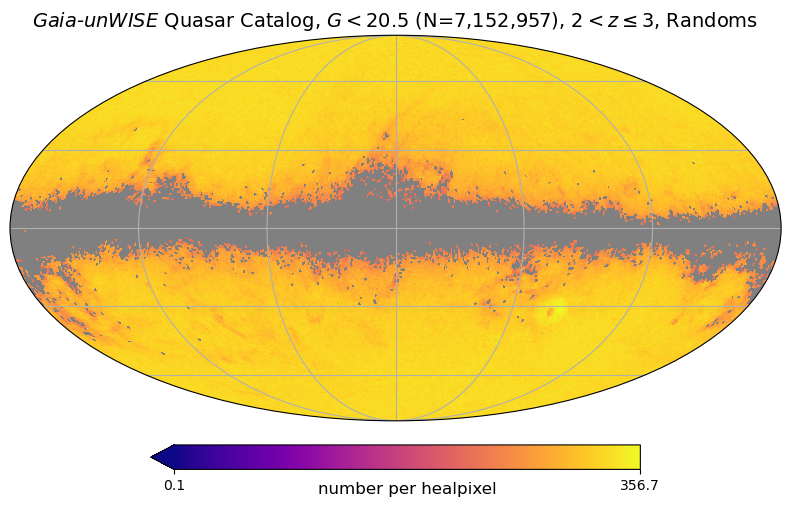

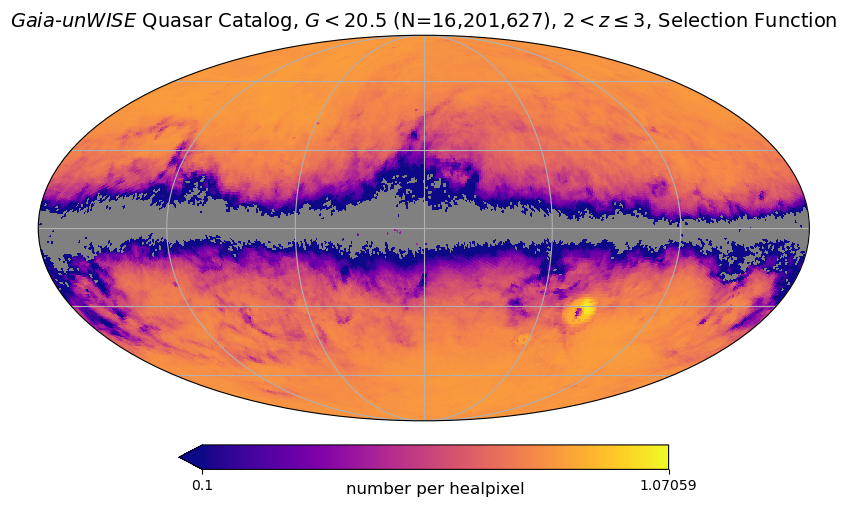

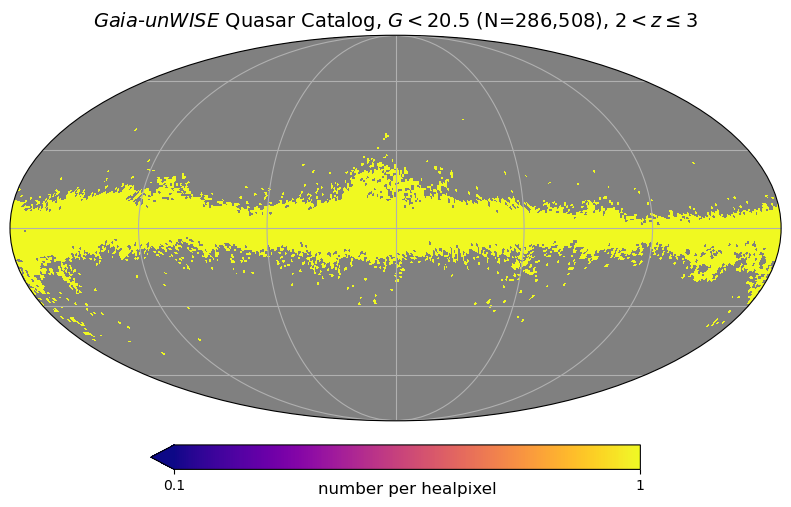

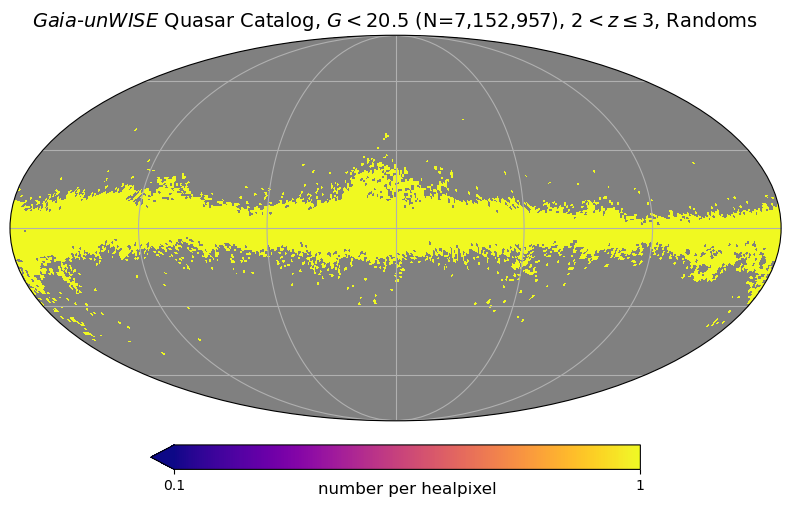

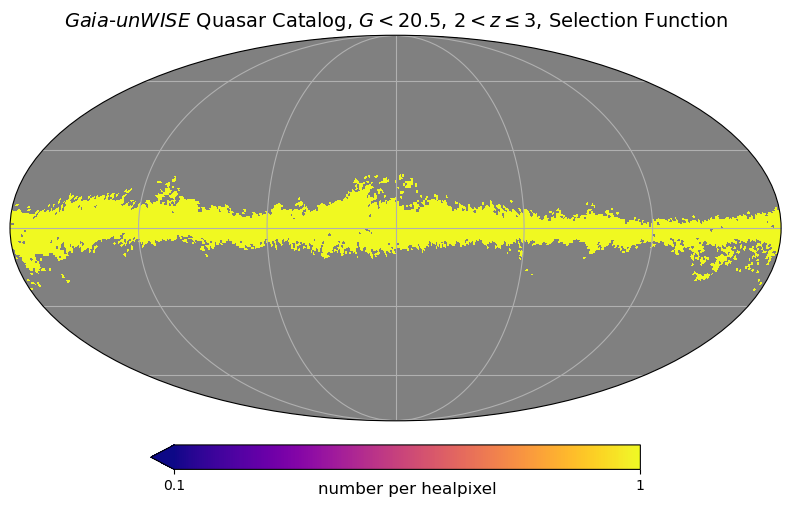

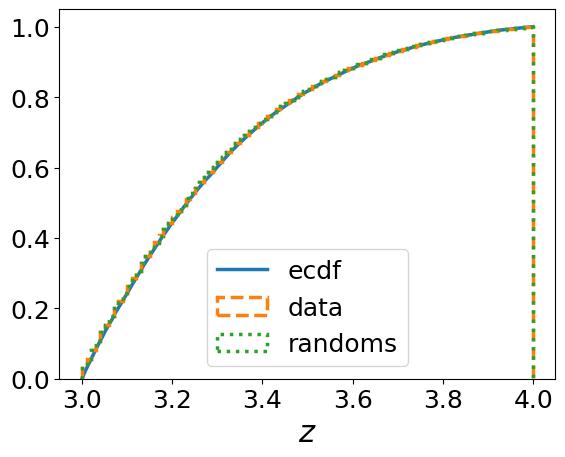

0.0
0.0


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


3 < z <= 4
data 32787
rand 32612
selfunc 6299


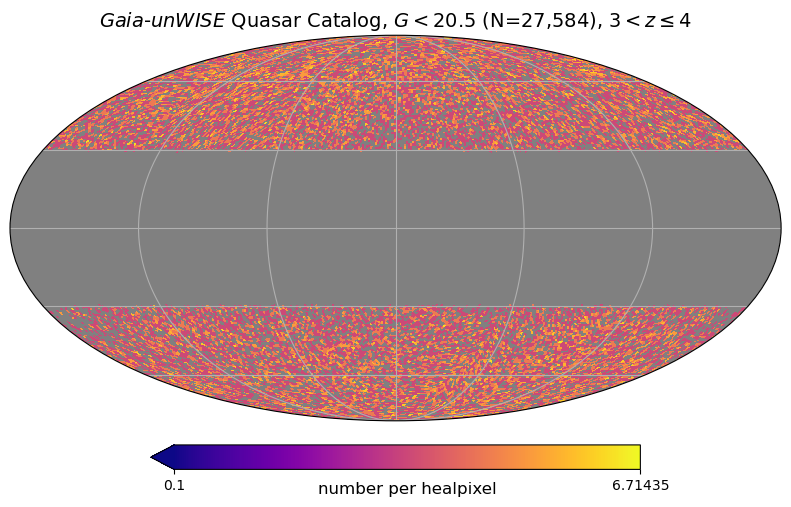

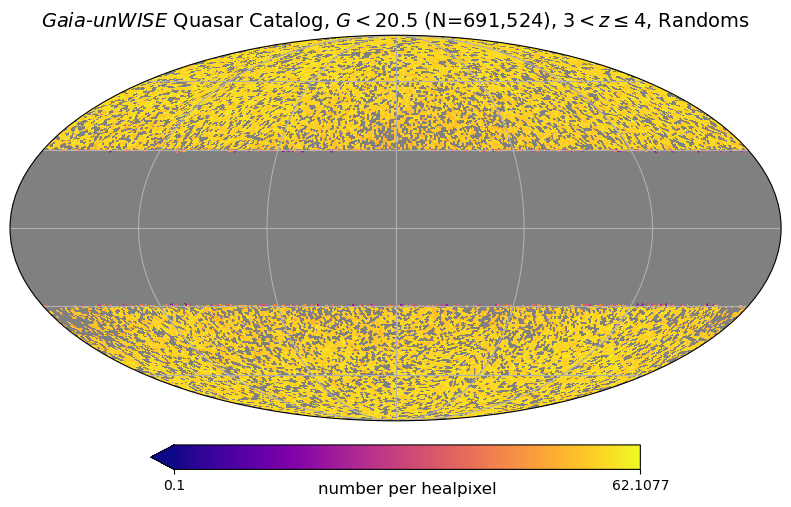

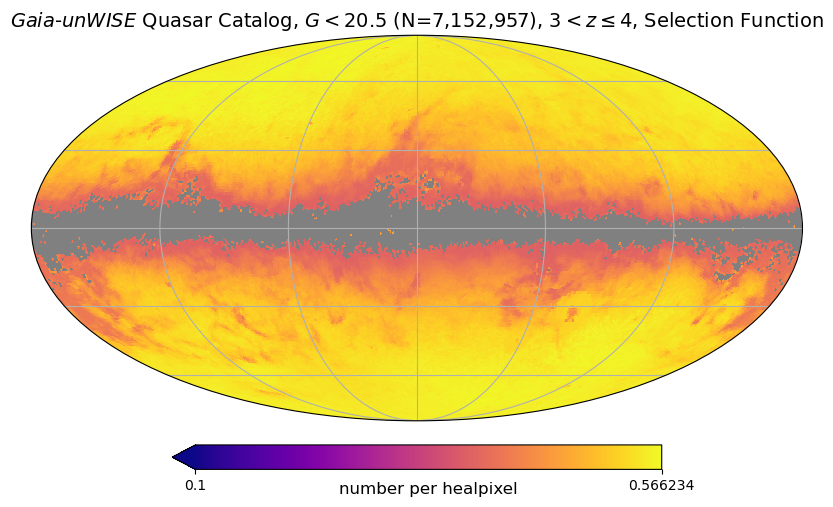

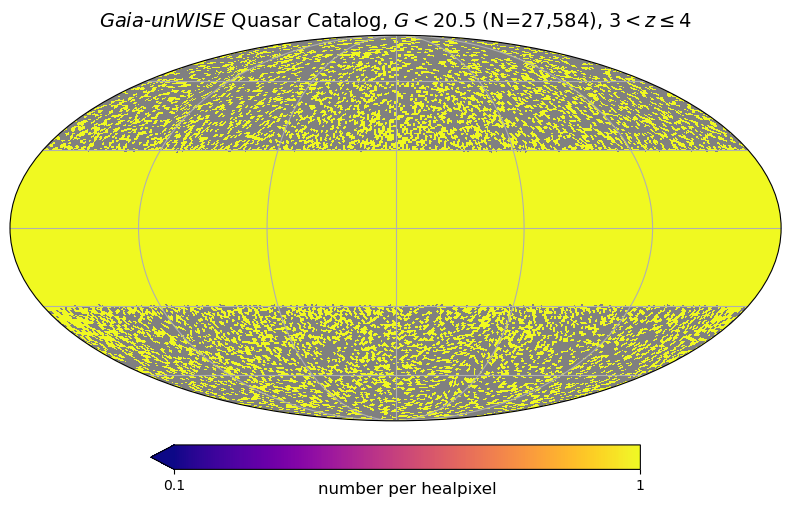

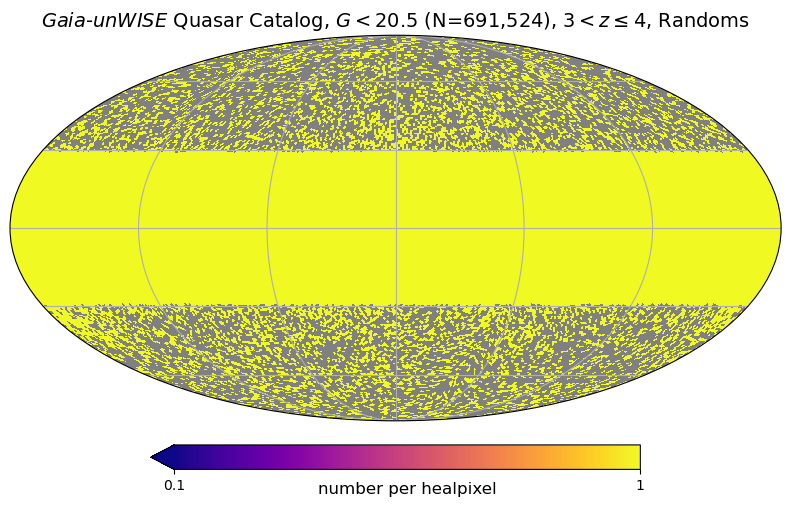

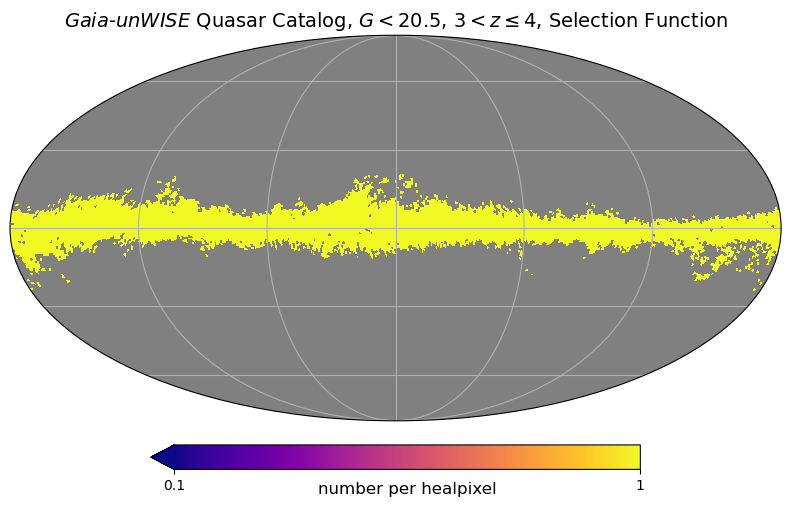

In [81]:
cmap_map = 'plasma'
name_catalog='$Gaia$-$unWISE$ Quasar Catalog'
wp_debug = []
rpavg_debug = []

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin02, map_gcatlo2, map_randlo2, pixel_indices_gcatlo2, pixel_indices_randlo2 = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins], allsky = '_zero',
                                                                                                   tab_gcat_type = 'data', method = ['minmax'], 
                                                                                                   fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                                   b = [0,0,0,30][j], plot = True, bounds = [0.1, 20])
    wp_debug_i, rpavg_debug_i, qq, qr = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0,
                                                      nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
    wp_debug.append(wp_debug_i)
    rpavg_debug.append(rpavg_debug_i)
    
    print('{} < z <= {}'.format(j, j+1))
    print('data', len(np.where(map_gcatlo2==0)[0]))
    print('rand', len(np.where(map_randlo2==0)[0]))
    print('selfunc', len(np.where(selfunc_hi_bin02==0)[0]))

    # make map of quasar number counts
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_randhi_mask_bin0:,}), ${j}< z\leq{j+1}$, Selection Function'
    projview(selfunc_hi_bin02, title=title_gcatlo, norm='log',
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 0.1, graticule=True)#, cbar_ticks=cbar_ticks)
    
    # show where the selfunc is zero
    map_gcatlo_copy = np.copy(map_gcatlo2)
    map_gcatlo_copy[map_gcatlo_copy==0]=-1
    map_gcatlo_copy[map_gcatlo_copy>0]=0
    N_datahi_mask_bin0 = len(tab_datahi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_datahi_mask_bin0:,}), ${j}< z\leq{j+1}$'
    projview(-map_gcatlo_copy, title=title_gcatlo, norm='log',
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 0.1, graticule=True) #, cbar_ticks=cbar_ticks)

    # make map of quasar number counts
    map_randlo_copy = np.copy(map_randlo2)
    map_randlo_copy[map_randlo_copy==0]=-1
    map_randlo_copy[map_randlo_copy>0]=0
    N_randhi_mask_bin0 = len(tab_randhi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_randhi_mask_bin0:,}), ${j}< z\leq{j+1}$, Randoms'
    projview(-map_randlo_copy, title=title_gcatlo, norm='log',
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 0.1, graticule=True)#, cbar_ticks=cbar_ticks)
    
    # make map of quasar number counts
    selfunc_hi_bin0_copy = np.copy(selfunc_hi_bin02)
    selfunc_hi_bin0_copy[selfunc_hi_bin0_copy==0]=-1
    selfunc_hi_bin0_copy[selfunc_hi_bin0_copy>0]=0
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$, ${j}< z\leq{j+1}$, Selection Function'
    projview(-selfunc_hi_bin0_copy, title=title_gcatlo, norm = 'log',
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 0.1, graticule=True)#, cbar_ticks=cbar_ticks)

<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:16: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_207953/1545611481.py:16: SyntaxWarning: invalid escape sequence '\l'
  plt.hist(selfunc_hi_bin02, label = '${}< z\leq{}$'.format(j, j+1), histtype = 'step', bins = 50)


../data/maps/selection_function_NSIDE64_G20.5_zmin0.0zmax1.0.fits
../data/randoms/random_G20.5_zmin0.0zmax1.0_zero_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.990565339647773
0 < z <= 1
data 32787
rand 32612
selfunc 6299
../data/maps/selection_function_NSIDE64_G20.5_zmin1.0zmax2.0.fits
../data/randoms/random_G20.5_zmin1.0zmax2.0_zero_25x.fits
G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196
24.994950601361317
1 < z <= 2
data 32787
rand 32612
selfunc 6299
../data/maps/selection_function_NSIDE64_G20.5_zmin2.0zmax3.0.fits
../data/randoms/random_G20.5_zmin2.0zmax3.0_zero_25x.fits
G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508
24.9659939687548
2 < z <= 3
data 32787
rand 32612
selfunc 6299
../data/maps/selection_function_NSIDE64_G20.5_zmin3.0zmax4.0.fits
../data/randoms/random_G20.5_zmin3.0zmax4.0_zero_25x.fits
G20.5_zmin3.0zmax4.0: 0.23              27584 vs 35630
25.069750580046403
3 < z <= 4
data 32787
rand 32612
selfunc 6299


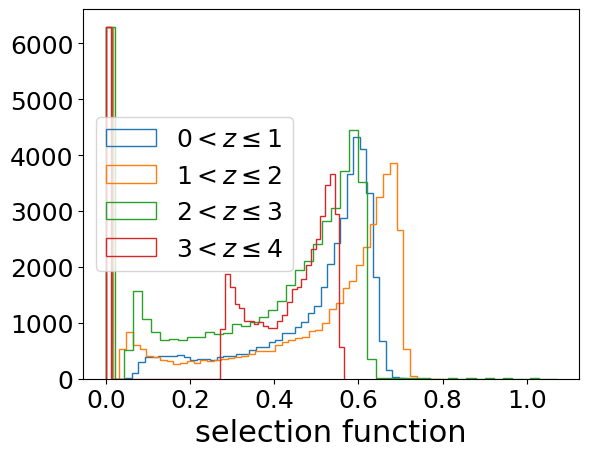

In [68]:
cmap_map = 'plasma'
name_catalog='$Gaia$-$unWISE$ Quasar Catalog'

for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin02, _, _, _, _ = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins], allsky = '_zero',
                                                                                                   tab_gcat_type = 'data', method = ['minmax'], 
                                                                                                   fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                                   b = [0,0,0,30][j])
    
    print('{} < z <= {}'.format(j, j+1))
    print('data', len(np.where(map_gcatlo2==0)[0]))
    print('rand', len(np.where(map_randlo2==0)[0]))
    print('selfunc', len(np.where(selfunc_hi_bin02==0)[0]))

    plt.hist(selfunc_hi_bin02, label = '${}< z\leq{}$'.format(j, j+1), histtype = 'step', bins = 50)
    plt.xlabel('selection function')
    plt.legend()
    
plt.show()

<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_207953/2997336413.py:24: SyntaxWarning: invalid escape sequence '\l'
  second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')


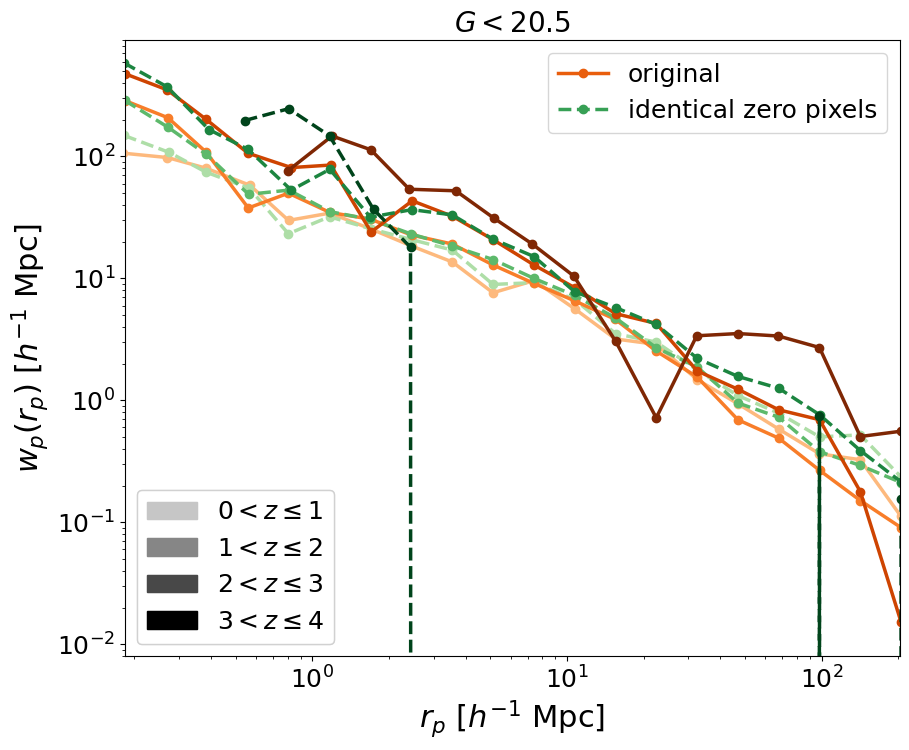

In [59]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['original', 'identical zero pixels']

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = r'original', 
                 color = cmap_qq[j])
    plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = r'identical zero pixels', linestyle = '--',
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

### Check if there are NaNs in the selection function

../data/maps/selection_function_NSIDE64_G20.5_zmin0.0zmax1.0.fits
../data/randoms/random_G20.5_zmin0.0zmax1.0_zero_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.990565339647773


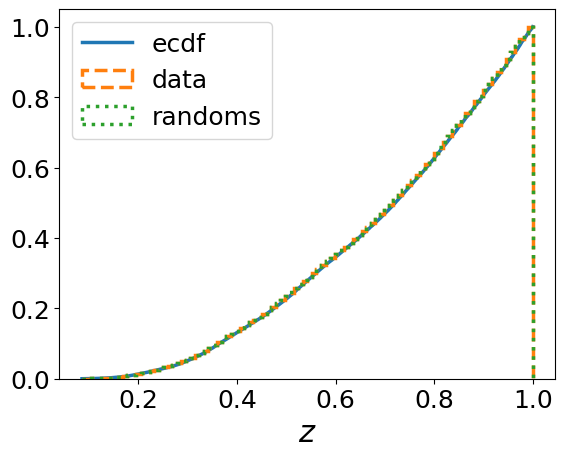

0.0
0.0
0 < z <= 1
data 7076
rand 7076
selfunc 6299
(array([], dtype=int64),)
../data/maps/selection_function_NSIDE64_G20.5_zmin1.0zmax2.0.fits
../data/randoms/random_G20.5_zmin1.0zmax2.0_zero_25x.fits
G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196
24.994950601361317


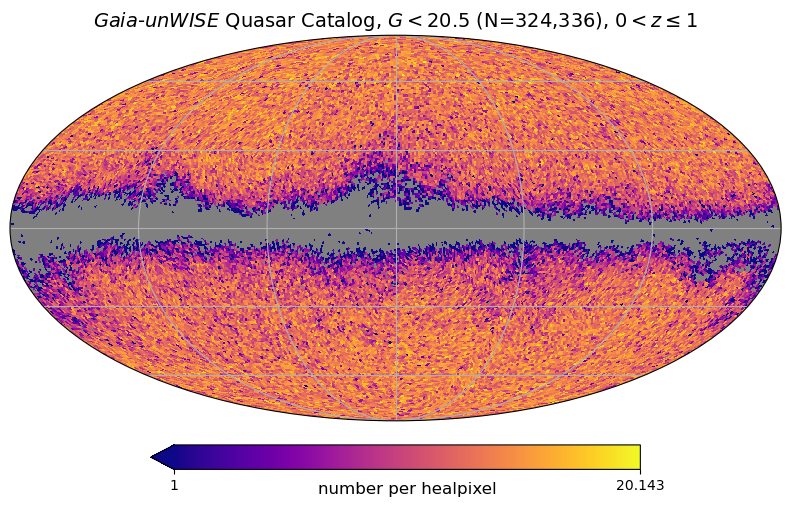

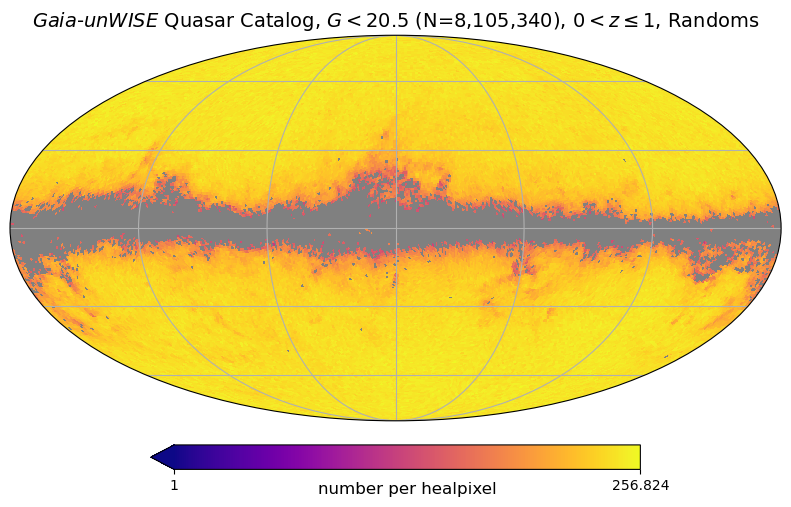

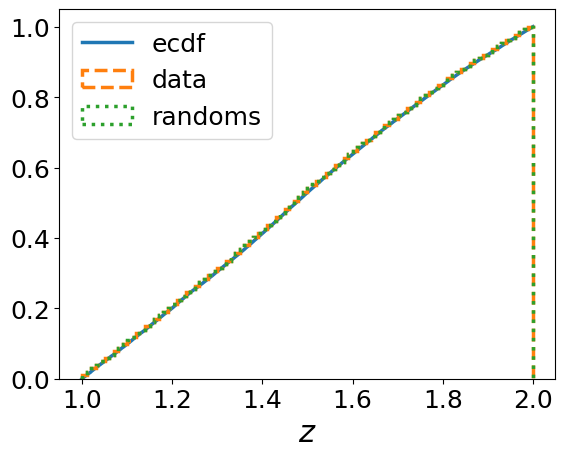

0.0
0.0
1 < z <= 2
data 7388
rand 7388
selfunc 6299
(array([], dtype=int64),)
../data/maps/selection_function_NSIDE64_G20.5_zmin2.0zmax3.0.fits
../data/randoms/random_G20.5_zmin2.0zmax3.0_zero_25x.fits
G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508
24.9659939687548


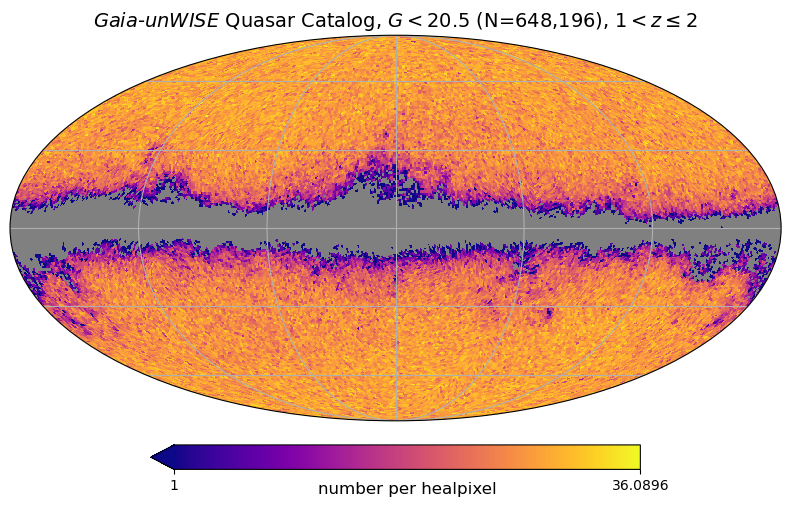

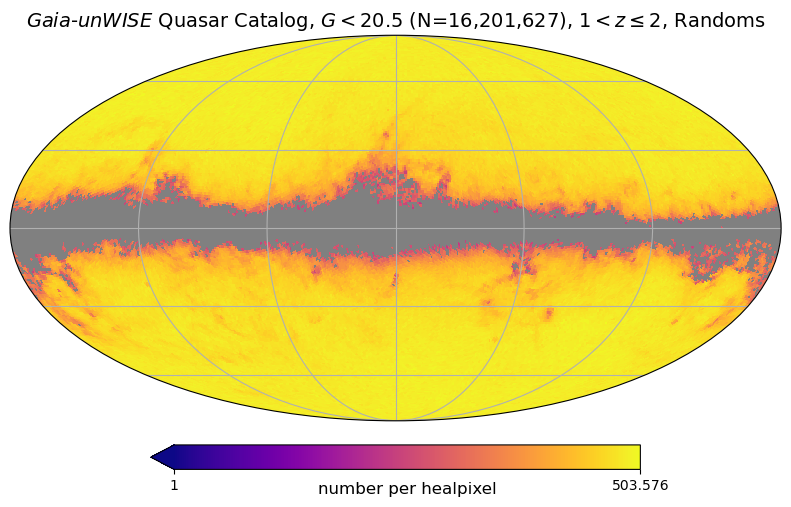

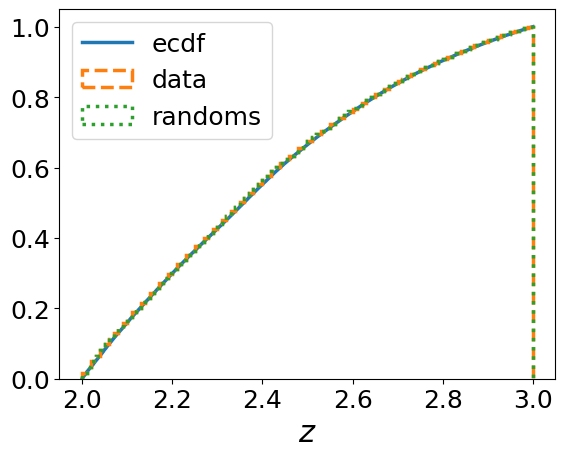

0.0
0.0
2 < z <= 3
data 9339
rand 9339
selfunc 6299
(array([], dtype=int64),)
../data/maps/selection_function_NSIDE64_G20.5_zmin3.0zmax4.0.fits
../data/randoms/random_G20.5_zmin3.0zmax4.0_zero_25x.fits
G20.5_zmin3.0zmax4.0: 0.23              27584 vs 35630
25.069750580046403


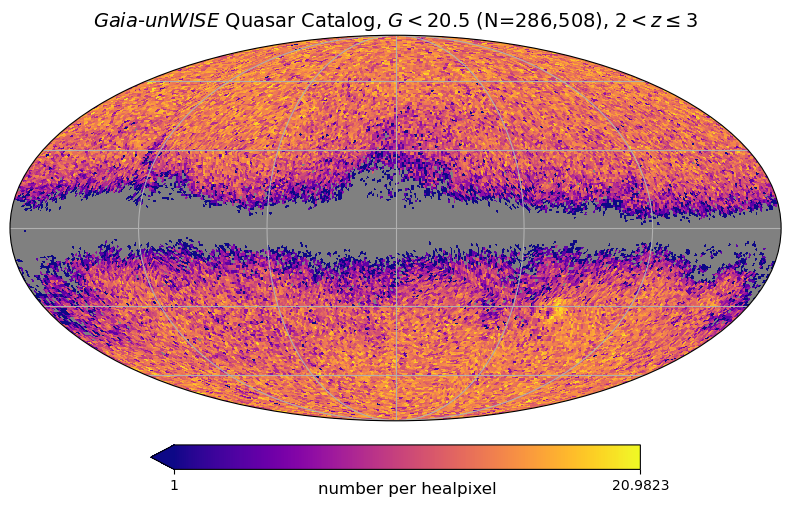

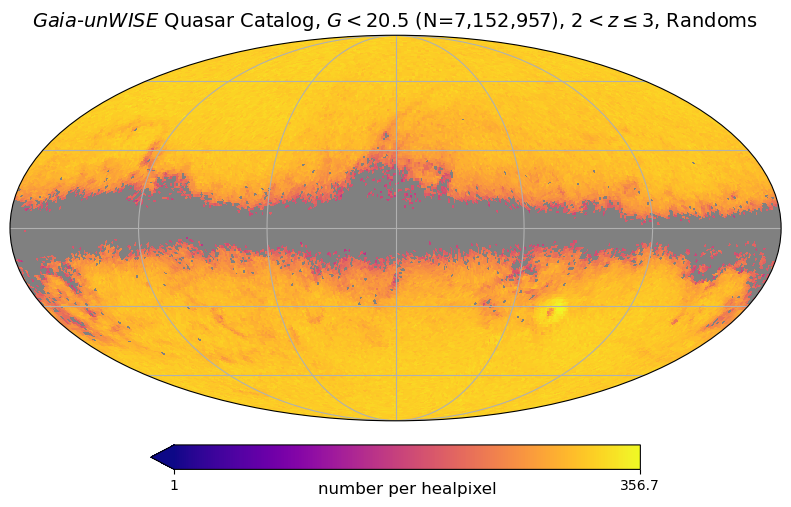

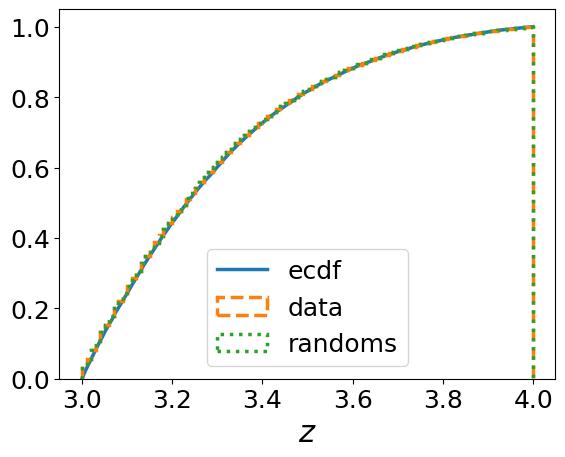

0.0
0.0
3 < z <= 4
data 32787
rand 32612
selfunc 6299
(array([], dtype=int64),)


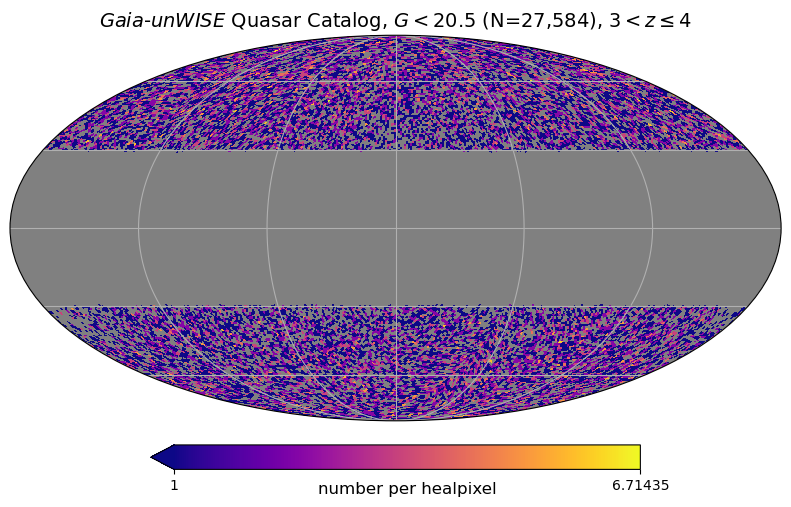

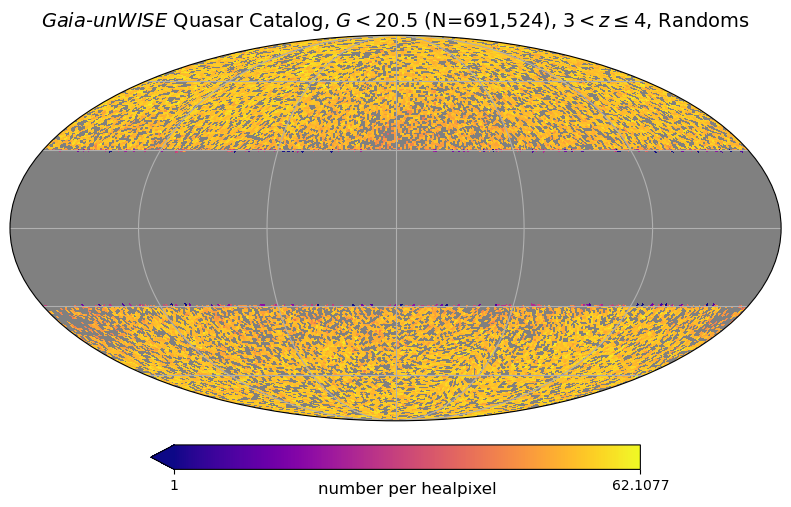

In [51]:
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin02, map_gcatlo2, map_randlo2, pixel_indices_gcatlo2, pixel_indices_randlo2 = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins], allsky = '_zero',
                                                                                                   tab_gcat_type = 'data', method = ['minmax'], 
                                                                                                   fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                                   b = [0,0,0,30][j], plot = True)
    
    print('{} < z <= {}'.format(j, j+1))
    print('data', len(np.where(map_gcatlo2==0)[0]))
    print('rand', len(np.where(map_randlo2==0)[0]))
    print('selfunc', len(np.where(selfunc_hi_bin02==0)[0]))
    print(np.where(np.isnan(selfunc_hi_bin02)))

In [148]:
len(selfunc_hi_bin0)

49152

../data/randoms/random_G20.5_zmin0.0zmax1.0_p_rand_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.999142864190222


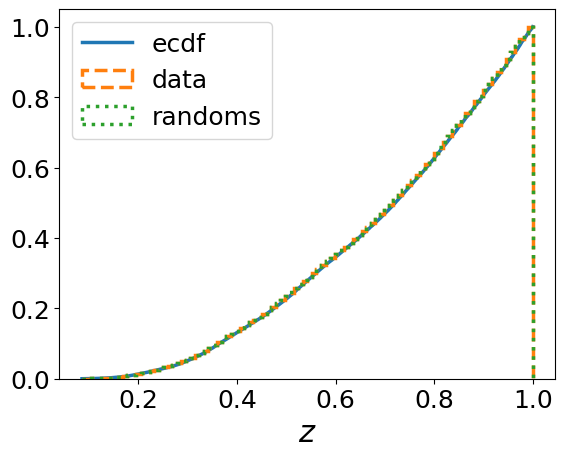

0.0
0.0


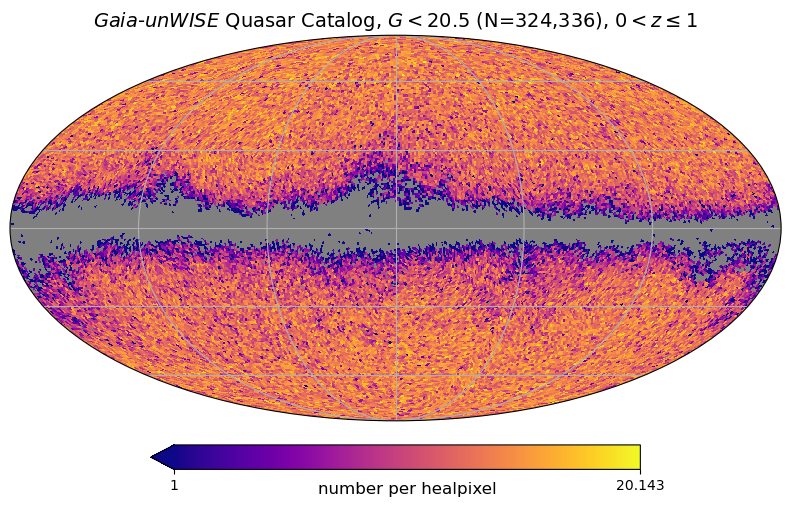

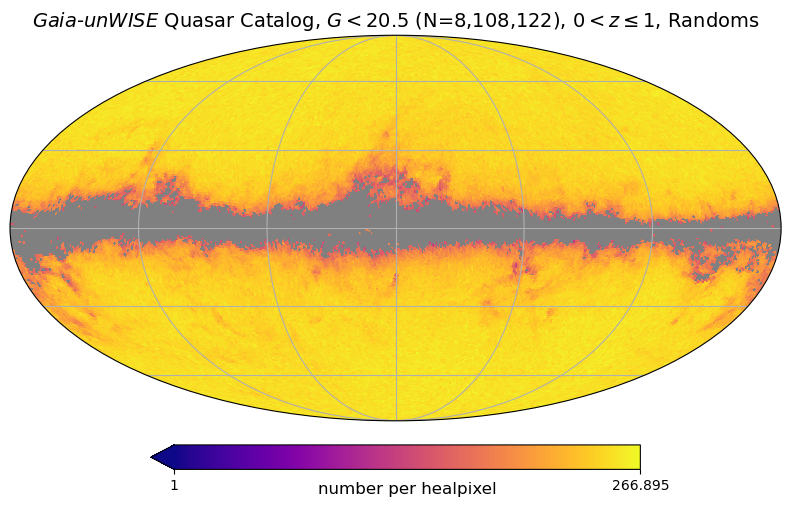

In [146]:
j = 0
tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, map_gcatlo, map_randlo = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                               plot = True, b = [0,0,0,30][j], allsky = '_p_rand')

../data/randoms/random_G20.5_zmin0.0zmax1.0_map_p_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.999142864190222


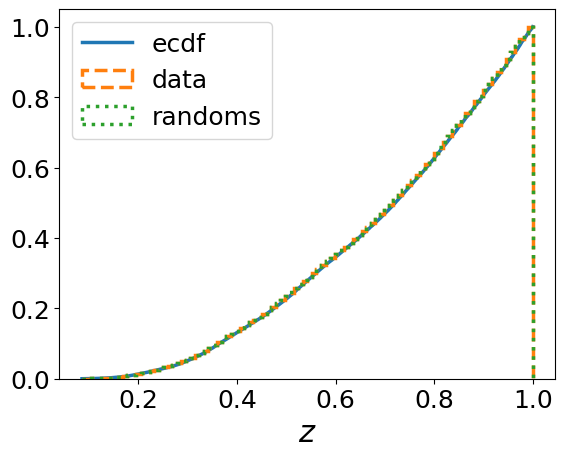

0.0
0.0


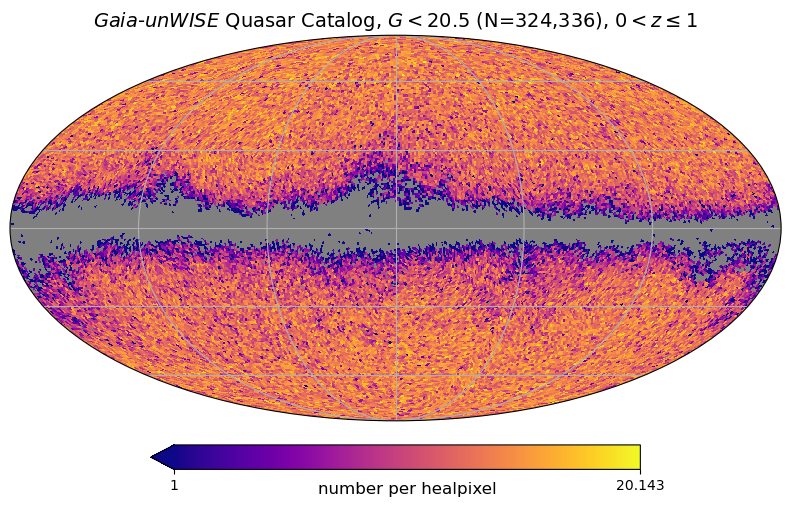

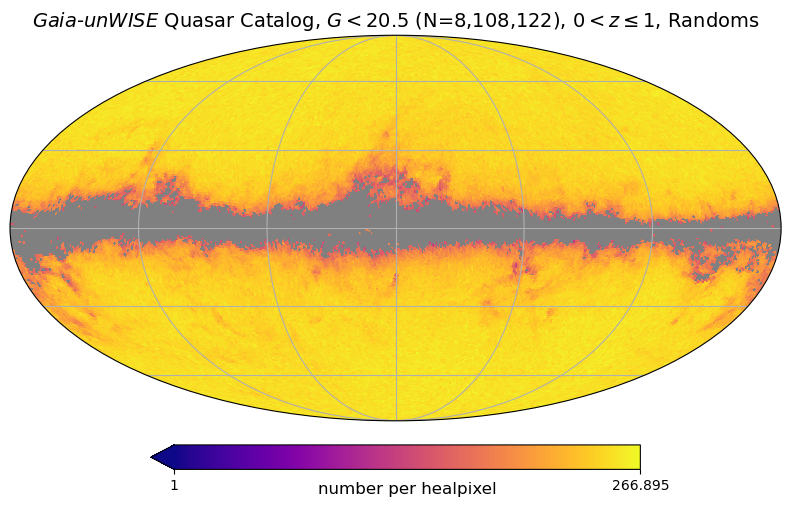

In [122]:
tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, map_gcatlo_map_p, map_randlo_map_p = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                               plot = True, b = [0,0,0,30][j], allsky = '_map_p')

../data/randoms/random_G20.5_zmin0.0zmax1.0_gr_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.999142864190222


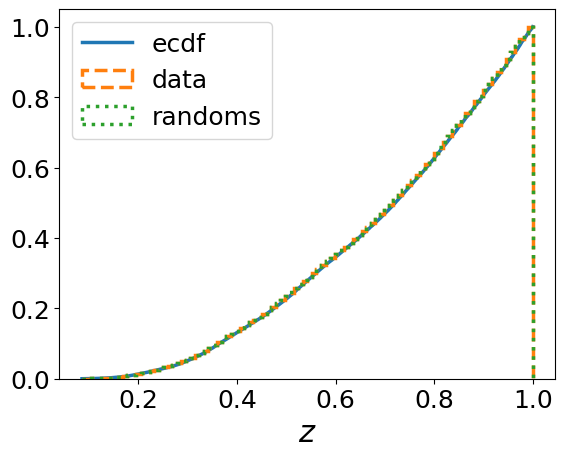

0.0
0.0


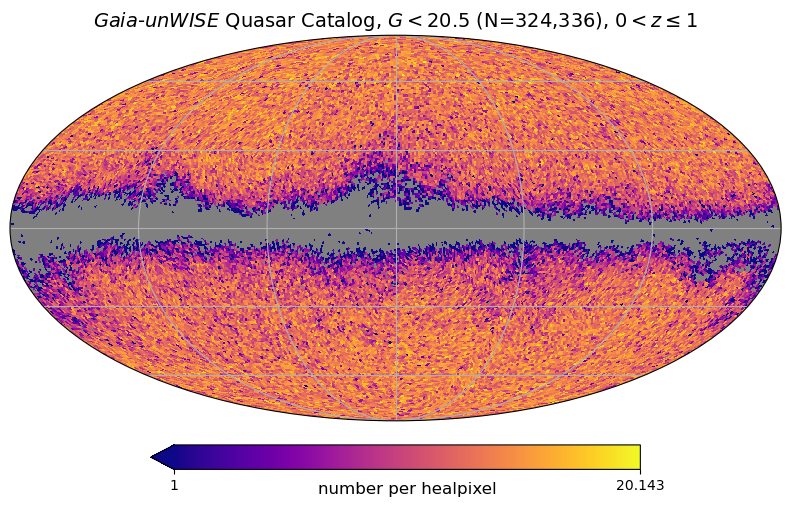

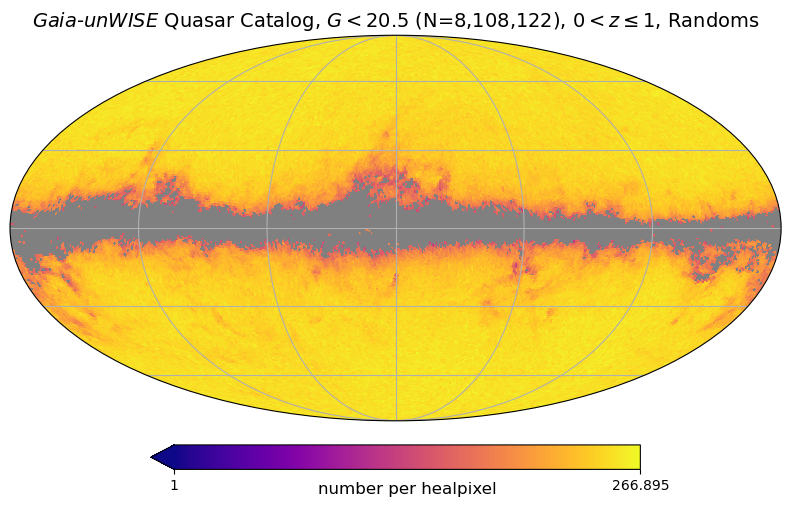

In [149]:
tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, map_gcatlo_map_p, map_randlo_map_p = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                               plot = True, b = [0,0,0,30][j], allsky = '_gr')

In [ ]:
j = 2
tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, map_gcatlo_map_p, map_randlo_map_p = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                               plot = True, b = [0,0,0,30][j])

## Check custom cosmology
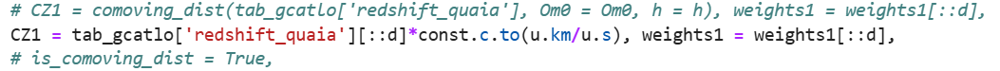

In [32]:
# wp_zbin_percentile = []
# rpavg_zbin_percentile = []
j = 0
# for j in z_array:

tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                 bins = [z_bins], tab_gcat_type = 'data',
                                                                                 method = ['minmax'], fac_rand = 25,
                                                                                 n_bins = [None], mask = mask)
wp_zbin_percentile, rpavg_zbin_percentile, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0,
                                                  nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
# wp_zbin_percentile.append(wp_zbin_i)
# rpavg_zbin_percentile.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


In [33]:
d = 1
tab_datahi_mask_zbin0['redshift_quaia'][::d]*const.c.to(u.km/u.s)*h_planck20/cu.littleh

<Quantity [ 84232.16814149, 166020.32797076, 162351.22026599, ...,
           101658.71651975, 184396.6622904 ,  88412.31503604] km / (littleh s)>

In [44]:
# wp_debug = []
# rpavg_debug = []
    
# for j in z_array:

tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                 bins = [z_bins], tab_gcat_type = 'data',
                                                                                 method = ['minmax'], fac_rand = 25,
                                                                                 n_bins = [None], mask = mask)
wp_debug, rpavg_debug, qq, qr = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0,
                                                  nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
# wp_debug.append(wp_zbin_i)
# rpavg_debug.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


In [35]:
galaxy_catalog=pjoin(dirname(abspath(Corrfunc.__file__)),
                     "../mocks/tests/data", "Mr19_mock_northonly.rdcz.ff")

# Read the supplied galaxies on a periodic box
RA, DEC, CZ = read_catalog(galaxy_catalog)
N = len(RA)

# Read the supplied randoms catalog
random_catalog=pjoin(dirname(abspath(Corrfunc.__file__)),
                     "../mocks/tests/data", "Mr19_randoms_northonly.rdcz.ff")
rand_RA, rand_DEC, rand_CZ = read_catalog(random_catalog)
rand_N = len(rand_RA)

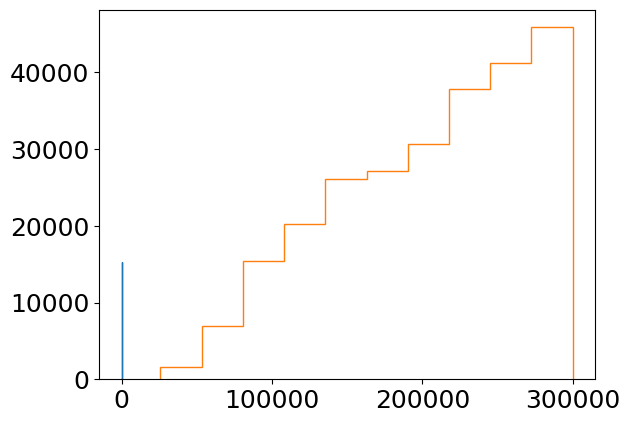

In [51]:
plt.hist(CZ/H0_planck20.value, histtype = 'step')
plt.hist(tab_datahi_mask_zbin0['redshift_quaia']*const.c.to(u.km/u.s).value, histtype = 'step')
plt.show()

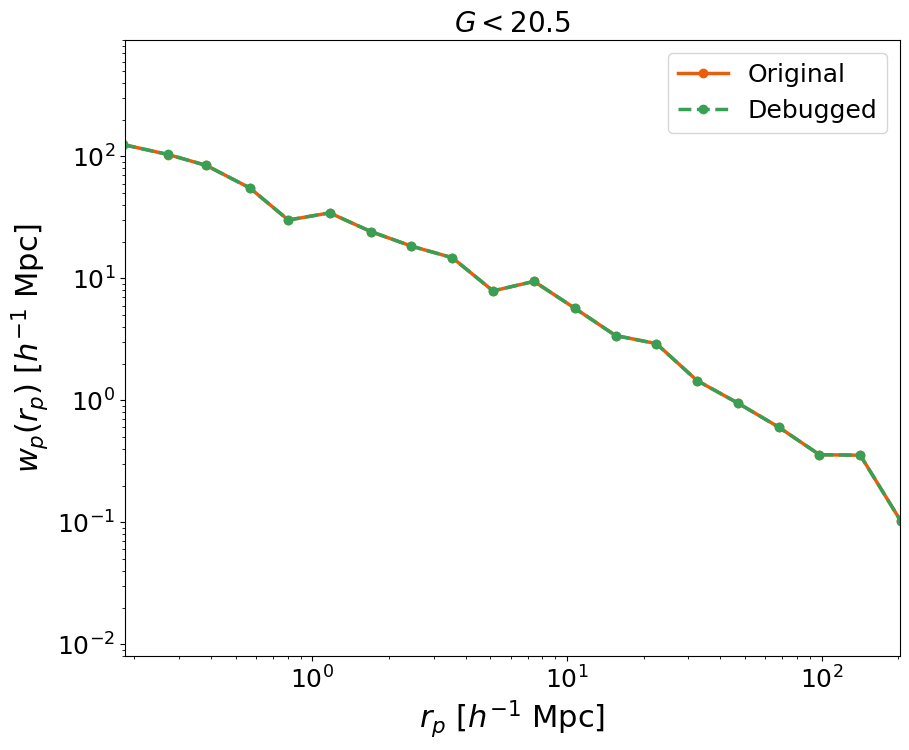

In [46]:
fig = plt.figure(figsize = (10, 8))

labels_cf = ['Original', 'Debugged']

# for j in z_array:

plt.plot(rpavg_zbin_percentile, wp_zbin_percentile, linewidth = 2.5, marker = 'o', label = r'Original', 
             color = orange)
plt.plot(rpavg_debug, wp_debug, linewidth = 2.5, marker = 'o', label = r'Debugged', linestyle = '--',
             color = green)

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)
plt.legend()

# custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
#                     Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
# second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
# fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

# custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
# second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
# fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

## Try plotting comparison to Mariona...

In [14]:
# Create the bins array
rmin = 1 # 30 #0.1
rmax = 200 # 80 #180.0
nbins = 14 # 20 
rpbins = np.logspace(np.log10(rmin), np.log10(rmax), nbins + 1) # Mpc/h https://github.com/manodeep/Corrfunc/issues/202
scale = 'log' # 'linear'

In [15]:
pimax = 100 # 80 # 40 # 5000.0 # 40.0

In [16]:
wp_zbin_percentile = []
rpavg_zbin_percentile = []
b = [0, 0, 0, 30]
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 100,
                                                                                     n_bins = [None], mask_type = 'b', b = b[j])
    wp_zbin_i, rpavg_zbin_i, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = 0.315, h = 0.674,
                                                      nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
    wp_zbin_percentile.append(wp_zbin_i)
    rpavg_zbin_percentile.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin3.0zmax4.0: 0.23              27584 vs 35630


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


<>:6: SyntaxWarning: invalid escape sequence '\l'
<>:6: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15779/444497605.py:6: SyntaxWarning: invalid escape sequence '\l'
  plt.errorbar(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = '${:.0f}<z \leq{:.0f}$'.format(j, j+1),


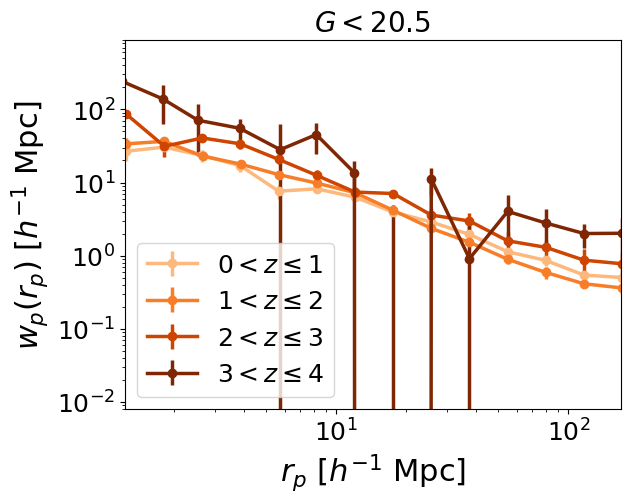

In [23]:
# fig = plt.figure(figsize = (10, 8))
N=100
for j in z_array:

    sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_z{:.1f}_b_planck20_{}x.npy'.format(G_hi, rmin, rmax, nbins, pimax, j, N))))
    plt.errorbar(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = '${:.0f}<z \leq{:.0f}$'.format(j, j+1), 
                 color = cmap_qq[j], yerr = sigma)

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

# custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
#                     Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
# second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
# fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

# custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
# second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
# fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')
plt.legend()

if scale == 'log':
    plt.xscale('log')

plt.show()

<>:12: SyntaxWarning: invalid escape sequence '\l'
<>:15: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\l'
<>:15: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_15779/2097754622.py:12: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(rpavg_zbin_percentile[j], wp_zbin_percentile[j], marker = 'o', label = '${:.0f}<z \leq{:.0f}$'.format(j, j+1),
/tmp/ipykernel_15779/2097754622.py:15: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.0f}<z \leq{:.0f}$'.format(j, j+1))


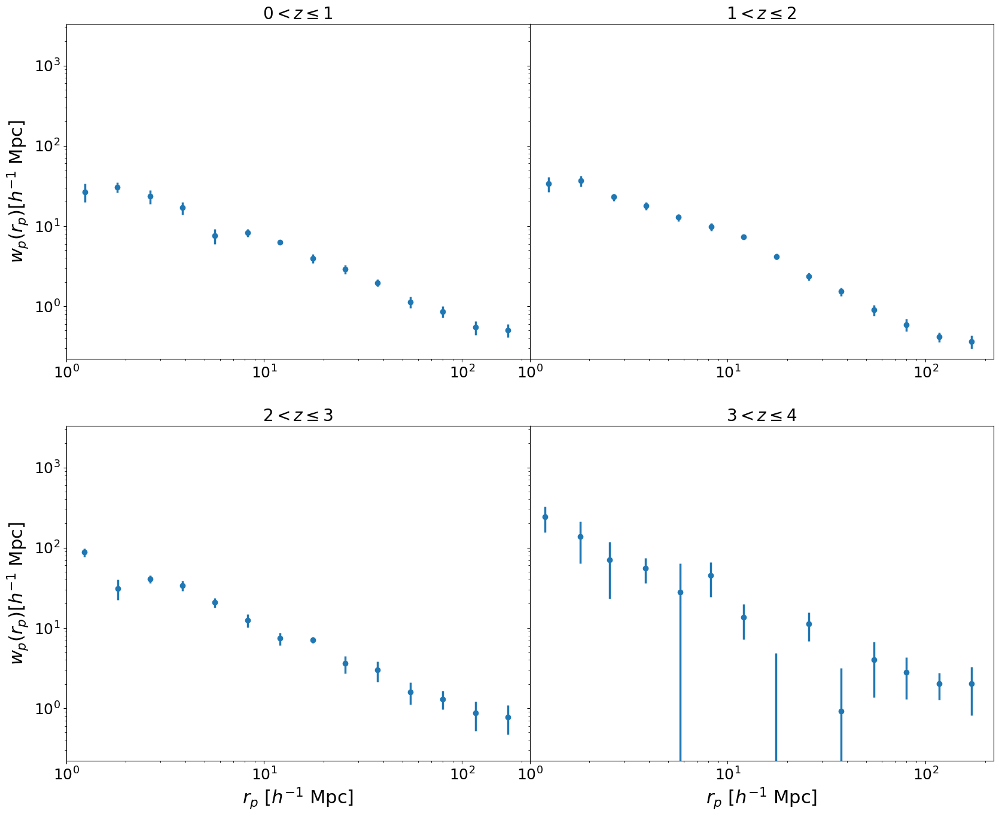

In [22]:
# plot!
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.2)
ymin, ymax = [], []
ax=[]
for j in z_array:
    
    ax1 = fig.add_subplot(gs[j])
    ax.append(ax1)
        
    sigma = np.sqrt(np.diag(np.load('../results/cov_wp_G{}_rmin{}_rmax{}_nbins{}_pimax{}_z{:.1f}_b_planck20_{}x.npy'.format(G_hi, rmin, rmax, nbins, pimax, j, N))))
    ax1.errorbar(rpavg_zbin_percentile[j], wp_zbin_percentile[j], marker = 'o', label = '${:.0f}<z \leq{:.0f}$'.format(j, j+1), 
             linewidth = 2.5, yerr = sigma, linestyle = 'None')

    ax1.set_title('${:.0f}<z \leq{:.0f}$'.format(j, j+1))
    if scale == 'log':
        ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_xlim(rmin, 2.2e2)
    ax1.set_ylim(2.2e-1, 3.3e3)
    if j>1:
        ax1.set_xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
    if j%2==0:
        ax1.set_ylabel(r"$w_p(r_p) [h^{-1}$ Mpc]")
    else:
        ax1.set_yticklabels([])

plt.show()

## Check the selection function

../data/maps/selection_function_NSIDE64_G20.5_zsplit2bin0.fits
../data/randoms/random_G20.5_zsplit2bin0_25x.fits
G20.5_zsplit2bin0: 0.00              647744 vs 647744
25.00153146922241


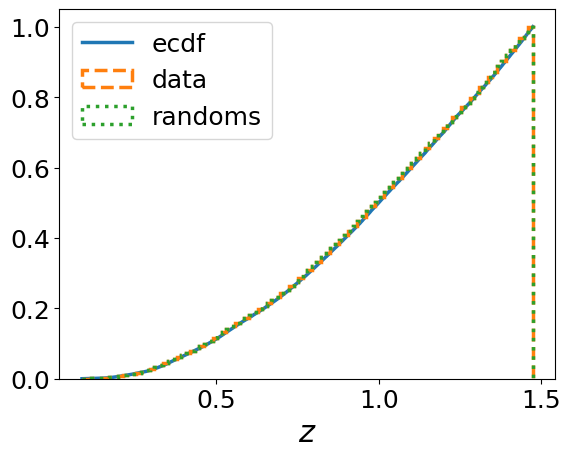

0.0
0.0


/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia_debug.py:566: RuntimeWarning: divide by zero encountered in divide
  return tab_datahi_mask_bin0, tab_randhi_mask_bin0, key_bin0, bins, 1/selfunc_hi_bin0[pixel_indices_datahi_bin0][mask_datahi_bin0], 1-N_datahi_mask_bin0/len(tab_datahi_bin0), selfunc_hi_bin0, map_gcatlo, map_randlo, pixel_indices_gcatlo, pixel_indices_randlo


0 < z <= 1
data 6536
rand 6299
selfunc 6532
(array([], dtype=int64),)
../data/maps/selection_function_NSIDE64_G20.5_zsplit2bin1.fits
../data/randoms/random_G20.5_zsplit2bin1_25x.fits
G20.5_zsplit2bin1: 0.00              647758 vs 647758
24.9891533566548


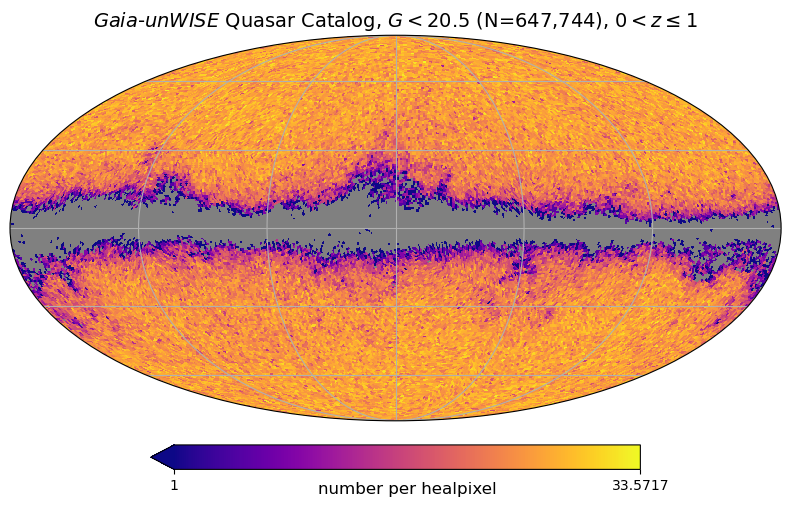

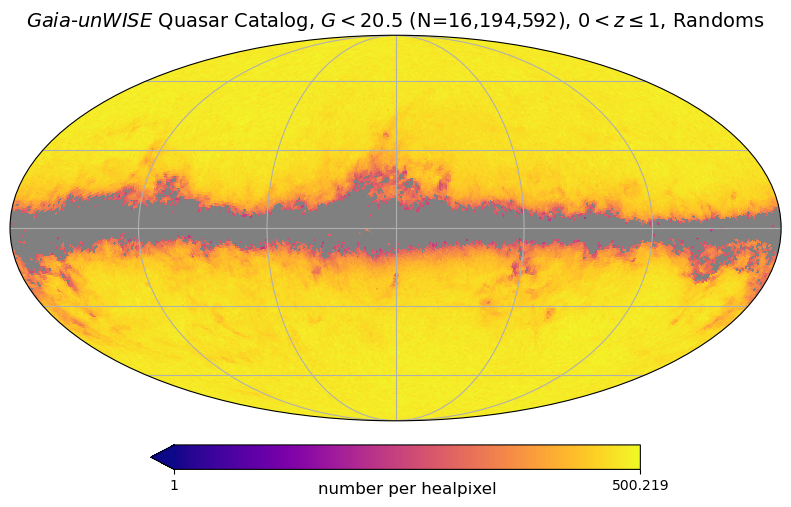

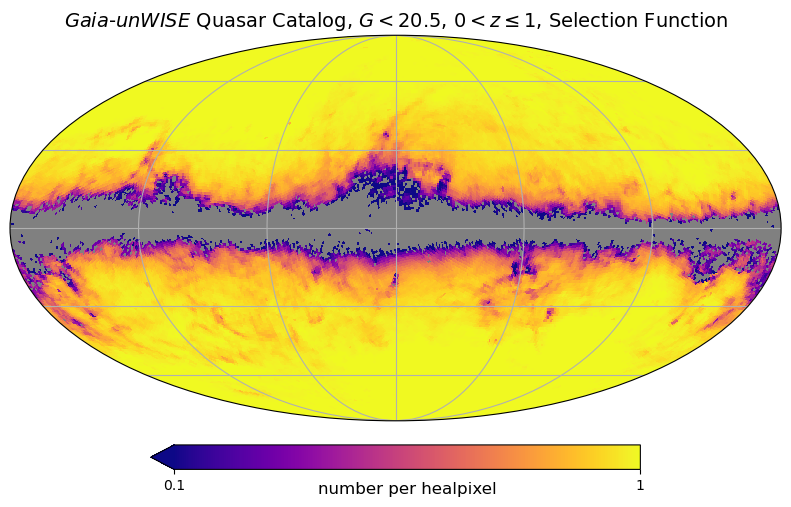

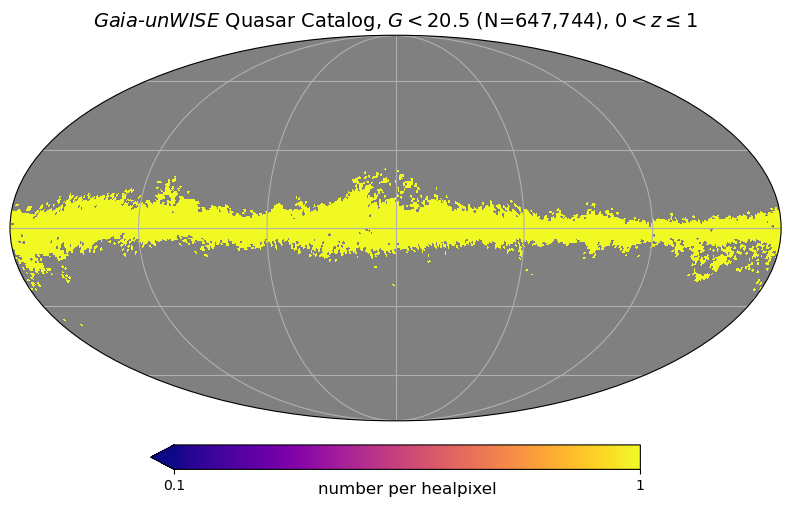

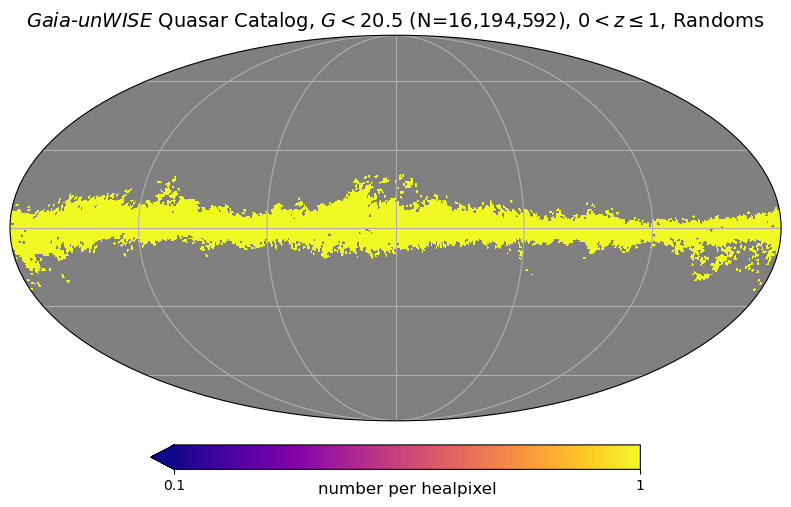

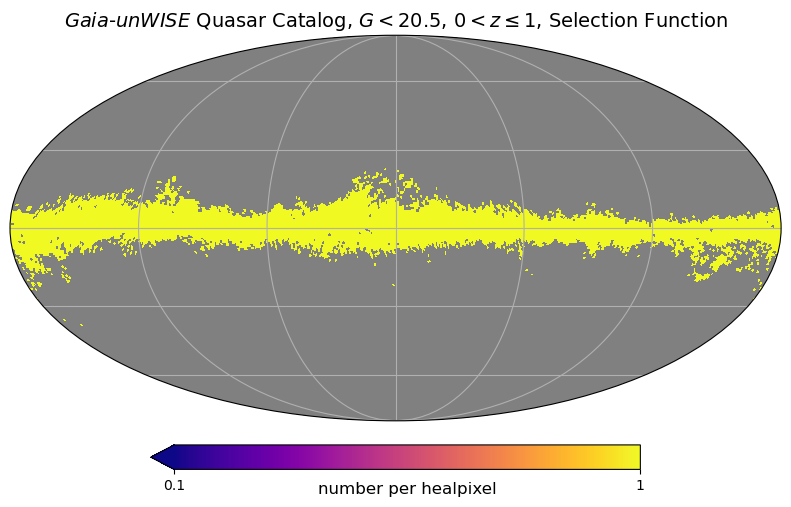

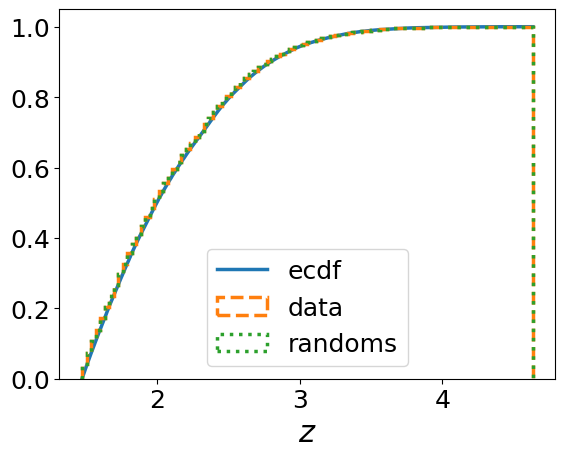

0.0
0.0


/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia_debug.py:566: RuntimeWarning: divide by zero encountered in divide
  return tab_datahi_mask_bin0, tab_randhi_mask_bin0, key_bin0, bins, 1/selfunc_hi_bin0[pixel_indices_datahi_bin0][mask_datahi_bin0], 1-N_datahi_mask_bin0/len(tab_datahi_bin0), selfunc_hi_bin0, map_gcatlo, map_randlo, pixel_indices_gcatlo, pixel_indices_randlo


1 < z <= 2
data 7851
rand 6299
selfunc 7887
(array([], dtype=int64),)


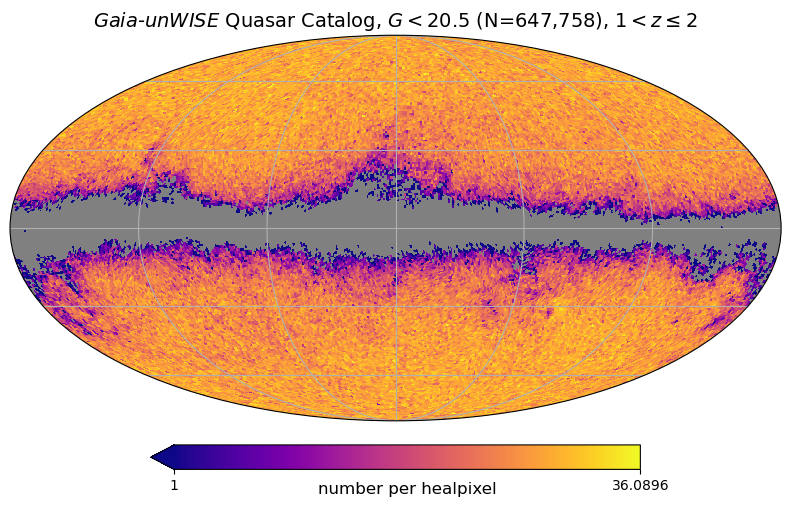

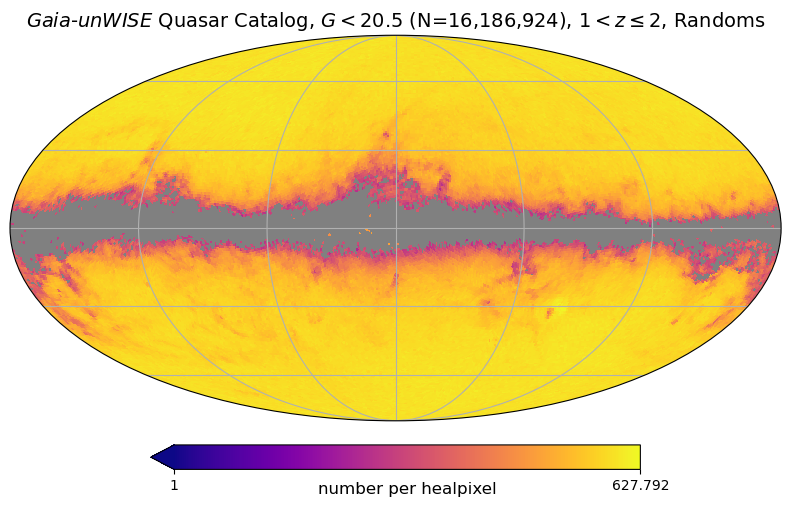

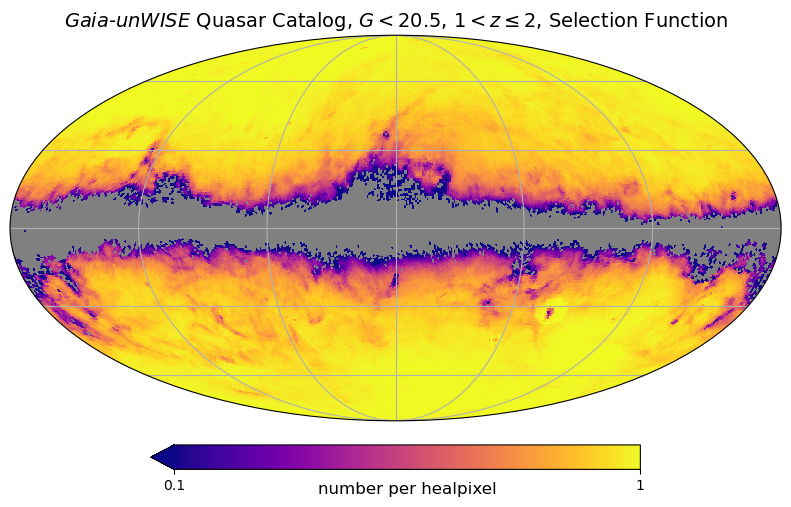

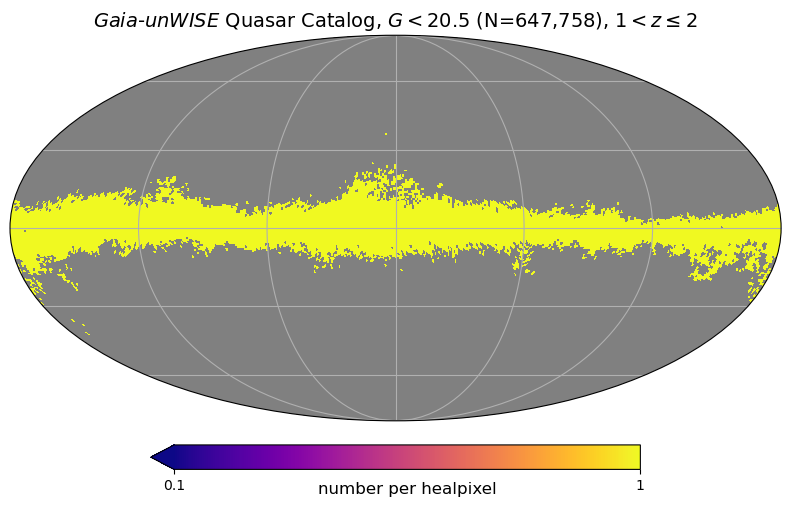

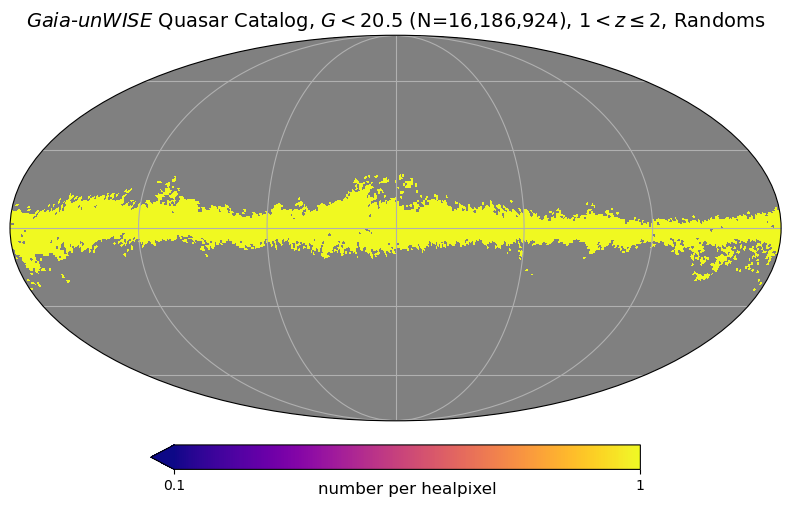

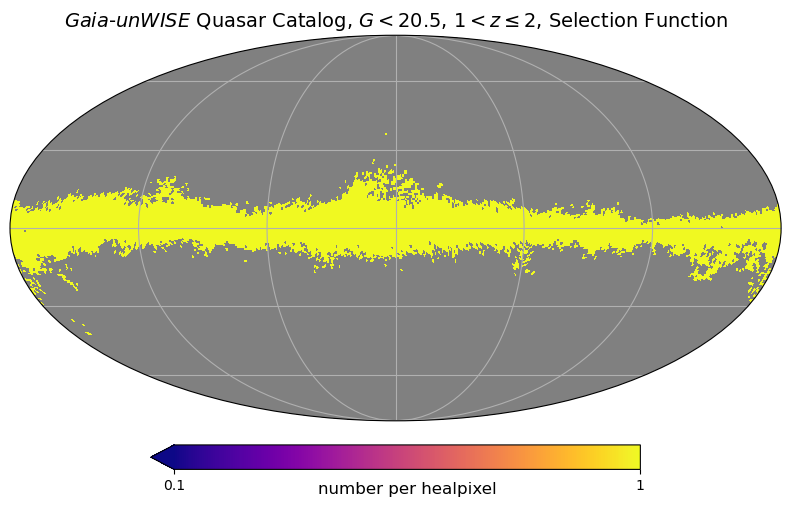

In [34]:
cmap_map = 'plasma'
name_catalog='$Gaia$-$unWISE$ Quasar Catalog'

for j in [0,1]:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin02, map_gcatlo2, map_randlo2, pixel_indices_gcatlo2, pixel_indices_randlo2 = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                                   tab_gcat_type = 'data', method = ['split'], 
                                                                                                   fac_rand = 25, n_bins = [2], mask_type = 'b',
                                                                                                   b = [0,0,0,30][j], plot = True)
    
    print('{} < z <= {}'.format(j, j+1))
    print('data', len(np.where(map_gcatlo2==0)[0]))
    print('rand', len(np.where(map_randlo2==0)[0]))
    print('selfunc', len(np.where(selfunc_hi_bin02==0)[0]))
    print(np.where(np.isnan(selfunc_hi_bin02)))
    
    # make map of quasar number counts
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$, ${j}< z\leq{j+1}$, Selection Function'
    projview(selfunc_hi_bin02, title=title_gcatlo, norm='log',
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 0.1, graticule=True)#, cbar_ticks=cbar_ticks)
    
    # show where the selfunc is zero
    map_gcatlo_copy = np.copy(map_gcatlo2)
    map_gcatlo_copy[map_gcatlo_copy==0]=-1
    map_gcatlo_copy[map_gcatlo_copy>0]=0
    N_datahi_mask_bin0 = len(tab_datahi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_datahi_mask_bin0:,}), ${j}< z\leq{j+1}$'
    projview(-map_gcatlo_copy, title=title_gcatlo, norm='log',
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 0.1, graticule=True) #, cbar_ticks=cbar_ticks)

    # make map of quasar number counts
    map_randlo_copy = np.copy(map_randlo2)
    map_randlo_copy[map_randlo_copy==0]=-1
    map_randlo_copy[map_randlo_copy>0]=0
    N_randhi_mask_bin0 = len(tab_randhi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_randhi_mask_bin0:,}), ${j}< z\leq{j+1}$, Randoms'
    projview(-map_randlo_copy, title=title_gcatlo, norm='log',
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 0.1, graticule=True)#, cbar_ticks=cbar_ticks)
    
    # make map of quasar number counts
    selfunc_hi_bin0_copy = np.copy(selfunc_hi_bin02)
    selfunc_hi_bin0_copy[selfunc_hi_bin0_copy==0]=-1
    selfunc_hi_bin0_copy[selfunc_hi_bin0_copy>0]=0
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$, ${j}< z\leq{j+1}$, Selection Function'
    projview(-selfunc_hi_bin0_copy, title=title_gcatlo, norm = 'log',
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min = 0.1, graticule=True)#, cbar_ticks=cbar_ticks)

../data/maps/selection_function_NSIDE64_G20.5_zsplit2bin0.fits
../data/randoms/random_G20.5_zsplit2bin0_25x.fits
G20.5_zsplit2bin0: 0.00              647744 vs 647744
25.00153146922241


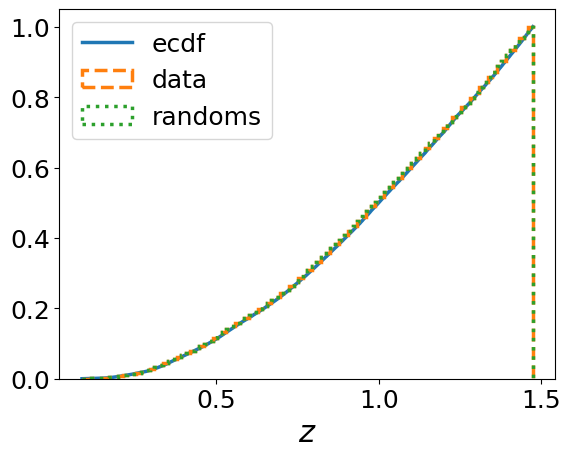

0.0
0.0
0 < z <= 1
data 6536
rand 6299
selfunc 6299
(array([], dtype=int64),)
0.0 0.802751781955829


Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).


../data/maps/selection_function_NSIDE64_G20.5_zsplit2bin1.fits
../data/randoms/random_G20.5_zsplit2bin1_25x.fits
G20.5_zsplit2bin1: 0.00              647758 vs 647758
24.9891533566548


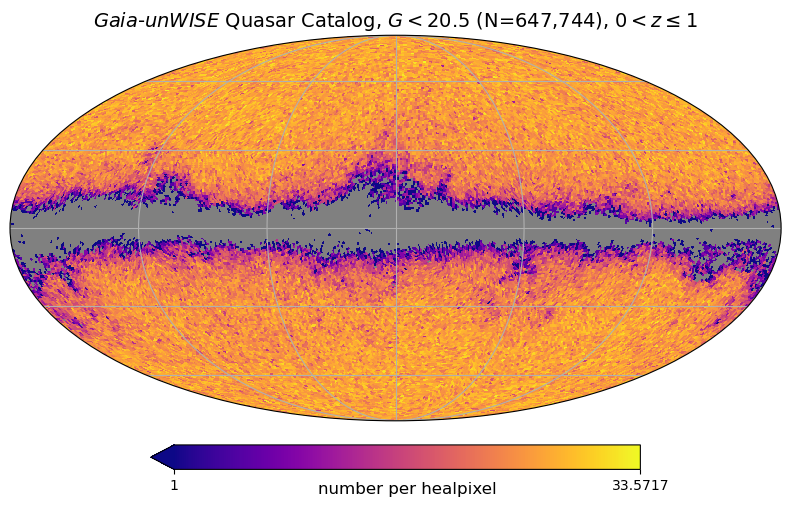

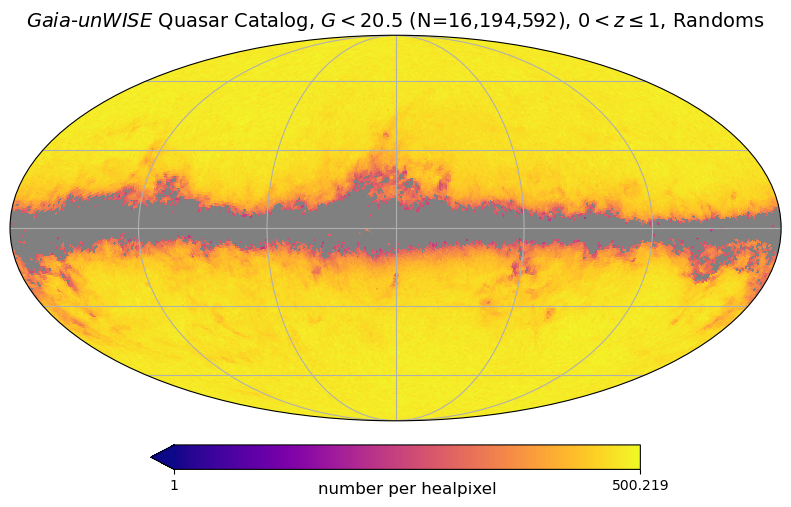

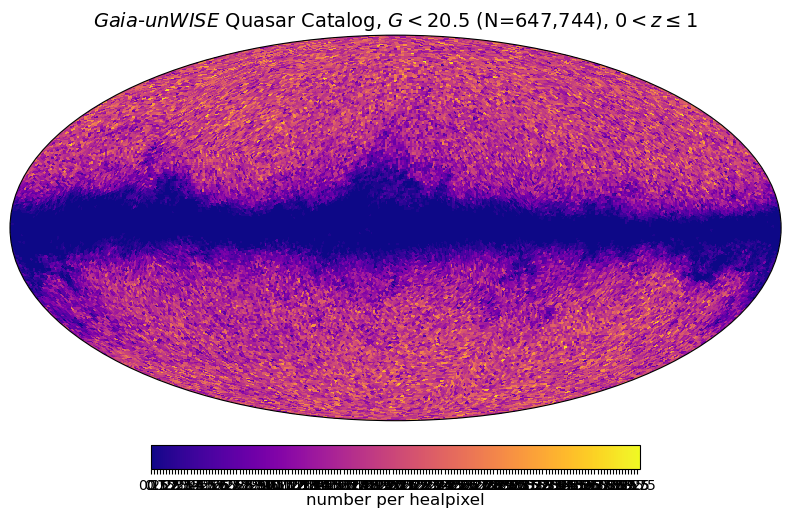

Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exc

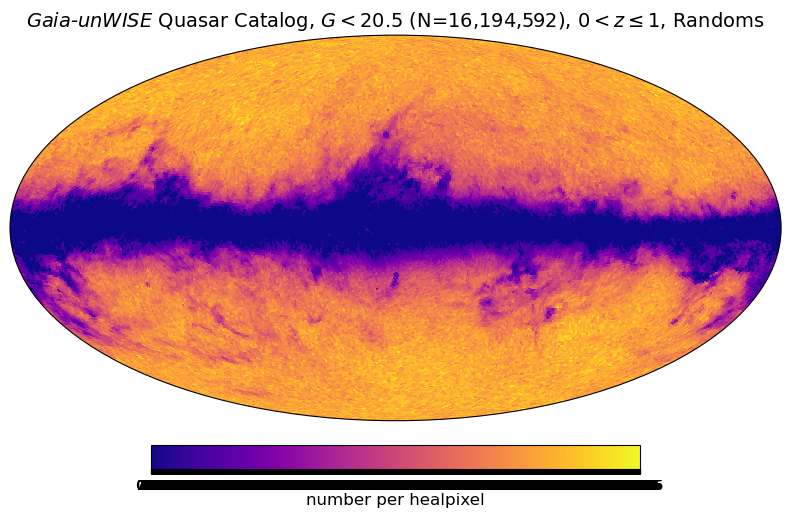

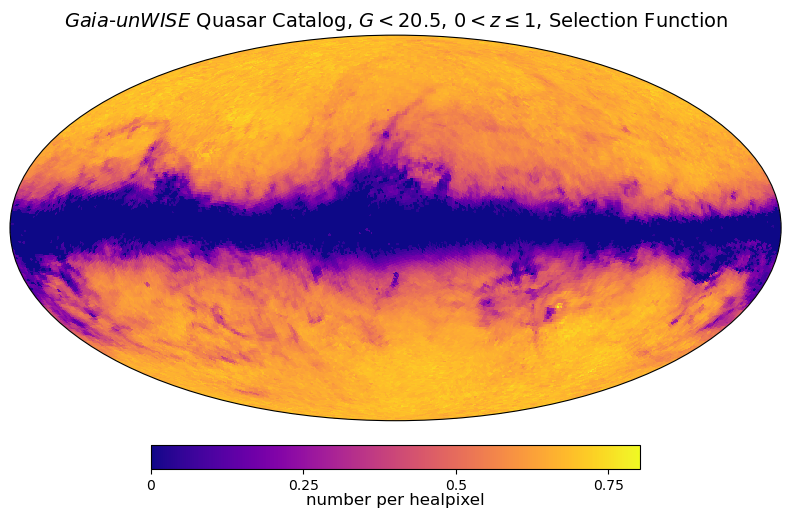

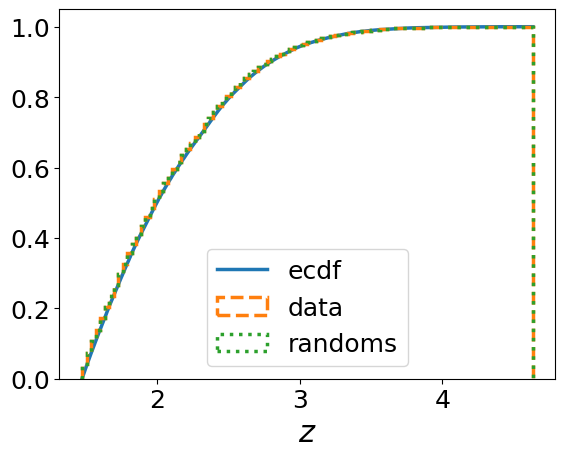

0.0
0.0
1 < z <= 2
data 7851
rand 6299
selfunc 6299
(array([], dtype=int64),)
0.0 0.9153266637256053


Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).


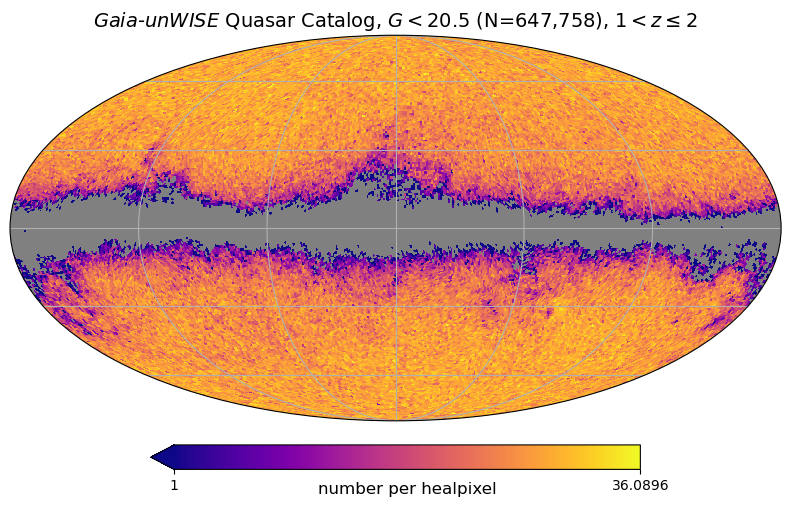

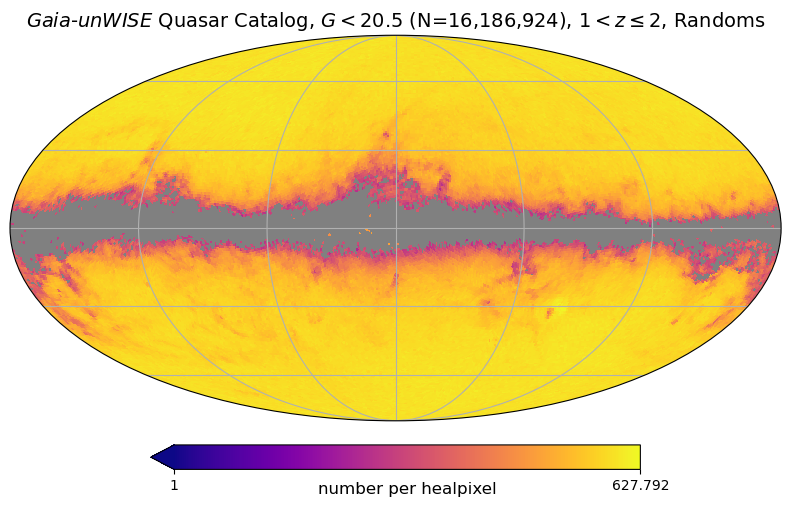

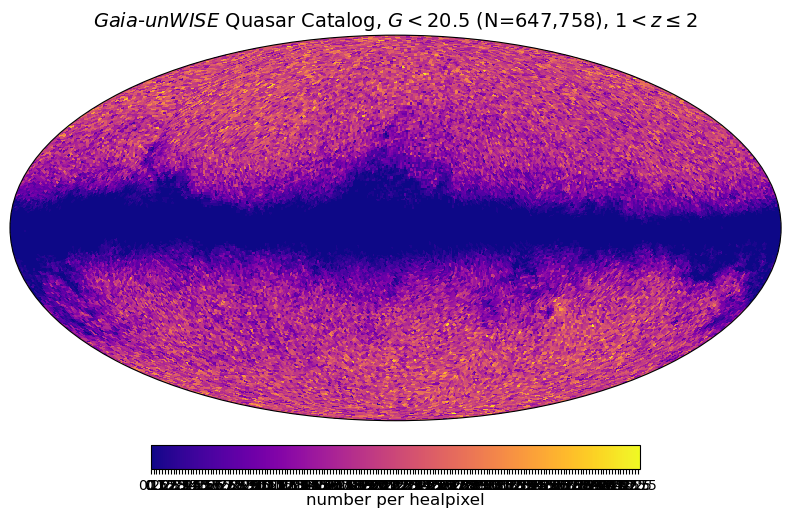

Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exc

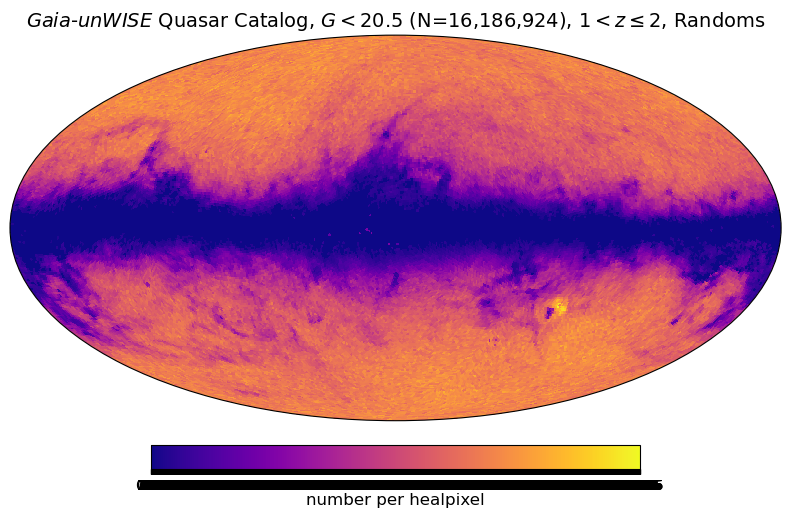

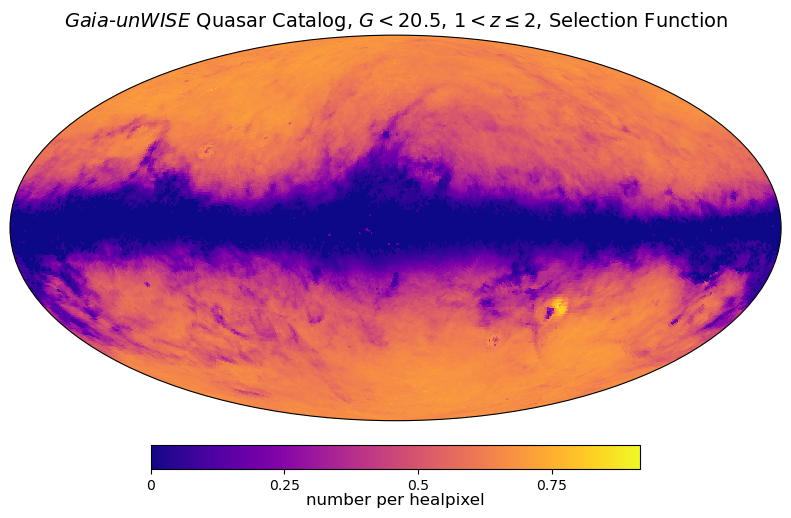

In [40]:
cmap_map = 'plasma'
name_catalog='$Gaia$-$unWISE$ Quasar Catalog'

for j in [0,1]:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin02, map_gcatlo2, map_randlo2, pixel_indices_gcatlo2, pixel_indices_randlo2 = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                                   tab_gcat_type = 'data', method = ['split'], 
                                                                                                   fac_rand = 25, n_bins = [2], mask_type = 'b',
                                                                                                   b = [0,0,0,30][j], plot = True)
    
    print('{} < z <= {}'.format(j, j+1))
    print('data', len(np.where(map_gcatlo2==0)[0]))
    print('rand', len(np.where(map_randlo2==0)[0]))
    print('selfunc', len(np.where(selfunc_hi_bin02==0)[0]))
    print(np.where(np.isnan(selfunc_hi_bin02)))
    print(np.min(selfunc_hi_bin02), np.max(selfunc_hi_bin02))
    
    # show where the selfunc is zero
    N_datahi_mask_bin0 = len(tab_datahi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_datahi_mask_bin0:,}), ${j}< z\leq{j+1}$'
    projview(map_gcatlo2, title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min=0, max=np.max(map_gcatlo2),
            cbar_ticks=np.arange(0, max(map_gcatlo2), 0.25))

    # make map of quasar number counts
    N_randhi_mask_bin0 = len(tab_randhi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_randhi_mask_bin0:,}), ${j}< z\leq{j+1}$, Randoms'
    projview(map_randlo2, title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min=0, max=np.max(map_randlo2),
            cbar_ticks=np.arange(0, max(map_randlo2), 0.25))
    
    # make map of quasar number counts
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$, ${j}< z\leq{j+1}$, Selection Function'
    projview(selfunc_hi_bin02, title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min=0, max=np.max(selfunc_hi_bin02),
            cbar_ticks=np.arange(0, max(selfunc_hi_bin02), 0.25))

../data/maps/selection_function_NSIDE64_G20.5_zsplit2bin0_website.fits
../data/randoms/random_G20.5_zsplit2bin0_25x.fits
G20.5_zsplit2bin0: 0.00              647744 vs 647744
25.00153146922241


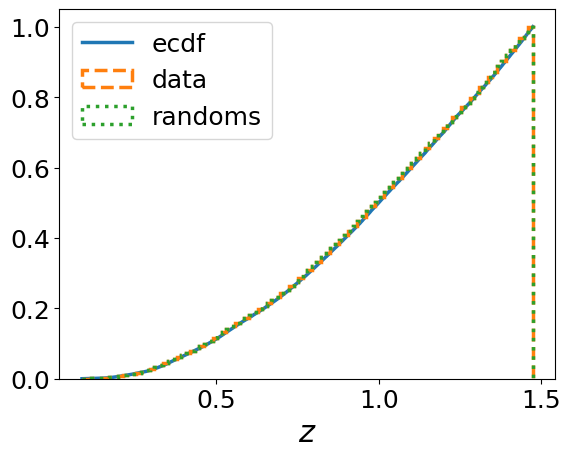

0.0
0.0
0 < z <= 1
data 6536
rand 6299
selfunc 6299
(array([], dtype=int64),)
0.0 0.7797780485705589


Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).


../data/maps/selection_function_NSIDE64_G20.5_zsplit2bin1_website.fits
../data/randoms/random_G20.5_zsplit2bin1_25x.fits
G20.5_zsplit2bin1: 0.00              647758 vs 647758
24.9891533566548


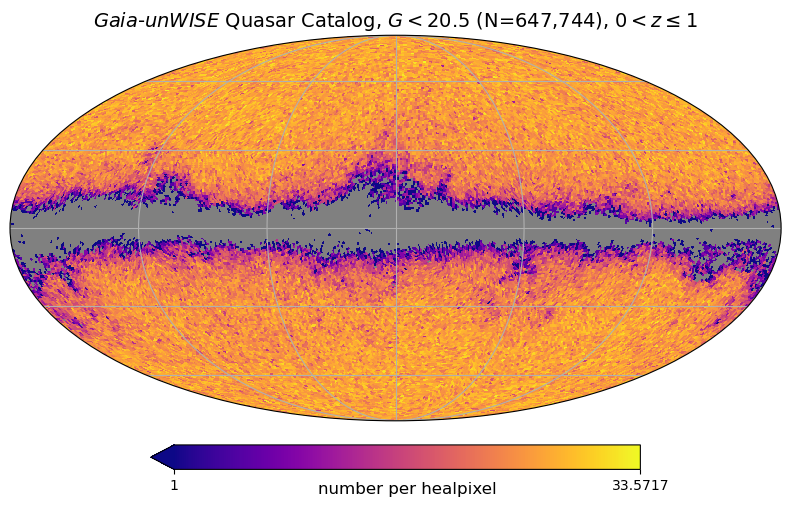

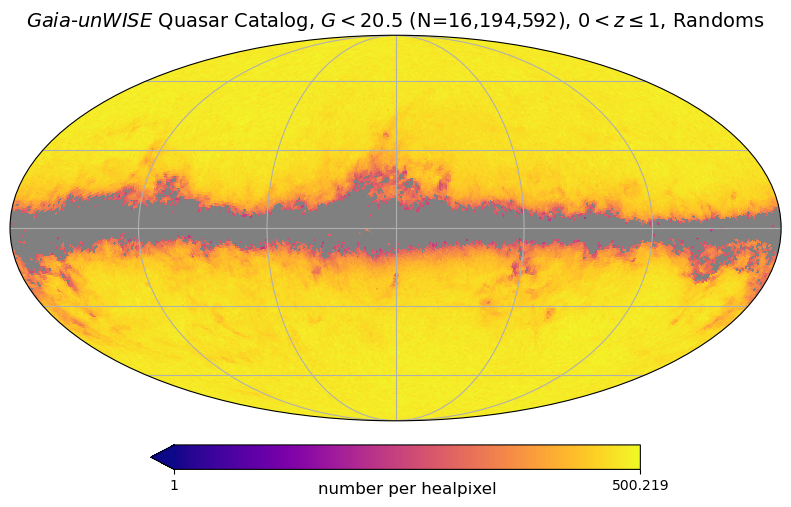

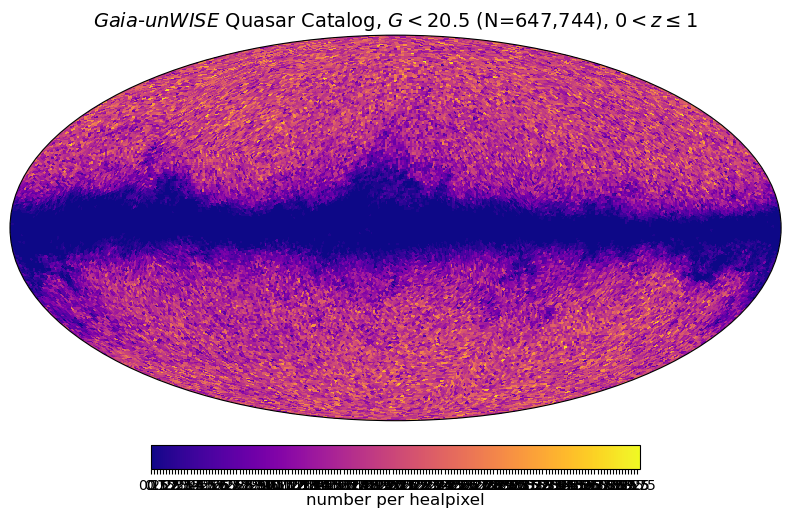

Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exc

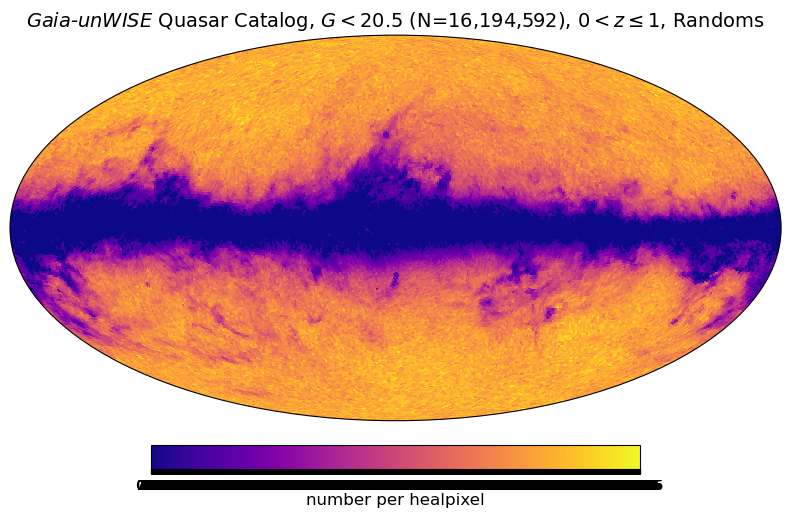

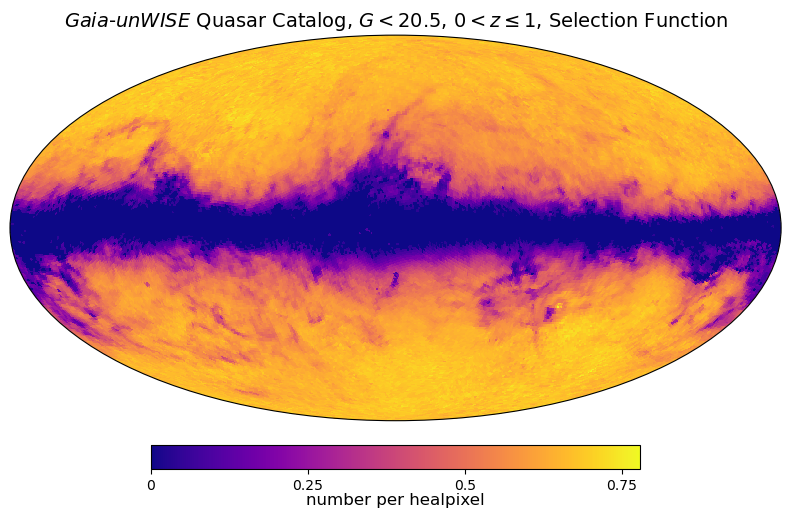

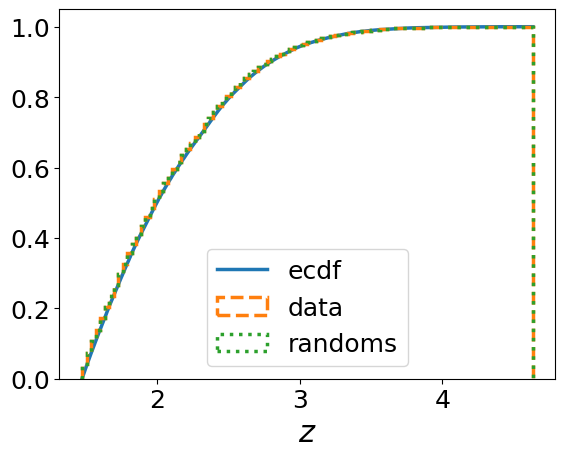

0.0
0.0
1 < z <= 2
data 7851
rand 6299
selfunc 6299
(array([], dtype=int64),)
0.0 0.9387534364495821


Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).


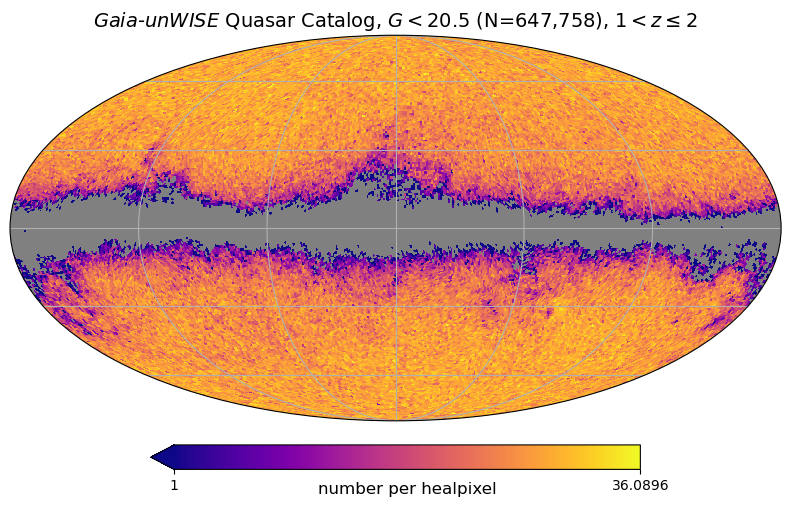

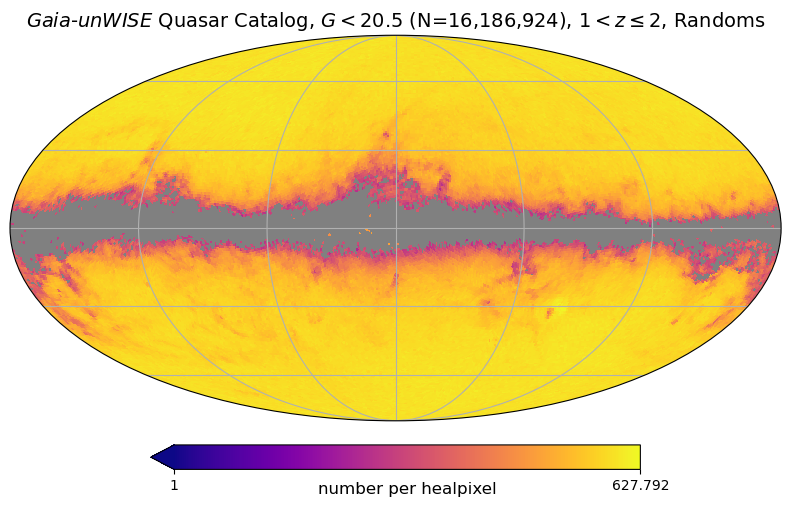

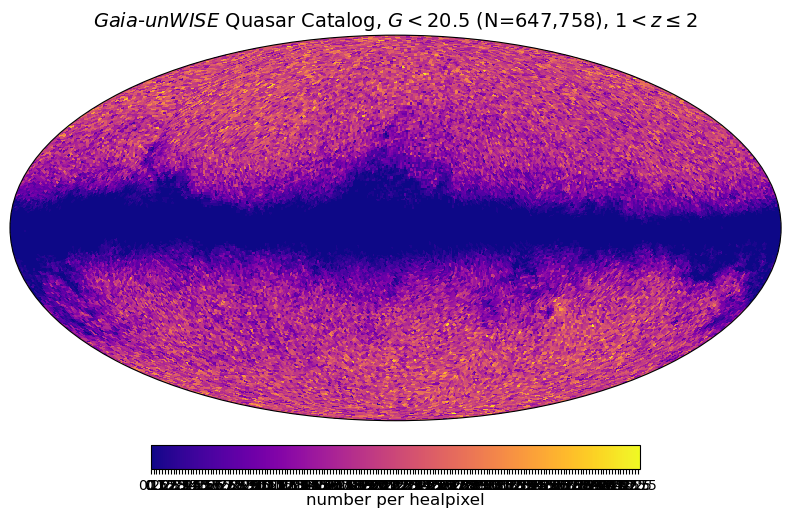

Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exc

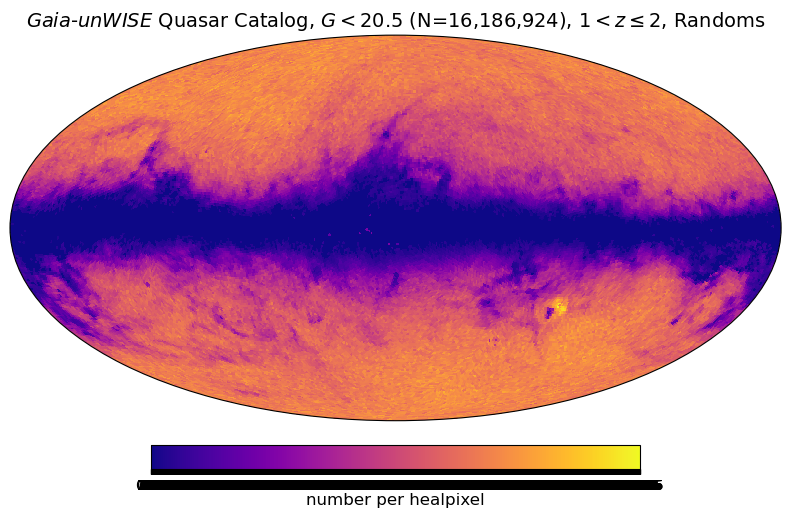

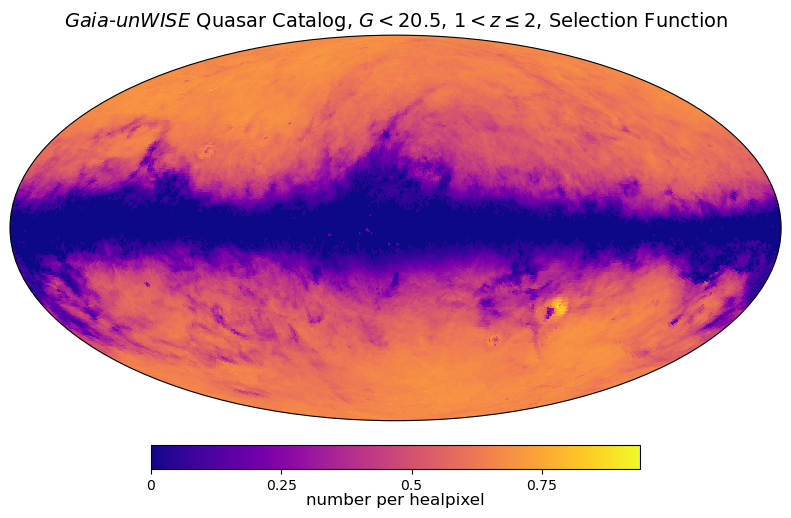

In [39]:
cmap_map = 'plasma'
name_catalog='$Gaia$-$unWISE$ Quasar Catalog'

for j in [0,1]:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin02, map_gcatlo2, map_randlo2, pixel_indices_gcatlo2, pixel_indices_randlo2 = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins], selfunc = '_website',
                                                                                                   tab_gcat_type = 'data', method = ['split'], 
                                                                                                   fac_rand = 25, n_bins = [2], mask_type = 'b',
                                                                                                   b = [0,0,0,30][j], plot = True)
    
    print('{} < z <= {}'.format(j, j+1))
    print('data', len(np.where(map_gcatlo2==0)[0]))
    print('rand', len(np.where(map_randlo2==0)[0]))
    print('selfunc', len(np.where(selfunc_hi_bin02==0)[0]))
    print(np.where(np.isnan(selfunc_hi_bin02)))
    print(np.min(selfunc_hi_bin02), np.max(selfunc_hi_bin02))
    
    # show where the selfunc is zero
    N_datahi_mask_bin0 = len(tab_datahi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_datahi_mask_bin0:,}), ${j}< z\leq{j+1}$'
    projview(map_gcatlo2, title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min=0, max=np.max(map_gcatlo2),
            cbar_ticks=np.arange(0, max(map_gcatlo2), 0.25))

    # make map of quasar number counts
    N_randhi_mask_bin0 = len(tab_randhi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_randhi_mask_bin0:,}), ${j}< z\leq{j+1}$, Randoms'
    projview(map_randlo2, title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min=0, max=np.max(map_randlo2),
            cbar_ticks=np.arange(0, max(map_randlo2), 0.25))
    
    # make map of quasar number counts
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$, ${j}< z\leq{j+1}$, Selection Function'
    projview(selfunc_hi_bin02, title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min=0, max=np.max(selfunc_hi_bin02),
            cbar_ticks=np.arange(0, max(selfunc_hi_bin02), 0.25))

In [36]:
importlib.reload(quaia_debug)

<module 'quaia_debug' from '/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia_debug.py'>

../data/maps/selection_function_NSIDE64_G20.5_zsplit2bin0_old.fits
../data/randoms/random_G20.5_zsplit2bin0_25x.fits
G20.5_zsplit2bin0: 0.00              647744 vs 647744
25.00153146922241


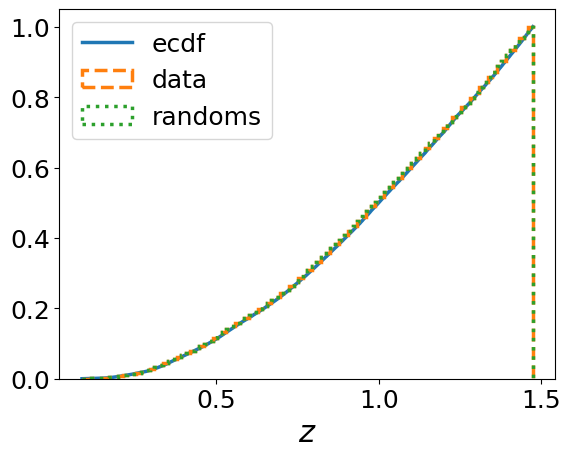

0.0
0.0
0 < z <= 1
data 6536
rand 6299
selfunc 6299
(array([], dtype=int64),)
0.0 0.802751781955829


Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).


../data/maps/selection_function_NSIDE64_G20.5_zsplit2bin1_old.fits
../data/randoms/random_G20.5_zsplit2bin1_25x.fits
G20.5_zsplit2bin1: 0.00              647758 vs 647758
24.9891533566548


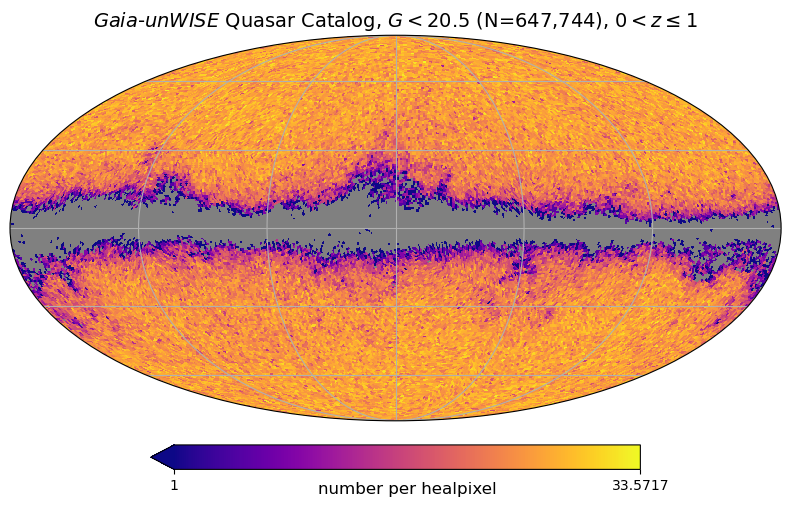

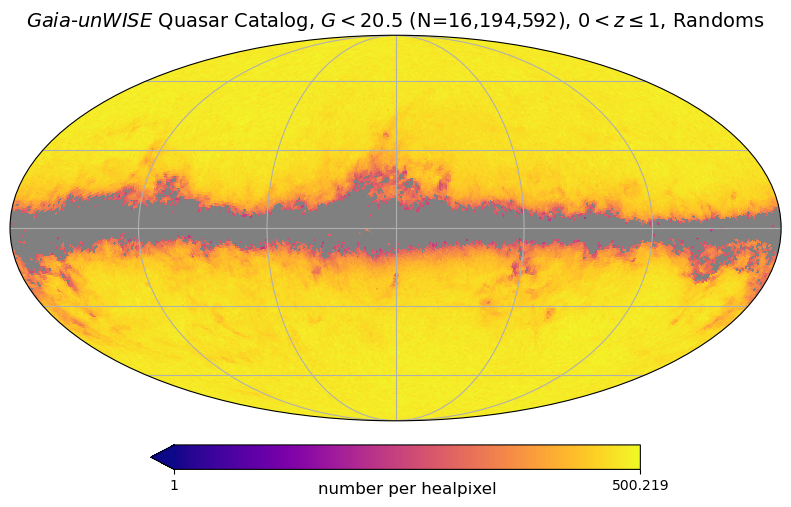

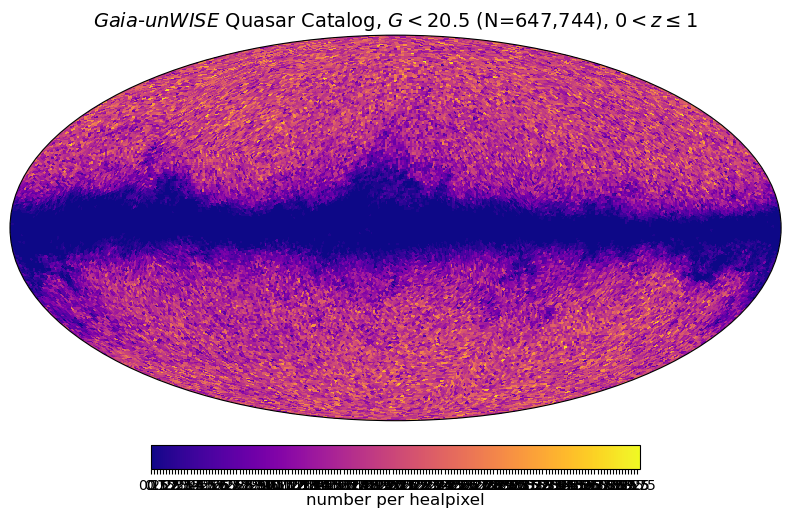

Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2384 ticks ([0.0, ..., 595.75]), which exc

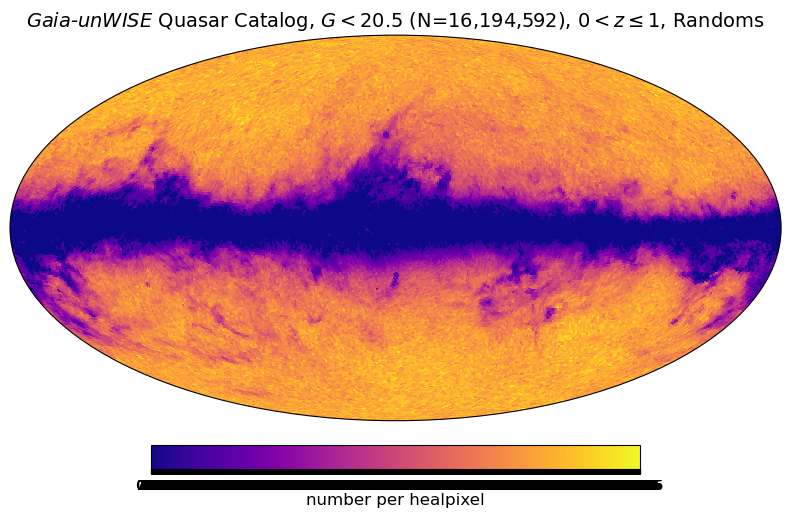

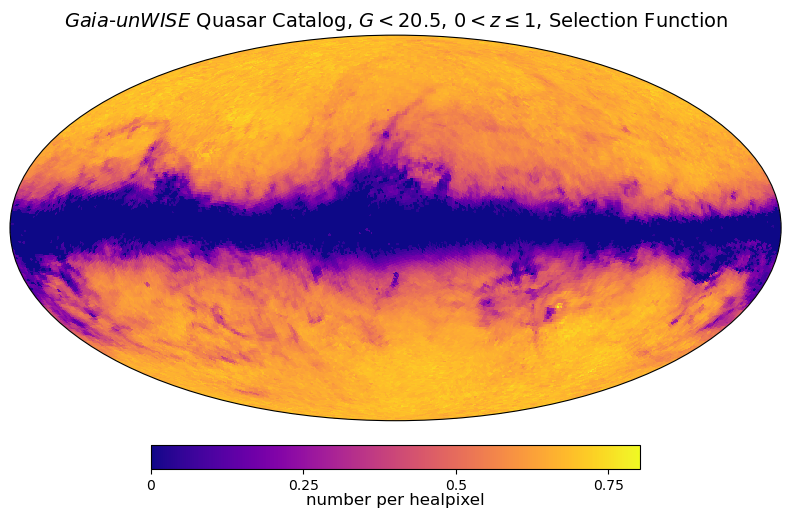

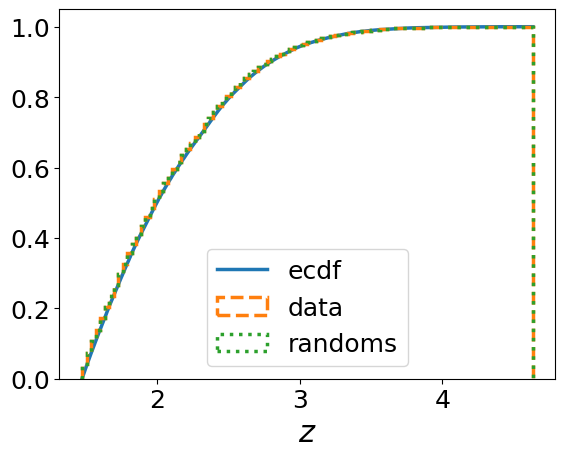

0.0
0.0
1 < z <= 2
data 7851
rand 6299
selfunc 6299
(array([], dtype=int64),)
0.0 0.9153266637256053


Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).


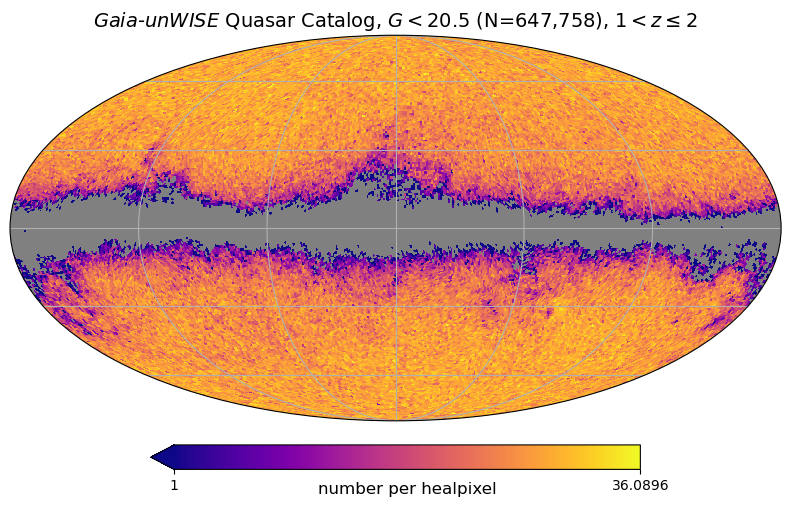

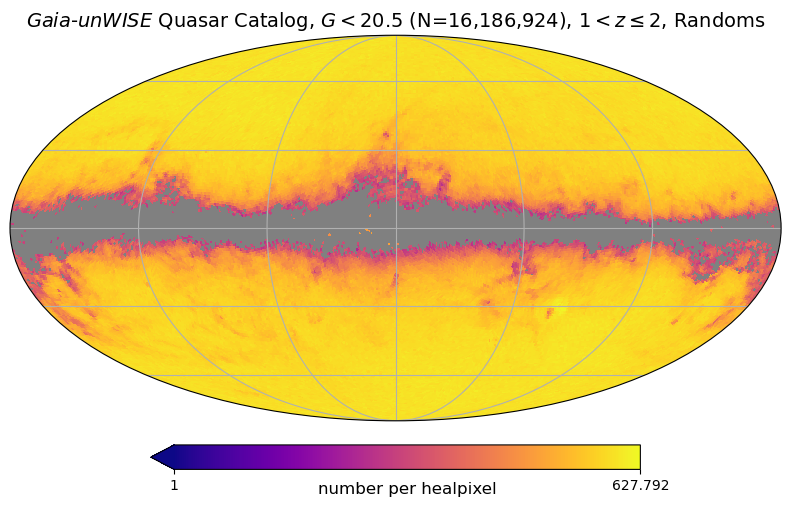

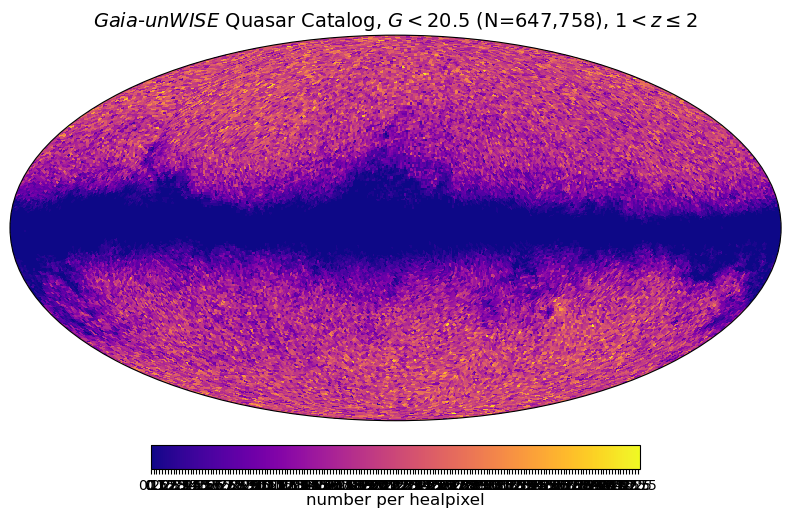

Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 2992 ticks ([0.0, ..., 747.75]), which exc

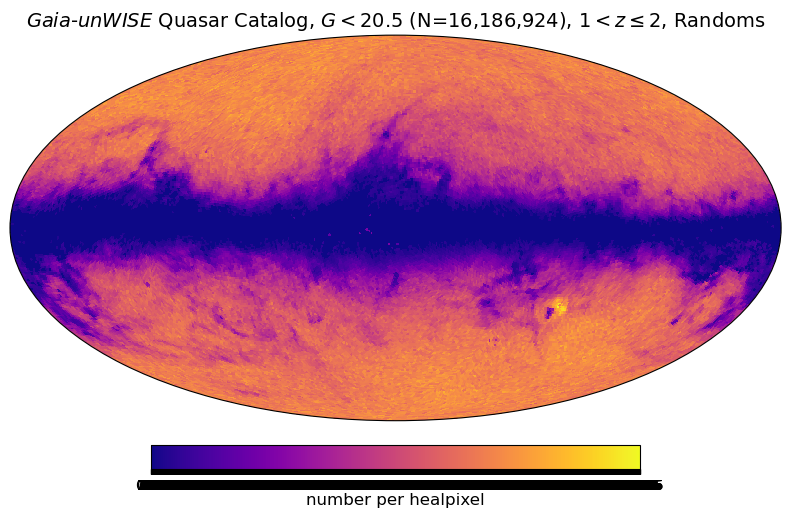

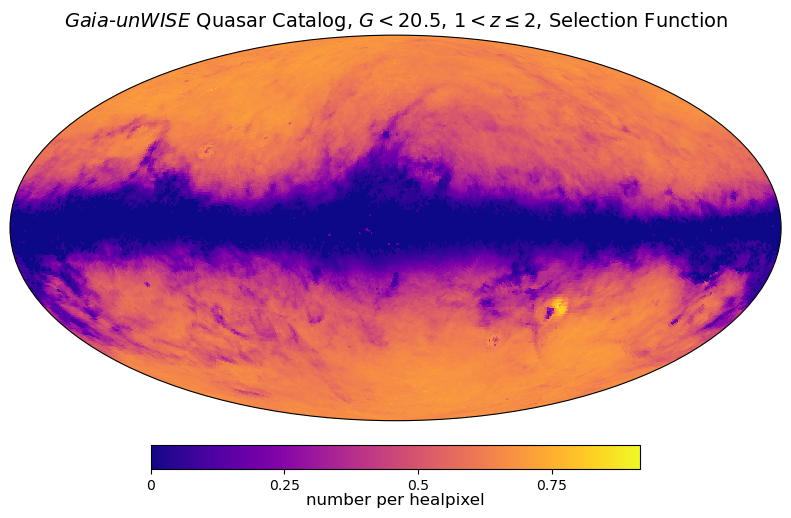

In [37]:
cmap_map = 'plasma'
name_catalog='$Gaia$-$unWISE$ Quasar Catalog'

for j in [0,1]:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin02, map_gcatlo2, map_randlo2, pixel_indices_gcatlo2, pixel_indices_randlo2 = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                                   tab_gcat_type = 'data', method = ['split'], 
                                                                                                   fac_rand = 25, n_bins = [2], mask_type = 'b',
                                                                                                   b = [0,0,0,30][j], plot = True, selfunc = '_old')
    
    print('{} < z <= {}'.format(j, j+1))
    print('data', len(np.where(map_gcatlo2==0)[0]))
    print('rand', len(np.where(map_randlo2==0)[0]))
    print('selfunc', len(np.where(selfunc_hi_bin02==0)[0]))
    print(np.where(np.isnan(selfunc_hi_bin02)))
    print(np.min(selfunc_hi_bin02), np.max(selfunc_hi_bin02))
    
    # show where the selfunc is zero
    N_datahi_mask_bin0 = len(tab_datahi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_datahi_mask_bin0:,}), ${j}< z\leq{j+1}$'
    projview(map_gcatlo2, title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min=0, max=np.max(map_gcatlo2),
            cbar_ticks=np.arange(0, max(map_gcatlo2), 0.25))

    # make map of quasar number counts
    N_randhi_mask_bin0 = len(tab_randhi_mask_zbin0)
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$ (N={N_randhi_mask_bin0:,}), ${j}< z\leq{j+1}$, Randoms'
    projview(map_randlo2, title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min=0, max=np.max(map_randlo2),
            cbar_ticks=np.arange(0, max(map_randlo2), 0.25))
    
    # make map of quasar number counts
    title_gcatlo = rf'{name_catalog}, $G<{G_hi}$, ${j}< z\leq{j+1}$, Selection Function'
    projview(selfunc_hi_bin02, title=title_gcatlo,
                unit=r"number per healpixel", cmap=cmap_map, coord=['C', 'G'], min=0, max=np.max(selfunc_hi_bin02),
            cbar_ticks=np.arange(0, max(selfunc_hi_bin02), 0.25))

## Compare the impact of different selection functions on clustering

../data/maps/selection_function_NSIDE64_G20.5_zsplit2bin0.fits
../data/randoms/random_G20.5_zsplit2bin0_25x.fits
G20.5_zsplit2bin0: 0.00              647744 vs 647744
25.00153146922241


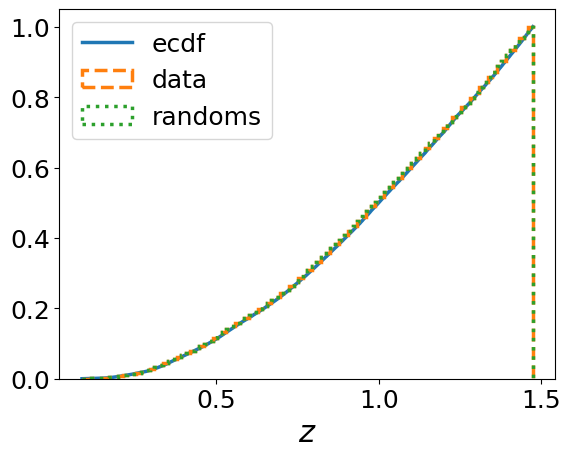

0.0
0.0


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


0 < z <= 1
data 6536
rand 6299
selfunc 6299
../data/maps/selection_function_NSIDE64_G20.5_zsplit2bin0_website.fits
../data/randoms/random_G20.5_zsplit2bin0_website_25x.fits
G20.5_zsplit2bin0: 0.00              647744 vs 647744
24.998385164509436


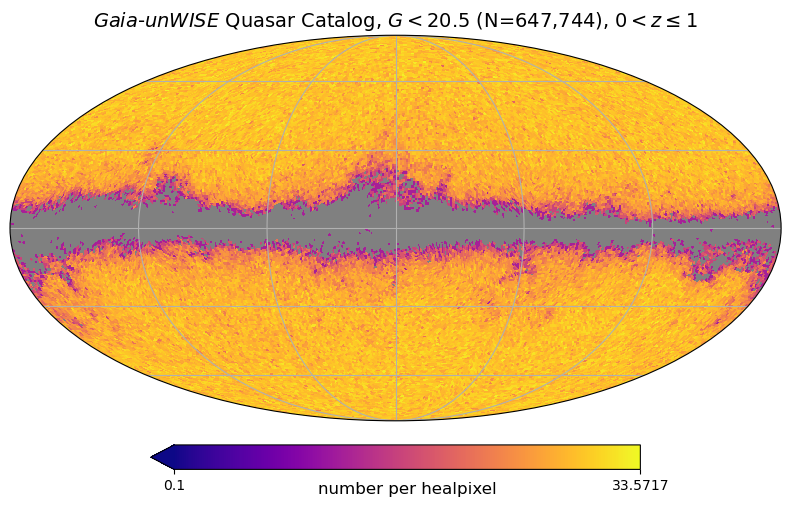

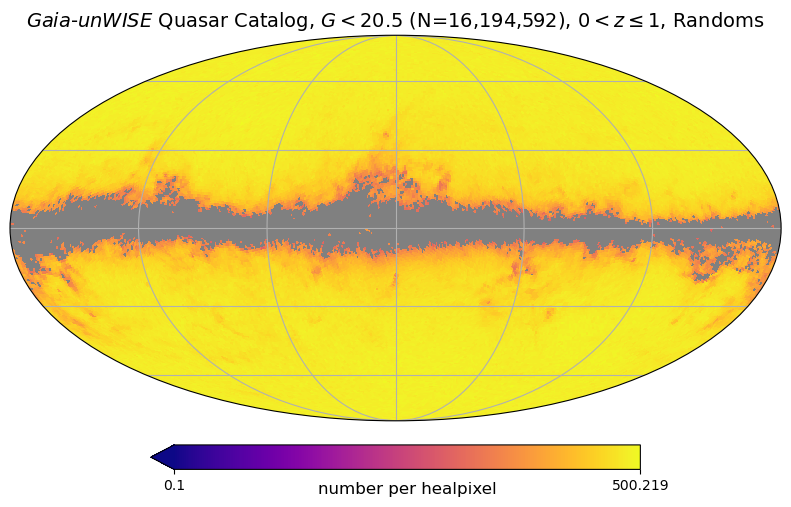

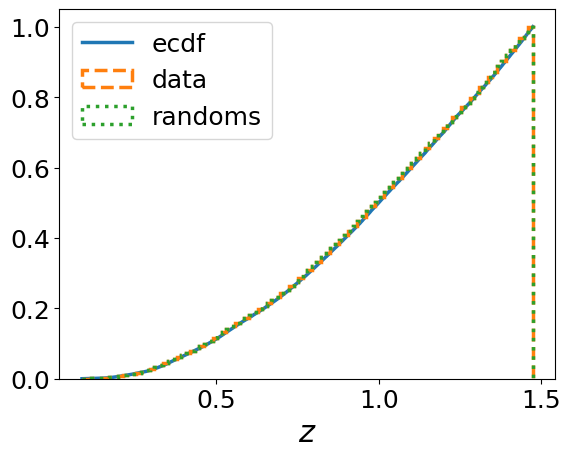

0.0
0.0


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


1 < z <= 2
data 6536
rand 6299
selfunc 6299
../data/maps/selection_function_NSIDE64_G20.5_zsplit2bin0_zenodo.fits
../data/randoms/random_G20.5_zsplit2bin0_zenodo_25x.fits
G20.5_zsplit2bin0: 0.00              647744 vs 647744
24.991850175377927


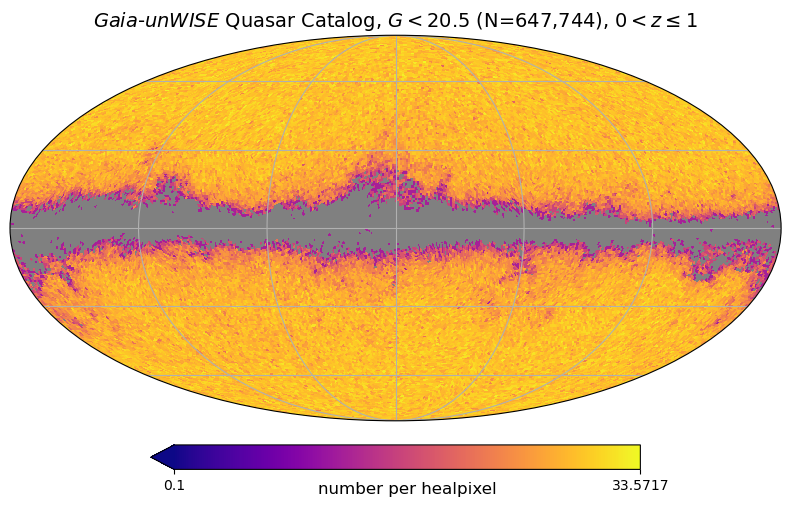

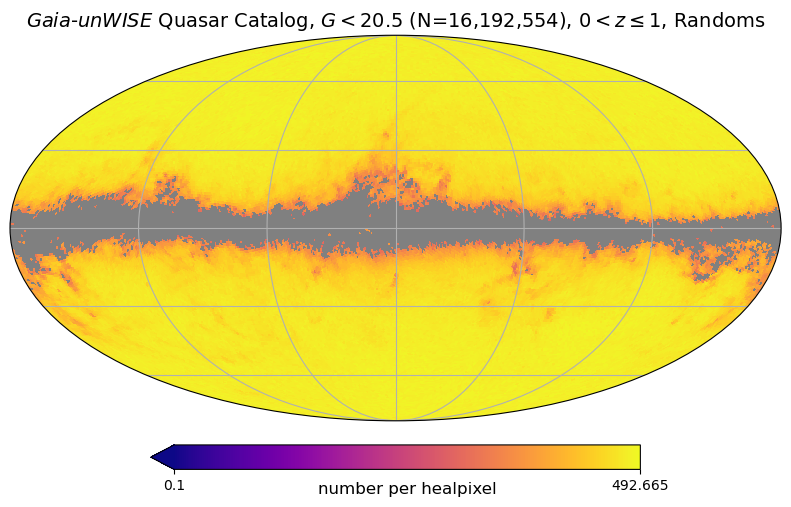

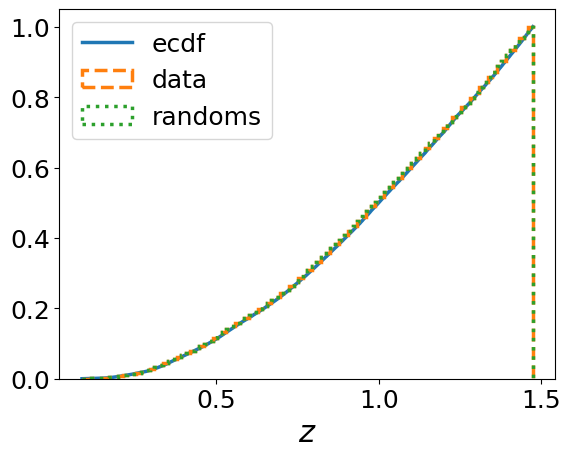

0.0
0.0


/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia_debug.py:566: RuntimeWarning: divide by zero encountered in divide
  return tab_datahi_mask_bin0, tab_randhi_mask_bin0, key_bin0, bins, 1/selfunc_hi_bin0[pixel_indices_datahi_bin0][mask_datahi_bin0], 1-N_datahi_mask_bin0/len(tab_datahi_bin0), selfunc_hi_bin0, map_gcatlo, map_randlo, pixel_indices_gcatlo, pixel_indices_randlo
/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


2 < z <= 3
data 6536
rand 6532
selfunc 6532


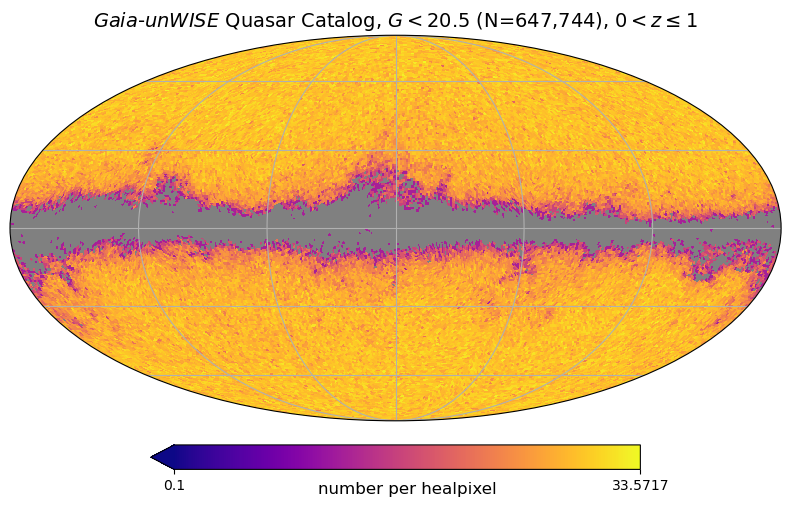

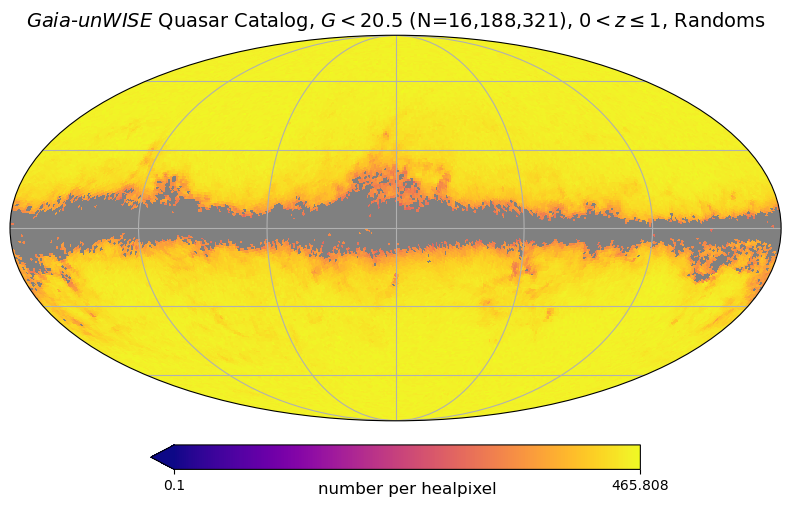

In [43]:
cmap_map = 'plasma'
name_catalog='$Gaia$-$unWISE$ Quasar Catalog'
wp_debug = []
rpavg_debug = []
selfunc = ['', '_website', '_zenodo']

for j in range(len(selfunc)):

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin02, map_gcatlo2, map_randlo2, pixel_indices_gcatlo2, pixel_indices_randlo2 = quaia_debug.make_bins(G_hi, [0], True, ['z'], bins = [z_bins], 
                                                                                                                                                                                       selfunc = selfunc[j], tab_gcat_type = 'data', 
                                                                                                                                                                                       method = ['split'], fac_rand = 25, n_bins = [2], 
                                                                                                                                                                                       mask_type = 'b', b = [0], plot = True, 
                                                                                                                                                                                       bounds = [0.1, 20], allsky = selfunc[j])
    wp_debug_i, rpavg_debug_i, qq, qr = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0,
                                                      nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
    wp_debug.append(wp_debug_i)
    rpavg_debug.append(rpavg_debug_i)
    
    print('{} < z <= {}'.format(j, j+1))
    print('data', len(np.where(map_gcatlo2==0)[0]))
    print('rand', len(np.where(map_randlo2==0)[0]))
    print('selfunc', len(np.where(selfunc_hi_bin02==0)[0]))

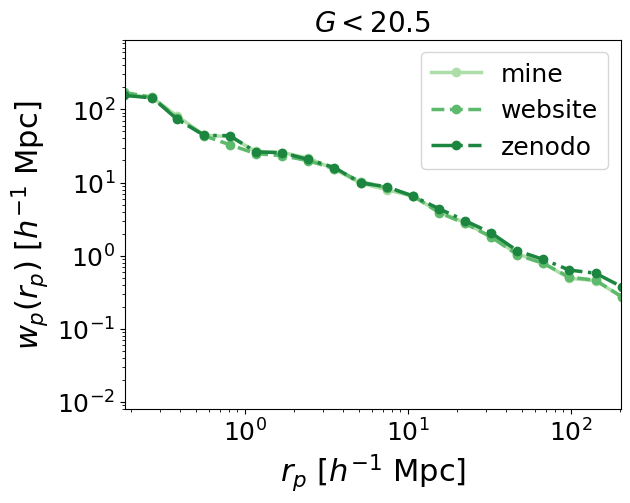

In [44]:
# fig = plt.figure(figsize = (10, 8))
labels = ['mine', 'website', 'zenodo']
linestyles = ['-', '--', '-.']
for j in range(len(selfunc)):

    handles = plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = labels[j], linestyle = linestyles[j], 
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)
plt.legend()

# custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
#                     Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5), 
#                 Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
# second_legend = plt.legend(custom_lines, selfunc, loc = 'upper right')
# fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

# custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
# second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
# fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')
    
plt.show()

# Things to check
- comoving_dist: conversion from z --> comoving distance in Mpc/h $\color{green}{\checkmark}$
- little h factor $\color{green}{\checkmark}$
- custom cosmology in wp_rp from Corrfunc $\color{green}{\checkmark}$
- mask in make_bins $\color{green}{\checkmark}$
- binning in make_bins $\color{green}{\checkmark}$
- random catalog generation $\color{green}{\checkmark}$
- z distribution of random catalog $\color{green}{\checkmark}$